In [1]:
# Phase 0.1 — Dependencies
!pip install -q timm scikit-learn pandas matplotlib seaborn tqdm
!pip install -q onnx onnxruntime onnxscript
!pip install -q streamlit
print("Done. Restart runtime if on Colab, then skip this cell.")

Done. Restart runtime if on Colab, then skip this cell.


In [2]:
# Phase 0.2 — Imports

import os, sys, json, math, time, random, hashlib, shutil, warnings, functools
from pathlib import Path
from collections import Counter, defaultdict
from dataclasses import dataclass, asdict
from concurrent.futures import ProcessPoolExecutor

import numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from scipy.fftpack import dct
from tqdm.auto import tqdm
import timm
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
    roc_auc_score, matthews_corrcoef, cohen_kappa_score, classification_report, roc_curve, auc,
    average_precision_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
matplotlib.rcParams.update({"figure.dpi":110, "savefig.dpi":300, "savefig.bbox":"tight"})
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | timm {timm.__version__}")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")
else:
    print("WARNING: no GPU. Training will be very slow.")

Python 3.13.9 | torch 2.11.0+cu130 | timm 1.0.9
Device: cuda
GPU: NVIDIA RTX A4000 (16.7 GB)


In [3]:
# Phase 0.3 — Configuration

@dataclass
class Config:
    SEEDS: tuple = (42, 1337, 2024)
    PRIMARY_SEED: int = 42
    # v12.8 data source: figshare release of the CT-KIDNEY benchmark (CC BY 4.0)
    FIGSHARE_DOI: str = "10.6084/m9.figshare.30342133.v1"
    FIGSHARE_URL: str = "https://ndownloader.figshare.com/files/58681468"
    FIGSHARE_FILE: str = "dataset2.zip"
    FIGSHARE_BYTES: int = 1627919308
    FIGSHARE_MD5: str = "149a1d47093a4379ef71c5805d956be6"     # figshare's published md5
    DATA_DIR: str = "~/datasets/ct_kidney_figshare"            # or set $KIDNEY_DATA_DIR
    DATA_CLASS_ROOT: str = ""          # set only if Phase 1.1 picks the wrong folder
    CLASS_FOLDER_ALIASES: tuple = ()   # e.g. (("kidney_cyst","Cyst"),) if folder names differ
    EXPECTED_N: int = 12446
    CLASSES: tuple = ("Cyst","Normal","Stone","Tumor")
    IMG_SIZE: int = 224
    SPLIT_RATIO: tuple = (0.70, 0.15, 0.15)
    # v12.7: "balanced_random" (default) or "greedy_largest_first" (v12.0-v12.6, reproduces old
    # numbers but puts almost every large scan in train - see Phase 3.1)
    SPLIT_METHOD: str = "balanced_random"

    # DAP
    DHASH_THRESH: int = 5
    PHASH_THRESH: int = 8
    MAX_GROUP_FRAC: float = 0.05
    AUTO_TIGHTEN: bool = True
    HASH_WORKERS: int = 8              # FIX 7: parallel hashing

    # models
    LOCAL_BACKBONE: str  = "convnext_tiny.fb_in1k"
    GLOBAL_BACKBONE: str = "swin_tiny_patch4_window7_224.ms_in1k"
    FUSION_DIM: int = 512
    FUSION_HEADS: int = 8
    FUSION_DROPOUT: float = 0.1
    HEAD_DROPOUT: float = 0.3

    # training
    EPOCHS: int = 50
    BATCH_SIZE: int = 32
    LR_BACKBONE: float = 3e-5
    LR_HEAD: float = 3e-4
    WEIGHT_DECAY: float = 0.05
    WARMUP_EPOCHS: int = 3
    LABEL_SMOOTHING: float = 0.05
    EARLY_STOP_PATIENCE: int = 10
    NUM_WORKERS: int = 0               # FIX 5: 0 avoids Jupyter worker-shutdown spam
    USE_AMP: bool = True

    # imbalance
    IMBALANCE_STRATEGY: str = "class_weights"
    CLASS_WEIGHT_POWER: float = 1.0    # NEW: <1 softens weighting (Stone precision fix)

    # calibration / selective prediction
    CONFORMAL_ALPHA: float = 0.10
    TARGET_COVERAGE: float = 0.90
    TEMP_MIN: float = 0.05
    TEMP_MAX: float = 10.0
    ECE_BINS: int = 15

    # evaluation
    BOOTSTRAP_N: int = 1000            # FIX 2: one value used everywhere

    # NEW v11: threshold sensitivity. Does the inflation survive a different linkage?
    THRESHOLD_GRID: tuple = ((2,4),(3,5),(4,7),(5,8))
    SWEEP_ARCH: str = "RenalDualNet"

    BASELINES: tuple = ("resnet50.a1_in1k","efficientnet_b0.ra_in1k","densenet201.tv_in1k",
                        "vit_small_patch16_224.augreg_in1k",
                        "swin_tiny_patch4_window7_224.ms_in1k","convnext_tiny.fb_in1k")

    # deployment  (FIX 8: ResNet18 quantizes ~10x cleaner than MobileNetV3)
    STUDENT_BACKBONE: str = "resnet18.a1_in1k"
    DISTILL_TEMP: float = 4.0
    DISTILL_ALPHA: float = 0.7
    ONNX_OPSET: int = 17
    MAX_INT8_ACC_DROP: float = 0.02

    # switches
    QUICK_RUN: bool = False
    RUN_BASELINES: bool = True
    RUN_ABLATION: bool = True
    RUN_LEAKAGE_EXPERIMENT: bool = True
    LEAKAGE_ARCHS: tuple = ("RenalDualNet","swin_tiny_patch4_window7_224.ms_in1k")  # NEW
    RUN_MULTISEED: bool = True
    RUN_WEIGHT_SWEEP: bool = True
    RUN_DEPLOYMENT: bool = True
    RUN_THRESHOLD_SWEEP: bool = True    # NEW v11 - the experiment that defends the headline
    RUN_MULTISEED_LEAKAGE: bool = True  # NEW v11 - error bars on the inflation
    # v12.7: paired contamination design (Phase 13.3b). Share of each TEST scan's images that is moved
    # into the training set of the contaminated arm; the rest are the evaluation images. A random
    # 70/15/15 split leaves ~82% of a scan's other images in train (70/85), so 0.5 is the milder case.
    LEAK_FRAC: float = 0.5

    OUT_DIR: str = "./Obj1"      # -> Music/obj_1_2808/Rank1/Obj1 when run from Rank1

CFG = Config()

if CFG.QUICK_RUN:
    CFG.EPOCHS=3; CFG.SEEDS=(42,); CFG.BOOTSTRAP_N=200
    CFG.BASELINES=("resnet50.a1_in1k","swin_tiny_patch4_window7_224.ms_in1k")
    CFG.LEAKAGE_ARCHS=("RenalDualNet",)
    CFG.RUN_WEIGHT_SWEEP=False
    CFG.THRESHOLD_GRID=((3,5),(4,7))
    CFG.RUN_MULTISEED_LEAKAGE=False
    print(">>> QUICK_RUN ON — results are NOT publishable. Set False for the real run.\n")

OUT = Path(CFG.OUT_DIR)
for s in ["figures","tables","checkpoints","logs","deploy"]:
    (OUT/s).mkdir(parents=True, exist_ok=True)

NUM_CLASSES = len(CFG.CLASSES)
CLASS_TO_IDX = {c:i for i,c in enumerate(CFG.CLASSES)}
IDX_TO_CLASS = {i:c for c,i in CLASS_TO_IDX.items()}
print(f"Outputs -> {OUT.resolve()}")
if OUT.resolve().name != "Obj1":
    print("NOTE: expected the output folder to be named 'Obj1'. Edit CFG.OUT_DIR.")
print(f"Classes: {CFG.CLASSES}")

Outputs -> /home/score/figshare_obj_1/Obj1
Classes: ('Cyst', 'Normal', 'Stone', 'Tumor')


In [4]:
# Phase 0.4 — Seeding
# FIX 6: we control seeds but do NOT claim bit-exact reproducibility. AMP and some CUDA
# scatter kernels are non-deterministic. Overclaiming this is an easy thing for a reviewer
# to disprove, so we state the limitation instead.

def set_seed(seed:int, deterministic:bool=True):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed); os.environ["PYTHONHASHSEED"]=str(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic

set_seed(CFG.PRIMARY_SEED)
DETERMINISM_NOTE = ("Runs are seed-controlled (Python, NumPy, PyTorch, cuDNN deterministic mode). "
                    "Bit-exact reproducibility is NOT claimed: mixed-precision training and some "
                    "CUDA kernels are non-deterministic. Report metrics as mean +/- std over seeds.")
print(f"Seeded {CFG.PRIMARY_SEED}\n\n{DETERMINISM_NOTE}")

Seeded 42

Runs are seed-controlled (Python, NumPy, PyTorch, cuDNN deterministic mode). Bit-exact reproducibility is NOT claimed: mixed-precision training and some CUDA kernels are non-deterministic. Report metrics as mean +/- std over seeds.


---
## Phase 1 — Data and inventory

In [5]:
# Phase 1.1 — Get the dataset (figshare) and locate class folders
#
# v12.8: the data now comes from the figshare release
#   DOI 10.6084/m9.figshare.30342133.v1  "Multi-class Classification – Normal, Cyst, Tumor, and Stone"
#   (P. Xia, CC BY 4.0) - one file, dataset2.zip, 1,627,919,308 bytes, md5 149a1d47093a4379ef71c5805d956be6
# instead of the Kaggle slug. Cite the DOI in the paper's Data Availability statement.
#
# Order of preference, so the notebook also runs on a machine without internet:
#   1. CFG.DATA_CLASS_ROOT is set            -> use that folder as it is
#   2. DATA_DIR/extracted/ already exists    -> reuse it
#   3. DATA_DIR/dataset2.zip exists          -> check size + md5, extract
#   4. otherwise                             -> download (resumable), check size + md5, extract
# DATA_DIR is $KIDNEY_DATA_DIR if set, else CFG.DATA_DIR.
#
# The zip's internal layout is not assumed. Class folders are found by name (case-insensitive,
# plus CFG.CLASS_FOLDER_ALIASES). If several folders hold all four classes (e.g. train/ and
# test/ sub-folders, or Original/ and Augmented/), the cell picks the one with exactly
# CFG.EXPECTED_N images, or the union if that is what adds up to EXPECTED_N; otherwise it stops
# and asks you to set CFG.DATA_CLASS_ROOT. It never silently pulls in an augmented copy.

import zipfile, urllib.request

DATA_DIR    = Path(os.environ.get("KIDNEY_DATA_DIR", CFG.DATA_DIR)).expanduser()
ZIP_PATH    = DATA_DIR/CFG.FIGSHARE_FILE
EXTRACT_DIR = DATA_DIR/"extracted"
IMG_EXT     = {".jpg",".jpeg",".png",".bmp",".tif",".tiff"}

def _is_img(p):
    """An image file, excluding macOS resource forks (._x.jpg) and __MACOSX folders."""
    return (p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith(".")
            and "__MACOSX" not in p.parts)

def md5_file(path, chunk=1<<20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

def download_resumable(url, dest, expected_size):
    """Stream to <dest>.part; an interrupted download resumes from where it stopped (HTTP Range)."""
    part = dest.with_name(dest.name + ".part")
    have = part.stat().st_size if part.exists() else 0
    hdr = {"User-Agent": "Mozilla/5.0"}
    if have: hdr["Range"] = f"bytes={have}-"
    with urllib.request.urlopen(urllib.request.Request(url, headers=hdr), timeout=120) as r:
        if have and r.status != 206: have = 0                  # server ignored Range: start over
        with open(part, "ab" if have else "wb") as f, \
             tqdm(total=expected_size, initial=have, unit="B", unit_scale=True, desc=dest.name) as bar:
            for b in iter(lambda: r.read(1<<20), b""):
                f.write(b); bar.update(len(b))
    part.replace(dest)

def verify_zip(path):
    size = path.stat().st_size
    if size != CFG.FIGSHARE_BYTES:
        raise RuntimeError(f"{path.name}: {size:,} bytes, expected {CFG.FIGSHARE_BYTES:,}. "
                           "Incomplete or a different file - delete it and download again.")
    print(f"Checking md5 of {path.name} ...")
    got = md5_file(path)
    if got != CFG.FIGSHARE_MD5:
        bad = path.with_name(path.name + ".bad"); path.replace(bad)
        raise RuntimeError(f"md5 {got} != figshare md5 {CFG.FIGSHARE_MD5}. Moved to {bad.name}.")
    print(f"  md5 OK ({got})")
    return got

def safe_extract(zp, dest):
    """Extract to <dest>.tmp and rename when complete, so a half-finished extraction is never reused.
    Rejects absolute or '..' member paths (zip-slip) and skips macOS metadata."""
    tmp = dest.with_name(dest.name + ".tmp")
    if tmp.exists(): shutil.rmtree(tmp)
    tmp.mkdir(parents=True)
    root = tmp.resolve()
    with zipfile.ZipFile(zp) as z:
        members = [m for m in z.infolist()
                   if not m.filename.startswith("__MACOSX/") and "/._" not in "/" + m.filename]
        for m in members:
            t = (tmp/m.filename).resolve()
            if t != root and root not in t.parents:
                raise RuntimeError(f"Unsafe path in zip: {m.filename!r}")
        for m in tqdm(members, desc="Extracting"): z.extract(m, tmp)
    tmp.replace(dest)

def _tree(root, depth=3, limit=40):
    """Print the folder layout (dirs only, with image counts) - shown when auto-detection fails."""
    shown = 0
    for d in sorted([root] + [q for q in root.rglob("*") if q.is_dir()]):
        rel = d.relative_to(root)
        if len(rel.parts) > depth or "__MACOSX" in d.parts: continue
        n = sum(1 for f in d.iterdir() if _is_img(f))
        print(f"    {'  '*len(rel.parts)}{rel.name or root.name}/  ({n} images)")
        shown += 1
        if shown >= limit: print("    ..."); break

def find_class_dirs(root, classes, quiet=False):
    """Map each class to the folder(s) holding its images. Returns ({class: [dirs]}, [chosen roots])."""
    want = {c.lower(): c for c in classes}
    want.update({a.lower(): c for a, c in CFG.CLASS_FOLDER_ALIASES})
    by_parent = defaultdict(dict)
    for d in (q for q in root.rglob("*") if q.is_dir() and "__MACOSX" not in q.parts):
        c = want.get(d.name.strip().lower())
        if c: by_parent[d.parent][c] = d
    roots = {p: m for p, m in by_parent.items() if set(m) == set(classes)}
    if not roots:
        print(f"No folder under {root} contains all of {classes}. Layout:"); _tree(root)
        raise FileNotFoundError("Class folders not found. Set CFG.CLASS_FOLDER_ALIASES if the folders "
                                "use other names, or CFG.DATA_CLASS_ROOT to point at the right folder.")
    n_img = {p: sum(1 for d in m.values() for f in d.rglob("*") if _is_img(f)) for p, m in roots.items()}
    if not quiet:
        for p, n in n_img.items(): print(f"  candidate class root: {p}  ({n:,} images)")
    exact = [p for p, n in n_img.items() if n == CFG.EXPECTED_N]
    if len(roots) == 1:                         chosen = list(roots)
    elif len(exact) == 1:                       chosen = exact
    elif sum(n_img.values()) == CFG.EXPECTED_N: chosen = sorted(roots)   # e.g. train/val/test sub-folders
    else:
        print("Layout:"); _tree(root)
        raise RuntimeError(f"{len(roots)} folders each hold all four classes and none (nor their union) "
                           f"has {CFG.EXPECTED_N:,} images. Pick one with CFG.DATA_CLASS_ROOT. Do not "
                           "include an augmented copy: it adds synthetic near-duplicates.")
    if len(chosen) > 1 and not quiet:
        print(f"  using the UNION of {len(chosen)} class roots ({sum(n_img[p] for p in chosen):,} images)")
    return {c: [roots[p][c] for p in chosen] for c in classes}, chosen

# --- 1-4: locate or fetch ---
if CFG.DATA_CLASS_ROOT:
    DATA_ROOT = Path(CFG.DATA_CLASS_ROOT).expanduser()
    print(f"Using CFG.DATA_CLASS_ROOT = {DATA_ROOT}")
    ZIP_MD5 = None
else:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    ZIP_MD5 = None
    if EXTRACT_DIR.exists():
        print(f"Reusing extracted data: {EXTRACT_DIR}")
    else:
        if not ZIP_PATH.exists():
            print(f"Downloading {CFG.FIGSHARE_FILE} ({CFG.FIGSHARE_BYTES/1e9:.2f} GB) from figshare "
                  f"(doi:{CFG.FIGSHARE_DOI}) -> {ZIP_PATH}")
            try:
                download_resumable(CFG.FIGSHARE_URL, ZIP_PATH, CFG.FIGSHARE_BYTES)
            except Exception as e:
                raise RuntimeError(
                    f"Download failed ({type(e).__name__}: {e}).\n"
                    f"If this machine has no internet, download it elsewhere and copy it here:\n"
                    f"    wget -c -O {CFG.FIGSHARE_FILE} {CFG.FIGSHARE_URL}\n"
                    f"    (or open https://doi.org/{CFG.FIGSHARE_DOI} in a browser)\n"
                    f"then place it at  {ZIP_PATH}  (or set KIDNEY_DATA_DIR) and re-run this cell.\n"
                    f"A partial download is kept as {ZIP_PATH.name}.part and resumes on re-run.") from None
        ZIP_MD5 = verify_zip(ZIP_PATH)
        safe_extract(ZIP_PATH, EXTRACT_DIR)
        print(f"Extracted -> {EXTRACT_DIR}")
    DATA_ROOT = EXTRACT_DIR

CLASS_DIRS, CLASS_ROOTS = find_class_dirs(DATA_ROOT, CFG.CLASSES)
CLASS_ROOT = CLASS_ROOTS[0]                       # kept for older cells; CLASS_DIRS is authoritative
DATA_SOURCE = {"repository": "figshare", "doi": CFG.FIGSHARE_DOI, "url": f"https://doi.org/{CFG.FIGSHARE_DOI}",
               "file": CFG.FIGSHARE_FILE, "file_md5": CFG.FIGSHARE_MD5, "license": "CC BY 4.0",
               "md5_verified_this_run": ZIP_MD5 == CFG.FIGSHARE_MD5,
               "class_roots": [str(p.relative_to(DATA_ROOT)) if p != DATA_ROOT else "." for p in CLASS_ROOTS]}
print(f"\nSource: doi:{CFG.FIGSHARE_DOI}")
for c in CFG.CLASSES:
    print(f"  {c:8s} {sum(1 for d in CLASS_DIRS[c] for f in d.rglob('*') if _is_img(f)):6d}   "
          f"<- {', '.join(str(d.relative_to(DATA_ROOT)) for d in CLASS_DIRS[c])}")

dataset2.zip:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Checking md5 of dataset2.zip ...
  md5 OK (149a1d47093a4379ef71c5805d956be6)


Extracting:   0%|          | 0/12447 [00:00<?, ?it/s]

Extracted -> /home/score/datasets/ct_kidney_figshare/extracted
  candidate class root: /home/score/datasets/ct_kidney_figshare/extracted/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone  (12,446 images)

Source: doi:10.6084/m9.figshare.30342133.v1
  Cyst       3709   <- CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst
  Normal     5077   <- CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Normal
  Stone      1377   <- CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Stone
  Tumor      2283   <- CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Tumor


In [6]:
# Phase 1.2 — Manifest
# v12.8: reads CLASS_DIRS from Phase 1.1 (one or more folders per class), skips macOS metadata
# files, and keeps the v12.7 ordering (sorted by file name within each class) so that img_id,
# the DAP groups and the blinded contrast key come out the same whenever the files are the same.

rows=[]
for cls in CFG.CLASSES:
    files = sorted((p for d in CLASS_DIRS[cls] for p in d.rglob("*") if _is_img(p)),
                   key=lambda p: (p.name, str(p)))
    for p in files:
        rows.append({"path":str(p),"filename":p.name,"class_name":cls,
                     "label":CLASS_TO_IDX[cls],"bytes":p.stat().st_size})
manifest = pd.DataFrame(rows).reset_index(drop=True)
manifest["img_id"] = manifest.index
N = len(manifest)
print(f"Total images: {N:,}")

EXPECTED = CFG.EXPECTED_N
if N != EXPECTED:
    print(f"\n!!! Expected {EXPECTED:,} (canonical release), found {N:,}.")
    print("    A larger count usually means an augmented or Roboflow re-export, which")
    print("    contains synthetic near-duplicates and WILL inflate every metric below.")
else:
    print("Matches the canonical release count.")

counts = manifest.class_name.value_counts().reindex(list(CFG.CLASSES))
imbalance_ratio = counts.max()/counts.min()
print(f"\n{counts.to_string()}\nImbalance ratio: {imbalance_ratio:.2f}:1")
print(f"Majority-class-only baseline accuracy: {counts.max()/counts.sum():.1%}")
print("-> lead every table with macro-F1, not accuracy.")

Total images: 12,446
Matches the canonical release count.

class_name
Cyst      3709
Normal    5077
Stone     1377
Tumor     2283
Imbalance ratio: 3.69:1
Majority-class-only baseline accuracy: 40.8%
-> lead every table with macro-F1, not accuracy.


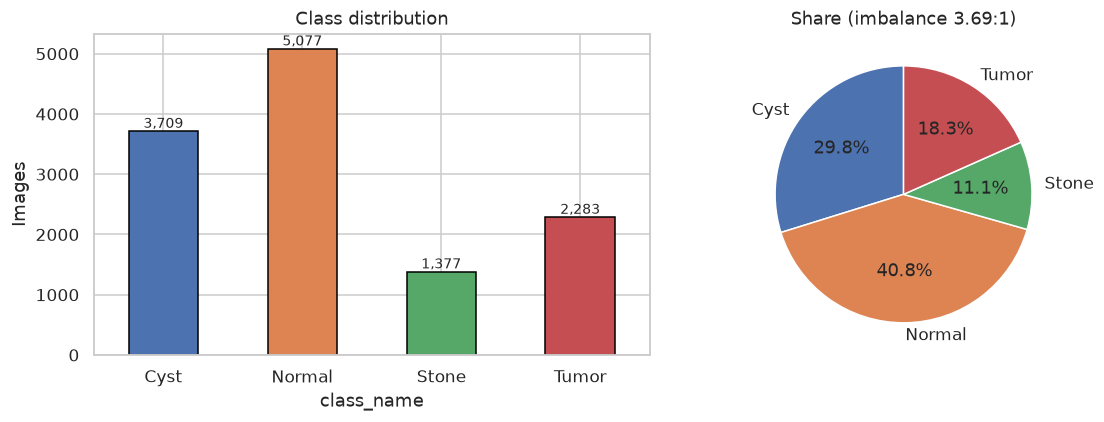

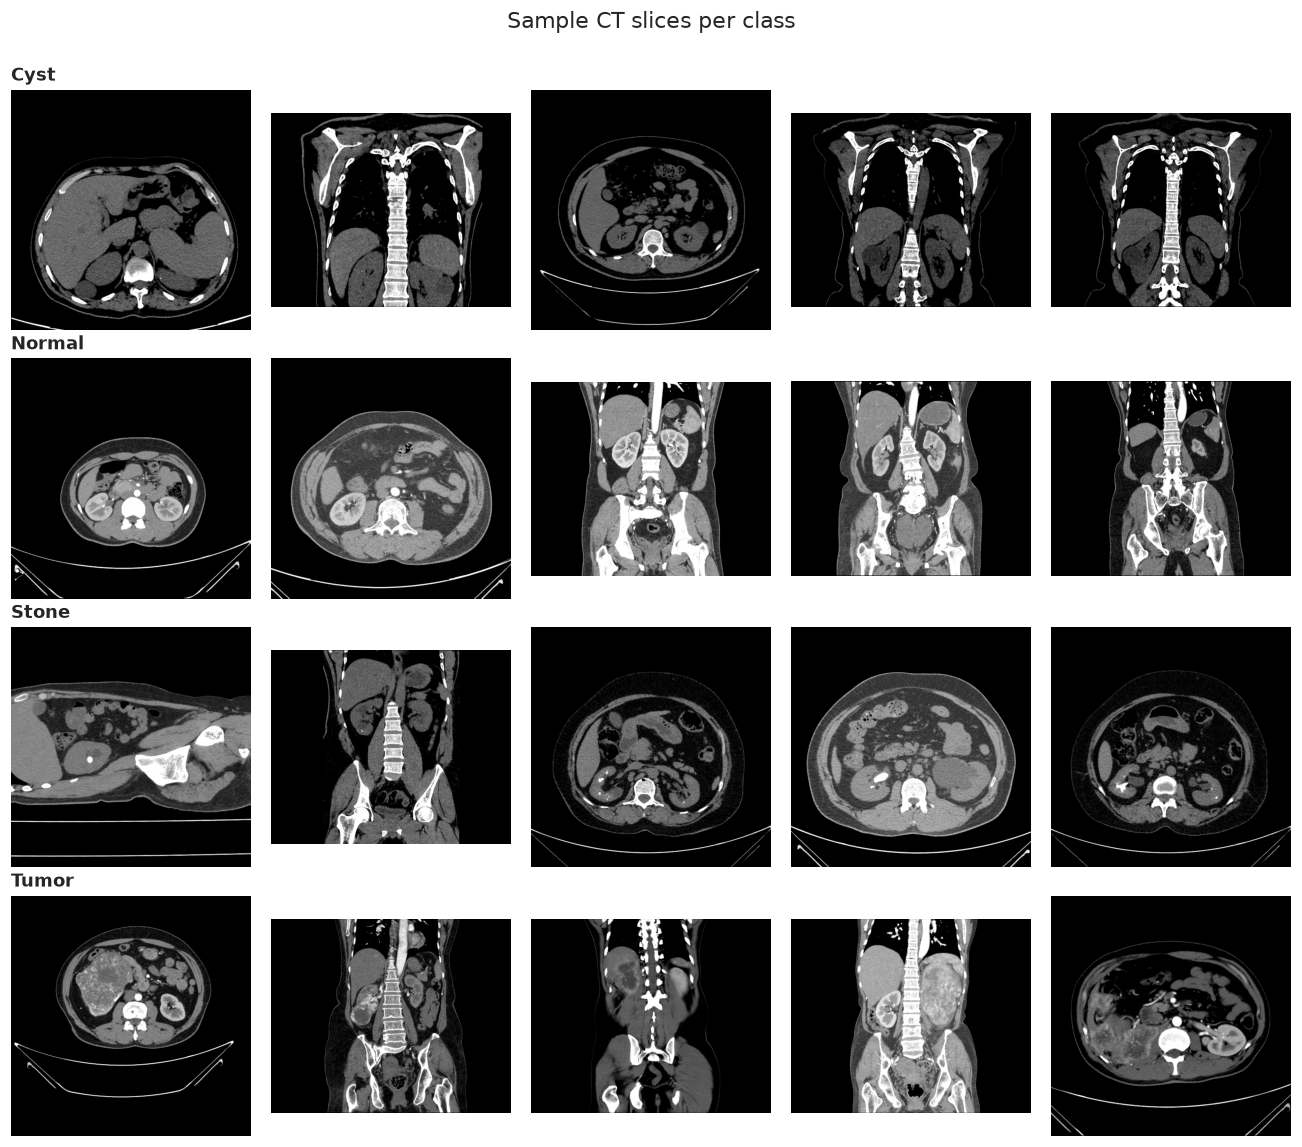

In [7]:
# Phase 1.3 — Class distribution and samples

fig, axes = plt.subplots(1,2,figsize=(11,4))
counts.plot(kind="bar", ax=axes[0], color=sns.color_palette("deep",NUM_CLASSES), edgecolor="black")
axes[0].set_title("Class distribution"); axes[0].set_ylabel("Images"); axes[0].tick_params(axis="x",rotation=0)
for i,v in enumerate(counts.values): axes[0].text(i,v+60,f"{v:,}",ha="center",fontsize=9)
axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("deep",NUM_CLASSES), wedgeprops={"edgecolor":"white"})
axes[1].set_title(f"Share (imbalance {imbalance_ratio:.2f}:1)")
plt.tight_layout(); plt.savefig(OUT/"figures"/"fig1_class_distribution.png"); plt.show()

fig, axes = plt.subplots(NUM_CLASSES,5,figsize=(12,2.6*NUM_CLASSES))
for r,cls in enumerate(CFG.CLASSES):
    sub = manifest[manifest.class_name==cls].sample(5,random_state=CFG.PRIMARY_SEED)
    for c,(_,row) in enumerate(sub.iterrows()):
        axes[r,c].imshow(Image.open(row["path"]).convert("L"),cmap="gray"); axes[r,c].axis("off")
        if c==0: axes[r,c].set_title(cls,loc="left",fontsize=12,fontweight="bold")
plt.suptitle("Sample CT slices per class",y=1.001); plt.tight_layout()
plt.savefig(OUT/"figures"/"fig2_sample_images.png"); plt.show()

---
## Phase 2 — Duplicate-Aware Partitioning (DAP)

Consecutive CT slices of the same kidney are nearly identical. A random split puts slice 41
in train and slice 42 in test, and the model is graded on something it memorised.

We link two images only when **both** hashes agree (`dHash ≤ t_d` **AND** `pHash ≤ t_p`).
A single hash alone merges half the dataset. Connected components of the resulting graph are
**groups**; we split groups, never images.

FIX 7: hashing now runs in a process pool.

In [8]:
# Phase 2.1 — Hash functions (module-level so they pickle for multiprocessing)

def _gray(path, size):
    return np.asarray(Image.open(path).convert("L").resize((size,size), Image.LANCZOS),
                      dtype=np.float32)

def dhash_bits(path, hash_size=8):
    a = _gray(path, hash_size+1)[:hash_size,:hash_size+1]
    return (a[:,1:] > a[:,:-1]).flatten().astype(np.uint8)

def phash_bits(path, hash_size=8, highfreq=4):
    a = _gray(path, hash_size*highfreq)
    d = dct(dct(a,axis=0,norm="ortho"),axis=1,norm="ortho")[:hash_size,:hash_size]
    return (d > np.median(d[1:,1:])).flatten().astype(np.uint8)

def exact_md5(path):
    h = hashlib.md5()
    with open(path,"rb") as f:
        for chunk in iter(lambda: f.read(1<<16), b""): h.update(chunk)
    return h.hexdigest()

def hash_one(path):
    return dhash_bits(path), phash_bits(path), exact_md5(path)

_p = manifest.iloc[0]["path"]
assert (dhash_bits(_p)==dhash_bits(_p)).all() and (phash_bits(_p)==phash_bits(_p)).all()
print("Hash self-test passed.")

Hash self-test passed.


In [9]:
# Phase 2.2 — Hash all images (parallel)

t0=time.time(); paths = manifest["path"].tolist()
try:
    with ProcessPoolExecutor(max_workers=CFG.HASH_WORKERS) as ex:
        results = list(tqdm(ex.map(hash_one, paths, chunksize=64), total=len(paths), desc="Hashing"))
except Exception as e:
    print(f"Parallel hashing failed ({type(e).__name__}), falling back to serial.")
    results = [hash_one(p) for p in tqdm(paths, desc="Hashing (serial)")]

DH = np.stack([r[0] for r in results]).astype(np.uint8)
PH = np.stack([r[1] for r in results]).astype(np.uint8)
manifest["md5"] = [r[2] for r in results]
manifest["dhash_hex"] = ["".join(map(str,r)) for r in DH]
manifest["phash_hex"] = ["".join(map(str,r)) for r in PH]
print(f"Hashed {N:,} images in {time.time()-t0:.1f}s  |  DH {DH.shape}  PH {PH.shape}")

md5_dupes = int(manifest.md5.duplicated().sum())
dh_ex = N - manifest.dhash_hex.nunique()
ph_ex = N - manifest.phash_hex.nunique()
both_ex = N - manifest[["dhash_hex","phash_hex"]].drop_duplicates().shape[0]
print(f"\nExact byte-identical files : {md5_dupes:,} ({md5_dupes/N:.2%})   <- report separately")
print(f"Exact dHash collisions     : {dh_ex:,} ({dh_ex/N:.2%})")
print(f"Exact pHash collisions     : {ph_ex:,} ({ph_ex/N:.2%})")
print(f"Exact on BOTH hashes       : {both_ex:,} ({both_ex/N:.2%})")
print("\nHigh single-hash collision rates are normal for CT slices, not a bug. The AND-rule")
print("below is what stops grouping from collapsing into one blob.")

Hashing:   0%|          | 0/12446 [00:00<?, ?it/s]

Hashed 12,446 images in 43.1s  |  DH (12446, 64)  PH (12446, 64)

Exact byte-identical files : 517 (4.15%)   <- report separately
Exact dHash collisions     : 8,001 (64.29%)
Exact pHash collisions     : 6,258 (50.28%)
Exact on BOTH hashes       : 4,107 (33.00%)

High single-hash collision rates are normal for CT slices, not a bug. The AND-rule
below is what stops grouping from collapsing into one blob.


In [10]:
# Phase 2.2a - v12.8: is the figshare release the same benchmark as the Kaggle release?
#
# Every earlier version used the Kaggle copy (nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone).
# If a local copy of it exists, this cell compares the two releases image by image (md5 + class),
# which tells you three things:
#   * whether results from v12.7 and earlier carry over - and whether the old Phase 7 checkpoint
#     and the old contrast-phase labels can be reused (only if file names AND bytes match);
#   * whether the figshare upload was re-encoded, resized or relabelled;
#   * the sentence for the Methods section ("byte-identical to the Kaggle release" or not).
# Set $KAGGLE_COPY if your Kaggle copy lives somewhere else. No copy -> the cell just says so.

KAGGLE_COPY = Path(os.environ.get("KAGGLE_COPY", Path.home()/".cache"/"kagglehub"/"datasets"/
                                  "nazmul0087"/"ct-kidney-dataset-normal-cyst-tumor-and-stone"))
PROVENANCE = {"kaggle_copy_found": False}
DATA_IDENTICAL_TO_KAGGLE = False

if KAGGLE_COPY.exists():
    _kd, _ = find_class_dirs(KAGGLE_COPY, CFG.CLASSES, quiet=True)
    _kf = [(c, p) for c in CFG.CLASSES
           for p in sorted((p for d in _kd[c] for p in d.rglob("*") if _is_img(p)), key=lambda p: (p.name, str(p)))]
    _kp = [str(p) for _, p in _kf]
    try:
        with ProcessPoolExecutor(max_workers=CFG.HASH_WORKERS) as ex:
            _km = list(tqdm(ex.map(exact_md5, _kp, chunksize=64), total=len(_kp), desc="md5 (Kaggle copy)"))
    except Exception:
        _km = [exact_md5(p) for p in tqdm(_kp, desc="md5 (Kaggle copy, serial)")]
    kag = pd.DataFrame({"class_name": [c for c, _ in _kf], "filename": [p.name for _, p in _kf], "md5": _km})

    fig_set, kag_set = Counter(zip(manifest.md5, manifest.class_name)), Counter(zip(kag.md5, kag.class_name))
    shared = sum((fig_set & kag_set).values())
    _lab = (pd.concat([manifest[["md5","class_name"]].assign(src="figshare"), kag[["md5","class_name"]].assign(src="kaggle")])
              .groupby("md5").class_name.nunique())
    relabelled = int((_lab > 1).sum())
    same_sequence = (len(kag) == N and
                     (kag[["class_name","filename","md5"]].values == manifest[["class_name","filename","md5"]].values).all())
    _byname = manifest.merge(kag, on=["class_name","filename"], suffixes=("_fig","_kag"))
    DATA_IDENTICAL_TO_KAGGLE = bool(same_sequence)
    PROVENANCE = {"kaggle_copy_found": True, "kaggle_images": int(len(kag)), "figshare_images": int(N),
                  "shared_images_md5_and_class": int(shared),
                  "only_in_figshare": int(N - shared), "only_in_kaggle": int(len(kag) - shared),
                  "md5_with_different_class_across_releases": relabelled,
                  "same_filename_same_bytes": int((_byname.md5_fig == _byname.md5_kag).sum()),
                  "same_filename_different_bytes": int((_byname.md5_fig != _byname.md5_kag).sum()),
                  "identical_file_sequence": DATA_IDENTICAL_TO_KAGGLE}

    print(f"Kaggle copy: {KAGGLE_COPY}")
    print(f"  images            figshare {N:,} | Kaggle {len(kag):,}")
    print(f"  shared (md5+class) {shared:,}   only figshare {N-shared:,}   only Kaggle {len(kag)-shared:,}")
    print(f"  same name, same bytes {PROVENANCE['same_filename_same_bytes']:,} | "
          f"same name, different bytes {PROVENANCE['same_filename_different_bytes']:,}")
    print(f"  identical bytes filed under different classes: {relabelled}")
    if DATA_IDENTICAL_TO_KAGGLE:
        print("\nBYTE-IDENTICAL, same file names and classes. Every v12.7 number, the Phase 7 checkpoint and")
        print("the old contrast-phase labels carry over. Methods: 'obtained from figshare (doi:...), which is")
        print("byte-identical to the widely used Kaggle release'.")
    elif shared == N == len(kag) and relabelled == 0:
        print("\nSame images, different file names. Results are equivalent, but img_id / group numbering")
        print("differ, so the Phase 7 checkpoint is retrained and the contrast-phase key must be rebuilt.")
    else:
        print("\n!!! The figshare release DIFFERS from the Kaggle release. Treat it as a new dataset:")
        print("    old checkpoints, caches and contrast labels do not apply, and the paper must say which")
        print("    release was used. 'same name, different bytes' > 0 usually means re-encoding or resizing;")
        print("    Phase 2.2c's size table will show it.")
        if relabelled: print(f"    {relabelled} identical images carry different labels in the two releases - report it.")
else:
    print(f"No Kaggle copy at {KAGGLE_COPY} - provenance comparison skipped (set $KAGGLE_COPY to run it).")
    print("Without it, the Phase 7 checkpoint from an earlier run is not reused.")

md5 (Kaggle copy):   0%|          | 0/12446 [00:00<?, ?it/s]

Kaggle copy: /home/score/.cache/kagglehub/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone
  images            figshare 12,446 | Kaggle 12,446
  shared (md5+class) 12,446   only figshare 0   only Kaggle 0
  same name, same bytes 12,446 | same name, different bytes 0
  identical bytes filed under different classes: 0

BYTE-IDENTICAL, same file names and classes. Every v12.7 number, the Phase 7 checkpoint and
the old contrast-phase labels carry over. Methods: 'obtained from figshare (doi:...), which is
byte-identical to the widely used Kaggle release'.


In [11]:
# Phase 2.2b - NEW v11: dataset integrity audit
# Two checks a reviewer will ask for that v10 never ran.

# --- 1. Do byte-identical files carry DIFFERENT labels? ---
# Identical pixels with two different labels is an annotation error in the dataset
# itself, not in your pipeline. Either way it must be reported.
_conf = manifest.groupby("md5")["label"].nunique()
n_md5_conflict = int((_conf > 1).sum())
md5_conflicts = pd.DataFrame()
print(f"Byte-identical files with conflicting labels : {n_md5_conflict}")
if n_md5_conflict:
    _bad = _conf[_conf > 1].index
    md5_conflicts = (manifest[manifest.md5.isin(_bad)][["md5","filename","class_name"]]
                     .sort_values(["md5","class_name"]))
    display(md5_conflicts.head(30))
    md5_conflicts.to_csv(OUT/"tables"/"md5_label_conflicts.csv", index=False)
    print("\nREPORT THIS IN THE PAPER. It is a defect in the benchmark, and it caps the")
    print("accuracy any model can reach. It also strengthens your audit narrative.")
else:
    print("Clean: no byte-identical file carries two different labels. Say so explicitly -")
    print("it rules out the simplest form of label noise.")

# --- 2. Decodability and geometry ---
_bad_files=[]; _sizes=[]; _modes=[]
for _p in tqdm(manifest["path"].tolist(), desc="Verifying images"):
    try:
        with Image.open(_p) as _im: _im.verify()
        with Image.open(_p) as _im: _sizes.append(_im.size); _modes.append(_im.mode)
    except Exception as _e:
        _bad_files.append((_p, type(_e).__name__)); _sizes.append((0,0)); _modes.append("BAD")

manifest["width"]  = [s[0] for s in _sizes]
manifest["height"] = [s[1] for s in _sizes]
manifest["mode"]   = _modes

print(f"\nUnreadable files : {len(_bad_files)}")
print(f"Distinct (w,h)   : {manifest.groupby(['width','height']).ngroups}")
display(manifest.groupby(["width","height"]).size()
        .sort_values(ascending=False).head(8).rename("images"))
print(f"Colour modes     : {dict(Counter(_modes))}")
assert not _bad_files, f"Unreadable images: {_bad_files[:5]}"
print("\nAll images decode. Geometry recorded for the Methods section.")


Byte-identical files with conflicting labels : 0
Clean: no byte-identical file carries two different labels. Say so explicitly -
it rules out the simplest form of label noise.


Verifying images:   0%|          | 0/12446 [00:00<?, ?it/s]


Unreadable files : 0
Distinct (w,h)   : 77


width  height
512    512       7709
798    646        240
804    651        179
768    622        177
840    680        171
764    619        160
1236   1001       155
787    636        141
Name: images, dtype: int64

Colour modes     : {'RGB': 12446}

All images decode. Geometry recorded for the Methods section.


In [12]:
# Phase 2.2c - Image-size inventory (descriptive only)
#
# 77 distinct image sizes, with only 7,709 of 12,446 images at 512x512 and a long tail
# (798x646, 804x651, 768x622, 1236x1001, ...): the benchmark was assembled from
# heterogeneous exports. This cell only DESCRIBES that.
#
# v12.3: whether size is a class SHORTCUT is tested in Phase 2.3b, not here. That test
# needs the scan groups from Phase 2.3. The v12 version of this cell scored a size-only
# classifier with random image-level CV and reported "SHORTCUT FOUND" at 0.62 accuracy -
# but 97% of scans have a single image size, so random CV was matching images to their
# own scan. With whole scans held out the same classifier falls to the majority
# baseline. See 2.3b.

manifest["size_key"]=manifest.width.astype(str)+"x"+manifest.height.astype(str)
size_ct=pd.crosstab(manifest.size_key,manifest.class_name)
size_n=size_ct.sum(1)
size_purity=size_ct.max(1)/size_n

print(f"Distinct image sizes : {len(size_ct):,}")
print(f"Most common size     : {size_n.idxmax()} ({size_n.max():,} images, {size_n.max()/N:.1%})")
print(f"Sizes used by <20 images: {int((size_n<20).sum())}")
_show=(pd.DataFrame({"images":size_n,"purity":size_purity,"majority":size_ct.idxmax(1)})
         .sort_values("images",ascending=False).head(15))
display(_show.round(3))
size_ct.assign(images=size_n,purity=size_purity).to_csv(OUT/"tables"/"size_class_audit.csv")
print("\nHigh per-size purity is expected if each size belongs to one scan - it says")
print("nothing about class yet. Phase 2.3b tests that with scans held out.")

Distinct image sizes : 77
Most common size     : 512x512 (7,709 images, 61.9%)
Sizes used by <20 images: 24


,images,purity,majority
size_key,,,
512x512,7709,0.425,Normal
798x646,240,1.000,Cyst
804x651,179,0.838,Normal
768x622,177,1.000,Tumor
840x680,171,1.000,Normal
764x619,160,0.756,Tumor
1236x1001,155,0.761,Stone
787x636,141,0.489,Normal
705x569,140,1.000,Cyst



High per-size purity is expected if each size belongs to one scan - it says
nothing about class yet. Phase 2.3b tests that with scans held out.


In [13]:
# Phase 2.3 - Pairwise Hamming via chunked matmul, then union-find
# v11: the whole grouping procedure is now a FUNCTION. Phase 13.4 calls it repeatedly
# with different thresholds to test whether the headline inflation is an artifact of
# one arbitrary threshold choice.

def hamming_matrix(A,B):
    Af,Bf = A.astype(np.float32), B.astype(np.float32)
    return (Af@(1.0-Bf).T + (1.0-Af)@Bf.T).astype(np.int16)

def build_edges(DH,PH,dthr,pthr,chunk=1024,quiet=False):
    n=DH.shape[0]; edges=[]
    it = range(0,n,chunk)
    for start in (it if quiet else tqdm(list(it), desc=f"Pairs (d<={dthr},p<={pthr})")):
        end=min(start+chunk,n)
        mask = (hamming_matrix(DH[start:end],DH)<=dthr) & (hamming_matrix(PH[start:end],PH)<=pthr)
        r,c = np.nonzero(mask); r=r+start; keep=r<c
        edges.extend(zip(r[keep].tolist(), c[keep].tolist()))
    return edges

class UnionFind:
    def __init__(s,n): s.p=list(range(n)); s.r=[0]*n
    def find(s,x):
        while s.p[x]!=x: s.p[x]=s.p[s.p[x]]; x=s.p[x]
        return x
    def union(s,a,b):
        ra,rb=s.find(a),s.find(b)
        if ra==rb: return
        if s.r[ra]<s.r[rb]: ra,rb=rb,ra
        s.p[rb]=ra
        if s.r[ra]==s.r[rb]: s.r[ra]+=1

def group_from_edges(n,edges):
    uf=UnionFind(n)
    for i,j in edges: uf.union(i,j)
    roots=[uf.find(i) for i in range(n)]
    remap={r:k for k,r in enumerate(sorted(set(roots)))}
    return np.array([remap[r] for r in roots],dtype=np.int64)

def make_groups(dthr, pthr, quiet=False):
    """Pure function: thresholds -> (group_ids, edges, stats). No globals mutated."""
    e = build_edges(DH,PH,dthr,pthr,quiet=quiet)
    g = group_from_edges(N,e)
    sz = pd.Series(g).value_counts()
    st = {"dhash":dthr,"phash":pthr,"n_pairs":len(e),"n_groups":int(sz.shape[0]),
          "n_singletons":int((sz==1).sum()),"largest_frac":float(sz.iloc[0]/N),
          "mean_group_size":float(N/sz.shape[0]),"median_group_size":float(sz.median())}
    return g, e, st

t0=time.time()
dthr,pthr = CFG.DHASH_THRESH, CFG.PHASH_THRESH
groups, edges, gstat = make_groups(dthr,pthr)

for attempt in range(6):
    print(f"attempt {attempt}: (d<={dthr},p<={pthr}) -> {gstat['n_groups']:,} groups, "
          f"largest {gstat['largest_frac']:.2%}")
    if gstat["largest_frac"]<=CFG.MAX_GROUP_FRAC or not CFG.AUTO_TIGHTEN: break
    dthr,pthr = max(0,dthr-1), max(0,pthr-1)
    print(f"  collapse detected -> tightening to (d<={dthr},p<={pthr})")
    groups, edges, gstat = make_groups(dthr,pthr)

manifest["group_id"]=groups
FINAL_DTHR, FINAL_PTHR = dthr, pthr
# FIX 3: keep CFG in sync so RESULTS.json records the thresholds actually used
CFG.DHASH_THRESH, CFG.PHASH_THRESH = FINAL_DTHR, FINAL_PTHR

gsizes = manifest.group_id.value_counts()
n_groups = int(gsizes.shape[0]); n_singletons = int((gsizes==1).sum())
print(f"\n{'='*62}\nDAP AUDIT REPORT\n{'='*62}")
print(f"Images                       : {N:,}")
print(f"Final thresholds             : dHash <= {FINAL_DTHR}, pHash <= {FINAL_PTHR}")
print(f"Near-duplicate pairs         : {len(edges):,}")
print(f"Groups (estimated scans)     : {n_groups:,}")
print(f"Singleton groups             : {n_singletons:,}")
print(f"Images in multi-image groups : {N-n_singletons:,} ({(N-n_singletons)/N:.1%})")
print(f"Largest group                : {gsizes.iloc[0]:,} ({gsizes.iloc[0]/N:.2%})")
print(f"Mean / median group size     : {N/n_groups:.2f} / {gsizes.median():.0f}")
print(f"{'='*62}")
print(f"\n{(N-n_singletons)/N:.1%} of images have a near-duplicate elsewhere in the dataset.")
print(f"Computed in {time.time()-t0:.1f}s")
assert gsizes.iloc[0]/N <= 0.5, "Grouping collapsed. Lower thresholds manually."

# --- v11 HONESTY CHECK -------------------------------------------------------
# Very few groups relative to image count means the linkage may have OVER-MERGED:
# distinct scans fused into one group. That is not neutral for your headline.
#   - It makes the DAP score a LOWER bound (conservative, fine).
#   - But inflation = random - DAP, so a depressed DAP number makes the inflation
#     an UPPER bound. Your headline claim is anti-conservative in that direction.
# Phase 13.4 is the answer to this. Do not skip it.
if n_groups < 500 or n_singletons < 20:
    print("\n" + "!"*74)
    print(f"OVER-MERGE WARNING: {n_groups:,} groups, {n_singletons:,} singletons for {N:,} images.")
    print("Mean group size is", f"{N/n_groups:.0f}.", "Perceptual hashing on low-contrast CT")
    print("over-links easily. This makes DAP a lower bound on score, but it makes the")
    print("INFLATION AN UPPER BOUND - the opposite of conservative for your main claim.")
    print("Phase 13.4 (threshold sensitivity) is mandatory before you write the abstract.")
    print("!"*74)


Pairs (d<=5,p<=8):   0%|          | 0/13 [00:00<?, ?it/s]

attempt 0: (d<=5,p<=8) -> 154 groups, largest 16.95%
  collapse detected -> tightening to (d<=4,p<=7)


Pairs (d<=4,p<=7):   0%|          | 0/13 [00:00<?, ?it/s]

attempt 1: (d<=4,p<=7) -> 193 groups, largest 2.98%

DAP AUDIT REPORT
Images                       : 12,446
Final thresholds             : dHash <= 4, pHash <= 7
Near-duplicate pairs         : 131,120
Groups (estimated scans)     : 193
Singleton groups             : 2
Images in multi-image groups : 12,444 (100.0%)
Largest group                : 371 (2.98%)
Mean / median group size     : 64.49 / 33

100.0% of images have a near-duplicate elsewhere in the dataset.
Computed in 6.1s

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
OVER-MERGE WARNING: 193 groups, 2 singletons for 12,446 images.
Mean group size is 64. Perceptual hashing on low-contrast CT
over-links easily. This makes DAP a lower bound on score, but it makes the
INFLATION AN UPPER BOUND - the opposite of conservative for your main claim.
Phase 13.4 (threshold sensitivity) is mandatory before you write the abstract.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


In [14]:
# Phase 2.3b - NEW v12.3: is image size a CLASS shortcut, or a SCAN fingerprint?
#
# Needs the scan groups from Phase 2.3, which is why it sits here and not in 2.2c.
#
# A size-only lookup classifier (majority class per image size) is scored two ways:
#   random image-level CV : a test image's own scan is in the training folds
#   grouped CV            : whole scans are held out - the only question that matters
# If size predicts class, both are high. If size only identifies the SCAN, random CV is
# high (it matches each image to its scan) and grouped CV falls to the majority baseline.
#
# The mutual-information null is also built at SCAN level: each scan's size is
# reassigned to another scan. An image-level shuffle (as in v12) breaks the scan
# structure and makes any scan-constant attribute look significant.
#
# Finally, WHY do sizes vary? Each scan's view (axial vs coronal) is estimated from the
# body outline: coronal bodies run off the top/bottom of the frame (chest, legs) or are
# tall; axial bodies sit inside the frame on the table. Checked by eye against the
# images before being written in here; scans should be single-view, so per-scan
# agreement is printed as the reliability check.

from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from scipy import ndimage as ndi

_base=float(manifest.class_name.value_counts(normalize=True).max())

def size_lookup_cv(df, grouped, seed, k=5):
    """Majority class per size_key, fitted on train folds. Unseen sizes -> global majority."""
    y=df.class_name.values
    split=(StratifiedGroupKFold(k,shuffle=True,random_state=seed).split(df,y,df.group_id) if grouped
           else StratifiedKFold(k,shuffle=True,random_state=seed).split(df,y))
    ok=0
    for tr,te in split:
        maj=df.iloc[tr].groupby("size_key").class_name.agg(lambda s:s.value_counts().idxmax())
        glob=df.iloc[tr].class_name.value_counts().idxmax()
        ok+=int((df.iloc[te].size_key.map(maj).fillna(glob).values==y[te]).sum())
    return ok/len(df)

_seeds=range(5)
_rand=np.array([size_lookup_cv(manifest,False,s) for s in _seeds])
_grp =np.array([size_lookup_cv(manifest,True, s) for s in _seeds])
SIZE_ACC_RANDOM,SIZE_ACC_GROUPED=float(_rand.mean()),float(_grp.mean())
SIZE_ONLY_ACC=SIZE_ACC_GROUPED        # the valid number; kept under the v12 name for Phase 25

print(f"{'SIZE-ONLY CLASSIFIER':38s} accuracy (5 seeds x 5 folds)")
print(f"  random image-level CV                {SIZE_ACC_RANDOM:.4f} +/- {_rand.std(ddof=1):.4f}   <- scan memorisation")
print(f"  GROUPED CV (whole scans held out)    {SIZE_ACC_GROUPED:.4f} +/- {_grp.std(ddof=1):.4f}   <- report this")
print(f"  majority-class baseline              {_base:.4f}")
print(f"  lift over baseline, grouped          {SIZE_ACC_GROUPED-_base:+.4f}")

# --- mutual information, scan-level permutation null ---
def _mi(a,b):
    P=pd.crosstab(a,b).values.astype(float); P/=P.sum()
    pr=P.sum(1,keepdims=True); pc=P.sum(0,keepdims=True); nz=P>0
    return float((P[nz]*np.log(P[nz]/(pr@pc)[nz])).sum())
_scan_size=manifest.groupby("group_id").size_key.agg(lambda s:s.mode()[0])   # 1 size per scan
_img_size=manifest.group_id.map(_scan_size)
SIZE_MI=_mi(_img_size,manifest.class_name)
_rng=np.random.RandomState(CFG.PRIMARY_SEED)
_null=np.array([_mi(manifest.group_id.map(dict(zip(_scan_size.index,_rng.permutation(_scan_size.values)))),
                    manifest.class_name) for _ in range(1000)])
_H=float(-sum((v/N)*np.log(v/N) for v in manifest.label.value_counts()))
SIZE_MI_NULL=float(_null.mean()); SIZE_MI_P=float(((_null>=SIZE_MI).sum()+1)/(len(_null)+1))   # v12.7: never exactly 0
SIZE_MI_FRAC=max(0.0,SIZE_MI-SIZE_MI_NULL)/_H
print(f"\nI(scan size ; class)                   {SIZE_MI:.4f} nats")
print(f"  scan-shuffle null (1000)             {SIZE_MI_NULL:.4f}  (95th pct {np.percentile(_null,95):.4f})")
print(f"  excess over null, share of H(class)  {SIZE_MI_FRAC:.1%}   p = {SIZE_MI_P:.3f}")

# --- fingerprint statistics ---
_sizes_per_scan=manifest.groupby("group_id").size_key.nunique()
_scans_per_size=manifest.groupby("size_key").group_id.nunique()
print(f"\nScans whose images share ONE size      {(_sizes_per_scan==1).mean():.1%}")
print(f"Sizes used by exactly one scan         {(_scans_per_size==1).mean():.1%} "
      f"({int((_scans_per_size==1).sum())} of {len(_scans_per_size)})")

# --- why: view (axial vs coronal) from the body outline ---
_S=256; _disk=np.hypot(*np.mgrid[-3:4,-3:4])<=3.5
def view_features(path):
    g=np.asarray(Image.open(path).convert("L").resize((_S,_S),Image.BOX),dtype=np.uint8)
    # pad by edge replication so morphology does not erode a body that runs off the frame;
    # otherwise the touches-top/bottom test below fails on exactly the coronal slices
    m=np.pad(g>=0.10*255,4,mode="edge")
    m=ndi.binary_closing(ndi.binary_opening(m,_disk),_disk)[4:-4,4:-4]
    lab,n=ndi.label(m,structure=np.ones((3,3)))
    if n==0: return (False,False,np.nan)
    m=ndi.binary_fill_holes(lab==(1+int(np.argmax(ndi.sum(m,lab,range(1,n+1))))))
    ys,xs=np.nonzero(m)
    return (bool(m[:3].any()), bool(m[-3:].any()), (np.ptp(ys)+1)/(np.ptp(xs)+1))

try:
    with ProcessPoolExecutor(max_workers=CFG.HASH_WORKERS) as ex:
        _vf=list(tqdm(ex.map(view_features,manifest["path"].tolist(),chunksize=64),total=N,desc="View"))
except Exception as e:
    print(f"Parallel view pass failed ({type(e).__name__}), falling back to serial.")
    _vf=[view_features(p) for p in tqdm(manifest["path"].tolist(),desc="View (serial)")]
_vf=np.array(_vf,dtype=object)
manifest["image_view"]=np.where(_vf[:,0].astype(bool)|_vf[:,1].astype(bool)|(_vf[:,2].astype(float)>=1.2),
                                "coronal","axial")
manifest["view"]=manifest.group_id.map(manifest.groupby("group_id").image_view.agg(lambda s:s.mode()[0]))
_agree=float((manifest.image_view==manifest.view).mean())
print(f"\nVIEW (per scan, majority of per-image calls)")
print(f"  image calls agreeing with their scan {_agree:.2%}   <- reliability; a scan has one view")
print(f"  scans   axial {int((manifest.drop_duplicates('group_id').view=='axial').sum())}"
      f" | coronal {int((manifest.drop_duplicates('group_id').view=='coronal').sum())}")
display(pd.crosstab(manifest.view,np.where(manifest.size_key=="512x512","512x512","other size"),
                    margins=True).rename_axis(index="view",columns="size"))
display((pd.crosstab(manifest.view,manifest.class_name,normalize="index")*100).round(1)
        .rename_axis(index="view  (row %)"))
VIEW_ACC_GROUPED=float(np.mean([size_lookup_cv(manifest.assign(size_key=manifest.view),True,s) for s in _seeds]))
print(f"View-only classifier, grouped CV       {VIEW_ACC_GROUPED:.4f}  (baseline {_base:.4f})")
manifest[["img_id","filename","group_id","size_key","image_view","view"]].to_csv(
    OUT/"tables"/"image_views.csv",index=False)

# --- verdict ---
if SIZE_ACC_GROUPED>_base+0.03:
    SIZE_VERDICT="class_shortcut"
    print("\n"+"!"*74)
    print("CLASS SHORTCUT: image size predicts class even for scans never seen in training.")
    print("Report it next to the contamination rate.")
    print("!"*74)
elif SIZE_ACC_RANDOM-SIZE_ACC_GROUPED>0.05:
    SIZE_VERDICT="scan_fingerprint"
    print("\n"+"="*74)
    print("SCAN FINGERPRINT, NOT A CLASS SHORTCUT.")
    print(f"  Random CV {SIZE_ACC_RANDOM:.3f} vs grouped CV {SIZE_ACC_GROUPED:.3f} (baseline {_base:.3f}).")
    print("  Image size identifies WHICH SCAN an image came from, not what it shows.")
    print("  Mechanism: axial series are exported at 512x512; coronal reformats are each")
    print("  exported at their own size, so size ~ view ~ scan, and view carries no class")
    print("  information (grouped view-only accuracy above).")
    print("Write it as a LEAKAGE MECHANISM, not a shortcut: under a random split, geometry")
    print("is one more cue that lets a model match a test image to its training scan.")
    print("Do NOT write 'size predicts class' - the v12 0.62 figure was scan memorisation.")
    print("="*74)
else:
    SIZE_VERDICT="no_signal"
    print("\nImage size carries no class or scan signal worth reporting. One sentence in Methods.")

SIZE-ONLY CLASSIFIER                   accuracy (5 seeds x 5 folds)
  random image-level CV                0.6236 +/- 0.0000   <- scan memorisation
  GROUPED CV (whole scans held out)    0.4073 +/- 0.0027   <- report this
  majority-class baseline              0.4079
  lift over baseline, grouped          -0.0006

I(scan size ; class)                   0.3973 nats
  scan-shuffle null (1000)             0.4635  (95th pct 0.5340)
  excess over null, share of H(class)  0.0%   p = 0.954

Scans whose images share ONE size      96.9%
Sizes used by exactly one scan         77.9% (60 of 77)


View:   0%|          | 0/12446 [00:00<?, ?it/s]


VIEW (per scan, majority of per-image calls)
  image calls agreeing with their scan 99.49%   <- reliability; a scan has one view
  scans   axial 105 | coronal 88


size,512x512,other size,All
view,,,
axial,7709,15,7724
coronal,0,4722,4722
All,7709,4737,12446


class_name,Cyst,Normal,Stone,Tumor
view (row %),,,,
axial,29.1,42.4,11.2,17.3
coronal,31.0,38.2,10.9,20.0


View-only classifier, grouped CV       0.4079  (baseline 0.4079)

SCAN FINGERPRINT, NOT A CLASS SHORTCUT.
  Random CV 0.624 vs grouped CV 0.407 (baseline 0.408).
  Image size identifies WHICH SCAN an image came from, not what it shows.
  Mechanism: axial series are exported at 512x512; coronal reformats are each
  exported at their own size, so size ~ view ~ scan, and view carries no class
  information (grouped view-only accuracy above).
Write it as a LEAKAGE MECHANISM, not a shortcut: under a random split, geometry
is one more cue that lets a model match a test image to its training scan.
Do NOT write 'size predicts class' - the v12 0.62 figure was scan memorisation.


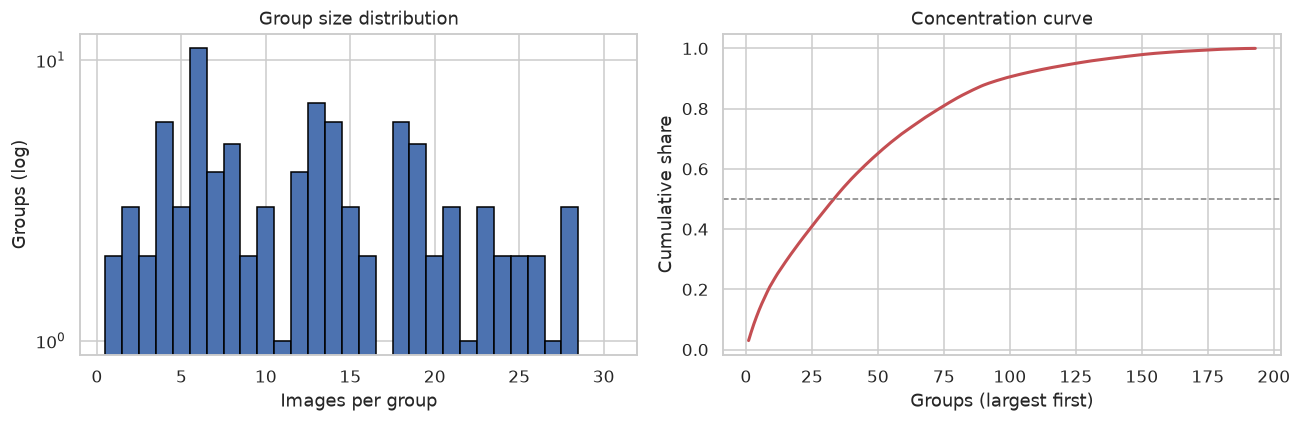

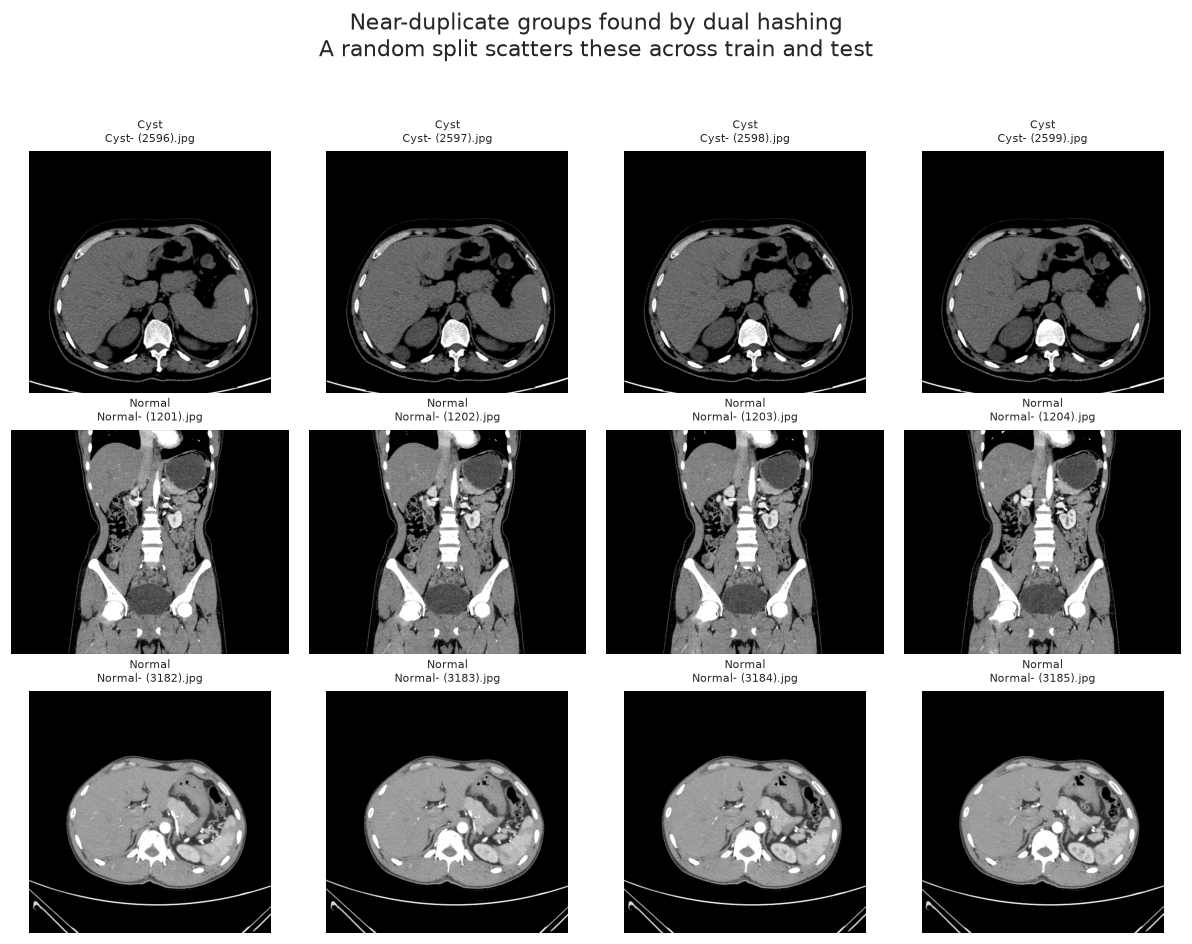

In [15]:
# Phase 2.4 — Group structure figures

fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(gsizes.values,bins=np.arange(1,min(gsizes.max(),30)+2)-0.5,color="#4C72B0",edgecolor="black")
axes[0].set_yscale("log"); axes[0].set_xlabel("Images per group")
axes[0].set_ylabel("Groups (log)"); axes[0].set_title("Group size distribution")
cum=np.cumsum(sorted(gsizes.values,reverse=True))/N
axes[1].plot(np.arange(1,len(cum)+1),cum,color="#C44E52",lw=2)
axes[1].axhline(0.5,ls="--",c="gray",lw=1)
axes[1].set_xlabel("Groups (largest first)"); axes[1].set_ylabel("Cumulative share")
axes[1].set_title("Concentration curve")
plt.tight_layout(); plt.savefig(OUT/"figures"/"fig3_group_structure.png"); plt.show()

big = gsizes[gsizes>=4].index[:3]
if len(big):
    fig,axes=plt.subplots(len(big),4,figsize=(11,2.8*len(big))); axes=np.atleast_2d(axes)
    for r,g in enumerate(big):
        for c,(_,row) in enumerate(manifest[manifest.group_id==g].head(4).iterrows()):
            axes[r,c].imshow(Image.open(row["path"]).convert("L"),cmap="gray"); axes[r,c].axis("off")
            axes[r,c].set_title(f"{row['class_name']}\n{row['filename'][:18]}",fontsize=7)
    plt.suptitle("Near-duplicate groups found by dual hashing\nA random split scatters these across train and test",y=1.02)
    plt.tight_layout(); plt.savefig(OUT/"figures"/"fig4_duplicate_examples.png"); plt.show()

Groups spanning >1 class : 9 / 193 (4.66%)
Images affected          : 2,233 (17.94%)


,group_id,size,purity,composition
0,66,147,0.503401,"Normal:74, Stone:61, Cyst:12"
1,177,281,0.533808,"Normal:150, Tumor:131"
2,82,151,0.536424,"Normal:81, Cyst:70"
3,109,128,0.578125,"Cyst:74, Normal:54"
4,189,330,0.612121,"Tumor:202, Normal:128"
5,30,371,0.668464,"Cyst:248, Tumor:123"
6,33,240,0.720833,"Stone:173, Cyst:67"
7,190,231,0.766234,"Tumor:177, Normal:54"
8,85,354,0.949153,"Normal:336, Stone:18"


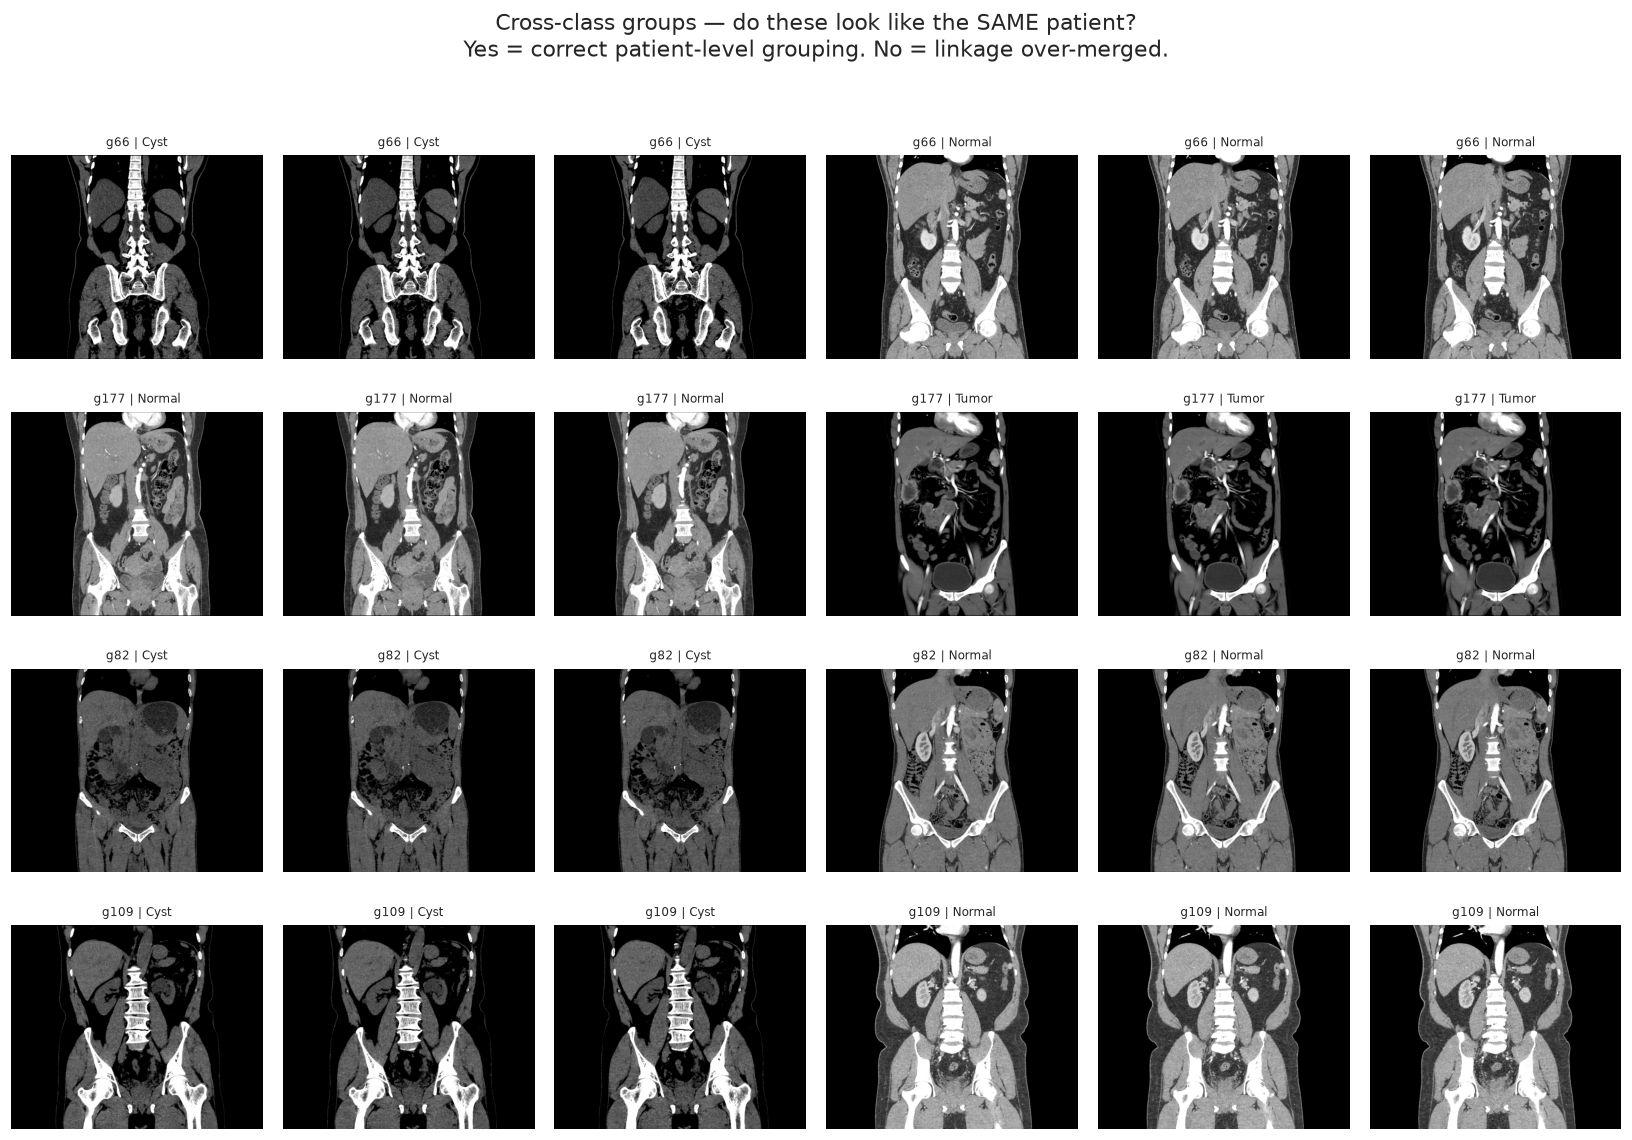


DECISION REQUIRED. Record your visual verdict in the paper:
  same patient  -> grouping is correct; note that a patient may have several findings
  unrelated     -> linkage over-merged; report it, and note it is CONSERVATIVE
                   (over-merging removes more than needed, so your score is a lower bound)

Manifest saved (release this as supplementary material).


In [16]:
# Phase 2.5 — NEW: cross-class group inspection
# In v9, 9 groups spanning 2+ classes covered 17.94% of images. Either one patient
# contributed slices with different findings (expected, fine) or the linkage over-merged
# (a problem). This cell renders them so you can decide by eye, and writes a report.

purity = manifest.groupby("group_id")["label"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
impure = purity[purity<1.0].sort_values()
n_impure = len(impure)
aff = manifest[manifest.group_id.isin(impure.index)]

print(f"Groups spanning >1 class : {n_impure:,} / {n_groups:,} ({n_impure/n_groups:.2%})")
print(f"Images affected          : {len(aff):,} ({len(aff)/N:.2%})")

rep=[]
for g in impure.index:
    m = manifest[manifest.group_id==g]
    vc = m.class_name.value_counts()
    rep.append({"group_id":int(g),"size":len(m),"purity":float(purity[g]),
                "composition":", ".join(f"{k}:{v}" for k,v in vc.items())})
impure_df = pd.DataFrame(rep)
if n_impure:
    display(impure_df)
    impure_df.to_csv(OUT/"tables"/"cross_class_groups.csv",index=False)

    show = impure.index[:min(4,n_impure)]
    fig,axes=plt.subplots(len(show),6,figsize=(15,2.6*len(show))); axes=np.atleast_2d(axes)
    for r,g in enumerate(show):
        m = manifest[manifest.group_id==g]
        picks=[]
        for cls in m.class_name.unique():
            picks += m[m.class_name==cls].head(3).to_dict("records")
        for c in range(6):
            axes[r,c].axis("off")
            if c < len(picks):
                axes[r,c].imshow(Image.open(picks[c]["path"]).convert("L"),cmap="gray")
                axes[r,c].set_title(f"g{g} | {picks[c]['class_name']}",fontsize=8)
    plt.suptitle("Cross-class groups — do these look like the SAME patient?\n"
                 "Yes = correct patient-level grouping. No = linkage over-merged.",y=1.02)
    plt.tight_layout(); plt.savefig(OUT/"figures"/"fig5_cross_class_groups.png"); plt.show()
    print("\nDECISION REQUIRED. Record your visual verdict in the paper:")
    print("  same patient  -> grouping is correct; note that a patient may have several findings")
    print("  unrelated     -> linkage over-merged; report it, and note it is CONSERVATIVE")
    print("                   (over-merging removes more than needed, so your score is a lower bound)")
else:
    print("All groups label-pure. Clean result — say so explicitly in the paper.")

manifest.to_csv(OUT/"tables"/"manifest_with_groups.csv",index=False)
print(f"\nManifest saved (release this as supplementary material).")

---
## Phase 3 — Group-aware stratified splitting

**v12.7:** groups are visited in a seeded random order and placed in whichever split is
furthest below its per-class image quota, then refined by single-group moves so that class
counts match the 70/15/15 quota *and* every split has a similar mean scan size. (v12.0-v12.6
sorted groups largest-first, which sent almost every large scan to train and made the test
set a collection of small scans; `CFG.SPLIT_METHOD="greedy_largest_first"` reproduces that.) A hard gate follows: if any
group, near-duplicate pair, or md5 appears in two splits, execution stops.

In [17]:
# Phase 3.1 — Split + leakage gate

# *** v12.7 FIX: the splitter no longer hands the test set the leftovers ***
# v12.0-v12.6 placed groups largest-first into whichever split was furthest below its class
# quota. `seed` only reordered equal-size groups, so 31 of the 32 groups larger than the
# largest test group went to train, test groups averaged 37.5 images against 93.4 in train,
# and the three seed splits shared 78-88% of their test images. The DAP score was measured
# on a non-representative set of small scans and the seed-to-seed std understated how much
# the result depends on WHICH scans are in test.
# Now: seeded random group order + class-quota greedy placement, refined by single-group
# moves that minimise (i) the per-split deviation from the 70/15/15 class-count quota and
# (ii) the gap between each split's mean log group size and the overall mean. Best of
# n_candidates restarts. Class quotas use the actual per-class image counts of each group,
# so label-mixed groups are accounted for, not just their majority class.

def _split_greedy_largest_first(df, ratios, seed):
    """v12.0-v12.6 behaviour, kept only so old numbers can be reproduced."""
    rng=np.random.RandomState(seed)
    g=(df.groupby("group_id").agg(size=("img_id","size"),
        maj=("label", lambda s: s.value_counts().idxmax())).reset_index())
    targets={s:{c:0.0 for c in range(NUM_CLASSES)} for s in ["train","val","test"]}
    for c in range(NUM_CLASSES):
        tot=df[df.label==c].shape[0]
        for s,r in zip(["train","val","test"],ratios): targets[s][c]=tot*r
    filled={s:{c:0.0 for c in range(NUM_CLASSES)} for s in ["train","val","test"]}
    assign={}
    g=g.sample(frac=1.0,random_state=rng).sort_values("size",ascending=False,kind="mergesort")
    for _,row in g.iterrows():
        c=int(row["maj"])
        best=max(["train","val","test"], key=lambda s: targets[s][c]-filled[s][c])
        assign[int(row["group_id"])]=best; filled[best][c]+=row["size"]
    return df["group_id"].map(assign)

def _split_balanced_random(df, ratios, seed, n_candidates=40, size_weight=1.0, passes=6):
    names=["train","val","test"]
    cnt=(pd.crosstab(df["group_id"],df["label"]).reindex(columns=range(NUM_CLASSES),fill_value=0)
         .sort_index())
    ids=cnt.index.values; C=cnt.values.astype(float); logn=np.log(C.sum(1)); G=len(ids)
    tot=C.sum(0); N_=tot.sum(); T=np.array([tot*r for r in ratios]); mu=logn.mean()
    def score(a):
        F=np.stack([C[a==s].sum(0) for s in range(3)])
        ml=np.array([logn[a==s].mean() if (a==s).any() else 0.0 for s in range(3)])
        return np.abs(F-T).sum()/N_ + size_weight*np.abs(ml-mu).sum()/3
    rng=np.random.RandomState(seed); best=None
    for _ in range(n_candidates):
        F=np.zeros((3,NUM_CLASSES)); a=np.empty(G,dtype=int)
        for gi in rng.permutation(G):
            d=((F+C[gi]-T)**2-(F-T)**2)/np.maximum(T,1.0)
            a[gi]=int(np.argmin(d.sum(1))); F[a[gi]]+=C[gi]
        cur=score(a)
        for _p in range(passes):
            improved=False
            for gi in rng.permutation(G):
                keep=a[gi]
                for s in range(3):
                    if s==keep: continue
                    a[gi]=s; sc=score(a)
                    if sc<cur-1e-12: cur=sc; keep=s; improved=True
                a[gi]=keep
            if not improved: break
        if best is None or cur<best[0]: best=(cur,a.copy())
    return df["group_id"].map(dict(zip(ids,[names[i] for i in best[1]])))

def group_stratified_split(df, ratios, seed):
    if CFG.SPLIT_METHOD=="greedy_largest_first": return _split_greedy_largest_first(df,ratios,seed)
    if CFG.SPLIT_METHOD=="balanced_random":      return _split_balanced_random(df,ratios,seed)
    raise ValueError(f"unknown CFG.SPLIT_METHOD {CFG.SPLIT_METHOD!r}")

def assert_no_leakage(df, edge_list):
    tr=set(df[df.split=="train"].group_id); va=set(df[df.split=="val"].group_id); te=set(df[df.split=="test"].group_id)
    split_of=dict(zip(df.img_id,df.split))
    return {"train_val_overlap":len(tr&va), "train_test_overlap":len(tr&te),
            "val_test_overlap":len(va&te),
            "cross_split_duplicate_pairs":sum(1 for i,j in edge_list if split_of[i]!=split_of[j]),
            "md5_across_splits":int((df.groupby("md5")["split"].nunique()>1).sum())}

manifest["split"]=group_stratified_split(manifest,CFG.SPLIT_RATIO,CFG.PRIMARY_SEED)
display(pd.crosstab(manifest.split,manifest.class_name,margins=True).reindex(["train","val","test","All"]))
print("\nClass proportions per split:")
display(pd.crosstab(manifest.split,manifest.class_name,normalize="index").round(4))
for s in ["train","val","test"]:
    sub=manifest[manifest.split==s]
    print(f"  {s:6s} {len(sub):6,d} ({len(sub)/N:.1%})  {sub.group_id.nunique():,} groups")

# v12.7: identify this split. Phase 7 refuses to resume a checkpoint trained on another split,
# and the run caches live in a folder named after the split method (Phase 10.9).
SPLIT_FP = hashlib.md5("".join(manifest["split"]).encode()).hexdigest()[:12]
(OUT/"logs"/"split_fingerprint.json").write_text(json.dumps(
    {"method":CFG.SPLIT_METHOD,"seed":CFG.PRIMARY_SEED,"fingerprint":SPLIT_FP}))
_gm = manifest.groupby(["split","group_id"]).size().groupby("split").mean()
print(f"\nSplit method {CFG.SPLIT_METHOD} | fingerprint {SPLIT_FP}")
print("Mean images per group  " + "  ".join(f"{s} {_gm[s]:.1f}" for s in ["train","val","test"]))
if _gm["test"]/_gm["train"] < 0.6:
    print("WARNING: test groups are much smaller than train groups. The test score then describes")
    print("small scans only; do not present it as representative of the whole benchmark.")

leak = assert_no_leakage(manifest, edges)
print(f"\nLEAKAGE GATE\n{'-'*46}")
for k,v in leak.items(): print(f"  {k:32s} {v:6,d}  [{'PASS' if v==0 else 'FAIL'}]")
for k,v in leak.items(): assert v==0, f"Leakage: {k}={v}"
print(f"{'-'*46}\nAll gates passed.")

n_test_groups = manifest[manifest.split=="test"].group_id.nunique()
if n_test_groups < 100:
    print(f"\nNOTE: only {n_test_groups} test groups. Bootstrap CIs will be wide and will")
    print("likely overlap between models. State in the paper that significance cannot be")
    print("claimed between architectures — do not let a reviewer point it out first.")
json.dump(leak, open(OUT/"logs"/"leakage_gate.json","w"), indent=2)
manifest.to_csv(OUT/"tables"/"manifest_final.csv",index=False)

class_name,Cyst,Normal,Stone,Tumor,All
split,,,,,
train,2605,3552,951,1603,8711
val,548,758,221,342,1869
test,556,767,205,338,1866
All,3709,5077,1377,2283,12446



Class proportions per split:


class_name,Cyst,Normal,Stone,Tumor
split,,,,
test,0.2980,0.4110,0.1099,0.1811
train,0.2990,0.4078,0.1092,0.1840
val,0.2932,0.4056,0.1182,0.1830


  train   8,711 (70.0%)  126 groups
  val     1,869 (15.0%)  36 groups
  test    1,866 (15.0%)  31 groups

Split method balanced_random | fingerprint 1b579afa95aa
Mean images per group  train 69.1  val 51.9  test 60.2

LEAKAGE GATE
----------------------------------------------
  train_val_overlap                     0  [PASS]
  train_test_overlap                    0  [PASS]
  val_test_overlap                      0  [PASS]
  cross_split_duplicate_pairs           0  [PASS]
  md5_across_splits                     0  [PASS]
----------------------------------------------
All gates passed.

NOTE: only 31 test groups. Bootstrap CIs will be wide and will
likely overlap between models. State in the paper that significance cannot be
claimed between architectures — do not let a reviewer point it out first.


---
## Phase 3.2–3.3 — Acquisition-protocol confound (contrast phase) · NEW v12.6

DAP guarantees that no scan sits in two splits. It says nothing about a property that
**every** split shares. In this benchmark the diagnosis travels with the CT protocol:
Normal and Tumor scans are contrast-enhanced, Cyst and Stone scans are not. If that holds,
a model can separate {Normal, Tumor} from {Cyst, Stone} by protocol alone, and a
leakage-free test split cannot detect it.

- **3.2** renders blinded contact sheets (one mid slice per scan, random IDs only), reads
  the rater's labels and, once a second rater has labelled the same sheets, reports Cohen's κ.
- **3.3** measures the confound without a model: class × phase tables, Cramér's V, and a
  phase-only classifier scored with whole DAP groups held out (the Phase 2.3b machinery).

The labels are **human input**; no code generates them. Rater 1's labels are in
`tables/scan_contrast_labels.csv`, made on the sheets in `figures/contrast_audit/`.
Record who rated in `RATERS`.

In [18]:
# Phase 3.2 - v12.6: contrast-phase audit (blinded sheets, rater labels, agreement)
#
# DAP removes leakage BETWEEN splits; it cannot remove a confound that every split shares.
# The question here: does the diagnosis travel with the acquisition protocol
# (contrast-enhanced vs non-contrast CT)?
#
# A "scan" is one DAP group at one class and one export size (group|class|size). One middle
# slice per scan goes on a contact sheet whose tiles carry a random ID only - no class, no
# filename, no group. The rater sees the sheets and nothing else.
#
# Labels are HUMAN INPUT. This cell never invents them:
#   tables/scan_contrast_labels.csv         rater 1   columns: blind_id, phase
#   tables/scan_contrast_labels_rater2.csv  rater 2   same sheets, rated independently
# phase is one of: contrast | non-contrast | unsure. Any other column in these files is
# ignored; class and scan are re-derived from the blinded key.
# If a file is missing, a blank template (blind_id, phase) is written - IDs only, so filling
# it in cannot unblind the rater. Record who rated in RATERS below.

from PIL import ImageDraw
from sklearn.metrics import cohen_kappa_score

RATERS = {"rater1": "record name / role here", "rater2": "record name / role here"}
CA = OUT/"figures"/"contrast_audit"; CA.mkdir(parents=True, exist_ok=True)
KEY_PATH  = CA/"contrast_key.csv"
LBL_PATH  = OUT/"tables"/"scan_contrast_labels.csv"
LBL2_PATH = OUT/"tables"/"scan_contrast_labels_rater2.csv"
PHASES = ("contrast","non-contrast","unsure")
SHEET_COLS, SHEET_ROWS, TILE, BAR = 7, 4, 250, 16

manifest["scan"] = manifest.group_id.astype(str)+"|"+manifest.class_name+"|"+manifest.size_key
scans = (manifest.groupby("scan").agg(group_id=("group_id","first"), cls=("class_name","first"),
                                      size_key=("size_key","first"), n_images=("img_id","size"))
         .reset_index())
print(f"Scans (group x class x export size): {len(scans)} in {manifest.group_id.nunique()} groups")

# --- blinded key: reuse it when present, so labels stay tied to the sheets the rater saw ---
if KEY_PATH.exists():
    ckey = pd.read_csv(KEY_PATH)
    assert set(ckey.scan)==set(scans.scan), (
        "contrast_key.csv does not match the current grouping. The labels belong to another "
        "grouping - delete the key, re-render the sheets and label them again.")
    print(f"Reusing blinded key {KEY_PATH.name} ({len(ckey)} IDs)")
else:
    ckey = pd.DataFrame({"scan": scans.scan.sample(frac=1.0, random_state=CFG.PRIMARY_SEED).values})
    ckey.insert(0, "blind_id", np.arange(len(ckey)))
    ckey.to_csv(KEY_PATH, index=False)
    print(f"New blinded key -> {KEY_PATH}")

def _mid_slice(scan):
    f = manifest[manifest.scan==scan].sort_values("filename")
    return f.iloc[len(f)//2]["path"]

def _tile(path):
    im = Image.open(path).convert("L"); im.thumbnail((TILE, TILE-BAR))    # aspect preserved
    t = Image.new("L", (TILE, TILE), 255)
    t.paste(im, ((TILE-im.width)//2, BAR+(TILE-BAR-im.height)//2)); return t

_per = SHEET_COLS*SHEET_ROWS; N_SHEETS = int(np.ceil(len(ckey)/_per))
if all((CA/f"contrast_sheet_{k}.png").exists() for k in range(N_SHEETS)):
    print(f"{N_SHEETS} blinded sheets already on disk - not re-rendered (the rater labelled these)")
else:
    for k in range(N_SHEETS):
        sheet = Image.new("RGB", (SHEET_COLS*TILE, SHEET_ROWS*TILE), "white"); d = ImageDraw.Draw(sheet)
        for j, r in enumerate(ckey.iloc[k*_per:(k+1)*_per].itertuples()):
            x, y = (j%SHEET_COLS)*TILE, (j//SHEET_COLS)*TILE
            sheet.paste(_tile(_mid_slice(r.scan)).convert("RGB"), (x, y))
            d.rectangle([x, y, x+TILE-1, y+BAR], fill="yellow"); d.text((x+4, y+2), f"ID {r.blind_id}", fill="black")
        sheet.save(CA/f"contrast_sheet_{k}.png")
    print(f"Rendered {N_SHEETS} blinded sheets -> {CA}")

def _load_labels(path):
    """blind_id -> phase, validated. None if the file does not exist."""
    if not path.exists(): return None
    L = pd.read_csv(path)[["blind_id","phase"]]
    L["phase"] = L.phase.fillna("").astype(str).str.strip().str.lower()
    _bad = sorted(set(L.phase)-set(PHASES)-{""})
    assert not _bad, f"{path.name}: unknown phase values {_bad}; allowed {PHASES}"
    assert set(L.blind_id)<=set(ckey.blind_id), f"{path.name}: blind_id not in the key"
    return L

def _template(path):
    ckey[["blind_id"]].assign(phase="").to_csv(path, index=False)
    print(f"  blank template written -> {path}  (IDs only; fill 'phase' from the sheets)")

lab1, lab2 = _load_labels(LBL_PATH), _load_labels(LBL2_PATH)
if lab1 is None: _template(LBL_PATH)
if lab2 is None: _template(LBL2_PATH)

SCAN_PHASE = None; CONTRAST_STATUS = "not_labelled"; PHASE_KAPPA = None
if lab1 is not None:
    _n_done = int((lab1.phase!="").sum())
    CONTRAST_STATUS = "labelled" if _n_done==len(ckey) else "partial"
    print(f"\nRater 1: {_n_done}/{len(ckey)} scans labelled  ({RATERS['rater1']})")
    if CONTRAST_STATUS=="labelled":
        _k1 = ckey.merge(lab1, on="blind_id")
        SCAN_PHASE = dict(zip(_k1.scan, _k1.phase))
        manifest["phase"] = manifest.scan.map(SCAN_PHASE)
        print("  images per phase:", manifest.phase.value_counts().to_dict())

if lab1 is not None and lab2 is not None and (lab2.phase!="").all() and CONTRAST_STATUS=="labelled":
    _j = lab1.merge(lab2, on="blind_id", suffixes=("_r1","_r2"))
    PHASE_KAPPA = float(cohen_kappa_score(_j.phase_r1, _j.phase_r2))
    _kn = _j[(_j.phase_r1!="unsure")&(_j.phase_r2!="unsure")]
    PHASE_KAPPA_KNOWN = float(cohen_kappa_score(_kn.phase_r1, _kn.phase_r2)) if len(_kn) else float("nan")
    print(f"\nInter-rater agreement ({len(_j)} scans, {RATERS['rater2']})")
    display(pd.crosstab(_j.phase_r1, _j.phase_r2, margins=True).rename_axis(index="rater 1", columns="rater 2"))
    print(f"  Cohen's kappa, 3 categories       : {PHASE_KAPPA:.3f}")
    print(f"  Cohen's kappa, both raters certain: {PHASE_KAPPA_KNOWN:.3f} ({len(_kn)} scans)")
else:
    print("\n" + "!"*74)
    print("SINGLE RATER. Phase labels come from one person on one mid slice per scan.")
    print(f"Have a second rater (ideally a radiologist) fill {LBL2_PATH.name} from the")
    print(f"sheets in {CA.relative_to(OUT)}, without seeing rater 1's file, then re-run.")
    print("Report Cohen's kappa before submission.")
    print("!"*74)

if CONTRAST_STATUS!="labelled":
    print(f"\nCONTRAST_STATUS = {CONTRAST_STATUS!r} - Phases 3.3 and 18.4 are skipped until rater 1 finishes.")

Scans (group x class x export size): 209 in 193 groups
New blinded key -> Obj1/figures/contrast_audit/contrast_key.csv
Rendered 8 blinded sheets -> Obj1/figures/contrast_audit
  blank template written -> Obj1/tables/scan_contrast_labels.csv  (IDs only; fill 'phase' from the sheets)
  blank template written -> Obj1/tables/scan_contrast_labels_rater2.csv  (IDs only; fill 'phase' from the sheets)

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
SINGLE RATER. Phase labels come from one person on one mid slice per scan.
Have a second rater (ideally a radiologist) fill scan_contrast_labels_rater2.csv from the
sheets in figures/contrast_audit, without seeing rater 1's file, then re-run.
Report Cohen's kappa before submission.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

CONTRAST_STATUS = 'not_labelled' - Phases 3.3 and 18.4 are skipped until rater 1 finishes.


In [19]:
# Phase 3.3 - v12.6: is the class label confounded with contrast phase?
#
# Three measurements, all model-free:
#   1. class x phase tables at SCAN level (the independent unit) and at image level, per split
#   2. association strength: chi-square and Cramer's V on scans with a certain phase
#   3. a phase-only lookup classifier (majority class per phase), scored with whole DAP groups
#      held out - the Phase 2.3b size_lookup_cv with phase in place of image size. If phase
#      alone predicts the class on unseen scans, a CNN can too, without looking at the kidney.
# Finally: which class x phase cells are EMPTY in the test split. An empty cell means the
# DAP test set cannot tell "recognises the finding" from "recognises the protocol".

from scipy.stats import chi2_contingency

CONTRAST = {"status": CONTRAST_STATUS}
if SCAN_PHASE is not None:
    _sc = scans.assign(phase=scans.scan.map(SCAN_PHASE))
    ct_scans = (pd.crosstab(_sc.cls, _sc.phase).reindex(index=list(CFG.CLASSES), columns=list(PHASES), fill_value=0))
    ct_img = (pd.crosstab(manifest.class_name, manifest.phase).reindex(index=list(CFG.CLASSES), columns=list(PHASES), fill_value=0))
    print("SCANS - class x phase"); display(ct_scans.assign(All=ct_scans.sum(1)))
    print("IMAGES - class x phase"); display(ct_img.assign(All=ct_img.sum(1)))
    print("IMAGES per split - phase x class")
    display(pd.crosstab([manifest.split, manifest.phase], manifest.class_name)
            .reindex(columns=list(CFG.CLASSES), fill_value=0))
    pd.concat({"scans": ct_scans, "images": ct_img}).to_csv(OUT/"tables"/"contrast_phase_by_class.csv")

    # --- 2. association on scans with a certain phase ---
    _cert = ct_scans[["contrast","non-contrast"]]
    _cert = _cert[_cert.sum(1)>0]
    _chi2, _p, _dof, _ = chi2_contingency(_cert.values)
    CRAMERS_V = float(np.sqrt(_chi2/(_cert.values.sum()*(min(_cert.shape)-1))))
    _share = (_cert["contrast"]/_cert.sum(1))
    print("\nShare of scans that are contrast-enhanced (unsure excluded):")
    for c in CFG.CLASSES:
        if c in _cert.index:
            print(f"  {c:8s} {int(_cert.loc[c,'contrast']):3d}/{int(_cert.loc[c].sum()):3d} = {_share[c]:.1%}")
    print(f"chi-square {_chi2:.1f} (dof {_dof}), p = {_p:.2e}  |  Cramer's V = {CRAMERS_V:.3f}  "
          "(0 = independent, 1 = phase determines class group)")

    # --- 3. phase-only classifier, whole groups held out (Phase 2.3b machinery) ---
    _known = manifest[manifest.phase.isin(["contrast","non-contrast"])].reset_index(drop=True)
    PHASE_MAJOR = float(_known.class_name.value_counts(normalize=True).max())
    _cv = np.array([size_lookup_cv(_known.assign(size_key=_known.phase), True, s) for s in range(5)])
    PHASE_ONLY_ACC_GROUPCV = float(_cv.mean())
    _tr, _te = _known[_known.split=="train"], _known[_known.split=="test"]
    _map = _tr.groupby("phase").class_name.agg(lambda s: s.value_counts().idxmax())
    _pred = _te.phase.map(_map)
    PHASE_ONLY_ACC_DAP = float((_pred==_te.class_name).mean())
    PHASE_ONLY_F1_DAP = float(precision_recall_fscore_support(_te.class_name, _pred, average="macro",
                                                                zero_division=0)[2])
    PHASE_DAP_MAJOR = float(_te.class_name.value_counts(normalize=True).max())
    print(f"\n{'phase-only classifier (known-phase images)':44s} {'accuracy':>9s} {'majority':>9s} {'lift':>8s}")
    print(f"{'group-level 5-fold CV, 5 seeds':44s} {PHASE_ONLY_ACC_GROUPCV:9.4f} {PHASE_MAJOR:9.4f} "
          f"{PHASE_ONLY_ACC_GROUPCV-PHASE_MAJOR:+8.4f}")
    print(f"{'fit DAP train -> score DAP test':44s} {PHASE_ONLY_ACC_DAP:9.4f} {PHASE_DAP_MAJOR:9.4f} "
          f"{PHASE_ONLY_ACC_DAP-PHASE_DAP_MAJOR:+8.4f}")
    print(f"  learned rule: {_map.to_dict()}  | DAP test macro-F1 of the rule {PHASE_ONLY_F1_DAP:.4f}")

    # --- 4. empty class x phase cells in the test split ---
    _t = manifest[manifest.split=="test"]
    _tc = pd.crosstab(_t.class_name, _t.phase).reindex(index=list(CFG.CLASSES),
                                                         columns=["contrast","non-contrast"], fill_value=0)
    EMPTY_TEST_CELLS = [f"{c} / {p}" for c in CFG.CLASSES for p in _tc.columns if _tc.loc[c,p]==0]
    print(f"\nEmpty class x phase cells in the DAP test split: {EMPTY_TEST_CELLS or 'none'}")

    CONTRAST_VERDICT = ("confounded" if (CRAMERS_V>=0.5 or PHASE_ONLY_ACC_GROUPCV>PHASE_MAJOR+0.10)
                        else "weak_association" if _p<0.05 else "independent")
    if CONTRAST_VERDICT=="confounded":
        print("\n" + "!"*74)
        print("PROTOCOL CONFOUND: contrast phase predicts the class on scans never seen in fitting.")
        print(f"  phase-only accuracy {PHASE_ONLY_ACC_GROUPCV:.3f} vs majority {PHASE_MAJOR:.3f}; Cramer's V {CRAMERS_V:.2f}.")
        print("  DAP does not remove this - every split shares it. A model can separate")
        print("  {Normal, Tumor} from {Cyst, Stone} by protocol alone, and the DAP test set cannot")
        print("  detect that, because the class x phase cells listed above are empty.")
        print("  Phase 18.5 (external validation) is the test that can. Report both in Results.")
        print("!"*74)
    else:
        print(f"\nCONTRAST_VERDICT = {CONTRAST_VERDICT!r}")

    CONTRAST.update({
        "raters": RATERS, "n_scans": int(len(scans)),
        "cohen_kappa": PHASE_KAPPA,
        "scans_class_x_phase": {c: {p: int(ct_scans.loc[c,p]) for p in PHASES} for c in CFG.CLASSES},
        "images_class_x_phase": {c: {p: int(ct_img.loc[c,p]) for p in PHASES} for c in CFG.CLASSES},
        "chi2": float(_chi2), "chi2_p": float(_p), "cramers_v": CRAMERS_V,
        "phase_only_accuracy_group_cv": PHASE_ONLY_ACC_GROUPCV,
        "phase_only_majority_baseline": PHASE_MAJOR,
        "phase_only_dap_train_to_test_accuracy": PHASE_ONLY_ACC_DAP,
        "phase_only_dap_train_to_test_macro_f1": PHASE_ONLY_F1_DAP,
        "empty_test_cells": EMPTY_TEST_CELLS, "verdict": CONTRAST_VERDICT})
else:
    print(f"Skipped: contrast labels are {CONTRAST_STATUS!r} (Phase 3.2).")

Skipped: contrast labels are 'not_labelled' (Phase 3.2).


---
## Phase 4 — Class imbalance, computed per split

**FIX 1 — the important one.** In v9, class weights were computed once from the seed-42
split and then reused for every seed and every experiment. That silently broke the
"identical protocol" claim in the multi-seed and leakage sections.

Weights are now a pure function of whichever training dataframe is in use, and are passed
explicitly into the trainer. `CLASS_WEIGHT_POWER` lets you soften them: v9's Stone weight of
2.24 pushed Stone recall to 0.911 but precision down to 0.447.

In [20]:
# Phase 4.1 — Weights as a function of the split

def compute_class_weights(train_frame, power: float = 1.0, device=DEVICE):
    """N / (K * n_c), raised to `power`. power=0 -> uniform, 1 -> standard inverse frequency."""
    cnt = np.array([(train_frame.label==c).sum() for c in range(NUM_CLASSES)], dtype=np.float64)
    cnt = np.maximum(cnt, 1.0)
    w = (cnt.sum()/(NUM_CLASSES*cnt))**power
    w = w/w.mean()
    return torch.tensor(w, dtype=torch.float32, device=device), cnt

train_df = manifest[manifest.split=="train"].reset_index(drop=True)
val_df   = manifest[manifest.split=="val"].reset_index(drop=True)
test_df  = manifest[manifest.split=="test"].reset_index(drop=True)

CLASS_WEIGHTS, train_counts = compute_class_weights(train_df, CFG.CLASS_WEIGHT_POWER)
USE_WEIGHTED_LOSS = CFG.IMBALANCE_STRATEGY in ("class_weights","both")
USE_SAMPLER       = CFG.IMBALANCE_STRATEGY in ("balanced_sampler","both")

print(f"Strategy: {CFG.IMBALANCE_STRATEGY}  power={CFG.CLASS_WEIGHT_POWER}")
for c in range(NUM_CLASSES):
    print(f"  {IDX_TO_CLASS[c]:8s} n={int(train_counts[c]):5d}  weight={CLASS_WEIGHTS[c]:.4f}")

Strategy: class_weights  power=1.0
  Cyst     n= 2605  weight=0.6560
  Normal   n= 3552  weight=0.4811
  Stone    n=  951  weight=1.7969
  Tumor    n= 1603  weight=1.0660


In [21]:
# Phase 4.2 — Datasets and loaders
# No mixup, no cutmix: both blend images across samples, which can leak information across
# the groups we just separated.

from torchvision import transforms
MEAN,STD = (0.485,0.456,0.406),(0.229,0.224,0.225)
train_tf = transforms.Compose([
    transforms.Resize((CFG.IMG_SIZE,CFG.IMG_SIZE)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomAffine(degrees=10,translate=(0.05,0.05),scale=(0.95,1.05)),
    transforms.ColorJitter(brightness=0.10,contrast=0.10),
    transforms.ToTensor(), transforms.Normalize(MEAN,STD)])
eval_tf = transforms.Compose([
    transforms.Resize((CFG.IMG_SIZE,CFG.IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN,STD)])

class KidneyCTDataset(Dataset):
    def __init__(s,df,tf):
        s.paths=df["path"].tolist(); s.labels=df["label"].tolist()
        s.groups=df["group_id"].tolist(); s.tf=tf
    def __len__(s): return len(s.paths)
    def __getitem__(s,i):
        return s.tf(Image.open(s.paths[i]).convert("RGB")), s.labels[i], s.groups[i]

def make_loaders(tr_df, va_df, te_df, batch_size=None, use_sampler=None, weight_power=None):
    batch_size = batch_size or CFG.BATCH_SIZE
    use_sampler = USE_SAMPLER if use_sampler is None else use_sampler
    wp = CFG.CLASS_WEIGHT_POWER if weight_power is None else weight_power
    sampler=None
    if use_sampler:
        w,_ = compute_class_weights(tr_df, wp, device="cpu")
        sw = w.numpy()[tr_df["label"].values]
        sampler = WeightedRandomSampler(torch.tensor(sw,dtype=torch.double), len(tr_df), True)
    kw = dict(num_workers=CFG.NUM_WORKERS, pin_memory=True)
    if CFG.NUM_WORKERS > 0: kw["persistent_workers"]=True   # FIX 5
    tr = DataLoader(KidneyCTDataset(tr_df,train_tf), batch_size=batch_size,
                    shuffle=(sampler is None), sampler=sampler, drop_last=True, **kw)
    va = DataLoader(KidneyCTDataset(va_df,eval_tf), batch_size=batch_size*2, shuffle=False, **kw)
    te = DataLoader(KidneyCTDataset(te_df,eval_tf), batch_size=batch_size*2, shuffle=False, **kw)
    return tr,va,te

train_loader,val_loader,test_loader = make_loaders(train_df,val_df,test_df)
xb,yb,gb = next(iter(train_loader))
print(f"Batch {tuple(xb.shape)} labels {tuple(yb.shape)} groups {tuple(gb.shape)}")
print(f"Pixel range [{xb.min():.2f},{xb.max():.2f}]  batch classes {dict(Counter(yb.tolist()))}")

Batch (32, 3, 224, 224) labels (32,) groups (32,)
Pixel range [-2.12,2.64]  batch classes {0: 11, 1: 13, 3: 7, 2: 1}


---
## Phase 5 - Models

**v11 correction.** v10's Phase 5 text claimed dual-branch fusion helps by +2.3 macro-F1.
That was v9's number. v10's own ablation output printed
`Concat gain over best single branch : -0.0011`, which contradicts it. The claim is
removed. Here is what v10 actually measured:

| Variant | v10 macro-F1 (seed 42) | Params |
|---|---|---|
| Swin-Tiny alone | **0.9069** | 27.5 M |
| Concat fusion (RenalDualNet) | 0.9058 | 56.1 M |
| CGAF attention fusion | 0.8583 | 60.5 M |
| ConvNeXt-Tiny alone | 0.8231 | 27.8 M |

Read honestly:

- **Attention fusion hurts** (-0.0475 vs concat). Reported as a negative result.
- **Dual-branch fusion no longer helps either.** RenalDualNet ties Swin-Tiny while using
  twice the parameters, and their confidence intervals overlap heavily.
- The one place the dual model measurably wins is **ranking quality**: AUC 0.9882 vs
  0.9662. Phase 8 now bootstraps a CI on AUC so you can say whether that is real.

**Therefore: claim no architecture contribution.** RenalDualNet is the strongest
configuration measured on this benchmark, not a novel design. The contribution of this
paper is the leakage audit, the DAP protocol, and the leakage-free leaderboard. Phase
13.4 is what decides whether the audit itself holds up.


In [22]:
# Phase 5.1 — Shared components

def to_tokens(x: torch.Tensor) -> torch.Tensor:
    """Normalise any backbone output to (B,L,C).
    Handles (B,C,H,W) ConvNeXt, (B,H,W,C) timm Swin, and (B,L,C) ViT."""
    if x.dim()==3: return x
    if x.dim()==4:
        if x.shape[1]==x.shape[2] and x.shape[3]>=x.shape[1]:
            B,H,W,C = x.shape; return x.reshape(B,H*W,C)
        return x.flatten(2).transpose(1,2)
    raise ValueError(f"Unexpected feature shape {tuple(x.shape)}")

def _probe_dims(m_local, m_global):
    with torch.no_grad():
        d = torch.zeros(1,3,CFG.IMG_SIZE,CFG.IMG_SIZE)
        fl = to_tokens(m_local.forward_features(d)); fg = to_tokens(m_global.forward_features(d))
    return fl.shape[-1], fg.shape[-1], fl.shape[1], fg.shape[1]

class TimmBaseline(nn.Module):
    def __init__(s, name, num_classes=NUM_CLASSES, pretrained=True, dropout=0.3):
        super().__init__()
        s.backbone = timm.create_model(name, pretrained=pretrained, num_classes=0, drop_rate=0.0)
        with torch.no_grad():
            d = s.backbone(torch.zeros(1,3,CFG.IMG_SIZE,CFG.IMG_SIZE)).shape[-1]
        s.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d,num_classes)); s.name=name
    def forward(s,x): return s.head(s.backbone(x))
    def param_groups(s,lrb,lrh,wd):
        return [{"params":s.backbone.parameters(),"lr":lrb,"weight_decay":wd},
                {"params":s.head.parameters(),"lr":lrh,"weight_decay":wd}]

class RenalDualNet(nn.Module):
    """PRIMARY MODEL. ConvNeXt-Tiny (local) + Swin-Tiny (global), concatenation fusion."""
    def __init__(s, num_classes=NUM_CLASSES, fusion_dim=None, head_dropout=None, pretrained=True):
        super().__init__()
        fusion_dim = fusion_dim or CFG.FUSION_DIM
        head_dropout = CFG.HEAD_DROPOUT if head_dropout is None else head_dropout
        s.local_backbone  = timm.create_model(CFG.LOCAL_BACKBONE,  pretrained=pretrained, num_classes=0)
        s.global_backbone = timm.create_model(CFG.GLOBAL_BACKBONE, pretrained=pretrained, num_classes=0)
        s.dim_l, s.dim_g, s.len_l, s.len_g = _probe_dims(s.local_backbone, s.global_backbone)
        s.mlp = nn.Sequential(nn.Linear(s.dim_l+s.dim_g, fusion_dim), nn.GELU(), nn.Dropout(0.1))
        s.head = nn.Sequential(nn.LayerNorm(fusion_dim), nn.Dropout(head_dropout),
                               nn.Linear(fusion_dim, num_classes))
    def forward(s,x):
        pl = to_tokens(s.local_backbone.forward_features(x)).mean(1)
        pg = to_tokens(s.global_backbone.forward_features(x)).mean(1)
        return s.head(s.mlp(torch.cat([pl,pg],dim=1)))
    def param_groups(s,lrb,lrh,wd):
        bb = list(s.local_backbone.parameters())+list(s.global_backbone.parameters())
        hh = list(s.mlp.parameters())+list(s.head.parameters())
        return [{"params":bb,"lr":lrb,"weight_decay":wd},{"params":hh,"lr":lrh,"weight_decay":wd}]

print("RenalDualNet + TimmBaseline defined.")

RenalDualNet + TimmBaseline defined.


In [23]:
# Phase 5.2 — RenalCGAFNet (retained for the ablation / negative result)

class CGAFBlock(nn.Module):
    def __init__(s, dim_l, dim_g, dim=512, heads=8, dropout=0.1):
        super().__init__()
        s.proj_l=nn.Linear(dim_l,dim); s.proj_g=nn.Linear(dim_g,dim)
        s.attn_l2g=nn.MultiheadAttention(dim,heads,dropout=dropout,batch_first=True)
        s.attn_g2l=nn.MultiheadAttention(dim,heads,dropout=dropout,batch_first=True)
        s.norm_l=nn.LayerNorm(dim); s.norm_g=nn.LayerNorm(dim)
        s.ffn_l=nn.Sequential(nn.Linear(dim,dim*2),nn.GELU(),nn.Dropout(dropout),nn.Linear(dim*2,dim))
        s.ffn_g=nn.Sequential(nn.Linear(dim,dim*2),nn.GELU(),nn.Dropout(dropout),nn.Linear(dim*2,dim))
        s.norm_l2=nn.LayerNorm(dim); s.norm_g2=nn.LayerNorm(dim)
        s.gate=nn.Sequential(nn.Linear(dim*2,dim//4),nn.GELU(),nn.Linear(dim//4,1),nn.Sigmoid())
        s._last_gate=None
    def forward(s,f_l,f_g,return_attn=False):
        t_l=s.proj_l(to_tokens(f_l)); t_g=s.proj_g(to_tokens(f_g))
        a_l,w_l=s.attn_l2g(t_l,t_g,t_g,need_weights=return_attn)
        a_g,w_g=s.attn_g2l(t_g,t_l,t_l,need_weights=return_attn)
        z_l=s.norm_l(t_l+a_l); z_g=s.norm_g(t_g+a_g)
        z_l=s.norm_l2(z_l+s.ffn_l(z_l)); z_g=s.norm_g2(z_g+s.ffn_g(z_g))
        p_l,p_g=z_l.mean(1),z_g.mean(1)
        g=s.gate(torch.cat([p_l,p_g],1)); s._last_gate=g.detach()
        fused=g*p_l+(1.0-g)*p_g
        return (fused,{"attn_l2g":w_l,"attn_g2l":w_g,"gate":g}) if return_attn else fused

class RenalCGAFNet(nn.Module):
    def __init__(s, num_classes=NUM_CLASSES, fusion_dim=None, heads=None,
                 fusion_dropout=None, head_dropout=None, pretrained=True):
        super().__init__()
        fusion_dim=fusion_dim or CFG.FUSION_DIM; heads=heads or CFG.FUSION_HEADS
        fusion_dropout=CFG.FUSION_DROPOUT if fusion_dropout is None else fusion_dropout
        head_dropout=CFG.HEAD_DROPOUT if head_dropout is None else head_dropout
        s.local_backbone =timm.create_model(CFG.LOCAL_BACKBONE, pretrained=pretrained,num_classes=0)
        s.global_backbone=timm.create_model(CFG.GLOBAL_BACKBONE,pretrained=pretrained,num_classes=0)
        s.dim_l,s.dim_g,s.len_l,s.len_g=_probe_dims(s.local_backbone,s.global_backbone)
        s.fusion=CGAFBlock(s.dim_l,s.dim_g,fusion_dim,heads,fusion_dropout)
        s.head=nn.Sequential(nn.LayerNorm(fusion_dim),nn.Dropout(head_dropout),
                             nn.Linear(fusion_dim,num_classes))
    def forward(s,x,return_attn=False):
        f_l=s.local_backbone.forward_features(x); f_g=s.global_backbone.forward_features(x)
        if return_attn:
            fused,aux=s.fusion(f_l,f_g,return_attn=True); return s.head(fused),aux
        return s.head(s.fusion(f_l,f_g))
    def param_groups(s,lrb,lrh,wd):
        bb=list(s.local_backbone.parameters())+list(s.global_backbone.parameters())
        hh=list(s.fusion.parameters())+list(s.head.parameters())
        return [{"params":bb,"lr":lrb,"weight_decay":wd},{"params":hh,"lr":lrh,"weight_decay":wd}]

def build_model(name, pretrained=True):
    """Single entry point so every experiment constructs models the same way."""
    if name=="RenalDualNet":  return RenalDualNet(pretrained=pretrained)
    if name=="RenalCGAFNet":  return RenalCGAFNet(pretrained=pretrained)
    return TimmBaseline(name, pretrained=pretrained)

set_seed(CFG.PRIMARY_SEED)
_m = build_model("RenalDualNet").to(DEVICE)
n_total = sum(p.numel() for p in _m.parameters())
print(f"RenalDualNet: {n_total/1e6:.2f} M params | local {_m.len_l}x{_m.dim_l} | global {_m.len_g}x{_m.dim_g}")
with torch.no_grad(): out=_m(xb[:4].to(DEVICE))
assert out.shape==(4,NUM_CLASSES)
_m.zero_grad(); F.cross_entropy(_m(xb[:4].to(DEVICE)), yb[:4].to(DEVICE)).backward()
gl=next(_m.local_backbone.parameters()).grad; gg=next(_m.global_backbone.parameters()).grad
print(f"Forward OK {tuple(out.shape)} | local grad {gl.abs().sum()>0} | global grad {gg.abs().sum()>0}")
del _m; torch.cuda.empty_cache()

RenalDualNet: 56.13 M params | local 49x768 | global 49x768
Forward OK (4, 4) | local grad True | global grad True


---
## Phase 6 — Training engine

One function trains everything. Crucially it now takes `class_weights` as an argument
instead of reading a global, so every experiment computes weights from its own training
split (FIX 1).

In [24]:
# Phase 6.1 - Metrics
# v11 additions: specificity (per-class and macro) and PR-AUC. Both were missing in v10
# and both are routinely requested by Computers in Biology and Medicine reviewers.

def specificity_per_class(y_true, y_pred, k=NUM_CLASSES):
    """TN / (TN + FP) for each class, from the confusion matrix."""
    cm = confusion_matrix(y_true, y_pred, labels=list(range(k)))
    out = np.zeros(k, dtype=float)
    tot = cm.sum()
    for c in range(k):
        tp = cm[c,c]; fn = cm[c,:].sum()-tp; fp = cm[:,c].sum()-tp
        tn = tot - tp - fn - fp
        out[c] = tn/(tn+fp) if (tn+fp) > 0 else np.nan
    return out

def compute_metrics(y_true,y_pred,y_prob=None,prefix=""):
    m={prefix+"accuracy":accuracy_score(y_true,y_pred)}
    p,r,f,_=precision_recall_fscore_support(y_true,y_pred,average="macro",zero_division=0)
    m[prefix+"precision_macro"]=p; m[prefix+"recall_macro"]=r; m[prefix+"f1_macro"]=f
    m[prefix+"f1_weighted"]=precision_recall_fscore_support(y_true,y_pred,average="weighted",zero_division=0)[2]
    # NEW v11
    m[prefix+"specificity_macro"]=float(np.nanmean(specificity_per_class(y_true,y_pred)))
    m[prefix+"mcc"]=matthews_corrcoef(y_true,y_pred); m[prefix+"kappa"]=cohen_kappa_score(y_true,y_pred)
    if y_prob is not None:
        try: m[prefix+"auc_ovr_macro"]=roc_auc_score(y_true,y_prob,multi_class="ovr",average="macro")
        except Exception: m[prefix+"auc_ovr_macro"]=float("nan")
        # NEW v11: PR-AUC is more informative than ROC-AUC under class imbalance
        try:
            Y=np.eye(NUM_CLASSES)[y_true]
            m[prefix+"pr_auc_macro"]=average_precision_score(Y,y_prob,average="macro")
        except Exception: m[prefix+"pr_auc_macro"]=float("nan")
    return m

def per_class_table(y_true,y_pred):
    p,r,f,s=precision_recall_fscore_support(y_true,y_pred,labels=list(range(NUM_CLASSES)),zero_division=0)
    sp=specificity_per_class(y_true,y_pred)
    return pd.DataFrame({"class":list(CFG.CLASSES),"support":s,"precision":p,
                         "recall":r,"specificity":sp,"f1":f})

def ece_equal_width(probs,labels,n_bins=None):
    n_bins=n_bins or CFG.ECE_BINS
    conf=probs.max(1); corr=(probs.argmax(1)==labels).astype(float)
    bins=np.linspace(0,1,n_bins+1); e=0.0; st=[]
    for lo,hi in zip(bins[:-1],bins[1:]):
        m=(conf>lo)&(conf<=hi)
        if m.sum()==0: st.append((lo,hi,0,np.nan,np.nan)); continue
        a,c=corr[m].mean(),conf[m].mean(); e+=(m.sum()/len(conf))*abs(a-c); st.append((lo,hi,int(m.sum()),a,c))
    return e,st

def ece_equal_mass(probs,labels,n_bins=None):
    """Adaptive ECE: equal COUNT per bin. Stable when confidence clusters near 1.0,
    which is exactly the regime this dataset produces. Equal-width bins leave most
    bins empty there and the estimate becomes noise."""
    n_bins=n_bins or CFG.ECE_BINS
    conf=probs.max(1); corr=(probs.argmax(1)==labels).astype(float)
    o=np.argsort(conf); cs,rs=conf[o],corr[o]; e=0.0; st=[]
    for idx in np.array_split(np.arange(len(cs)),n_bins):
        if len(idx)==0: continue
        a,c=rs[idx].mean(),cs[idx].mean(); e+=(len(idx)/len(cs))*abs(a-c)
        st.append((cs[idx].min(),cs[idx].max(),len(idx),a,c))
    return e,st

def max_calibration_error(probs,labels,n_bins=None):
    _,st=ece_equal_mass(probs,labels,n_bins)
    g=[abs(a-c) for _,_,n,a,c in st if n>0]
    return max(g) if g else float("nan")

def brier_multiclass(probs,labels):
    return float(np.mean(np.sum((probs-np.eye(probs.shape[1])[labels])**2,axis=1)))

def softmax_np(logits,T=1.0):
    z=logits/T; z=z-z.max(1,keepdims=True); e=np.exp(z); return e/e.sum(1,keepdims=True)

print("Metrics ready. v11 adds specificity (per-class + macro) and PR-AUC.")


Metrics ready. v11 adds specificity (per-class + macro) and PR-AUC.


In [25]:
# Phase 6.2 — Predict + train

@torch.no_grad()
def predict(model, loader, device=DEVICE, use_amp=True):
    model.eval(); L,Y,G=[],[],[]
    for x,y,g in loader:
        x=x.to(device,non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=use_amp and device.type=="cuda"):
            o=model(x)
        L.append(o.float().cpu()); Y.append(y); G.append(g)
    return torch.cat(L).numpy(), torch.cat(Y).numpy(), torch.cat(G).numpy()

def train_model(model, tr_loader, va_loader, tag, class_weights, epochs=None, seed=None,
                lr_backbone=None, lr_head=None, verbose=True, save=True, meta=None):
    """FIX 1: class_weights is a REQUIRED argument. It must be computed from the training
    split actually used here, never inherited from an earlier experiment."""
    epochs=epochs or CFG.EPOCHS; seed=CFG.PRIMARY_SEED if seed is None else seed
    set_seed(seed); model=model.to(DEVICE)
    pgs = (model.param_groups(lr_backbone or CFG.LR_BACKBONE, lr_head or CFG.LR_HEAD, CFG.WEIGHT_DECAY)
           if hasattr(model,"param_groups") else
           [{"params":model.parameters(),"lr":lr_head or CFG.LR_HEAD,"weight_decay":CFG.WEIGHT_DECAY}])
    opt=torch.optim.AdamW(pgs)
    spe=max(1,len(tr_loader)); total=epochs*spe; warm=CFG.WARMUP_EPOCHS*spe
    def lr_lambda(step):
        if step<warm: return (step+1)/max(1,warm)
        p=(step-warm)/max(1,total-warm); return 0.5*(1+math.cos(math.pi*min(1.0,p)))
    sched=torch.optim.lr_scheduler.LambdaLR(opt,lr_lambda)
    scaler=torch.amp.GradScaler("cuda",enabled=CFG.USE_AMP and DEVICE.type=="cuda")
    crit=nn.CrossEntropyLoss(weight=class_weights if USE_WEIGHTED_LOSS else None,
                             label_smoothing=CFG.LABEL_SMOOTHING)
    best_f1,best_state,best_ep,pat=-1.0,None,-1,0; hist=[]
    for ep in range(epochs):
        model.train(); run,seen,tr_correct=0.0,0,0   # v11: track train accuracy
        pbar=tqdm(tr_loader,desc=f"[{tag}] {ep+1}/{epochs}",leave=False,disable=not verbose)
        for x,y,_ in pbar:
            x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type,enabled=CFG.USE_AMP and DEVICE.type=="cuda"):
                out=model(x); loss=crit(out,y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run+=loss.item()*x.size(0); seen+=x.size(0)
            tr_correct+=int((out.detach().argmax(1)==y).sum().item())   # v11
            pbar.set_postfix(loss=f"{run/max(1,seen):.4f}")
        tr_acc=tr_correct/max(1,seen)   # v11: needed to show the train/test gap
        vl,vy,_=predict(model,va_loader); vm=compute_metrics(vy,vl.argmax(1))
        hist.append({"epoch":ep+1,"train_loss":run/max(1,seen),"train_accuracy":tr_acc,
                     "lr":sched.get_last_lr()[0],**vm})
        if verbose:
            print(f"[{tag}] ep {ep+1:3d} loss {run/max(1,seen):.4f} train_acc {tr_acc:.4f} "
                  f"val_acc {vm['accuracy']:.4f} val_F1 {vm['f1_macro']:.4f}")
        if vm["f1_macro"]>best_f1+1e-5:
            best_f1,best_ep,pat=vm["f1_macro"],ep+1,0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            pat+=1
            if pat>=CFG.EARLY_STOP_PATIENCE:
                if verbose: print(f"[{tag}] early stop ep {ep+1} (best {best_ep})")
                break
    if best_state is not None: model.load_state_dict(best_state)
    hdf=pd.DataFrame(hist); hdf.to_csv(OUT/"logs"/f"history_{tag}.csv",index=False)
    if save:
        torch.save({"state_dict":model.state_dict(),"best_f1":best_f1,"best_epoch":best_ep,"tag":tag,
                    **(meta or {})},
                   OUT/"checkpoints"/f"{tag}.pt")
    if verbose: print(f"[{tag}] best val macro-F1 {best_f1:.4f} @ ep {best_ep}")
    return model,hdf,best_f1

def group_bootstrap_ci(y_true,y_pred,groups,n_boot=None,seed=42,y_prob=None):
    """Resamples GROUPS, not images. Image-level bootstrap assumes independence, which is
    false here — images inside a group are near-copies — and gives intervals that are too narrow."""
    n_boot=n_boot or CFG.BOOTSTRAP_N
    rng=np.random.RandomState(seed); uniq=np.unique(groups)
    idx_by={g:np.where(groups==g)[0] for g in uniq}
    keys=["accuracy","f1_macro","precision_macro","recall_macro",
          "specificity_macro","mcc","kappa"]
    if y_prob is not None: keys=keys+["auc_ovr_macro","pr_auc_macro"]
    samp={k:[] for k in keys}
    for _ in tqdm(range(n_boot),desc="Group bootstrap",leave=False):
        drawn=rng.choice(uniq,size=len(uniq),replace=True)
        idx=np.concatenate([idx_by[g] for g in drawn])
        if len(np.unique(y_true[idx]))<len(np.unique(y_true)): continue
        m=compute_metrics(y_true[idx],y_pred[idx],
                          None if y_prob is None else y_prob[idx])
        for k in keys:
            v=m.get(k,np.nan)
            if np.isfinite(v): samp[k].append(v)
    out={}
    for k in keys:
        a=np.array(samp[k])
        if a.size==0:
            out[k]={"mean":np.nan,"std":np.nan,"ci_low":np.nan,"ci_high":np.nan}; continue
        out[k]={"mean":float(a.mean()),"std":float(a.std()),
                "ci_low":float(np.percentile(a,2.5)),"ci_high":float(np.percentile(a,97.5))}
    return out

print("Training engine ready. class_weights is a required argument (FIX 1).")

Training engine ready. class_weights is a required argument (FIX 1).


[RenalDualNet_s42] 1/50:   0%|          | 0/272 [00:00<?, ?it/s]

[RenalDualNet_s42] ep   1 loss 0.8203 train_acc 0.7117 val_acc 0.6881 val_F1 0.5844


[RenalDualNet_s42] 2/50:   0%|          | 0/272 [00:00<?, ?it/s]

[RenalDualNet_s42] ep   2 loss 0.3252 train_acc 0.9804 val_acc 0.8331 val_F1 0.7884


[RenalDualNet_s42] 3/50:   0%|          | 0/272 [00:00<?, ?it/s]

...

[RenalDualNet_s42] ep  15 loss 0.2491 train_acc 0.9999 val_acc 0.8668 val_F1 0.8376


[RenalDualNet_s42] 16/50:   0%|          | 0/272 [00:00<?, ?it/s]

[RenalDualNet_s42] ep  16 loss 0.2489 train_acc 1.0000 val_acc 0.8523 val_F1 0.8141


[RenalDualNet_s42] 17/50:   0%|          | 0/272 [00:00<?, ?it/s]

[RenalDualNet_s42] ep  17 loss 0.2511 train_acc 0.9993 val_acc 0.8716 val_F1 0.8377
[RenalDualNet_s42] early stop ep 17 (best 7)
[RenalDualNet_s42] best val macro-F1 0.8820 @ ep 7

Training time 70.9 min


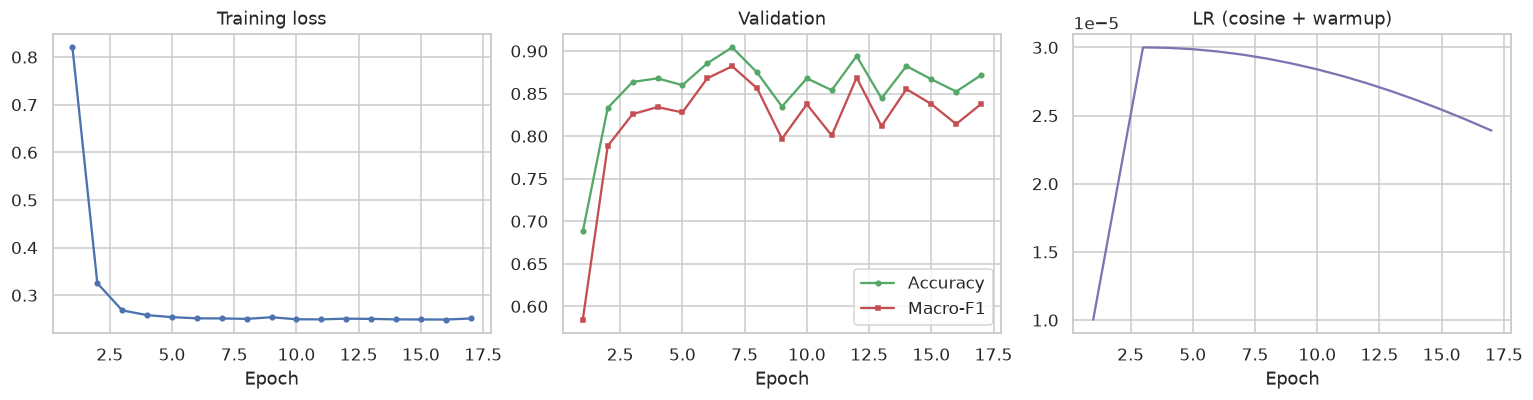

In [26]:
# Phase 7 — Train the primary model (RenalDualNet)

# *** v12 FIX 2: RESUME GUARD ***
# The v11 run trained this model for 136 minutes and then lost it to a cuDNN crash in
# Phase 11. Nothing downstream needs the training loop, only the trained weights, so
# re-running the notebook now reloads the checkpoint instead of paying that cost again.
# Delete the checkpoint (or set FORCE_RETRAIN) when you genuinely want a fresh run.

FORCE_RETRAIN = False
_ck  = OUT/"checkpoints"/"RenalDualNet_s42.pt"
_log = OUT/"logs"/"history_RenalDualNet_s42.csv"
# v12.8: fingerprint of the image bytes. SPLIT_FP only encodes the split labels, so a checkpoint
# trained on the Kaggle copy would pass the split check on figshare files with the same names even
# if the bytes differed. A checkpoint without data_fp is accepted only when Phase 2.2a proved the
# two releases byte-identical.
DATA_FP = hashlib.sha1("".join(manifest["md5"]).encode()).hexdigest()[:12]
SPLIT_META = {"split_method": CFG.SPLIT_METHOD, "split_fp": SPLIT_FP, "data_fp": DATA_FP}   # v12.7 + v12.8

# v12.7: a checkpoint is only valid for the split it was trained on. Loading one trained on a
# different split would silently put its training images into this run's test set.
_resume = _ck.exists() and _log.exists() and not FORCE_RETRAIN and not CFG.QUICK_RUN
if _resume:
    _state = torch.load(_ck, map_location="cpu")
    _fp = _state.get("split_fp")
    _same = (_fp == SPLIT_FP) if _fp is not None else (CFG.SPLIT_METHOD == "greedy_largest_first")
    _dfp = _state.get("data_fp")
    _same_data = (_dfp == DATA_FP) if _dfp is not None else bool(globals().get("DATA_IDENTICAL_TO_KAGGLE", False))
    if _same and not _same_data:
        _old = OUT/"checkpoints"/"other_data"; _old.mkdir(exist_ok=True)
        for _f in (_ck, _log):
            shutil.move(str(_f), str(_old/_f.name))
        print(f"Checkpoint was trained on other image data ({_dfp or 'no data fingerprint'}; this run "
              f"{DATA_FP}). Moved it to {_old} and training afresh.")
        _resume = False
    elif not _same:
        _old = OUT/"checkpoints"/"legacy_split"; _old.mkdir(exist_ok=True)
        for _f in (_ck, _log):
            shutil.move(str(_f), str(_old/_f.name))
        print(f"Checkpoint was trained on another split ({_fp or 'pre-v12.7, greedy_largest_first'}); this run uses "
              f"{SPLIT_FP} ({CFG.SPLIT_METHOD}).\nMoved it to {_old} and training afresh.")
        _resume = False

if _resume:
    set_seed(CFG.PRIMARY_SEED)
    model = build_model("RenalDualNet")
    model.load_state_dict(_state["state_dict"]); model = model.to(DEVICE)
    hist = pd.read_csv(_log); best_val = float(_state["best_f1"])
    print(f"RESUMED from {_ck.name}")
    print(f"  best val macro-F1 {best_val:.4f} @ epoch {_state['best_epoch']}")
    print(f"  history: {len(hist)} epochs")
    print("  Set FORCE_RETRAIN=True to train from scratch instead.")
else:
    set_seed(CFG.PRIMARY_SEED)
    model = build_model("RenalDualNet")
    t0=time.time()
    model,hist,best_val = train_model(model,train_loader,val_loader,"RenalDualNet_s42",
                                      class_weights=CLASS_WEIGHTS, seed=CFG.PRIMARY_SEED, meta=SPLIT_META)
    print(f"\nTraining time {(time.time()-t0)/60:.1f} min")

fig,axes=plt.subplots(1,3,figsize=(14,3.8))
axes[0].plot(hist.epoch,hist.train_loss,marker="o",ms=3,color="#4C72B0"); axes[0].set_title("Training loss")
axes[1].plot(hist.epoch,hist.accuracy,marker="o",ms=3,label="Accuracy",color="#55A868")
axes[1].plot(hist.epoch,hist.f1_macro,marker="s",ms=3,label="Macro-F1",color="#C44E52")
axes[1].set_title("Validation"); axes[1].legend()
axes[2].plot(hist.epoch,hist.lr,color="#8172B2"); axes[2].set_title("LR (cosine + warmup)")
for a in axes: a.set_xlabel("Epoch")
plt.tight_layout(); plt.savefig(OUT/"figures"/"fig6_learning_curves.png"); plt.show()

if hist.f1_macro.max()>0.995:
    print("\n"+"!"*70)
    print("Validation macro-F1 above 0.995 on a leakage-free split is not plausible here.")
    print("Re-check the Phase 3 gate and confirm the image count is 12,446 before writing.")
    print("!"*70)

RenalDualNet — test set
  accuracy             0.9711
  precision_macro      0.9685
  recall_macro         0.9565
  f1_macro             0.9622
  f1_weighted          0.9708
  specificity_macro    0.9896
  mcc                  0.9585
  kappa                0.9583
  auc_ovr_macro        0.9974
  pr_auc_macro         0.9931


,class,support,precision,recall,specificity,f1
0,Cyst,556,0.9746,0.9658,0.9893,0.9702
1,Normal,767,0.9746,1.0000,0.9818,0.9871
2,Stone,205,0.9637,0.9073,0.9958,0.9347
3,Tumor,338,0.9612,0.9527,0.9915,0.9569


              precision    recall  f1-score   support

        Cyst     0.9746    0.9658    0.9702       556
      Normal     0.9746    1.0000    0.9871       767
       Stone     0.9637    0.9073    0.9347       205
       Tumor     0.9612    0.9527    0.9569       338

    accuracy                         0.9711      1866
   macro avg     0.9685    0.9565    0.9622      1866
weighted avg     0.9710    0.9711    0.9708      1866



Group bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

,point,ci_low,ci_high,reported
accuracy,0.9711,0.9483,0.9887,"0.9711 [0.9483, 0.9887]"
f1_macro,0.9622,0.9182,0.9826,"0.9622 [0.9182, 0.9826]"
precision_macro,0.9685,0.9114,0.9890,"0.9685 [0.9114, 0.9890]"
recall_macro,0.9565,0.9194,0.9815,"0.9565 [0.9194, 0.9815]"
specificity_macro,0.9896,0.9811,0.9960,"0.9896 [0.9811, 0.9960]"
mcc,0.9585,0.9243,0.9831,"0.9585 [0.9243, 0.9831]"
kappa,0.9583,0.9239,0.9830,"0.9583 [0.9239, 0.9830]"
auc_ovr_macro,0.9974,0.9920,0.9998,"0.9974 [0.9920, 0.9998]"
pr_auc_macro,0.9931,0.9739,0.9994,"0.9931 [0.9739, 0.9994]"



CI width (macro-F1): 0.0644 from 31 test groups.


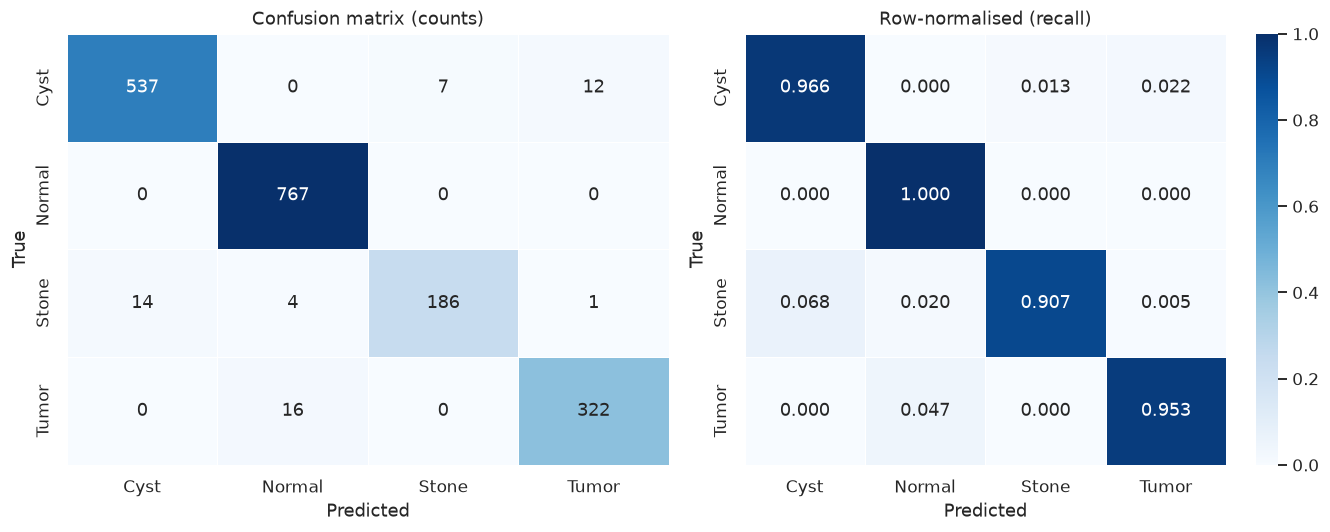

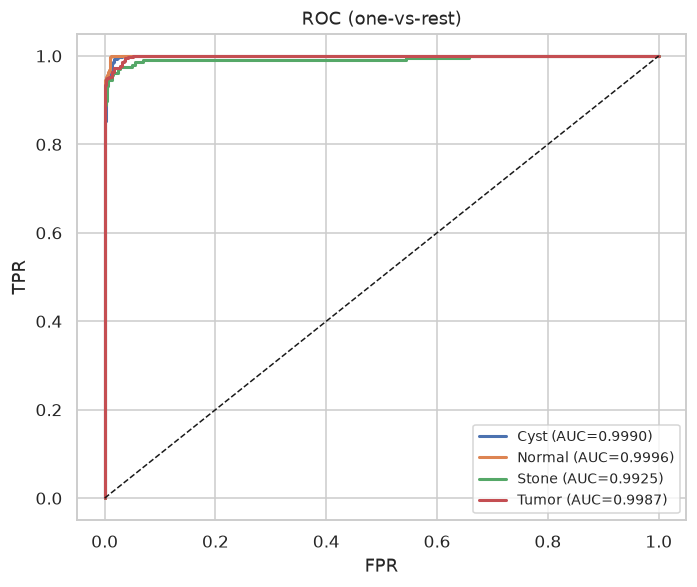


OVERFITTING CHECK
  train accuracy @ best-val epoch : 0.9997
  test accuracy                   : 0.9711
  gap                             : +0.0286
  -> TRAINING SET FULLY MEMORISED (train accuracy 1.000).
     The gap is not a mild train/test difference - it is the distance from
     complete memorisation. Write it that way:
     "training accuracy reached 1.000; test accuracy 0.971; the +0.029 gap is measured against complete
      memorisation of the training split."
     Memorisation reached by epoch 6 of 17.

AUC (macro OvR): 0.9974 [0.9920, 0.9998]
This is the one metric where the dual-branch model may beat Swin-T. If the
intervals separate, it is your only defensible architectural observation.
Worst confusions:
  Tumor -> Normal: 16
  Stone -> Cyst: 14
  Cyst -> Tumor: 12


In [27]:
# Phase 8 — Test evaluation

test_logits,test_y,test_g = predict(model,test_loader)
test_prob = softmax_np(test_logits); test_pred = test_logits.argmax(1)
main_metrics = compute_metrics(test_y,test_pred,test_prob)

print(f"RenalDualNet — test set\n{'='*46}")
for k,v in main_metrics.items(): print(f"  {k:20s} {v:.4f}")
print("="*46)
pc = per_class_table(test_y,test_pred); display(pc.round(4))
pc.to_csv(OUT/"tables"/"per_class_metrics.csv",index=False)
print(classification_report(test_y,test_pred,target_names=list(CFG.CLASSES),digits=4))

ci = group_bootstrap_ci(test_y,test_pred,test_g,seed=CFG.PRIMARY_SEED,y_prob=test_prob)
ci_df=pd.DataFrame(ci).T; ci_df["point"]=[main_metrics[k] for k in ci_df.index]
ci_df["reported"]=ci_df.apply(lambda r:f"{r['point']:.4f} [{r['ci_low']:.4f}, {r['ci_high']:.4f}]",axis=1)
display(ci_df[["point","ci_low","ci_high","reported"]].round(4))
ci_df.to_csv(OUT/"tables"/"bootstrap_ci.csv")
print(f"\nCI width (macro-F1): {ci['f1_macro']['ci_high']-ci['f1_macro']['ci_low']:.4f} "
      f"from {len(np.unique(test_g))} test groups.")

cm=confusion_matrix(test_y,test_pred)
fig,axes=plt.subplots(1,2,figsize=(12.5,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",cbar=False,xticklabels=CFG.CLASSES,
            yticklabels=CFG.CLASSES,ax=axes[0],linewidths=0.5,linecolor="white")
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm/cm.sum(1,keepdims=True),annot=True,fmt=".3f",cmap="Blues",vmin=0,vmax=1,
            xticklabels=CFG.CLASSES,yticklabels=CFG.CLASSES,ax=axes[1],linewidths=0.5,linecolor="white")
axes[1].set_title("Row-normalised (recall)")
for a in axes: a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); plt.savefig(OUT/"figures"/"fig7_confusion_matrix.png"); plt.show()

plt.figure(figsize=(6.5,5.5))
for c in range(NUM_CLASSES):
    fpr,tpr,_=roc_curve((test_y==c).astype(int),test_prob[:,c])
    plt.plot(fpr,tpr,lw=2,label=f"{CFG.CLASSES[c]} (AUC={auc(fpr,tpr):.4f})")
plt.plot([0,1],[0,1],"k--",lw=1); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC (one-vs-rest)"); plt.legend(loc="lower right",fontsize=9)
plt.tight_layout(); plt.savefig(OUT/"figures"/"fig8_roc_curves.png"); plt.show()

# --- v11: train vs test gap, which v10 could not show ---
_final_train_acc=float(hist["train_accuracy"].iloc[-1])
_best_train_acc=float(hist.loc[hist.f1_macro.idxmax(),"train_accuracy"])
_gap=_best_train_acc-main_metrics["accuracy"]
print(f"\nOVERFITTING CHECK")
print(f"  train accuracy @ best-val epoch : {_best_train_acc:.4f}")
print(f"  test accuracy                   : {main_metrics['accuracy']:.4f}")
print(f"  gap                             : {_gap:+.4f}")
# v12: the v11 run gave train accuracy of exactly 1.0000, so calling the gap "modest"
# was the wrong framing. Judge saturation first, then the size of the gap.
if _best_train_acc>=0.999:
    print("  -> TRAINING SET FULLY MEMORISED (train accuracy 1.000).")
    print("     The gap is not a mild train/test difference - it is the distance from")
    print("     complete memorisation. Write it that way:")
    _ta=main_metrics["accuracy"]
    print(f'     "training accuracy reached {_best_train_acc:.3f}; test accuracy '
          f'{_ta:.3f}; the {_gap:+.3f} gap is measured against complete')
    print('      memorisation of the training split."')
    _sat=hist.index[hist.train_accuracy>=0.999]
    if len(_sat):
        print(f"     Memorisation reached by epoch {int(hist.loc[_sat[0],'epoch'])} of {len(hist)}.")
elif _gap>0.15:
    print("  -> Large gap. Report it and justify the regularisation you used.")
elif _gap<0.0:
    print("  -> Test ABOVE train. With only 50 test groups this is split luck, not skill.")
    print("     Say so; do not present it as generalisation.")
else:
    print("  -> Gap is modest. State it in Results; reviewers ask for this number.")

# --- v11: is the AUC advantage real? ---
if "auc_ovr_macro" in ci:
    print(f"\nAUC (macro OvR): {main_metrics['auc_ovr_macro']:.4f} "
          f"[{ci['auc_ovr_macro']['ci_low']:.4f}, {ci['auc_ovr_macro']['ci_high']:.4f}]")
    print("This is the one metric where the dual-branch model may beat Swin-T. If the")
    print("intervals separate, it is your only defensible architectural observation.")

off=cm.copy(); np.fill_diagonal(off,0)
print("Worst confusions:")
for _ in range(3):
    i,j=np.unravel_index(off.argmax(),off.shape)
    if off[i,j]==0: break
    print(f"  {CFG.CLASSES[i]} -> {CFG.CLASSES[j]}: {off[i,j]}"); off[i,j]=0

---
## Phase 9 — Calibration (FIX 9)

v9 fitted temperature by NLL. It produced T = 1.582 and made test ECE **worse**
(0.0978 → 0.1479) because NLL-optimal is not ECE-optimal — it over-softened until the model
became *underconfident*.

v10 fits four calibrators and selects by **validation** ECE. Test values are reported but
never used to choose, otherwise the selection is cheating.

In [28]:
# Phase 9.1 — Fit and select

class TemperatureScaler(nn.Module):
    def __init__(s): super().__init__(); s.log_T=nn.Parameter(torch.zeros(1))
    @property
    def T(s): return torch.exp(s.log_T)
    def forward(s,l): return l/s.T

def fit_temperature(vl,vy,max_iter=200):
    """Returns (T, diagnostics). Detects both degenerate modes:
    vanished gradient (T frozen at 1.0) and runaway sharpening (T -> 0 on a saturated val set)."""
    lg=torch.tensor(vl,dtype=torch.float32); lb=torch.tensor(vy,dtype=torch.long)
    val_acc=float((lg.argmax(1)==lb).float().mean())
    mean_conf=float(torch.softmax(lg,1).max(1).values.mean())
    nll_before=float(F.cross_entropy(lg,lb))
    probe=TemperatureScaler(); F.cross_entropy(probe(lg),lb).backward()
    grad1=float(probe.log_T.grad.abs().item())
    sc=TemperatureScaler(); opt=torch.optim.LBFGS([sc.log_T],lr=0.05,max_iter=max_iter)
    def cl():
        opt.zero_grad(); l=F.cross_entropy(sc(lg),lb); l.backward(); return l
    opt.step(cl)
    T=float(sc.T.detach().item()); nll_after=float(F.cross_entropy(lg/T,lb))
    d={"T":T,"val_accuracy":val_acc,"mean_confidence":mean_conf,"nll_before":nll_before,
       "nll_after":nll_after,"nll_improvement":nll_before-nll_after,"grad_at_T1":grad1}
    pr=[]
    if not np.isfinite(T): pr.append("T is not finite")
    elif not (CFG.TEMP_MIN<=T<=CFG.TEMP_MAX): pr.append(f"T={T:.4f} outside guard rails")
    if val_acc>0.995: pr.append(f"val accuracy {val_acc:.4f}>0.995 — saturated, nothing to calibrate")
    if grad1<1e-7: pr.append(f"NLL gradient at T=1 is {grad1:.2e} — vanished, T cannot move")
    if d["nll_improvement"]<1e-6 and abs(T-1.0)<1e-3: pr.append("optimiser did not move T")
    d["problems"]=pr; d["ok"]=len(pr)==0
    return T,d

class VectorScaler(nn.Module):
    def __init__(s,k): super().__init__(); s.w=nn.Parameter(torch.ones(k)); s.b=nn.Parameter(torch.zeros(k))
    def forward(s,l): return l*s.w+s.b

def fit_vector_scaling(vl,vy,max_iter=400):
    vs=VectorScaler(NUM_CLASSES); lg=torch.tensor(vl,dtype=torch.float32); lb=torch.tensor(vy,dtype=torch.long)
    opt=torch.optim.LBFGS(vs.parameters(),lr=0.02,max_iter=max_iter)
    def cl():
        opt.zero_grad(); l=F.cross_entropy(vs(lg),lb); l.backward(); return l
    opt.step(cl); return vs.eval()

# *** v12.7 FIX: select the calibrator on data it was NOT fitted on ***
# v12.4-v12.6 picked the calibrator with the lowest ECE on the FIT half, i.e. on the very
# images each calibrator had just been fitted to. A grid search that includes the current
# ECE minimiser (Temp ECE) and an 8-parameter map (vector scaling) wins that contest by
# construction. The selection signal is now an inner cross-fit WITHIN the fit half: split its
# groups in two, fit on one part, score on the other, both directions, repeated. The CAL half
# is not touched until Phase 10, so q_hat and the abstention threshold stay independent.
def fit_calibrators(lg, y, kinds=("none","nll","ece","vs")):
    """Fit each calibrator kind on (lg, y) only. Returns {kind: logits -> probabilities}."""
    fns={}
    if "none" in kinds: fns["none"]=lambda l: softmax_np(l,1.0)
    if "nll" in kinds:
        T,d=fit_temperature(lg,y); T=T if d["ok"] else 1.0     # same fallback as Phase 18.1
        fns["nll"]=lambda l,T=T: softmax_np(l,T)
    if "ece" in kinds:
        g_=np.concatenate([np.linspace(0.20,1.0,41),np.linspace(1.05,5.0,80)])
        T=float(g_[int(np.argmin([ece_equal_mass(softmax_np(lg,t),y)[0] for t in g_]))])
        fns["ece"]=lambda l,T=T: softmax_np(l,T)
    if "vs" in kinds:
        vs=fit_vector_scaling(lg,y)
        def _vs(l,vs=vs):
            with torch.no_grad(): return softmax_np(vs(torch.tensor(l,dtype=torch.float32)).numpy(),1.0)
        fns["vs"]=_vs
    return fns

def crossfit_ece(lg, y, g, kinds, reps=10, seed=CFG.PRIMARY_SEED):
    """Mean adaptive ECE per calibrator kind, each fitted on half the groups and scored on the
    other half (both directions, `reps` random partitions). Never scores on fitting data."""
    ug=np.unique(g); rng=np.random.RandomState(seed)
    tot={k:0.0 for k in kinds}; n_tot=0
    for _ in range(reps):
        A=np.isin(g,rng.permutation(ug)[:len(ug)//2])
        for fit,test in ((A,~A),(~A,A)):
            if fit.sum()==0 or test.sum()==0: continue
            fns=fit_calibrators(lg[fit],y[fit],kinds)
            for k in kinds: tot[k]+=ece_equal_mass(fns[k](lg[test]),y[test])[0]*test.sum()
            n_tot+=int(test.sum())
    return {k:tot[k]/n_tot for k in kinds}

val_logits,val_y,val_g = predict(model,val_loader)

# *** v12.4 FIX: fit and calibrate on DIFFERENT validation groups ***
# v12.3 fitted the calibrators AND (Phase 10) set q_hat / the abstention threshold on the
# same validation images, which breaks the exchangeability split conformal relies on.
# Now: calibrators are fitted and selected on the FIT half; Phase 10 uses only the CAL
# half. Same halving (same seed, same sorted group list) as Phase 18.1 for the student.
def split_val_groups(groups, seed=CFG.PRIMARY_SEED):
    ug=np.unique(groups)
    fit_g=np.random.RandomState(seed).permutation(ug)[:len(ug)//2]
    fit=np.isin(groups,fit_g)
    return fit,~fit

VAL_FIT,VAL_CAL = split_val_groups(val_g)
print(f"Validation halves: fit {VAL_FIT.sum()} images ({len(np.unique(val_g[VAL_FIT]))} groups) | "
      f"calibrate {VAL_CAL.sum()} images ({len(np.unique(val_g[VAL_CAL]))} groups)")

T_nll,cal_diag = fit_temperature(val_logits[VAL_FIT],val_y[VAL_FIT])
grid=np.concatenate([np.linspace(0.20,1.0,41),np.linspace(1.05,5.0,80)])
T_ece=float(grid[int(np.argmin([ece_equal_mass(softmax_np(val_logits[VAL_FIT],t),val_y[VAL_FIT])[0]
                                for t in grid]))])
vs_model=fit_vector_scaling(val_logits[VAL_FIT],val_y[VAL_FIT])
with torch.no_grad():
    vs_val=vs_model(torch.tensor(val_logits,dtype=torch.float32)).numpy()
    vs_test=vs_model(torch.tensor(test_logits,dtype=torch.float32)).numpy()

print(f"Temperature diagnostics: T_nll={T_nll:.4f} T_ece={T_ece:.4f} "
      f"val_acc={cal_diag['val_accuracy']:.4f} grad@T1={cal_diag['grad_at_T1']:.2e} ok={cal_diag['ok']}")
for p in cal_diag["problems"]: print(f"  ! {p}")

CALIBRATORS={
    "None (T=1)":             (softmax_np(val_logits,1.0),   softmax_np(test_logits,1.0)),
    f"Temp NLL (T={T_nll:.3f})": (softmax_np(val_logits,T_nll), softmax_np(test_logits,T_nll)),
    f"Temp ECE (T={T_ece:.3f})": (softmax_np(val_logits,T_ece), softmax_np(test_logits,T_ece)),
    "Vector scaling":         (softmax_np(vs_val,1.0),       softmax_np(vs_test,1.0)),
}
rows=[]
for name,(pv,pt) in CALIBRATORS.items():
    rows.append({"calibrator":name,
        "val_fit_ECE_mass":ece_equal_mass(pv[VAL_FIT],val_y[VAL_FIT])[0],
        "val_cal_ECE_mass":ece_equal_mass(pv[VAL_CAL],val_y[VAL_CAL])[0],
        "test_ECE_mass":ece_equal_mass(pt,test_y)[0],
        "test_ECE_width":ece_equal_width(pt,test_y)[0], "test_MCE":max_calibration_error(pt,test_y),
        "test_Brier":brier_multiclass(pt,test_y), "test_meanconf":pt.max(1).mean(),
        "test_acc":accuracy_score(test_y,pt.argmax(1))})
cal_cmp=pd.DataFrame(rows).set_index("calibrator")
_KIND = dict(zip(CALIBRATORS, ["none","nll","ece","vs"]))
CV_ECE = crossfit_ece(val_logits[VAL_FIT], val_y[VAL_FIT], val_g[VAL_FIT], tuple(_KIND.values()))
cal_cmp["val_fit_crossfit_ECE_mass"] = [CV_ECE[_KIND[n]] for n in cal_cmp.index]
# selected by held-out (cross-fitted) ECE inside the validation FIT half; CAL half untouched
CALIBRATOR_NAME = cal_cmp["val_fit_crossfit_ECE_mass"].idxmin()
val_prob_cal,test_prob_cal = CALIBRATORS[CALIBRATOR_NAME]
T_DEPLOY = T_ece if CALIBRATOR_NAME.startswith("Temp ECE") else (T_nll if CALIBRATOR_NAME.startswith("Temp NLL") else 1.0)

display(cal_cmp.round(4)); cal_cmp.to_csv(OUT/"tables"/"calibration_comparison.csv")
b,a = cal_cmp.loc["None (T=1)","test_ECE_mass"], cal_cmp.loc[CALIBRATOR_NAME,"test_ECE_mass"]
print(f"\nSelected by cross-fitted ECE within the validation fit half: {CALIBRATOR_NAME}")
print("  (val_fit_ECE_mass is in-sample and shown for reference only; val_cal_ECE_mass is the")
print("   independent check - it was not used to choose.)")
if CALIBRATOR_NAME=="Vector scaling":
    print("  Vector scaling has 8 parameters vs 1 for temperature: confirm it also wins on")
    print("  val_cal_ECE_mass before claiming it generalises better.")
if (test_prob_cal.argmax(1)!=test_logits.argmax(1)).any():
    _a0=accuracy_score(test_y,test_logits.argmax(1)); _a1=accuracy_score(test_y,test_prob_cal.argmax(1))
    print(f"  The selected calibrator CHANGES the arg-max: test accuracy {_a0:.4f} -> {_a1:.4f}.")
    print("  Phases 10.x compare against the calibrated accuracy, not the raw one.")
print(f"Test adaptive ECE: {b:.4f} -> {a:.4f} ({a-b:+.4f})")
if a>=b:
    print("\nCalibration did not improve test ECE even with proper selection. With few")
    print("validation groups the calibration set cannot generalise. Report this as a")
    print("limitation — it is a real consequence of scan-level splitting, and stating it")
    print("is worth more than a calibration number that quietly got worse.")

Validation halves: fit 1048 images (18 groups) | calibrate 821 images (18 groups)
Temperature diagnostics: T_nll=1.1088 T_ece=0.9400 val_acc=0.8836 grad@T1=8.50e-02 ok=True


,val_fit_ECE_mass,val_cal_ECE_mass,test_ECE_mass,test_ECE_width,test_MCE,test_Brier,test_meanconf,test_acc,val_fit_crossfit_ECE_mass
calibrator,,,,,,,,,
None (T=1),0.0850,0.0579,0.0499,0.0511,0.0787,0.0463,0.9295,0.9711,0.0918
Temp NLL (T=1.109),0.0893,0.0741,0.0678,0.0723,0.1043,0.0498,0.9064,0.9711,0.1109
Temp ECE (T=0.940),0.0812,0.0486,0.0425,0.0439,0.0675,0.0451,0.9412,0.9711,0.0977
Vector scaling,0.0192,0.0755,0.0284,0.0217,0.1462,0.0911,0.9422,0.9480,0.1634



Selected by cross-fitted ECE within the validation fit half: None (T=1)
  (val_fit_ECE_mass is in-sample and shown for reference only; val_cal_ECE_mass is the
   independent check - it was not used to choose.)
Test adaptive ECE: 0.0499 -> 0.0499 (+0.0000)

Calibration did not improve test ECE even with proper selection. With few
validation groups the calibration set cannot generalise. Report this as a
limitation — it is a real consequence of scan-level splitting, and stating it
is worth more than a calibration number that quietly got worse.


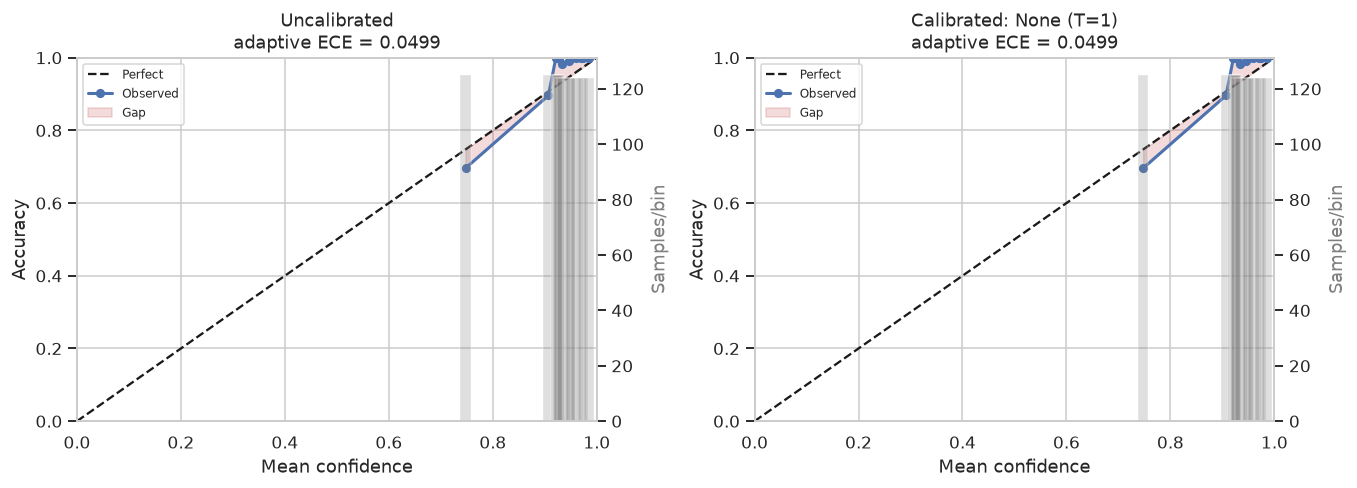

In [29]:
# Phase 9.2 — Reliability diagram

def plot_reliability(probs,labels,title,ax):
    e,st=ece_equal_mass(probs,labels)
    cen=[c for _,_,n,a,c in st]; acc=[a for _,_,n,a,c in st]; cnt=[n for _,_,n,a,c in st]
    ax.plot([0,1],[0,1],"k--",lw=1.5,label="Perfect")
    ax.plot(cen,acc,marker="o",ms=5,lw=2,color="#4C72B0",label="Observed")
    ax.fill_between(cen,acc,cen,alpha=0.20,color="#C44E52",label="Gap")
    ax.set_xlabel("Mean confidence"); ax.set_ylabel("Accuracy")
    ax.set_title(f"{title}\nadaptive ECE = {e:.4f}"); ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.legend(loc="upper left",fontsize=8)
    ax2=ax.twinx(); ax2.bar(cen,cnt,width=0.02,alpha=0.25,color="gray")
    ax2.set_ylabel("Samples/bin",color="gray"); ax2.grid(False)

fig,axes=plt.subplots(1,2,figsize=(12.5,4.6))
plot_reliability(CALIBRATORS["None (T=1)"][1],test_y,"Uncalibrated",axes[0])
plot_reliability(test_prob_cal,test_y,f"Calibrated: {CALIBRATOR_NAME}",axes[1])
plt.tight_layout(); plt.savefig(OUT/"figures"/"fig9_reliability.png"); plt.show()

---
## Phase 10 — Selective prediction (FIX 10)

v9 abstained whenever the conformal set was not a singleton. At α = 0.10 sets averaged 2.91
of 4 classes, so it abstained on 87% of cases — and the remaining singletons were only 65.6%
accurate, **below** the 83.1% full-coverage accuracy. Selective prediction was making things
worse.

v10 deploys a **confidence threshold** chosen on validation to hit a target coverage, and
keeps conformal purely as a coverage-guarantee characterisation with an α sweep.

In [30]:
# Phase 10.1 — Conformal sweep (reported, not deployed)

# *** v12.7 FIX: the calibration unit is the scan, not the image ***
# Images inside a DAP group are near-copies, so the CAL half (~16-18 groups, a few hundred
# images) holds about 17 independent observations, not a few hundred. The image-level quantile
# ceil((n+1)(1-alpha))/n used n = images and so claimed a coverage guarantee it did not have.
# With `groups`, every group carries equal total weight (1/G, spread over its images) and the
# level is ceil((G+1)(1-alpha))/G with G = number of groups. That is split conformal for a
# randomly drawn image of a new scan, under scan-level exchangeability. The price is honesty:
# with G ~ 17 and alpha = 0.10 the level is 16/17 -> q_hat is nearly the largest calibration
# score, so sets are large; that is what 17 independent calibration scans can support.
def conformal_qhat(vp,vy,alpha,groups=None):
    n=len(vy); s=1.0-vp[np.arange(n),vy]
    if groups is None:      # image-level (v12.6 and earlier); treats near-duplicates as independent
        return float(np.quantile(s, min(np.ceil((n+1)*(1-alpha))/n,1.0), method="higher"))
    gi=pd.factorize(np.asarray(groups))[0]; G=int(gi.max())+1
    w=1.0/(np.bincount(gi)[gi]*G)                       # each group sums to 1/G
    o=np.argsort(s,kind="mergesort"); cw=np.cumsum(w[o])
    level=min(np.ceil((G+1)*(1-alpha))/G,1.0)
    k=int(np.searchsorted(cw,level-1e-9))               # first score whose cumulative weight reaches the level
    return float(s[o][min(k,n-1)])

# v11 FIX: v10 produced EMPTY prediction sets at alpha >= 0.20 (avg set size 0.9103).
# An empty set is not a valid conformal output. Standard remedy: always retain the
# arg-max class, so the minimum set size is 1.
rows=[]
for alpha in [0.01,0.05,0.10,0.20,0.30,0.40]:
    q=conformal_qhat(val_prob_cal[VAL_CAL],val_y[VAL_CAL],alpha,groups=val_g[VAL_CAL])   # CAL half only, group-level
    q_img=conformal_qhat(val_prob_cal[VAL_CAL],val_y[VAL_CAL],alpha)                      # old image-level value, for comparison
    sets=test_prob_cal>=(1.0-q)
    _empty=int((sets.sum(1)==0).sum())
    sets[np.arange(len(sets)),test_prob_cal.argmax(1)]=True   # never empty
    sizes=sets.sum(1)
    cov=sets[np.arange(len(test_y)),test_y].mean(); single=sizes==1
    rows.append({"alpha":alpha,"target_cov":1-alpha,"q_hat":q,"q_hat_image_level":q_img,
        "cal_groups":int(len(np.unique(val_g[VAL_CAL]))),"empirical_cov":cov,
        "avg_set_size":sizes.mean(),"singleton_rate":single.mean(),
        "empty_before_fix":_empty,
        # v12.4: sets come from test_prob_cal, so singleton accuracy must use ITS arg-max
        "acc_on_singletons":accuracy_score(test_y[single],test_prob_cal.argmax(1)[single]) if single.sum() else np.nan})
conf_sweep=pd.DataFrame(rows); display(conf_sweep.round(4))
conf_sweep.to_csv(OUT/"tables"/"conformal_alpha_sweep.csv",index=False)
# *** v12 FIX 3: which rows of this table are actually conformal? ***
# The v11 run showed 168 / 261 / 671 empty sets at alpha = 0.20 / 0.30 / 0.40, and after
# the never-empty fix the average set size was exactly 1.0000 with coverage pinned at
# the plain arg-max accuracy. The reason is arithmetic, not a bug: as alpha grows q_hat
# shrinks, so the inclusion threshold 1 - q_hat rises above 0.5 - and two classes can
# never both exceed 0.5. Conformal is forced to return arg-max or nothing.
#
# Rows in that regime are NOT conformal results and must not be presented as such.

conf_sweep["threshold"]=1.0-conf_sweep.q_hat
conf_sweep["regime"]=np.where(conf_sweep.threshold>0.5,"degenerate (= argmax)","valid")
CONFORMAL_VALID=conf_sweep[conf_sweep.regime=="valid"].copy()

print("\nREGIME CLASSIFICATION")
display(conf_sweep[["alpha","q_hat","threshold","avg_set_size","empty_before_fix",
                    "empirical_cov","regime"]].round(4))
CONFORMAL_VALID.to_csv(OUT/"tables"/"conformal_alpha_sweep_valid.csv",index=False)

_deg=conf_sweep[conf_sweep.regime!="valid"]
if len(_deg):
    print(f"\nREPORT ONLY alpha in {sorted(CONFORMAL_VALID.alpha.tolist())}.")
    print(f"Exclude alpha in {sorted(_deg.alpha.tolist())}: the inclusion threshold")
    print("1 - q_hat exceeds 0.5 there, so at most one class can qualify and the")
    print("'conformal' set is just the arg-max prediction. Presenting those rows as")
    print("conformal results would be wrong, and the empty-set counts prove it.")
    print(f"Empty sets before the never-empty fix: "
          f"{dict(zip(_deg.alpha,_deg.empty_before_fix))}")

print(f"\nq_hat is calibrated at SCAN level on {int(conf_sweep.cal_groups.iloc[0])} groups (v12.7): each group")
print("counts once, whatever its size, so near-duplicate images cannot inflate the effective")
print("sample. The guarantee is for a random image of a NEW scan, assuming scans are exchangeable.")
print("Compare q_hat with q_hat_image_level: the gap is how much the old image-level quantile")
print("overstated the calibration sample. Coverage above target is expected and is the price of")
print("having only this many calibration scans; coverage BELOW target would be the real problem.")
print("Large set sizes are the honest price at this accuracy - a statement about task")
print("difficulty under leakage-free evaluation, not a bug.")

,alpha,target_cov,q_hat,q_hat_image_level,cal_groups,empirical_cov,avg_set_size,singleton_rate,empty_before_fix,acc_on_singletons
0,0.01,0.99,0.9949,0.9842,18,1.0000,3.7267,0.0241,0,1.0000
1,0.05,0.95,0.9949,0.8055,18,1.0000,3.7267,0.0241,0,1.0000
2,0.10,0.90,0.9949,0.3336,18,1.0000,3.7267,0.0241,0,1.0000
3,0.20,0.80,0.7941,0.0881,18,0.9845,1.0300,0.9700,0,0.9840
4,0.30,0.70,0.3089,0.0762,18,0.9711,1.0000,1.0000,40,0.9711
5,0.40,0.60,0.0780,0.0747,18,0.9711,1.0000,1.0000,321,0.9711



REGIME CLASSIFICATION


,alpha,q_hat,threshold,avg_set_size,empty_before_fix,empirical_cov,regime
0,0.01,0.9949,0.0051,3.7267,0,1.0000,valid
1,0.05,0.9949,0.0051,3.7267,0,1.0000,valid
2,0.10,0.9949,0.0051,3.7267,0,1.0000,valid
3,0.20,0.7941,0.2059,1.0300,0,0.9845,valid
4,0.30,0.3089,0.6911,1.0000,40,0.9711,degenerate (= argmax)
5,0.40,0.0780,0.9220,1.0000,321,0.9711,degenerate (= argmax)



REPORT ONLY alpha in [0.01, 0.05, 0.1, 0.2].
Exclude alpha in [0.3, 0.4]: the inclusion threshold
1 - q_hat exceeds 0.5 there, so at most one class can qualify and the
'conformal' set is just the arg-max prediction. Presenting those rows as
conformal results would be wrong, and the empty-set counts prove it.
Empty sets before the never-empty fix: {0.3: 40, 0.4: 321}

q_hat is calibrated at SCAN level on 18 groups (v12.7): each group
counts once, whatever its size, so near-duplicate images cannot inflate the effective
sample. The guarantee is for a random image of a NEW scan, assuming scans are exchangeable.
Compare q_hat with q_hat_image_level: the gap is how much the old image-level quantile
overstated the calibration sample. Coverage above target is expected and is the price of
having only this many calibration scans; coverage BELOW target would be the real problem.
Large set sizes are the honest price at this accuracy - a statement about task
difficulty under leakage-free evaluatio

Full-coverage accuracy: calibrated 0.9711 (reference) | uncalibrated 0.9711


,target_coverage,threshold,actual_coverage,accuracy_answered,macroF1_answered,referred,min_class_coverage,least_covered_class
0,1.00,-inf,1.0000,0.9711,0.9622,0.0000,1.0000,Cyst
1,0.95,0.6911,0.9786,0.9830,0.9793,0.0214,0.9317,Stone
2,0.90,0.8494,0.9544,0.9882,0.9860,0.0456,0.8780,Stone
3,0.85,0.9019,0.9121,0.9941,0.9928,0.0879,0.8293,Stone
4,0.80,0.9185,0.8660,0.9981,0.9976,0.1340,0.8000,Stone
5,0.70,0.9240,0.7540,0.9979,0.9976,0.2460,0.6076,Normal
6,0.60,0.9258,0.6511,0.9975,0.9976,0.3489,0.3611,Normal
7,0.50,0.9421,0.4770,0.9978,0.9982,0.5230,0.0000,Normal



At target coverage <= 0.60, more than half of class Normal is referred. Macro-F1 on the answered
subset is then not comparable across rows - report per-class coverage with it.

Full coverage accuracy      : 0.9711
Deployed threshold (90% cov) : 0.8494
Deployed point (validation) : 95.4% coverage -> 0.9882 (+0.0171)   <- REPORT THIS
Post-hoc best (test-chosen) : 86.6% coverage -> 0.9981 (+0.0271)   <- label as post-hoc


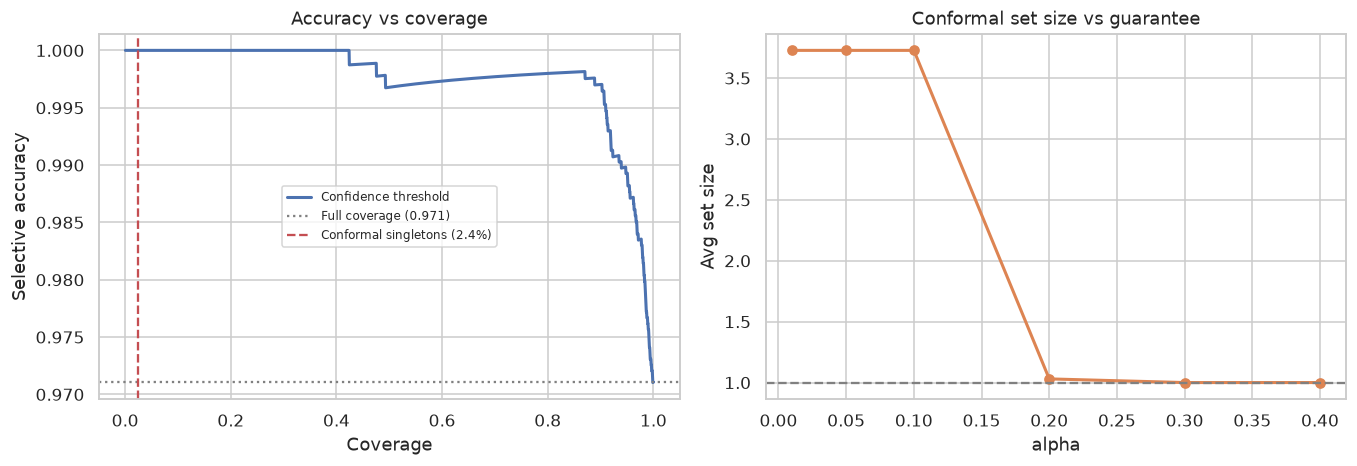

In [31]:
# Phase 10.2 — Confidence-threshold selective prediction (deployed rule)

def threshold_for_coverage(vp,target):
    return float(np.quantile(vp.max(1), 1.0-target))

# *** v12.4 FIX: compare like with like ***
# v12.3 used the UNcalibrated accuracy (main_metrics) as the full-coverage reference while
# every row below uses the calibrated arg-max. Vector scaling changes the arg-max, so the
# reported gain was overstated. The reference is now the calibrated full-coverage accuracy.
_pred_cal=test_prob_cal.argmax(1)
full_acc=float(accuracy_score(test_y,_pred_cal)); rows=[]
print(f"Full-coverage accuracy: calibrated {full_acc:.4f} (reference) | "
      f"uncalibrated {main_metrics['accuracy']:.4f}")
for tgt in [1.00,0.95,0.90,0.85,0.80,0.70,0.60,0.50]:
    thr = -np.inf if tgt>=1.0 else threshold_for_coverage(val_prob_cal[VAL_CAL],tgt)
    ans = test_prob_cal.max(1)>=thr
    if ans.sum()==0: continue
    m=compute_metrics(test_y[ans],_pred_cal[ans])
    # v12.4: macro-F1 collapses at low coverage when a whole class is referred - show it
    cls_cov=[float(ans[test_y==c].mean()) for c in range(NUM_CLASSES)]
    rows.append({"target_coverage":tgt,"threshold":thr,"actual_coverage":ans.mean(),
                 "accuracy_answered":m["accuracy"],"macroF1_answered":m["f1_macro"],
                 "referred":1-ans.mean(),"min_class_coverage":min(cls_cov),
                 "least_covered_class":CFG.CLASSES[int(np.argmin(cls_cov))]})
sel=pd.DataFrame(rows); display(sel.round(4))
sel.to_csv(OUT/"tables"/"selective_prediction.csv",index=False)
_starved=sel[sel.min_class_coverage<0.5]
if len(_starved):
    print("\nAt target coverage <= "
          f"{_starved.target_coverage.max():.2f}, more than half of class "
          f"{_starved.iloc[0]['least_covered_class']} is referred. Macro-F1 on the answered")
    print("subset is then not comparable across rows - report per-class coverage with it.")

SEL_THRESHOLD = threshold_for_coverage(val_prob_cal[VAL_CAL], CFG.TARGET_COVERAGE)
# v11: this "best" row is chosen by looking at TEST accuracy. That is post-hoc and must
# be labelled as such. The DEPLOYED threshold above comes from validation and is the only
# operating point you may present as a chosen method.
part=sel[sel.target_coverage<1.0]; best=part.loc[part["accuracy_answered"].idxmax()]
print(f"\nFull coverage accuracy      : {full_acc:.4f}")
print(f"Deployed threshold ({CFG.TARGET_COVERAGE:.0%} cov) : {SEL_THRESHOLD:.4f}")
_dep=sel.iloc[(sel.target_coverage-CFG.TARGET_COVERAGE).abs().argmin()]
print(f"Deployed point (validation) : {_dep['actual_coverage']:.1%} coverage -> "
      f"{_dep['accuracy_answered']:.4f} ({_dep['accuracy_answered']-full_acc:+.4f})   <- REPORT THIS")
print(f"Post-hoc best (test-chosen) : {best['actual_coverage']:.1%} coverage -> "
      f"{best['accuracy_answered']:.4f} ({best['accuracy_answered']-full_acc:+.4f})   <- label as post-hoc")
if best["accuracy_answered"]<=full_acc:
    print("\nSelective prediction does NOT improve accuracy on the answered subset.")
    print("Confidence does not rank correctness here. Report as a negative result and drop")
    print("the abstention claim rather than presenting it as a clinical feature.")

conf_t=test_prob_cal.max(1); o=np.argsort(-conf_t)
corr=(test_y[o]==test_prob_cal.argmax(1)[o]).astype(float)
cov=np.arange(1,len(corr)+1)/len(corr); sacc=np.cumsum(corr)/np.arange(1,len(corr)+1)
q10=conformal_qhat(val_prob_cal[VAL_CAL],val_y[VAL_CAL],CFG.CONFORMAL_ALPHA,groups=val_g[VAL_CAL])
single_rate=((test_prob_cal>=(1.0-q10)).sum(1)==1).mean()
fig,axes=plt.subplots(1,2,figsize=(12.5,4.4))
axes[0].plot(cov,sacc,lw=2,color="#4C72B0",label="Confidence threshold")
axes[0].axhline(full_acc,ls=":",c="gray",label=f"Full coverage ({full_acc:.3f})")
axes[0].axvline(single_rate,ls="--",c="#C44E52",label=f"Conformal singletons ({single_rate:.1%})")
axes[0].set_xlabel("Coverage"); axes[0].set_ylabel("Selective accuracy")
axes[0].set_title("Accuracy vs coverage"); axes[0].legend(fontsize=8)
axes[1].plot(conf_sweep.alpha,conf_sweep.avg_set_size,marker="o",lw=2,color="#DD8452")
axes[1].axhline(1.0,ls="--",c="gray"); axes[1].set_xlabel("alpha"); axes[1].set_ylabel("Avg set size")
axes[1].set_title("Conformal set size vs guarantee")
plt.tight_layout(); plt.savefig(OUT/"figures"/"fig10_risk_coverage.png"); plt.show()

---
## Phase 11 — Baseline leaderboard

Identical protocol for every model: same split, same augmentation, same optimizer, same
schedule, same epochs, same early stopping, same class weights, same seed.

**FIX 2:** every model now gets `CFG.BOOTSTRAP_N` resamples. In v9 the main model used 1000
and baselines used 300, so the intervals were not comparable.

In [32]:
# Phase 10.9 - free the GPU before the baseline loop
#
# HISTORY OF THIS CELL - read before changing it.
#
# v11 crashed here with CUDNN_STATUS_EXECUTION_FAILED_CUDART. The cause was the 56 M
# primary model still sitting on the GPU after 136 min of training, leaving cuDNN
# without a contiguous workspace. Parking the model on CPU fixed that.
#
# v12 also set PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True". THAT WAS A MISTAKE
# and it caused the second crash:
#
#   RuntimeError: NVML_SUCCESS == DriverAPI::get()->nvmlInit_v2_()
#   INTERNAL ASSERT FAILED at c10/cuda/CUDACachingAllocator.cpp:1135
#
# Expandable segments use CUDA's virtual-memory API, and that path queries NVML. On this
# machine nvmlInit_v2 fails, so the allocator asserts. Two aggravating details:
#   * Setting the variable AFTER torch has initialised CUDA is unsupported - the
#     allocator reads it once, at first CUDA use.
#   * ResNet50 and EfficientNet-B0 passed because they fit inside already-reserved
#     segments. DenseNet201 is far more memory-hungry (dense concatenation), so it was
#     the first model to request a new segment and hit the broken path.
# The assert also poisons the CUDA context, which is why the retry died immediately at
# x.to(DEVICE) rather than producing a second useful traceback.
#
# So: NO expandable_segments. The cleanup below is what actually fixed v11.

import gc

_before = torch.cuda.memory_reserved()/1e9 if DEVICE.type=="cuda" else 0.0
model = model.cpu()
gc.collect()
if DEVICE.type=="cuda":
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    print(f"GPU reserved : {_before:.2f} GB -> {torch.cuda.memory_reserved()/1e9:.2f} GB")
    print(f"GPU allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")
print("Primary model parked on CPU. Phase 16 (Grad-CAM) moves it back.")

if os.environ.get("PYTORCH_CUDA_ALLOC_CONF"):
    print(f"\nWARNING: PYTORCH_CUDA_ALLOC_CONF is set to "
          f"{os.environ['PYTORCH_CUDA_ALLOC_CONF']!r}.")
    print("If it contains expandable_segments, unset it and RESTART THE KERNEL - it")
    print("cannot be changed after CUDA is initialised, and it is what broke the v12 run.")

# --- is NVML actually healthy on this machine? ---
NVML_OK=True
try:
    _free,_tot = torch.cuda.mem_get_info()
    print(f"\nNVML probe OK: {_free/1e9:.2f} GB free of {_tot/1e9:.2f} GB")
except Exception as _e:
    NVML_OK=False
    print(f"\nNVML probe FAILED: {type(_e).__name__}: {str(_e)[:120]}")
    print("The driver management library is unhealthy. Memory-hungry models may crash")
    print("the CUDA context. Phase 11.1 is resumable, so a crash costs one model, not")
    print("the run - but consider `sudo nvidia-smi -r` or a reboot between sessions.")

# --- which failures are worth retrying, and which are terminal? ---
FATAL_MARKERS = ("INTERNAL ASSERT", "NVML", "nvmlInit", "device-side assert",
                 "CUDA error: unspecified launch failure",
                 "an illegal memory access")
RETRY_MARKERS = ("cuDNN", "CUBLAS", "out of memory", "CUDA out of memory")

def classify_cuda_error(e):
    m=str(e)
    if any(k in m for k in FATAL_MARKERS): return "fatal"
    if any(k in m for k in RETRY_MARKERS): return "retry"
    return "unknown"

def cuda_safe_train(build_fn, oom_fn=None):
    """Run build_fn. On a recoverable CUDA failure, clear memory and retry.

    v12.1: a poisoned CUDA context (INTERNAL ASSERT / NVML) is NOT retried. Retrying
    there produced a confusing second traceback and wasted time - once the context is
    dead, only a kernel restart brings it back.

    oom_fn, if given, is a second attempt with lower memory (e.g. a smaller batch).
    A model trained that way is footnoted, not silently mixed in with the others."""
    try:
        return build_fn(), None
    except RuntimeError as e:
        kind = classify_cuda_error(e)
        if kind == "fatal":
            print(f"\n{'!'*74}")
            print(f"FATAL CUDA ERROR - the context is dead, not retrying.")
            print(f"  {str(e)[:160]}")
            print("Progress so far has been saved. Restart the kernel and re-run;")
            print("Phase 11.1 will skip every baseline that already finished.")
            print("!"*74)
            raise
        if kind == "unknown":
            raise
        print(f"  {type(e).__name__}: {str(e)[:90]}")
        gc.collect()
        if DEVICE.type=="cuda": torch.cuda.empty_cache()
        if "out of memory" in str(e).lower() and oom_fn is not None:
            print("  out of memory -> retrying with a smaller batch ...")
            out=oom_fn(); print("  recovered (reduced batch)")
            return out,"reduced_batch"
        print("  retrying with cudnn.deterministic=False ...")
        _d=torch.backends.cudnn.deterministic
        torch.backends.cudnn.deterministic=False; torch.backends.cudnn.benchmark=True
        try:
            out=build_fn(); print("  recovered (non-deterministic)")
            return out,"nondeterministic"
        finally:
            torch.backends.cudnn.deterministic=_d
            torch.backends.cudnn.benchmark=not _d

NONDETERMINISTIC_MODELS=[]; REDUCED_BATCH_MODELS=[]

# DenseNet201 concatenates every previous feature map in a block, so its activation
# memory dwarfs the other baselines. Give it a smaller batch from the start rather than
# waiting for it to fall over.
MEMORY_HEAVY = {"densenet201": 16}
print(f"\nReduced batch for memory-heavy models: {MEMORY_HEAVY}")


# =====================================================================================
# v12.2 - CRASH INSURANCE
# =====================================================================================
# The NVML assert recurred in Phase 21 AFTER twelve baseline x seed runs had completed
# and printed. Those twelve results existed only in `ms_rows` in memory, and a dead CUDA
# context means a kernel restart, so all twelve were lost - hours of GPU time.
#
# Removing expandable_segments was necessary but not sufficient: this machine's NVML
# fails intermittently under sustained load. Treat a crash as EXPECTED and make every
# expensive phase resumable at the level of a single training run.

class ResultCache:
    """Tiny JSON-backed store, written after every individual run.

    Keys are strings identifying one unit of work ("densenet201|seed1337",
    "d4p7"). A crash then costs at most the run in flight."""
    def __init__(s, path, context=None):
        # v12.7: `context` fingerprints everything a cached run depends on (data, grouping,
        # split method, training hyper-parameters; see run_context). A cache written under a
        # different context is moved aside, never reused: its numbers belong to another
        # experiment. Before this, "seed1337" or "d4p7" resumed whatever was on disk.
        s.path = Path(path); s.d = {}; s.ctx = context
        if s.path.exists():
            try: raw = json.loads(s.path.read_text())
            except Exception as e: print(f"  cache unreadable ({e}), starting fresh"); raw = {}
            old = raw.pop("__context__", None)
            if context is None or old == context:
                s.d = raw
            elif old is None and CFG.SPLIT_METHOD == "greedy_largest_first":
                s.d = raw
                print(f"  WARNING {s.path.name}: written before v12.7, so its settings cannot be verified. "
                      "Accepted because the legacy splitter is selected; delete it if hyper-parameters changed.")
            elif raw:
                moved = s.path.with_name(f"{s.path.stem}.stale-{(old or 'unstamped')[:8]}.json")
                s.path.replace(moved)
                print(f"  {s.path.name}: written under a different context ({(old or 'none')[:8]} vs "
                      f"{context[:8]}) - moved to {moved.name}, starting fresh")
    def __contains__(s, k): return k in s.d
    def __len__(s): return len(s.d)
    def get(s, k): return s.d[k]
    def keys(s): return sorted(s.d)
    def put(s, k, v):
        s.d[k] = {kk: (float(vv) if isinstance(vv,(int,float,np.floating)) else vv)
                  for kk, vv in v.items()}
        s.path.parent.mkdir(parents=True, exist_ok=True)
        s.path.write_text(json.dumps(({"__context__": s.ctx} if s.ctx else {}) | s.d, indent=1))   # flush immediately
        return s.d[k]
    def report(s, label):
        if len(s): print(f"  [{label}] resumed {len(s)} cached run(s): {s.keys()}")
        else:      print(f"  [{label}] no cache yet - starting from scratch")

_CTX_KEYS = ("PRIMARY_SEED", "IMG_SIZE", "SPLIT_RATIO", "SPLIT_METHOD", "LOCAL_BACKBONE", "GLOBAL_BACKBONE",
             "FUSION_DIM", "FUSION_HEADS", "FUSION_DROPOUT", "HEAD_DROPOUT", "EPOCHS", "BATCH_SIZE",
             "LR_BACKBONE", "LR_HEAD", "WEIGHT_DECAY", "WARMUP_EPOCHS", "LABEL_SMOOTHING",
             "EARLY_STOP_PATIENCE", "USE_AMP", "IMBALANCE_STRATEGY", "CLASS_WEIGHT_POWER",
             "BOOTSTRAP_N", "SWEEP_ARCH", "LEAK_FRAC")

def run_context(groups=True, extra=""):
    """Fingerprint of what a cached training run depends on: the images (md5 of every file), the
    training-relevant CFG fields, and - when `groups` - the final grouping. The threshold sweep
    (13.4) builds its own groupings, so it passes groups=False and the hashes in `extra`.
    Seeds are not included: they are part of each cache key."""
    c = {k: getattr(CFG, k) for k in _CTX_KEYS}
    c["data"] = hashlib.sha1("".join(manifest["md5"]).encode()).hexdigest()
    if groups: c["groups"] = hashlib.sha1(manifest["group_id"].values.astype(np.int64).tobytes()).hexdigest()
    return hashlib.sha1((json.dumps(c, sort_keys=True, default=str) + extra).encode()).hexdigest()

# v12.7: cached runs belong to one split. The legacy method keeps the old folder so its
# results still resume; any other method gets its own, so numbers from the old split can
# never be mixed into a run that uses a different one.
CACHE_DIR = OUT/"cache" if CFG.SPLIT_METHOD=="greedy_largest_first" else OUT/"cache"/f"split_{CFG.SPLIT_METHOD}"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print(f"\nRun cache -> {CACHE_DIR}")

# --- GPU health: is the driver actually stable? ---
def gpu_health():
    if DEVICE.type != "cuda": return
    import subprocess
    try:
        q = subprocess.run(["nvidia-smi","--query-gpu=name,persistence_mode,temperature.gpu,"
                            "memory.used,memory.total,ecc.errors.uncorrected.volatile.total",
                            "--format=csv,noheader"], capture_output=True, text=True, timeout=15)
        print("nvidia-smi:", q.stdout.strip() or q.stderr.strip()[:160])
        if "Disabled" in q.stdout:
            print("\n  Persistence mode is OFF. The driver can unload between CUDA clients,")
            print("  which is one documented route to NVML going stale mid-session. Enable it:")
            print("      sudo nvidia-smi -pm 1")
        x = subprocess.run("dmesg 2>/dev/null | grep -i xid | tail -5", shell=True,
                           capture_output=True, text=True, timeout=15).stdout.strip()
        if x:
            print("\n  Xid errors in the kernel log - these are hardware/driver faults, not")
            print("  PyTorch bugs. The crashes will keep happening until they are resolved:")
            for ln in x.splitlines(): print("   ", ln[:140])
    except Exception as e:
        print(f"  gpu_health probe unavailable: {type(e).__name__}")

gpu_health()
print("\ncuda_safe_train + ResultCache ready.")


GPU reserved : 5.78 GB -> 0.05 GB
GPU allocated: 0.02 GB
Primary model parked on CPU. Phase 16 (Grad-CAM) moves it back.

NVML probe OK: 11.43 GB free of 16.74 GB

Reduced batch for memory-heavy models: {'densenet201': 16}

Run cache -> Obj1/cache/split_balanced_random
nvidia-smi: NVIDIA RTX A4000, Disabled, 55, 5066 MiB, 16376 MiB, [N/A]

  Persistence mode is OFF. The driver can unload between CUDA clients,
  which is one documented route to NVML going stale mid-session. Enable it:
      sudo nvidia-smi -pm 1

cuda_safe_train + ResultCache ready.


In [33]:
# Phase 11.1 - Train baselines
#
# v12.1: RESUMABLE. The v12 run finished resnet50 and efficientnet_b0, then lost both
# when densenet201 killed the CUDA context, because `results` lived only in memory.
# Results are now written to disk after every model and reloaded on re-run, so a crash
# costs one model instead of the whole phase.

BASELINE_CACHE = ResultCache(CACHE_DIR/"baselines_seed42.json", run_context())

results={"RenalDualNet":{**main_metrics,"params_M":n_total/1e6,
                         "ci_f1_low":ci["f1_macro"]["ci_low"],"ci_f1_high":ci["f1_macro"]["ci_high"]}}

BASELINE_CACHE.report("baselines")
for _k in BASELINE_CACHE.keys():
    if _k != "RenalDualNet": results[_k] = BASELINE_CACHE.get(_k)

def evaluate_model(m, loader, tag, n_boot=None):
    lg,y,g = predict(m,loader); p=lg.argmax(1); pr=softmax_np(lg)
    met = compute_metrics(y,p,pr)
    c = group_bootstrap_ci(y,p,g,n_boot=n_boot or CFG.BOOTSTRAP_N, seed=CFG.PRIMARY_SEED)
    return met,c,lg,y,g

def _save_baselines():
    for _k,_v in results.items():
        if _k != "RenalDualNet": BASELINE_CACHE.put(_k,_v)

if CFG.RUN_BASELINES:
    _done=[]; _failed=[]
    for bname in CFG.BASELINES:
        short=bname.split(".")[0]
        if short in results:
            print(f"\n{'='*62}\nBASELINE: {short}  (already done - skipping)\n{'='*62}")
            continue
        print(f"\n{'='*62}\nBASELINE: {short}\n{'='*62}")
        set_seed(CFG.PRIMARY_SEED)
        try: bm=build_model(bname)
        except Exception as e:
            print(f"  skipped ({e})"); continue

        # memory-heavy models get their own loaders at a smaller batch
        _bs=MEMORY_HEAVY.get(short)
        if _bs:
            _tl,_vl,_ = make_loaders(train_df,val_df,test_df,batch_size=_bs)
            print(f"  using reduced batch {_bs} (default {CFG.BATCH_SIZE})")
            REDUCED_BATCH_MODELS.append(short)
        else:
            _tl,_vl = train_loader,val_loader

        def _fit(m=bm,tl=_tl,vl=_vl,tag=f"baseline_{short}"):
            return train_model(m,tl,vl,tag,class_weights=CLASS_WEIGHTS,
                               seed=CFG.PRIMARY_SEED,verbose=False)
        def _fit_small(m=bm,tag=f"baseline_{short}"):
            t,v,_=make_loaders(train_df,val_df,test_df,batch_size=8)
            return train_model(m,t,v,tag,class_weights=CLASS_WEIGHTS,
                               seed=CFG.PRIMARY_SEED,verbose=False)

        try:
            (bm,_,_),_flag = cuda_safe_train(_fit, oom_fn=_fit_small)
        except RuntimeError:
            _failed.append(short); _save_baselines()
            print(f"\nSaved {len(results)-1} completed baseline(s) to the cache.")
            _left=[b.split('.')[0] for b in CFG.BASELINES
                   if b.split('.')[0] not in results and b.split('.')[0] not in _failed]
            print(f"Still to train after a kernel restart: {[short]+_left}")
            raise
        if _flag=="nondeterministic": NONDETERMINISTIC_MODELS.append(short)
        if _flag=="reduced_batch" and short not in REDUCED_BATCH_MODELS:
            REDUCED_BATCH_MODELS.append(short)

        bmet,bci,_,_,_ = evaluate_model(bm,test_loader,short)
        results[short]={**bmet,"params_M":sum(p.numel() for p in bm.parameters())/1e6,
                        "ci_f1_low":bci["f1_macro"]["ci_low"],"ci_f1_high":bci["f1_macro"]["ci_high"]}
        _done.append(short); BASELINE_CACHE.put(short, results[short])   # crash insurance
        print(f"  acc {bmet['accuracy']:.4f}  macro-F1 {bmet['f1_macro']:.4f} "
              f"[{bci['f1_macro']['ci_low']:.4f}, {bci['f1_macro']['ci_high']:.4f}]")
        del bm, _tl, _vl; gc.collect(); torch.cuda.empty_cache()

    print(f"\n{'='*62}")
    print(f"Baselines in `results`: {sorted(k for k in results if k!='RenalDualNet')}")
    if NONDETERMINISTIC_MODELS:
        print(f"Footnote - trained with cudnn.deterministic=False after a CUDA failure: "
              f"{NONDETERMINISTIC_MODELS}")
    if REDUCED_BATCH_MODELS:
        print(f"Footnote - trained at a reduced batch size: {REDUCED_BATCH_MODELS}")
        print("  Batch size affects optimisation, so this breaks the identical-protocol")
        print("  claim for those models. State it in the Methods table.")
    print("="*62)
else:
    print("RUN_BASELINES off.")


  [baselines] no cache yet - starting from scratch

BASELINE: resnet50


Group bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

  acc 0.8564  macro-F1 0.8062 [0.6978, 0.8873]

BASELINE: efficientnet_b0


Group bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

  acc 0.9314  macro-F1 0.9134 [0.7743, 0.9654]

BASELINE: densenet201
  using reduced batch 16 (default 32)


...

  acc 0.9191  macro-F1 0.8715 [0.7708, 0.9291]

BASELINE: swin_tiny_patch4_window7_224


Group bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

  acc 0.9764  macro-F1 0.9700 [0.9408, 0.9842]

BASELINE: convnext_tiny


Group bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

  acc 0.9143  macro-F1 0.8958 [0.7303, 0.9566]

Baselines in `results`: ['convnext_tiny', 'densenet201', 'efficientnet_b0', 'resnet50', 'swin_tiny_patch4_window7_224', 'vit_small_patch16_224']
Footnote - trained at a reduced batch size: ['densenet201']
  Batch size affects optimisation, so this breaks the identical-protocol
  claim for those models. State it in the Methods table.


,accuracy,precision_macro,recall_macro,specificity_macro,f1_macro,auc_ovr_macro,pr_auc_macro,mcc,kappa,params_M,macro_F1_95CI
swin_tiny_patch4_window7_224,0.9764,0.9832,0.9586,0.9906,0.9700,0.9932,0.9777,0.9663,0.9659,27.5224,"0.9700 [0.9408, 0.9842]"
RenalDualNet,0.9711,0.9685,0.9565,0.9896,0.9622,0.9974,0.9931,0.9585,0.9583,56.1295,"0.9622 [0.9182, 0.9826]"
efficientnet_b0,0.9314,0.9264,0.9053,0.9752,0.9134,0.9804,0.9545,0.9019,0.9008,4.0127,"0.9134 [0.7743, 0.9654]"
densenet201,0.9250,0.9225,0.8900,0.9724,0.9038,0.9646,0.9213,0.8924,0.8911,18.1006,"0.9038 [0.8237, 0.9395]"
convnext_tiny,0.9143,0.9357,0.8811,0.9668,0.8958,0.9712,0.9363,0.8799,0.8746,27.8232,"0.8958 [0.7303, 0.9566]"
vit_small_patch16_224,0.9191,0.9350,0.8445,0.9703,0.8715,0.9817,0.9410,0.8862,0.8816,21.6672,"0.8715 [0.7708, 0.9291]"
resnet50,0.8564,0.8959,0.7857,0.9429,0.8062,0.9616,0.9086,0.8002,0.7860,23.5162,"0.8062 [0.6978, 0.8873]"


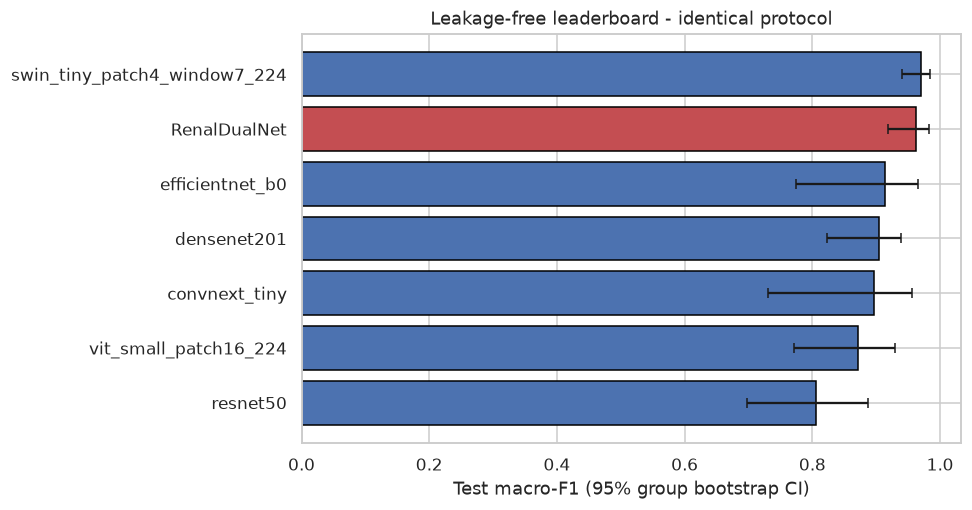


Best model: swin_tiny_patch4_window7_224
CIs overlapping it: 3/6 -> ['RenalDualNet', 'efficientnet_b0', 'convnext_tiny']

STATE THIS IN THE PAPER: differences between these architectures are NOT
statistically distinguishable at this test-set group count. The contribution
is the protocol and the leakage measurement, not a leaderboard win.


In [34]:
# Phase 11.2 - Leaderboard table and overlap analysis
# v11 FIX H: this is now a FUNCTION. v10 built the table before Phase 12 added
# RenalCGAFNet to `results`, so the model appeared in RESULTS.json but in no table
# or figure. Phase 12 calls this again at the end.

LEADER_COLS=["accuracy","precision_macro","recall_macro","specificity_macro","f1_macro",
             "auc_ovr_macro","pr_auc_macro","mcc","kappa","params_M","ci_f1_low","ci_f1_high"]

def build_leaderboard(results_dict, save_as="table2_baseline_comparison.csv",
                      fig_as="fig11_baseline_comparison.png", show=True):
    c=pd.DataFrame(results_dict).T
    c=c[[k for k in LEADER_COLS if k in c.columns]].sort_values("f1_macro",ascending=False)
    c["macro_F1_95CI"]=c.apply(
        lambda r:f"{r['f1_macro']:.4f} [{r['ci_f1_low']:.4f}, {r['ci_f1_high']:.4f}]",axis=1)
    if show:
        display(c.drop(columns=["ci_f1_low","ci_f1_high"]).round(4))
    c.to_csv(OUT/"tables"/save_as)

    fig,ax=plt.subplots(figsize=(9,4.8))
    yerr=np.vstack([c["f1_macro"]-c["ci_f1_low"], c["ci_f1_high"]-c["f1_macro"]])
    colors=["#C44E52" if i in ("RenalDualNet","RenalCGAFNet") else "#4C72B0" for i in c.index]
    ax.barh(c.index,c["f1_macro"],xerr=yerr,color=colors,edgecolor="black",capsize=3)
    ax.set_xlabel("Test macro-F1 (95% group bootstrap CI)"); ax.invert_yaxis()
    ax.set_title("Leakage-free leaderboard - identical protocol")
    plt.tight_layout(); plt.savefig(OUT/"figures"/fig_as)
    if show: plt.show()
    else: plt.close()

    # settle significance before a reviewer raises it
    top=c.index[0]; lo,hi=c.loc[top,"ci_f1_low"],c.loc[top,"ci_f1_high"]
    ov=[m for m in c.index[1:]
        if not (c.loc[m,"ci_f1_high"]<lo or c.loc[m,"ci_f1_low"]>hi)]
    if show:
        print(f"\nBest model: {top}")
        print(f"CIs overlapping it: {len(ov)}/{len(c)-1} -> {ov}")
        if ov:
            print("\nSTATE THIS IN THE PAPER: differences between these architectures are NOT")
            print("statistically distinguishable at this test-set group count. The contribution")
            print("is the protocol and the leakage measurement, not a leaderboard win.")
    return c, ov

comp, overlap = build_leaderboard(results)


Training RenalCGAFNet (attention fusion) for the ablation...


Group bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

Gate values:   0%|          | 0/30 [00:00<?, ?it/s]

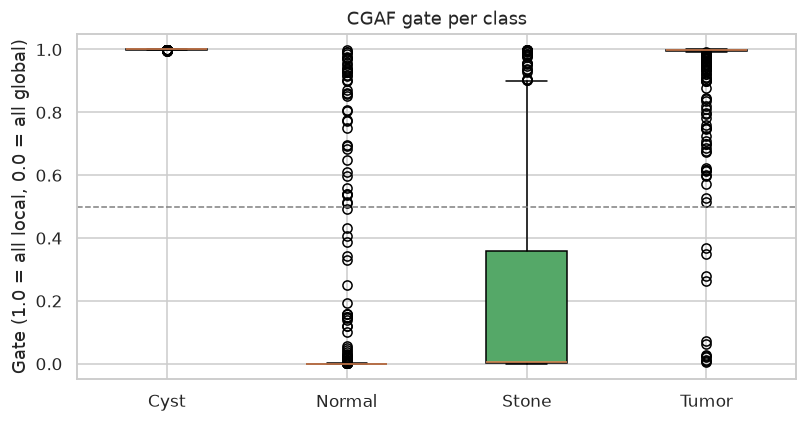

  Cyst     gate 0.9998 +/- 0.0005
  Normal   gate 0.0502 +/- 0.1903
  Stone    gate 0.2234 +/- 0.3650
  Tumor    gate 0.9375 +/- 0.1812

The gate is behaving as a near-binary router, discarding one branch per class.
That is why attention fusion underperforms simple concatenation.


,accuracy,f1_macro,precision_macro,recall_macro,params_M
Local only (ConvNeXt-T),0.9143,0.8958,0.9357,0.8811,27.8232
Global only (Swin-T),0.9764,0.9700,0.9832,0.9586,27.5224
CGAF attention fusion,0.9400,0.9252,0.9403,0.9162,60.4669
Concat fusion (RenalDualNet),0.9711,0.9622,0.9685,0.9565,56.1295



Leaderboard rebuilt to include RenalCGAFNet


,accuracy,precision_macro,recall_macro,specificity_macro,f1_macro,auc_ovr_macro,pr_auc_macro,mcc,kappa,params_M,macro_F1_95CI
swin_tiny_patch4_window7_224,0.9764,0.9832,0.9586,0.9906,0.9700,0.9932,0.9777,0.9663,0.9659,27.5224,"0.9700 [0.9408, 0.9842]"
RenalDualNet,0.9711,0.9685,0.9565,0.9896,0.9622,0.9974,0.9931,0.9585,0.9583,56.1295,"0.9622 [0.9182, 0.9826]"
RenalCGAFNet,0.9400,0.9403,0.9162,0.9794,0.9252,0.9843,0.9714,0.9148,0.9138,60.4669,"0.9252 [0.8173, 0.9582]"
efficientnet_b0,0.9314,0.9264,0.9053,0.9752,0.9134,0.9804,0.9545,0.9019,0.9008,4.0127,"0.9134 [0.7743, 0.9654]"
densenet201,0.9250,0.9225,0.8900,0.9724,0.9038,0.9646,0.9213,0.8924,0.8911,18.1006,"0.9038 [0.8237, 0.9395]"
convnext_tiny,0.9143,0.9357,0.8811,0.9668,0.8958,0.9712,0.9363,0.8799,0.8746,27.8232,"0.8958 [0.7303, 0.9566]"
vit_small_patch16_224,0.9191,0.9350,0.8445,0.9703,0.8715,0.9817,0.9410,0.8862,0.8816,21.6672,"0.8715 [0.7708, 0.9291]"
resnet50,0.8564,0.8959,0.7857,0.9429,0.8062,0.9616,0.9086,0.8002,0.7860,23.5162,"0.8062 [0.6978, 0.8873]"


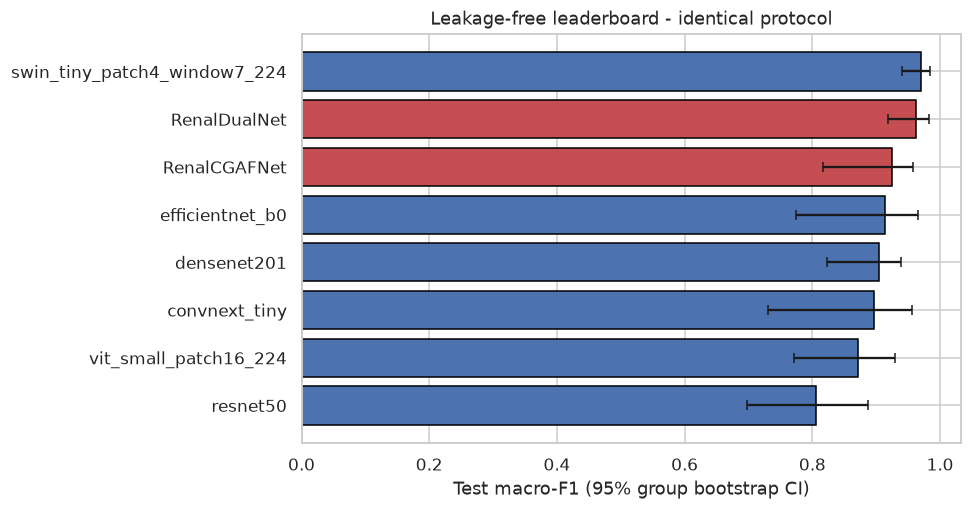


Best model: swin_tiny_patch4_window7_224
CIs overlapping it: 4/7 -> ['RenalDualNet', 'RenalCGAFNet', 'efficientnet_b0', 'convnext_tiny']

STATE THIS IN THE PAPER: differences between these architectures are NOT
statistically distinguishable at this test-set group count. The contribution
is the protocol and the leakage measurement, not a leaderboard win.

Concat gain over best single branch : -0.0078
Concat gain over attention fusion   : +0.0370

v11 reading of this table:
  Concat fusion does NOT beat the best single backbone either. Do not claim
  an architecture contribution. Report both fusion results as negative and
  let the paper stand on the leakage audit.
  Either way the negative result saves other groups the same dead end.


In [35]:
# Phase 12 — Ablation: does attention fusion help?

ablation={}
if CFG.RUN_ABLATION:
    for key,src in [("Local only (ConvNeXt-T)","convnext_tiny"),
                    ("Global only (Swin-T)","swin_tiny_patch4_window7_224")]:
        if src in results:
            ablation[key]={k:results[src][k] for k in
                           ["accuracy","f1_macro","precision_macro","recall_macro","params_M"]}
    print("Training RenalCGAFNet (attention fusion) for the ablation...")
    set_seed(CFG.PRIMARY_SEED)
    cg=build_model("RenalCGAFNet")
    cg,_,_=train_model(cg,train_loader,val_loader,"ablation_CGAF",
                       class_weights=CLASS_WEIGHTS,seed=CFG.PRIMARY_SEED,verbose=False)
    cgm,cgci,cg_logits,cg_y,cg_g = evaluate_model(cg,test_loader,"CGAF")
    ablation["CGAF attention fusion"]={**{k:cgm[k] for k in
        ["accuracy","f1_macro","precision_macro","recall_macro"]},
        "params_M":sum(p.numel() for p in cg.parameters())/1e6}
    results["RenalCGAFNet"]={**cgm,"params_M":sum(p.numel() for p in cg.parameters())/1e6,
        "ci_f1_low":cgci["f1_macro"]["ci_low"],"ci_f1_high":cgci["f1_macro"]["ci_high"]}

    # gate analysis: is the fusion adaptive or a hard switch?
    gates={c:[] for c in range(NUM_CLASSES)}
    cg.eval()
    with torch.no_grad():
        for x,y,_ in tqdm(test_loader,desc="Gate values",leave=False):
            _=cg(x.to(DEVICE)); gv=cg.fusion._last_gate.squeeze(1).cpu().numpy()
            for gi,yi in zip(gv,y.numpy()): gates[int(yi)].append(float(gi))
    fig,ax=plt.subplots(figsize=(7.5,4))
    bp=ax.boxplot([gates[c] for c in range(NUM_CLASSES)],patch_artist=True)
    ax.set_xticks(range(1,NUM_CLASSES+1)); ax.set_xticklabels(list(CFG.CLASSES))
    for patch,col in zip(bp["boxes"],sns.color_palette("deep",NUM_CLASSES)): patch.set_facecolor(col)
    ax.axhline(0.5,ls="--",c="gray",lw=1)
    ax.set_ylabel("Gate (1.0 = all local, 0.0 = all global)"); ax.set_title("CGAF gate per class")
    plt.tight_layout(); plt.savefig(OUT/"figures"/"fig12_gate_analysis.png"); plt.show()
    gate_stats={CFG.CLASSES[c]:{"mean":float(np.mean(gates[c])),"std":float(np.std(gates[c]))}
                for c in range(NUM_CLASSES)}
    for k,v in gate_stats.items(): print(f"  {k:8s} gate {v['mean']:.4f} +/- {v['std']:.4f}")
    gm=np.array([v["mean"] for v in gate_stats.values()])
    if gm.max()-gm.min()>0.5:
        print("\nThe gate is behaving as a near-binary router, discarding one branch per class.")
        print("That is why attention fusion underperforms simple concatenation.")
    del cg; torch.cuda.empty_cache()

ablation["Concat fusion (RenalDualNet)"]={**{k:main_metrics[k] for k in
    ["accuracy","f1_macro","precision_macro","recall_macro"]},"params_M":n_total/1e6}
abl_df=pd.DataFrame(ablation).T.round(4); display(abl_df)
abl_df.to_csv(OUT/"tables"/"table3_ablation.csv")

concat_f1=ablation["Concat fusion (RenalDualNet)"]["f1_macro"]
singles=[v["f1_macro"] for k,v in ablation.items() if "only" in k]
# v11 FIX H: rebuild the leaderboard now that RenalCGAFNet is in `results`
print("\n" + "="*62)
print("Leaderboard rebuilt to include RenalCGAFNet")
print("="*62)
comp, overlap = build_leaderboard(results)

if singles: print(f"\nConcat gain over best single branch : {concat_f1-max(singles):+.4f}")
if "CGAF attention fusion" in ablation:
    print(f"Concat gain over attention fusion   : {concat_f1-ablation['CGAF attention fusion']['f1_macro']:+.4f}")
    print("\nv11 reading of this table:")
    if singles and concat_f1-max(singles) <= 0.01:
        print("  Concat fusion does NOT beat the best single backbone either. Do not claim")
        print("  an architecture contribution. Report both fusion results as negative and")
        print("  let the paper stand on the leakage audit.")
    else:
        print("  Concat fusion helps; attention fusion does not.")
    print("  Either way the negative result saves other groups the same dead end.")

---
## Phase 13 — Multi-architecture leakage replication (NEW, the key experiment)

v9 measured the inflation with one architecture. That supports "this model was affected."
Running it for a second architecture supports "**this benchmark is contaminated**", which is
a far stronger claim and costs one training run.

Everything is held fixed except the split: same architecture, same seed, same
hyperparameters, same image count. Class weights are recomputed from the random split's own
training set (FIX 1) so the protocol really is identical.

**v12.7 - read this before quoting any number from 13.1-13.3.** A random split and a DAP
split have *different test sets*, so "random score minus DAP score" mixes the effect of
leakage with the difference between two sets of test images (the DAP test set is a few dozen
scans; the random one is a sample from all of them). Phases 13.1-13.3 therefore report the
**as-practised gap** only: what a reader sees when comparing papers that used random splits
with a leakage-free benchmark. The **contamination effect** itself is measured in 13.3b-13.5
with the test images held fixed.


In [36]:
# Phase 13.1 — Contamination audit of the random split

leak_results={}
if CFG.RUN_LEAKAGE_EXPERIMENT:
    from sklearn.model_selection import train_test_split
    leak_df=manifest.copy()
    tr_i,tmp_i=train_test_split(leak_df.index.values,test_size=0.30,
                                random_state=CFG.PRIMARY_SEED,stratify=leak_df["label"])
    va_i,te_i=train_test_split(tmp_i,test_size=0.50,random_state=CFG.PRIMARY_SEED,
                               stratify=leak_df.loc[tmp_i,"label"])
    leak_df["split"]="train"; leak_df.loc[va_i,"split"]="val"; leak_df.loc[te_i,"split"]="test"

    lk=assert_no_leakage(leak_df,edges)
    print("Audit of the RANDOM split (standard practice in the literature):")
    print("-"*56)
    for k,v in lk.items(): print(f"  {k:32s} {v:8,d}")
    print("-"*56)

    split_of=dict(zip(leak_df.img_id,leak_df.split))
    test_ids=set(leak_df[leak_df.split=="test"].img_id); contam=set()
    for i,j in edges:
        if i in test_ids and split_of[j]=="train": contam.add(i)
        if j in test_ids and split_of[i]=="train": contam.add(j)
    contam_rate=len(contam)/max(1,len(test_ids))
    print(f"\nTest images with a near-duplicate in train: {len(contam):,}/{len(test_ids):,}")
    print(f"CONTAMINATION RATE: {contam_rate:.2%}")

    lk_tr=leak_df[leak_df.split=="train"].reset_index(drop=True)
    lk_va=leak_df[leak_df.split=="val"].reset_index(drop=True)
    lk_te=leak_df[leak_df.split=="test"].reset_index(drop=True)
    lk_loaders=make_loaders(lk_tr,lk_va,lk_te)
    LK_WEIGHTS,_=compute_class_weights(lk_tr,CFG.CLASS_WEIGHT_POWER)  # FIX 1
    print(f"\nRandom-split class weights (recomputed, NOT reused): "
          f"{[f'{w:.3f}' for w in LK_WEIGHTS.tolist()]}")

Audit of the RANDOM split (standard practice in the literature):
--------------------------------------------------------
  train_val_overlap                     176
  train_test_overlap                    172
  val_test_overlap                      163
  cross_split_duplicate_pairs        61,114
  md5_across_splits                     229
--------------------------------------------------------

Test images with a near-duplicate in train: 1,863/1,867
CONTAMINATION RATE: 99.79%

Random-split class weights (recomputed, NOT reused): ['0.661', '0.483', '1.781', '1.074']


In [37]:
# Phase 13.2 — Train each architecture on BOTH splits
# v12.7: this yields the AS-PRACTISED gap (random-split score - DAP score). The two splits have
# different test sets, so the gap is not the contamination effect; Phases 13.3b-13.5 measure that.

if CFG.RUN_LEAKAGE_EXPERIMENT:
    for arch in CFG.LEAKAGE_ARCHS:
        short = arch if arch.startswith("Renal") else arch.split(".")[0]
        print(f"\n{'='*62}\nLEAKAGE REPLICATION: {short}\n{'='*62}")

        # DAP split — reuse the already-trained primary model where possible
        if arch=="RenalDualNet":
            dap_metrics=main_metrics
        else:
            if short in results:
                dap_metrics={k:results[short][k] for k in
                             ["accuracy","precision_macro","recall_macro","f1_macro","mcc"]}
            else:
                set_seed(CFG.PRIMARY_SEED); dm=build_model(arch)
                dm,_,_=train_model(dm,train_loader,val_loader,f"leak_dap_{short}",
                                   class_weights=CLASS_WEIGHTS,seed=CFG.PRIMARY_SEED,verbose=False)
                dl,dy,_=predict(dm,test_loader)
                dap_metrics=compute_metrics(dy,dl.argmax(1),softmax_np(dl))
                del dm; torch.cuda.empty_cache()

        # random split
        set_seed(CFG.PRIMARY_SEED); rm=build_model(arch)
        rm,_,_=train_model(rm,lk_loaders[0],lk_loaders[1],f"leak_random_{short}",
                           class_weights=LK_WEIGHTS,seed=CFG.PRIMARY_SEED,verbose=False)
        rl,ry,_=predict(rm,lk_loaders[2])
        rnd_metrics=compute_metrics(ry,rl.argmax(1),softmax_np(rl))
        del rm; torch.cuda.empty_cache()

        leak_results[short]={"random":rnd_metrics,"dap":dap_metrics,
            "inflation":{k:rnd_metrics[k]-dap_metrics[k] for k in
                         ["accuracy","precision_macro","recall_macro","f1_macro","mcc"]}}
        print(f"  random macro-F1 {rnd_metrics['f1_macro']:.4f} | DAP {dap_metrics['f1_macro']:.4f} "
              f"| inflation {leak_results[short]['inflation']['f1_macro']:+.4f}")


LEAKAGE REPLICATION: RenalDualNet
  random macro-F1 0.9992 | DAP 0.9622 | inflation +0.0369

LEAKAGE REPLICATION: swin_tiny_patch4_window7_224
  random macro-F1 0.9986 | DAP 0.9700 | inflation +0.0286


,Random split (standard practice),DAP split (ours),Inflation
Accuracy,0.9995,0.9711,0.0284
Precision (macro),0.9988,0.9685,0.0303
Recall (macro),0.9996,0.9565,0.0431
Macro-F1,0.9992,0.9622,0.0369
MCC,0.9992,0.9585,0.0408


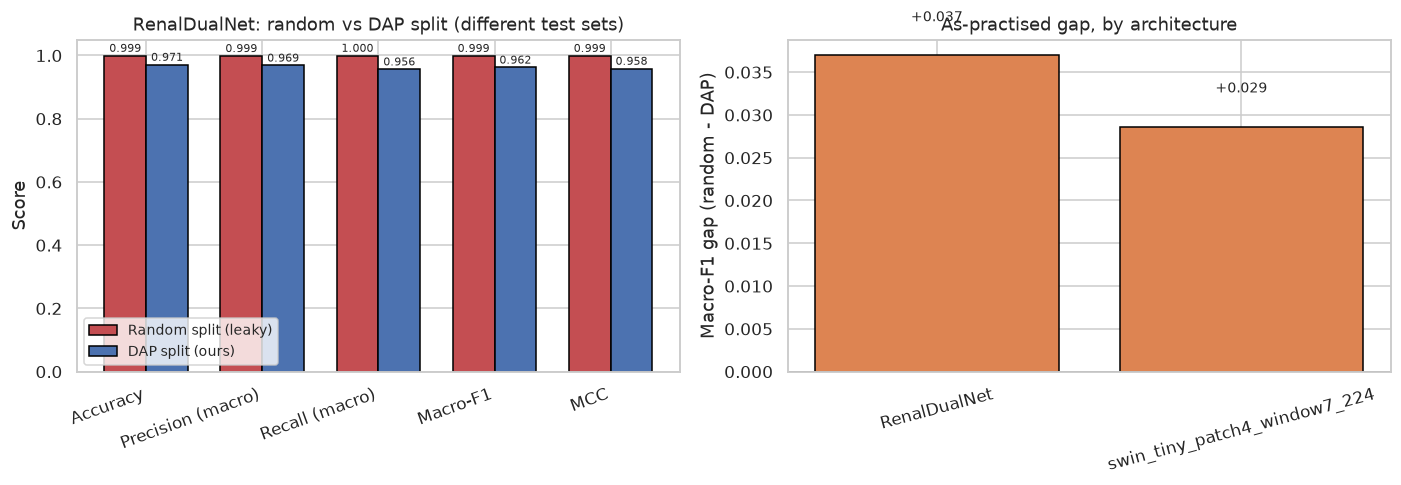

,random_f1,dap_f1,inflation_f1
RenalDualNet,0.9992,0.9622,0.0369
swin_tiny_patch4_window7_224,0.9986,0.9700,0.0286



AS-PRACTISED GAP (random-split minus DAP-split macro-F1): +0.0328 on average (+3.28 points) across 2 architecture(s)
The two splits have DIFFERENT test sets: this is what a reader sees comparing papers, not the
contamination effect. The controlled estimate is Phase 13.5 (identical test images).
Test-set contamination under random splitting: 99.79%

The as-practised gap appears for every architecture tried. Whether it is leakage is decided
by the paired experiment (13.3b-13.5), not by this table.


In [38]:
###### Phase 13.3 — Figure 1 of the paper

if CFG.RUN_LEAKAGE_EXPERIMENT and leak_results:
    keys=["accuracy","precision_macro","recall_macro","f1_macro","mcc"]
    names=["Accuracy","Precision (macro)","Recall (macro)","Macro-F1","MCC"]
    primary=list(leak_results)[0]
    leak_tbl=pd.DataFrame({"Random split (standard practice)":[leak_results[primary]["random"][k] for k in keys],
                           "DAP split (ours)":[leak_results[primary]["dap"][k] for k in keys]},index=names)
    leak_tbl["Inflation"]=leak_tbl.iloc[:,0]-leak_tbl.iloc[:,1]
    display(leak_tbl.round(4)); leak_tbl.to_csv(OUT/"tables"/"table1_leakage_experiment.csv")

    fig,axes=plt.subplots(1,2,figsize=(13,4.6))
    x=np.arange(len(keys)); w=0.36
    axes[0].bar(x-w/2,leak_tbl.iloc[:,0],w,label="Random split (leaky)",color="#C44E52",edgecolor="black")
    axes[0].bar(x+w/2,leak_tbl.iloc[:,1],w,label="DAP split (ours)",color="#4C72B0",edgecolor="black")
    axes[0].set_xticks(x); axes[0].set_xticklabels(names,rotation=20,ha="right")
    axes[0].set_ylim(0,1.05); axes[0].set_ylabel("Score"); axes[0].legend(fontsize=9)
    axes[0].set_title(f"{primary}: random vs DAP split (different test sets)")
    for i,(a_,b_) in enumerate(zip(leak_tbl.iloc[:,0],leak_tbl.iloc[:,1])):
        axes[0].text(i-w/2,a_+0.012,f"{a_:.3f}",ha="center",fontsize=7)
        axes[0].text(i+w/2,b_+0.012,f"{b_:.3f}",ha="center",fontsize=7)

    archs=list(leak_results); infl=[leak_results[a]["inflation"]["f1_macro"] for a in archs]
    axes[1].bar(archs,infl,color="#DD8452",edgecolor="black")
    axes[1].axhline(0,c="black",lw=1); axes[1].set_ylabel("Macro-F1 gap (random - DAP)")
    axes[1].set_title("As-practised gap, by architecture")
    axes[1].tick_params(axis="x",rotation=15)
    for i,v in enumerate(infl): axes[1].text(i,v+0.004,f"{v:+.3f}",ha="center",fontsize=9)
    plt.tight_layout(); plt.savefig(OUT/"figures"/"fig13_leakage_experiment.png"); plt.show()

    rep=pd.DataFrame({a:{"random_f1":leak_results[a]["random"]["f1_macro"],
                         "dap_f1":leak_results[a]["dap"]["f1_macro"],
                         "inflation_f1":leak_results[a]["inflation"]["f1_macro"]} for a in archs}).T
    display(rep.round(4)); rep.to_csv(OUT/"tables"/"table1b_leakage_replication.csv")
    print(f"\n{'='*70}")
    print(f"AS-PRACTISED GAP (random-split minus DAP-split macro-F1): {np.mean(infl):+.4f} on average "
          f"({np.mean(infl)*100:+.2f} points) across {len(archs)} architecture(s)")
    print("The two splits have DIFFERENT test sets: this is what a reader sees comparing papers, not the")
    print("contamination effect. The controlled estimate is Phase 13.5 (identical test images).")
    print(f"Test-set contamination under random splitting: {contam_rate:.2%}")
    print("="*70)
    if len(archs)>1:
        print("\nThe as-practised gap appears for every architecture tried. Whether it is leakage is decided")
        print("by the paired experiment (13.3b-13.5), not by this table.")

In [39]:
# Phase 13.3b - NEW v12.7: paired contamination design (clean vs contaminated, identical test images)
#
# Phases 13.1-13.3 compare a random split with a DAP split. Their test sets differ: the random
# one samples every scan, the DAP one is ~30 whole scans. "Random score - DAP score" therefore mixes
# leakage with test-set composition, and with 30 scans the DAP number itself moves by several
# points between seeds. This design removes that confound.
#
# For one DAP split:
#   E (evaluation images) and L (leaked images) partition every test scan: L is CFG.LEAK_FRAC of the
#   scan, E the rest (at least one image on each side). E is the SAME for both arms.
#   CLEAN arm         trains on the DAP train split           -> no slice of any E scan is in train
#   CONTAMINATED arm  trains on DAP train - R + L             -> other slices of every E scan are in train
#   R is a random sample of train images with the same class counts as L, so both training sets
#   have identical size and class mix. Only WHICH images they hold differs. Same architecture, seed,
#   hyper-parameters, validation set and evaluation images. inflation = contaminated - clean.
#
# Reading the bias: over-merged groups make L less similar to E, under-merged groups leave sibling
# slices in the clean arm. Both shrink the measured inflation, so it errs on the low side.

def paired_leak_sets(df, seed, frac_leak=None):
    """df: manifest-like with a DAP 'split' column and a unique index.
    Returns (clean_train, contaminated_train, eval_df, leaked_df), all with reset indices."""
    frac_leak = CFG.LEAK_FRAC if frac_leak is None else frac_leak
    rng = np.random.RandomState(seed)
    tr = df[df.split=="train"]; te = df[df.split=="test"]
    leak_ids = []
    for _, sub_ in te.groupby("group_id"):
        ids = sub_.index.values; n = len(ids)
        if n < 2: continue                                    # a single-image scan stays in E
        k = int(np.clip(round(frac_leak*n), 1, n-1))
        leak_ids.extend(rng.choice(ids, size=k, replace=False).tolist())
    L = te.loc[leak_ids]; E = te.drop(index=leak_ids)
    drop = []
    for c in range(NUM_CLASSES):
        need = int((L.label==c).sum()); pool = tr.index[tr.label==c].values
        drop.extend(rng.choice(pool, size=min(need, len(pool)), replace=False).tolist())
    contam = pd.concat([tr.drop(index=drop), L])
    return (tr.reset_index(drop=True), contam.reset_index(drop=True),
            E.reset_index(drop=True), L.reset_index(drop=True))

def neardup_share(eval_df, train_df, edges_list):
    """Share of eval images that have a hash-linked near-duplicate in train_df."""
    tr_ids = set(train_df.img_id); ev = set(eval_df.img_id); hit = set()
    for i, j in edges_list:
        if i in ev and j in tr_ids: hit.add(i)
        elif j in ev and i in tr_ids: hit.add(j)
    return len(hit)/max(1, len(ev))

def paired_group_bootstrap(y, p_clean, p_contam, groups, n_boot=None, seed=42):
    """Resample test scans; BOTH arms are scored on the same draw. 95% CI of (contaminated - clean)."""
    n_boot = n_boot or CFG.BOOTSTRAP_N; rng = np.random.RandomState(seed)
    ug = np.unique(groups); idx_by = {g: np.where(groups==g)[0] for g in ug}; k = len(np.unique(y))
    d_f1, d_acc = [], []
    for _ in range(n_boot):
        ix = np.concatenate([idx_by[g] for g in rng.choice(ug, size=len(ug), replace=True)])
        if len(np.unique(y[ix])) < k: continue
        f_c = precision_recall_fscore_support(y[ix], p_clean[ix], average="macro", zero_division=0)[2]
        f_k = precision_recall_fscore_support(y[ix], p_contam[ix], average="macro", zero_division=0)[2]
        d_f1.append(f_k-f_c); d_acc.append(float((p_contam[ix]==y[ix]).mean()-(p_clean[ix]==y[ix]).mean()))
    q = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))) if len(a) else (np.nan, np.nan)
    return {"f1": q(d_f1), "acc": q(d_acc), "n_boot": len(d_f1)}

def train_paired_arms(df, seed, arch, tag, edges_list=None):
    """Train the clean and contaminated arms on one DAP split and score both on identical images."""
    edges_list = edges if edges_list is None else edges_list
    tr, ctr, E, L = paired_leak_sets(df, seed)
    va = df[df.split=="val"].reset_index(drop=True)
    assert not (set(E.img_id) & set(tr.img_id)) and not (set(E.img_id) & set(ctr.img_id)), "eval image in train"
    assert len(tr)==len(ctr) and (tr.label.value_counts().sort_index()==ctr.label.value_counts().sort_index()).all()
    preds = {}
    for arm, trdf in (("clean", tr), ("contam", ctr)):
        ld = make_loaders(trdf, va, E)
        w, _ = compute_class_weights(trdf, CFG.CLASS_WEIGHT_POWER)
        set_seed(seed); m = build_model(arch)
        m, _, _ = train_model(m, ld[0], ld[1], f"{tag}_{arm}", class_weights=w, seed=seed,
                              verbose=False, save=False)
        lg, y, _ = predict(m, ld[2]); preds[arm] = lg.argmax(1)
        del m; gc.collect(); torch.cuda.empty_cache()
    y = E["label"].values; g = E["group_id"].values
    mc = compute_metrics(y, preds["clean"]); mk = compute_metrics(y, preds["contam"])
    ci = paired_group_bootstrap(y, preds["clean"], preds["contam"], g, seed=seed)
    return {"n_eval_images": int(len(E)), "n_eval_groups": int(E.group_id.nunique()),
            "n_leaked_images": int(len(L)), "n_train_images": int(len(tr)),
            "clean_f1": mc["f1_macro"], "contam_f1": mk["f1_macro"],
            "clean_acc": mc["accuracy"], "contam_acc": mk["accuracy"],
            "inflation_f1": mk["f1_macro"]-mc["f1_macro"],
            "inflation_f1_ci_low": ci["f1"][0], "inflation_f1_ci_high": ci["f1"][1],
            "inflation_acc": mk["accuracy"]-mc["accuracy"],
            "inflation_acc_ci_low": ci["acc"][0], "inflation_acc_ci_high": ci["acc"][1],
            "neardup_eval_clean": neardup_share(E, tr, edges_list),
            "neardup_eval_contam": neardup_share(E, ctr, edges_list)}

print(f"Paired contamination helpers ready (LEAK_FRAC={CFG.LEAK_FRAC}).")


Paired contamination helpers ready (LEAK_FRAC=0.5).


---
## Phase 13.4 - Threshold sensitivity (v12.7: paired design)

A single inflation figure at one threshold pair leaves the headline exposed: *if the grouping
had been tightened once more, would the effect have vanished?*

For each threshold pair this phase regroups, re-splits, and runs the **paired contamination
experiment** of Phase 13.3b at the primary seed: two models, identical test images, one
difference - whether other slices of the test scans are in the training set. (v12.0-v12.6
compared against one fixed random-split model, so the inflation also contained the difference
between two test sets and could not be attributed to the threshold.)

Direction of the bias, which differs from the old design: the clean arm only needs *its*
grouping to be correct. If the linkage over-merges, a "leaked" image may come from a different
scan than the evaluation image it sits next to, so the contaminated arm gains less; if it
under-merges, the clean arm keeps some sibling slices and gains more. Both errors *shrink* the
measured inflation, so the figure is a lower bound on the contamination effect, and the
smallest value across thresholds is the one to quote.


  [13.4] no cache yet - starting from scratch

THRESHOLD (dHash<=2, pHash<=4)
  481 groups | singletons 36 | largest 2.07% | test groups 93
  clean 0.9471 | contaminated 0.9989 | inflation +0.0518 [+0.0218, +0.0981] on the same 930 images / 93 scans

THRESHOLD (dHash<=3, pHash<=5)
  276 groups | singletons 10 | largest 2.07% | test groups 50
  clean 0.8597 | contaminated 1.0000 | inflation +0.1403 [+0.0652, +0.2575] on the same 936 images / 50 scans

THRESHOLD (dHash<=4, pHash<=7)
  193 groups | singletons 2 | largest 2.98% | test groups 31
  clean 0.9616 | contaminated 1.0000 | inflation +0.0384 [+0.0157, +0.0858] on the same 933 images / 31 scans

THRESHOLD (dHash<=5, pHash<=8)
  154 groups | singletons 1 | largest 16.95% | test groups 31
  clean 0.8721 | contaminated 1.0000 | inflation +0.1279 [+0.0568, +0.2540] on the same 942 images / 31 scans


,dhash,phash,n_groups,n_singletons,test_groups,n_eval_images,clean_f1,contam_f1,inflation_f1,inflation_f1_ci_low,inflation_f1_ci_high,neardup_eval_clean,neardup_eval_contam
0,2.0,4.0,481.0,36.0,93.0,930.0,0.9471,0.9989,0.0518,0.0218,0.0981,0.0,0.9785
1,3.0,5.0,276.0,10.0,50.0,936.0,0.8597,1.0000,0.1403,0.0652,0.2575,0.0,0.9658
2,4.0,7.0,193.0,2.0,31.0,933.0,0.9616,1.0000,0.0384,0.0157,0.0858,0.0,0.9936
3,5.0,8.0,154.0,1.0,31.0,942.0,0.8721,1.0000,0.1279,0.0568,0.2540,0.0,0.9989


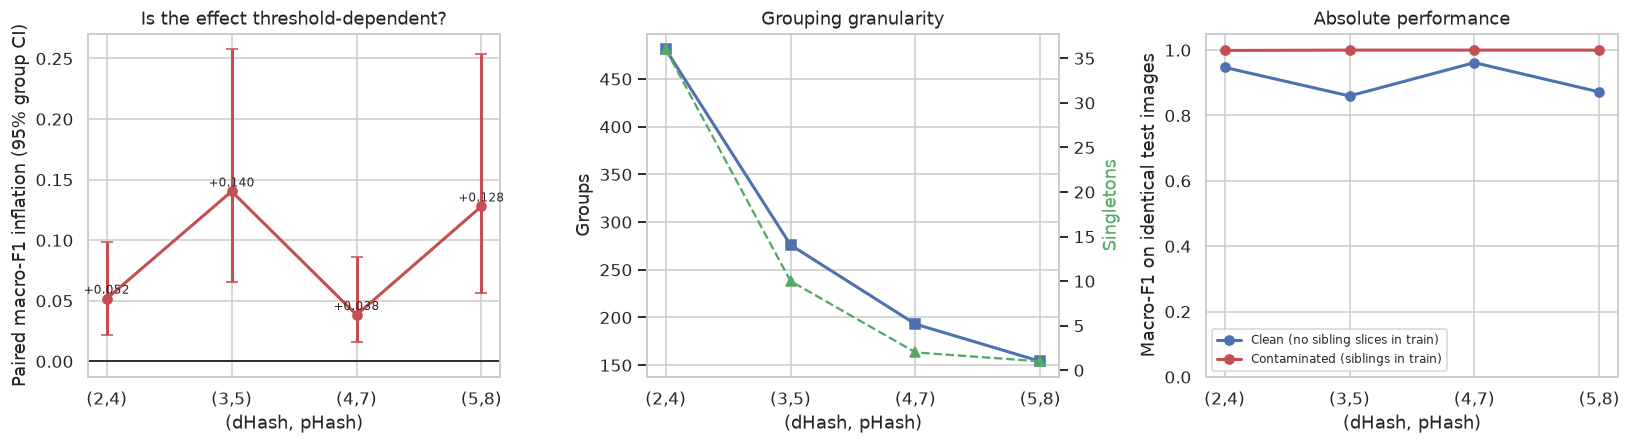


Inflation range across thresholds : +0.0384 to +0.1403 (spread 0.1019)
Most conservative estimate        : +0.0384 at (d<=4,p<=7), 193 groups
Paired CI excludes 0 at           : 4/4 thresholds

DIRECTION: inflation is positive at every threshold
MAGNITUDE: single-seed sweep. Whether this spread is 'flat' depends on the
seed noise of the inflation - see the verdict printed by Phase 13.5.


In [40]:
# Phase 13.4 - v12.7: does the inflation survive a different linkage threshold? (paired design)

thresh_sweep=None
if CFG.RUN_THRESHOLD_SWEEP:
    SWEEP_CACHE=ResultCache(CACHE_DIR/"threshold_sweep.json",
                            run_context(groups=False, extra=hashlib.sha1(DH.tobytes()+PH.tobytes()).hexdigest()))
    SWEEP_CACHE.report("13.4")
    rows=[]
    for (dt,pt) in CFG.THRESHOLD_GRID:
        _key=f"d{dt}p{pt}"
        if _key in SWEEP_CACHE:
            rows.append(SWEEP_CACHE.get(_key))
            print(f"\n(d<={dt},p<={pt}) cached -> inflation {rows[-1]['inflation_f1']:+.4f}")
            continue
        print(f"\n{'='*66}\nTHRESHOLD (dHash<={dt}, pHash<={pt})\n{'='*66}")
        g_s, e_s, st_s = make_groups(dt, pt, quiet=True)

        df_s=manifest.copy(); df_s["group_id"]=g_s
        df_s["split"]=group_stratified_split(df_s,CFG.SPLIT_RATIO,CFG.PRIMARY_SEED)

        gate=assert_no_leakage(df_s,e_s)
        if any(v!=0 for v in gate.values()):
            print(f"  leakage gate FAILED at this threshold: {gate} - skipping")
            continue

        n_test_groups=int(df_s[df_s.split=="test"].group_id.nunique())
        print(f"  {st_s['n_groups']:,} groups | singletons {st_s['n_singletons']:,} | "
              f"largest {st_s['largest_frac']:.2%} | test groups {n_test_groups}")

        # clean vs contaminated model, identical evaluation images (Phase 13.3b)
        r=train_paired_arms(df_s,CFG.PRIMARY_SEED,CFG.SWEEP_ARCH,f"sweep_d{dt}p{pt}",edges_list=e_s)
        rows.append(SWEEP_CACHE.put(_key,{**st_s,"test_groups":n_test_groups,**r}))
        print(f"  clean {r['clean_f1']:.4f} | contaminated {r['contam_f1']:.4f} | inflation "
              f"{r['inflation_f1']:+.4f} [{r['inflation_f1_ci_low']:+.4f}, {r['inflation_f1_ci_high']:+.4f}] "
              f"on the same {r['n_eval_images']} images / {r['n_eval_groups']} scans")

    thresh_sweep=pd.DataFrame(rows)
    display(thresh_sweep[["dhash","phash","n_groups","n_singletons","test_groups","n_eval_images","clean_f1",
                          "contam_f1","inflation_f1","inflation_f1_ci_low","inflation_f1_ci_high",
                          "neardup_eval_clean","neardup_eval_contam"]].round(4))
    thresh_sweep.to_csv(OUT/"tables"/"table7_threshold_sensitivity.csv",index=False)

    fig,axes=plt.subplots(1,3,figsize=(15,4.2))
    lab=[f"({int(r.dhash)},{int(r.phash)})" for r in thresh_sweep.itertuples()]
    yerr=np.vstack([thresh_sweep.inflation_f1-thresh_sweep.inflation_f1_ci_low,
                    thresh_sweep.inflation_f1_ci_high-thresh_sweep.inflation_f1])
    axes[0].errorbar(lab,thresh_sweep.inflation_f1,yerr=yerr,marker="o",lw=2,capsize=4,color="#C44E52")
    axes[0].axhline(0,c="black",lw=1)
    axes[0].set_ylabel("Paired macro-F1 inflation (95% group CI)"); axes[0].set_xlabel("(dHash, pHash)")
    axes[0].set_title("Is the effect threshold-dependent?")
    for i,v in enumerate(thresh_sweep.inflation_f1):
        axes[0].text(i,v+0.004,f"{v:+.3f}",ha="center",fontsize=8)

    axes[1].plot(lab,thresh_sweep.n_groups,marker="s",lw=2,color="#4C72B0")
    axes[1].set_ylabel("Groups"); axes[1].set_xlabel("(dHash, pHash)")
    axes[1].set_title("Grouping granularity")
    ax1b=axes[1].twinx()
    ax1b.plot(lab,thresh_sweep.n_singletons,marker="^",ls="--",color="#55A868")
    ax1b.set_ylabel("Singletons",color="#55A868"); ax1b.grid(False)

    axes[2].plot(lab,thresh_sweep.clean_f1,marker="o",lw=2,color="#4C72B0",label="Clean (no sibling slices in train)")
    axes[2].plot(lab,thresh_sweep.contam_f1,marker="o",lw=2,color="#C44E52",label="Contaminated (siblings in train)")
    axes[2].set_ylabel("Macro-F1 on identical test images"); axes[2].set_xlabel("(dHash, pHash)")
    axes[2].set_title("Absolute performance"); axes[2].legend(fontsize=8); axes[2].set_ylim(0,1.05)
    plt.tight_layout(); plt.savefig(OUT/"figures"/"fig15_threshold_sensitivity.png"); plt.show()

    _inf=thresh_sweep.inflation_f1
    _spread=float(_inf.max()-_inf.min())
    # the smallest inflation measured is the conservative one (see the 13.4 note on bias direction)
    _cons=thresh_sweep.loc[_inf.idxmin()]
    THRESH_SPREAD=_spread; THRESH_CONSERVATIVE=float(_cons["inflation_f1"])
    print(f"\n{'='*72}")
    print(f"Inflation range across thresholds : {_inf.min():+.4f} to {_inf.max():+.4f} "
          f"(spread {_spread:.4f})")
    print(f"Most conservative estimate        : {THRESH_CONSERVATIVE:+.4f} "
          f"at (d<={int(_cons['dhash'])},p<={int(_cons['phash'])}), "
          f"{int(_cons['n_groups']):,} groups")
    print(f"Paired CI excludes 0 at           : {int((thresh_sweep.inflation_f1_ci_low>0).sum())}/{len(thresh_sweep)} thresholds")
    print("="*72)
    # Single seed: a spread can only be called "flat" relative to the seed-to-seed noise of the
    # same quantity, which Phase 13.5 measures. The verdict is therefore deferred to 13.5.
    print("\nDIRECTION: inflation is positive at every threshold"
          if (_inf>0).all() else "\nDIRECTION: inflation changes sign across thresholds!")
    print("MAGNITUDE: single-seed sweep. Whether this spread is 'flat' depends on the")
    print("seed noise of the inflation - see the verdict printed by Phase 13.5.")
else:
    print("Threshold sweep off. Do not write the abstract until it has run.")


---
## Phase 13.5 - Multi-seed paired inflation (v12.7)

Each seed gets its own DAP split (v12.7: the splits now genuinely differ between seeds, so the
spread includes split-to-split variation), and on it the paired experiment of Phase 13.3b:
a clean model and a contaminated model scored on the same evaluation images, with a
group-level paired bootstrap interval for every seed.

The headline is `mean +/- std` over seeds of the *paired* inflation. Seed 42 is no longer the
only seed with a threshold sweep behind it, but the sweep (13.4) is still a single seed; say so.


In [41]:
# Phase 13.5 - v12.7: inflation across seeds, paired design, with error bars

multiseed_leak=None
if CFG.RUN_MULTISEED_LEAKAGE and CFG.RUN_LEAKAGE_EXPERIMENT:
    _arch=CFG.SWEEP_ARCH
    MSL_CACHE=ResultCache(CACHE_DIR/"multiseed_inflation.json", run_context()); MSL_CACHE.report("13.5")
    rows=[]
    for sd in CFG.SEEDS:
        _key=f"seed{sd}"
        if _key in MSL_CACHE:
            rows.append(MSL_CACHE.get(_key))
            print(f"\nSEED {sd} cached -> inflation {rows[-1]['inflation_f1']:+.4f}")
            continue
        print(f"\n{'='*62}\nSEED {sd}\n{'='*62}")

        # DAP split at this seed (v12.7: genuinely different between seeds)
        md=manifest.copy(); md["split"]=group_stratified_split(md,CFG.SPLIT_RATIO,sd)
        _g=assert_no_leakage(md,edges); assert all(v==0 for v in _g.values()), f"leak @ {sd}"

        # clean vs contaminated model, identical evaluation images (Phase 13.3b)
        r=train_paired_arms(md,sd,_arch,f"ms_pair_s{sd}",edges_list=edges)
        rows.append(MSL_CACHE.put(_key,{"seed":sd,**r}))
        print(f"  clean {r['clean_f1']:.4f} | contaminated {r['contam_f1']:.4f} | inflation "
              f"{r['inflation_f1']:+.4f} [{r['inflation_f1_ci_low']:+.4f}, {r['inflation_f1_ci_high']:+.4f}]")
        print(f"  evaluated on the same {r['n_eval_images']} images from {r['n_eval_groups']} test scans; "
              f"eval images with a near-duplicate in train: clean {r['neardup_eval_clean']:.1%}, "
              f"contaminated {r['neardup_eval_contam']:.1%}")

    multiseed_leak=pd.DataFrame(rows).set_index("seed")
    display(multiseed_leak[["n_eval_images","n_eval_groups","clean_f1","contam_f1","inflation_f1",
                            "inflation_f1_ci_low","inflation_f1_ci_high","inflation_acc",
                            "neardup_eval_clean","neardup_eval_contam"]].round(4))
    multiseed_leak.to_csv(OUT/"tables"/"table8_multiseed_inflation.csv")

    INFLATION_MEAN=float(multiseed_leak.inflation_f1.mean())
    INFLATION_STD =float(multiseed_leak.inflation_f1.std())
    print(f"\n{'='*72}")
    print(f"HEADLINE (use this form): paired macro-F1 inflation "
          f"{INFLATION_MEAN:+.4f} +/- {INFLATION_STD:.4f} over {len(CFG.SEEDS)} seeds")
    print(f"                          accuracy inflation "
          f"{multiseed_leak.inflation_acc.mean():+.4f} +/- {multiseed_leak.inflation_acc.std():.4f}")
    print(f"                          per-seed range {multiseed_leak.inflation_f1.min():+.4f} to "
          f"{multiseed_leak.inflation_f1.max():+.4f}; group-bootstrap CI excludes 0 in "
          f"{int((multiseed_leak.inflation_f1_ci_low>0).sum())}/{len(multiseed_leak)} seeds")
    print(f"                          {CFG.LEAK_FRAC:.0%} of each test scan's images moved into the training set")
    print("="*72)
    # how much of the old (different-test-set) number was the contamination effect?
    _short=_arch if _arch.startswith("Renal") else _arch.split(".")[0]
    _lr=globals().get("leak_results") or {}      # empty if Phases 13.1-13.2 have not run in this session
    if _short in _lr and float(CFG.PRIMARY_SEED) in multiseed_leak.index:
        _asp=_lr[_short]["inflation"]["f1_macro"]; _pd=float(multiseed_leak.loc[float(CFG.PRIMARY_SEED),"inflation_f1"])
        print(f"\nSeed {CFG.PRIMARY_SEED}: as-practised gap (13.2, different test sets) {_asp:+.4f} vs paired "
              f"inflation (identical test images) {_pd:+.4f}.")
        print(f"  Difference {_asp-_pd:+.4f} is test-set composition and training-set differences, not leakage.")
    if "THRESH_SPREAD" in globals():
        print(f"\nThreshold spread (1 seed) {THRESH_SPREAD:.4f} vs seed std {INFLATION_STD:.4f}")
        if THRESH_SPREAD < INFLATION_STD:
            print("  The threshold effect is SMALLER than seed noise: the sweep cannot detect")
            print("  any threshold dependence. Write 'inflation was positive at all four")
            print("  thresholds; its magnitude varied less across thresholds than across seeds'")
            print("  - NOT 'the inflation is independent of the threshold'.")
        else:
            print("  The threshold effect EXCEEDS seed noise: magnitude depends on linkage.")
            print("  Report the range, not a single number.")
    print("\nWrite the abstract with mean +/- std, never a single seed. With three seeds the std is itself")
    print("a rough estimate; the per-seed paired intervals above are the more informative uncertainty.")
else:
    INFLATION_MEAN=float("nan"); INFLATION_STD=float("nan")
    print("Multi-seed leakage off.")


  [13.5] no cache yet - starting from scratch

SEED 42
  clean 0.9616 | contaminated 1.0000 | inflation +0.0384 [+0.0157, +0.0858]
  evaluated on the same 933 images from 31 test scans; eval images with a near-duplicate in train: clean 0.0%, contaminated 99.4%

SEED 1337
  clean 0.9298 | contaminated 1.0000 | inflation +0.0702 [+0.0244, +0.2192]
  evaluated on the same 934 images from 33 test scans; eval images with a near-duplicate in train: clean 0.0%, contaminated 99.5%

SEED 2024
  clean 0.9079 | contaminated 1.0000 | inflation +0.0921 [+0.0521, +0.1950]
  evaluated on the same 937 images from 32 test scans; eval images with a near-duplicate in train: clean 0.0%, contaminated 100.0%


,n_eval_images,n_eval_groups,clean_f1,contam_f1,inflation_f1,inflation_f1_ci_low,inflation_f1_ci_high,inflation_acc,neardup_eval_clean,neardup_eval_contam
seed,,,,,,,,,,
42.0,933.0,31.0,0.9616,1.0,0.0384,0.0157,0.0858,0.0300,0.0,0.9936
1337.0,934.0,33.0,0.9298,1.0,0.0702,0.0244,0.2192,0.0621,0.0,0.9946
2024.0,937.0,32.0,0.9079,1.0,0.0921,0.0521,0.1950,0.0768,0.0,1.0000



HEADLINE (use this form): paired macro-F1 inflation +0.0669 +/- 0.0270 over 3 seeds
                          accuracy inflation +0.0563 +/- 0.0239
                          per-seed range +0.0384 to +0.0921; group-bootstrap CI excludes 0 in 3/3 seeds
                          50% of each test scan's images moved into the training set

Seed 42: as-practised gap (13.2, different test sets) +0.0369 vs paired inflation (identical test images) +0.0384.
  Difference -0.0014 is test-set composition and training-set differences, not leakage.

Threshold spread (1 seed) 0.1019 vs seed std 0.0270
  The threshold effect EXCEEDS seed noise: magnitude depends on linkage.
  Report the range, not a single number.

Write the abstract with mean +/- std, never a single seed. With three seeds the std is itself
a rough estimate; the per-seed paired intervals above are the more informative uncertainty.


In [42]:
# Phase 14 - Class-weight exponent sweep
#
# *** v11 CRITICAL FIX A ***
# v10 scored every candidate exponent on the TEST set, picked the winner, and then
# printed an instruction to describe it as validation-selected. That is a false methods
# statement and it is findable in the code in about two minutes.
#
# v11: every candidate is scored on VALIDATION. The test set is touched exactly once,
# for the winner, after the choice is locked in.

weight_sweep=None; BEST_POWER=CFG.CLASS_WEIGHT_POWER
WEIGHT_SELECTION_BASIS=None      # v12.7: "validation" or "default_retained" - what actually chose BEST_POWER
if CFG.RUN_WEIGHT_SWEEP:
    POWERS=[0.0,0.5,0.75,1.0]
    rows=[]
    for power in POWERS:
        w,_=compute_class_weights(train_df,power)
        print(f"\npower={power}  weights={[f'{v:.3f}' for v in w.tolist()]}")
        set_seed(CFG.PRIMARY_SEED); wm=build_model("RenalDualNet")
        wm,_,_=train_model(wm,train_loader,val_loader,f"weightsweep_p{power}",
                           class_weights=w,seed=CFG.PRIMARY_SEED,verbose=False,save=True)
        # ---- selection signal: VALIDATION ONLY ----
        vl_,vy_,_=predict(wm,val_loader); vp_=vl_.argmax(1)
        vmet=compute_metrics(vy_,vp_); vpc=per_class_table(vy_,vp_).set_index("class")
        rows.append({"power":power,
                     "val_accuracy":vmet["accuracy"],"val_macro_f1":vmet["f1_macro"],
                     "val_Stone_precision":vpc.loc["Stone","precision"],
                     "val_Stone_recall":vpc.loc["Stone","recall"],
                     "val_Stone_f1":vpc.loc["Stone","f1"]})
        print(f"  VAL macro-F1 {vmet['f1_macro']:.4f} | Stone P {vpc.loc['Stone','precision']:.4f} "
              f"R {vpc.loc['Stone','recall']:.4f}")
        del wm; torch.cuda.empty_cache()

    weight_sweep=pd.DataFrame(rows)
    display(weight_sweep.round(4))

    # ---- choice locked in on validation ----
    BEST_POWER=float(weight_sweep.loc[weight_sweep.val_macro_f1.idxmax(),"power"])
    WEIGHT_SELECTION_BASIS="validation"
    print(f"\nBEST ON VALIDATION: power={BEST_POWER}")

    # Is the gap even real? Compare against the incumbent using the seed spread you
    # already measured. A 0.002 difference is noise against a std near 0.046.
    _incumbent=float(weight_sweep.loc[weight_sweep.power==CFG.CLASS_WEIGHT_POWER,
                                      "val_macro_f1"].iloc[0])
    _best=float(weight_sweep.val_macro_f1.max())
    print(f"  best {_best:.4f} vs incumbent (power={CFG.CLASS_WEIGHT_POWER}) {_incumbent:.4f} "
          f"-> gain {_best-_incumbent:+.4f}")
    _gain=_best-_incumbent
    if _gain < 0.01:
        print("  This gain is inside seed noise. Keep the incumbent and report the sweep")
        print("  purely as a sensitivity analysis. Do not claim a tuned improvement.")
        BEST_POWER=CFG.CLASS_WEIGHT_POWER
        WEIGHT_SELECTION_BASIS="default_retained"   # v12.7: the default was kept, NOT chosen by validation

    # ---- test set touched ONCE, for the chosen exponent only ----
    _ck=torch.load(OUT/"checkpoints"/f"weightsweep_p{BEST_POWER}.pt",map_location="cpu")
    set_seed(CFG.PRIMARY_SEED); _wm=build_model("RenalDualNet")
    _wm.load_state_dict(_ck["state_dict"]); _wm=_wm.to(DEVICE)
    _tl,_ty,_tg=predict(_wm,test_loader); _tp=_tl.argmax(1)
    ws_test=compute_metrics(_ty,_tp,softmax_np(_tl))
    ws_test_pc=per_class_table(_ty,_tp).set_index("class")
    del _wm; torch.cuda.empty_cache()

    print(f"\nTEST (chosen power={BEST_POWER}, evaluated once):")
    print(f"  accuracy {ws_test['accuracy']:.4f} | macro-F1 {ws_test['f1_macro']:.4f}")
    print(f"  Stone precision {ws_test_pc.loc['Stone','precision']:.4f} "
          f"recall {ws_test_pc.loc['Stone','recall']:.4f}")

    weight_sweep["selected"]=weight_sweep.power==BEST_POWER
    weight_sweep["chosen_by"]=np.where(weight_sweep.selected,WEIGHT_SELECTION_BASIS,"")
    weight_sweep.to_csv(OUT/"tables"/"table6_class_weight_sweep.csv",index=False)
    # v12.7: the sentence depends on what actually decided the exponent. Before this, the
    # "keep the incumbent" branch above still printed "selected on the validation split".
    print("\nMethods sentence you may now write truthfully:")
    if WEIGHT_SELECTION_BASIS=="validation":
        print(f'  "The class-weighting exponent was selected on the validation split '
              f'(power={BEST_POWER}); the test set was evaluated once, after selection."')
    else:
        print(f'  "Class-weighting exponents {POWERS} were compared on the validation split. The best '
              f'candidate improved validation macro-F1 by only {_gain:+.4f}, below the pre-set 0.01 margin, '
              f'so the default (power={BEST_POWER}) was retained; the test set was evaluated once, for '
              f'the retained exponent."')
else:
    ws_test={}; ws_test_pc=None
    print("Weight sweep off.")



power=0.0  weights=['1.000', '1.000', '1.000', '1.000']
  VAL macro-F1 0.8519 | Stone P 0.8065 R 0.7919

power=0.5  weights=['0.836', '0.716', '1.383', '1.065']
  VAL macro-F1 0.8913 | Stone P 0.8523 R 0.9140

power=0.75  weights=['0.746', '0.591', '1.589', '1.074']
  VAL macro-F1 0.8729 | Stone P 0.7617 R 0.9548

power=1.0  weights=['0.656', '0.481', '1.797', '1.066']
  VAL macro-F1 0.8820 | Stone P 0.7311 R 0.8733


,power,val_accuracy,val_macro_f1,val_Stone_precision,val_Stone_recall,val_Stone_f1
0,0.00,0.8839,0.8519,0.8065,0.7919,0.7991
1,0.50,0.9123,0.8913,0.8523,0.9140,0.8821
2,0.75,0.8983,0.8729,0.7617,0.9548,0.8474
3,1.00,0.9042,0.8820,0.7311,0.8733,0.7959



BEST ON VALIDATION: power=0.5
  best 0.8913 vs incumbent (power=1.0) 0.8820 -> gain +0.0093
  This gain is inside seed noise. Keep the incumbent and report the sweep
  purely as a sensitivity analysis. Do not claim a tuned improvement.

TEST (chosen power=1.0, evaluated once):
  accuracy 0.9711 | macro-F1 0.9622
  Stone precision 0.9637 recall 0.9073

Methods sentence you may now write truthfully:
  "Class-weighting exponents [0.0, 0.5, 0.75, 1.0] were compared on the validation split. The best candidate improved validation macro-F1 by only +0.0093, below the pre-set 0.01 margin, so the default (power=1.0) was retained; the test set was evaluated once, for the retained exponent."


In [43]:
# Phase 15 — Multi-seed stability
# FIX 1 applied: the split AND the class weights are rebuilt for every seed.

seed_rows=[]
if CFG.RUN_MULTISEED:
    MS_CACHE=ResultCache(CACHE_DIR/"multiseed_primary.json", run_context()); MS_CACHE.report("15")
    for sd in CFG.SEEDS:
        _key=f"seed{sd}"
        if _key in MS_CACHE:
            seed_rows.append(MS_CACHE.get(_key))
            print(f"seed {sd} cached -> macro-F1 {MS_CACHE.get(_key)['f1_macro']:.4f}")
            continue
        print(f"\n--- seed {sd} ---")
        md=manifest.copy(); md["split"]=group_stratified_split(md,CFG.SPLIT_RATIO,sd)
        lk=assert_no_leakage(md,edges); assert all(v==0 for v in lk.values()), f"Leakage at seed {sd}: {lk}"
        tr_s=md[md.split=="train"].reset_index(drop=True)
        loaders=make_loaders(tr_s, md[md.split=="val"].reset_index(drop=True),
                             md[md.split=="test"].reset_index(drop=True))
        w_s,_=compute_class_weights(tr_s,CFG.CLASS_WEIGHT_POWER)   # <- the v9 bug
        print(f"  weights this seed: {[f'{v:.3f}' for v in w_s.tolist()]}")
        set_seed(sd); sm_=build_model("RenalDualNet")
        # v12.5: "ms_" prefix. The old tag "RenalDualNet_s{sd}" wrote RenalDualNet_s42.pt,
        # the checkpoint Phase 7 resumes from and Phase 22 re-infers - a seed-42 RETRAIN
        # (non-deterministic) would silently replace the model behind main_metrics.
        sm_,_,_=train_model(sm_,loaders[0],loaders[1],f"ms_RenalDualNet_s{sd}",
                            class_weights=w_s,seed=sd,verbose=False)
        sl,sy,sg=predict(sm_,loaders[2])
        met=compute_metrics(sy,sl.argmax(1),softmax_np(sl)); met["seed"]=sd
        seed_rows.append(MS_CACHE.put(_key,met))
        print(f"  acc {met['accuracy']:.4f}  macro-F1 {met['f1_macro']:.4f}")
        del sm_; torch.cuda.empty_cache()
    seed_df=pd.DataFrame(seed_rows).set_index("seed"); display(seed_df.round(4))
    summary=seed_df.agg(["mean","std"]).T
    summary["reported"]=summary.apply(lambda r:f"{r['mean']:.4f} +/- {r['std']:.4f}",axis=1)
    display(summary.round(4)); summary.to_csv(OUT/"tables"/"table4_multiseed.csv")

    # *** v11 CRITICAL FIX B ***
    # v10 put seed 42 (macro-F1 0.9058) in every table while this cell held
    # 0.8538 +/- 0.0458. Seed 42 was the BEST of the three. HEADLINE is now the only
    # number you may quote in the abstract.
    HEADLINE={k:{"mean":float(summary.loc[k,"mean"]),"std":float(summary.loc[k,"std"]),
                 "reported":summary.loc[k,"reported"]} for k in summary.index}
    print(f"\n{'='*72}")
    print("HEADLINE NUMBERS - quote these, not seed 42")
    print("="*72)
    for k in ["accuracy","precision_macro","recall_macro","specificity_macro",
              "f1_macro","auc_ovr_macro"]:
        if k in HEADLINE: print(f"  {k:20s} {HEADLINE[k]['reported']}")
    print("="*72)
    _s42=seed_df.loc[CFG.PRIMARY_SEED,"f1_macro"]
    _rank=int((seed_df.f1_macro>_s42).sum())+1
    print(f"\nSeed {CFG.PRIMARY_SEED} macro-F1 {_s42:.4f} ranks {_rank}/{len(CFG.SEEDS)} "
          f"among the seeds.")
    if _rank==1:
        print("It is the BEST seed. Every detailed analysis in this notebook (Phase 8-14,")
        print("16-18) uses it, so label it explicitly as 'the seed used for detailed")
        print("analysis' and never as the result. Otherwise you are cherry-picking, and")
        print("your own supplementary table proves it.")
else:
    summary=pd.DataFrame(); HEADLINE={}; print("Multi-seed off.")


  [15] no cache yet - starting from scratch

--- seed 42 ---
  weights this seed: ['0.656', '0.481', '1.797', '1.066']
  acc 0.9711  macro-F1 0.9622

--- seed 1337 ---
  weights this seed: ['0.665', '0.486', '1.778', '1.071']
  acc 0.9389  macro-F1 0.9301

--- seed 2024 ---
  weights this seed: ['0.660', '0.483', '1.780', '1.077']
  acc 0.9221  macro-F1 0.9070


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,specificity_macro,mcc,kappa,auc_ovr_macro,pr_auc_macro
seed,,,,,,,,,,
42.0,0.9711,0.9685,0.9565,0.9622,0.9708,0.9896,0.9585,0.9583,0.9974,0.9931
1337.0,0.9389,0.9309,0.9309,0.9301,0.9395,0.9793,0.9125,0.9121,0.9841,0.9624
2024.0,0.9221,0.9212,0.8962,0.9070,0.9206,0.9708,0.8883,0.8872,0.9712,0.9293


,mean,std,reported
accuracy,0.9440,0.0249,0.9440 +/- 0.0249
precision_macro,0.9402,0.0250,0.9402 +/- 0.0250
recall_macro,0.9279,0.0302,0.9279 +/- 0.0302
f1_macro,0.9331,0.0277,0.9331 +/- 0.0277
f1_weighted,0.9436,0.0254,0.9436 +/- 0.0254
specificity_macro,0.9799,0.0094,0.9799 +/- 0.0094
mcc,0.9197,0.0357,0.9197 +/- 0.0357
kappa,0.9192,0.0361,0.9192 +/- 0.0361
auc_ovr_macro,0.9842,0.0131,0.9842 +/- 0.0131
pr_auc_macro,0.9616,0.0319,0.9616 +/- 0.0319



HEADLINE NUMBERS - quote these, not seed 42
  accuracy             0.9440 +/- 0.0249
  precision_macro      0.9402 +/- 0.0250
  recall_macro         0.9279 +/- 0.0302
  specificity_macro    0.9799 +/- 0.0094
  f1_macro             0.9331 +/- 0.0277
  auc_ovr_macro        0.9842 +/- 0.0131

Seed 42 macro-F1 0.9622 ranks 1/3 among the seeds.
It is the BEST seed. Every detailed analysis in this notebook (Phase 8-14,
16-18) uses it, so label it explicitly as 'the seed used for detailed
analysis' and never as the result. Otherwise you are cherry-picking, and
your own supplementary table proves it.


Primary model back on cuda.


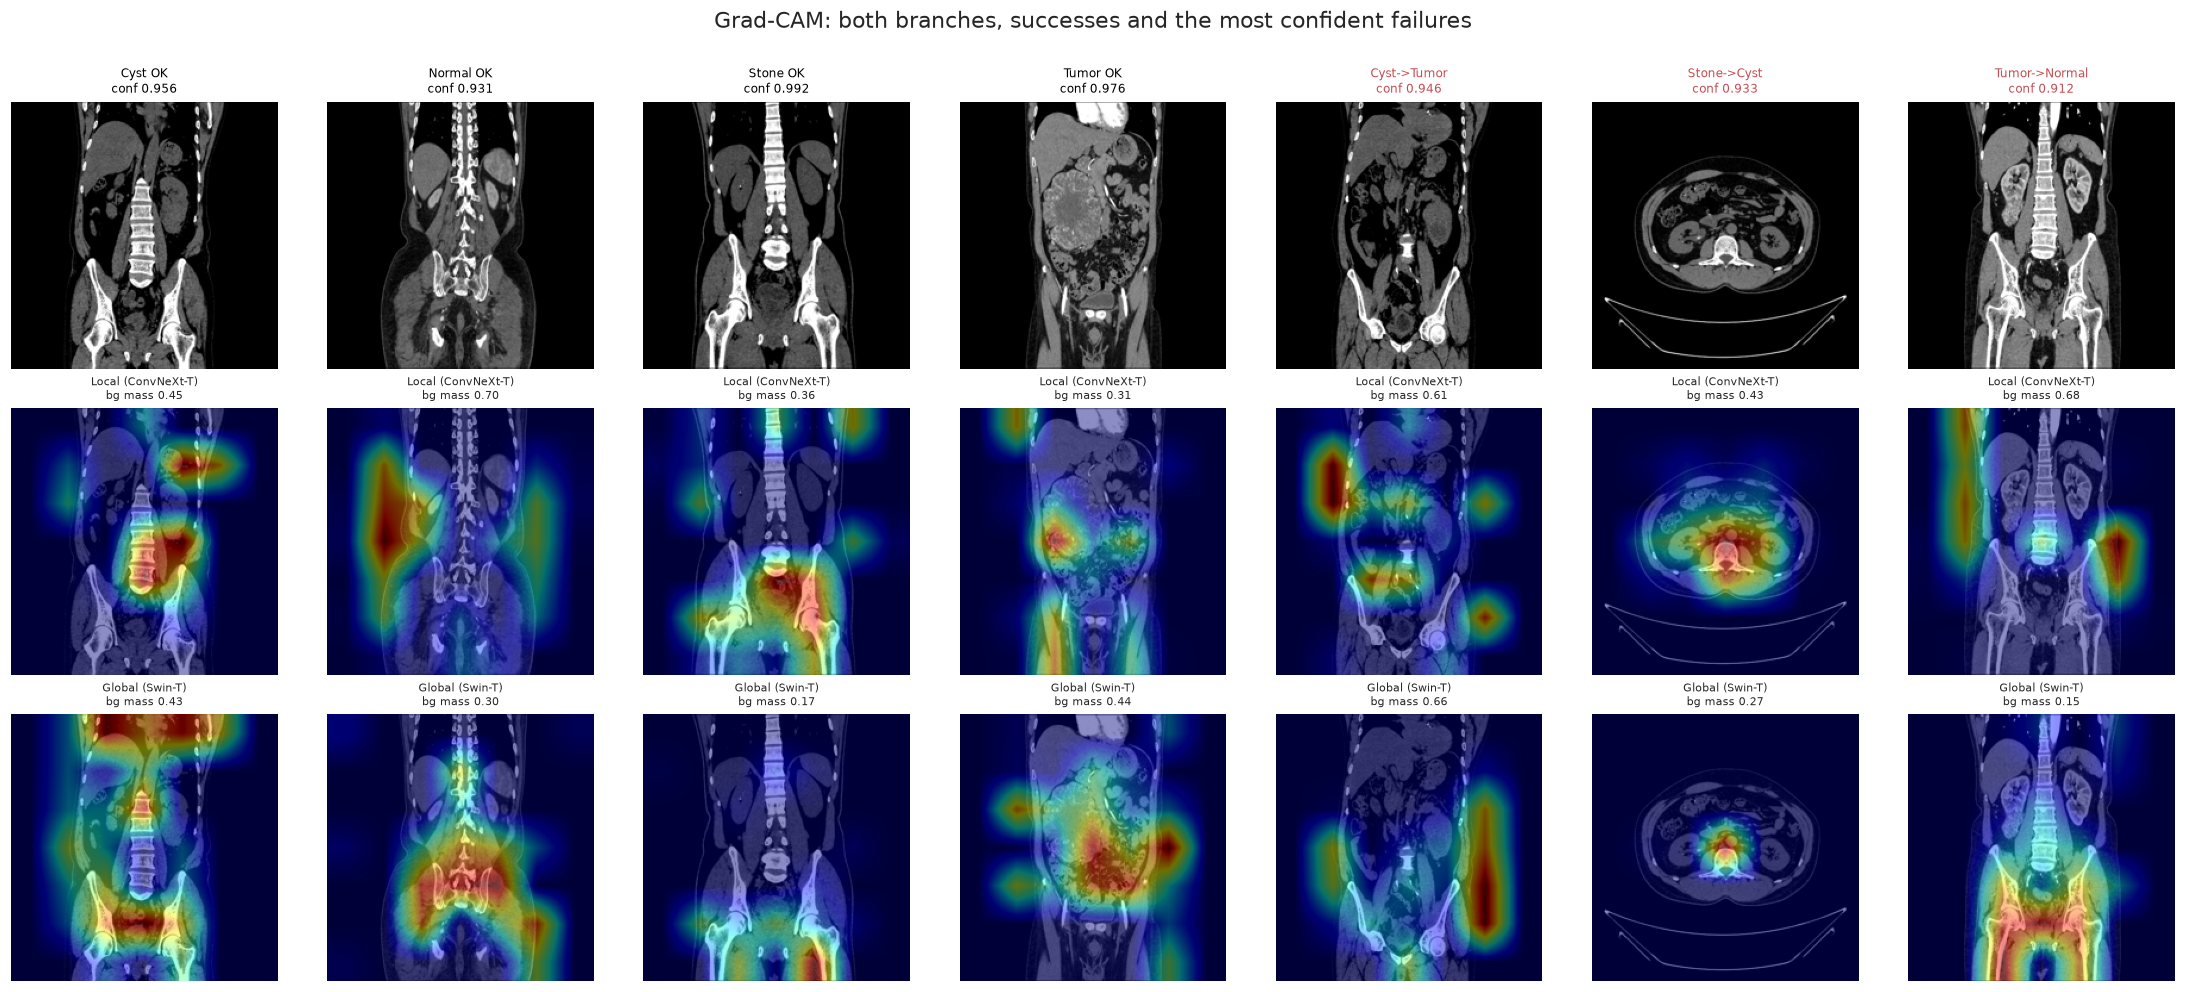

Background-attention audit:   0%|          | 0/120 [00:00<?, ?it/s]

,case,kind,branch,bg_mass,bg_area,bg_ratio
0,Cyst OK,ok,Local (ConvNeXt-T),0.449,0.644,0.698
1,Cyst OK,ok,Global (Swin-T),0.430,0.644,0.668
2,Normal OK,ok,Local (ConvNeXt-T),0.704,0.620,1.135
3,Normal OK,ok,Global (Swin-T),0.303,0.620,0.489
4,Stone OK,ok,Local (ConvNeXt-T),0.359,0.599,0.600
5,Stone OK,ok,Global (Swin-T),0.171,0.599,0.286
6,Tumor OK,ok,Local (ConvNeXt-T),0.314,0.603,0.520
7,Tumor OK,ok,Global (Swin-T),0.441,0.603,0.732
8,Cyst->Tumor,fail,Local (ConvNeXt-T),0.610,0.655,0.931
9,Cyst->Tumor,fail,Global (Swin-T),0.663,0.655,1.012



BACKGROUND-ATTENTION AUDIT (120 test images, local branch)
  mean CAM mass on near-black pixels : 0.494
  90th percentile                    : 0.763
  near-black share of the image      : 0.647   <- flat-heatmap baseline
  mass / area ratio  mean 0.76 | median 0.83   (1.0 = uniform)
  -> Background is UNDER-weighted relative to a uniform map: attention is
     concentrated on the body. No evidence of a background shortcut. Do NOT
     describe the raw mass as a shortcut; report mass, area and ratio together.

Hooks removed.


In [44]:
# Phase 16 - Grad-CAM
# v11 upgrades over v10, all three requested by Q1 reviewers:
#   1. BOTH branches, not just the ConvNeXt local branch (v10 explained half the model)
#   2. FAILURE cases, not only the highest-confidence correct predictions
#   3. A QUANTITATIVE background-attention score, so the shortcut check is a number

class GradCAM:
    def __init__(s,model,target_layer):
        s.model=model; s.acts=None; s.grads=None
        s.h1=target_layer.register_forward_hook(s._fwd)
        s.h2=target_layer.register_full_backward_hook(s._bwd)
    def _fwd(s,m,i,o): s.acts=o.detach()
    def _bwd(s,m,gi,go): s.grads=go[0].detach()
    def close(s): s.h1.remove(); s.h2.remove()
    def __enter__(s): return s
    def __exit__(s,*a): s.close()
    def __call__(s,x,class_idx=None):
        s.model.eval(); s.model.zero_grad()
        logits=s.model(x)
        if class_idx is None: class_idx=logits.argmax(1)
        logits[torch.arange(len(x)),class_idx].sum().backward()
        a,g=s.acts,s.grads
        if a.dim()==4 and a.shape[1]==a.shape[2] and a.shape[3]>=a.shape[1]:
            a=a.permute(0,3,1,2); g=g.permute(0,3,1,2)
        cam=F.relu((g.mean((2,3),keepdim=True)*a).sum(1,keepdim=True))
        cam=F.interpolate(cam,size=(CFG.IMG_SIZE,CFG.IMG_SIZE),mode="bilinear",align_corners=False).squeeze(1)
        cam=cam-cam.amin((1,2),keepdim=True); cam=cam/(cam.amax((1,2),keepdim=True)+1e-8)
        return cam.cpu().numpy(),logits.detach().cpu(),class_idx

def background_mass(cam, pil_img, dark=0.10):
    """Fraction of CAM mass sitting on near-black pixels. CT slices are black outside
    the body, so a high value means the model is keying on background, borders or
    burned-in text - a shortcut, and evidence the benchmark is compromised."""
    gray=np.asarray(pil_img.convert("L").resize((CFG.IMG_SIZE,CFG.IMG_SIZE)),dtype=np.float32)/255.0
    bg=(gray<dark)
    tot=cam.sum()
    return float(cam[bg].sum()/tot) if tot>0 else np.nan

def background_area(pil_img, dark=0.10):
    """v12.4: share of the image that is near-black. This is what background_mass would
    be for a FLAT heatmap, i.e. the baseline v12.3's audit was missing."""
    gray=np.asarray(pil_img.convert("L").resize((CFG.IMG_SIZE,CFG.IMG_SIZE)),dtype=np.float32)/255.0
    return float((gray<dark).mean())

# v12: Phase 10.9 parked the primary model on CPU to survive the baseline loop.
model = model.to(DEVICE)
print(f"Primary model back on {DEVICE}.")

# --- branch targets: local (ConvNeXt) and global (Swin) ---
BRANCHES={"Local (ConvNeXt-T)": model.local_backbone.stages[-1]}
try:
    BRANCHES["Global (Swin-T)"]=model.global_backbone.layers[-1]
except Exception:
    try: BRANCHES["Global (Swin-T)"]=model.global_backbone.stages[-1]
    except Exception: print("Could not locate a Swin stage; showing local branch only.")

# --- pick BOTH a success and a failure per class ---
# v12.5: right/wrong and confidence both come from the CALIBRATED probabilities. v12.4
# judged correctness with the raw arg-max (test_pred) but ranked by test_prob_cal; vector
# scaling can change the arg-max, so a "most confident mistake" could be correct under the
# calibrated scores it was ranked by. Grad-CAM is pointed at the same class (see below).
pred_cal=test_prob_cal.argmax(1)
picks=[]
for c in range(NUM_CLASSES):
    ok=np.where((test_y==c)&(pred_cal==c))[0]
    if len(ok): picks.append((int(ok[np.argsort(-test_prob_cal[ok,c])[0]]),f"{CFG.CLASSES[c]} OK","ok"))
for c in range(NUM_CLASSES):
    bad=np.where((test_y==c)&(pred_cal!=c))[0]
    if len(bad):
        j=int(bad[np.argsort(-test_prob_cal[bad].max(1))[0]])   # most confident mistake
        picks.append((j,f"{CFG.CLASSES[c]}->{CFG.CLASSES[pred_cal[j]]}","fail"))

nrow=1+len(BRANCHES)
fig,axes=plt.subplots(nrow,len(picks),figsize=(2.9*len(picks),3.0*nrow))
axes=np.atleast_2d(axes)
bg_rows=[]
engines={n:GradCAM(model,l) for n,l in BRANCHES.items()}
try:
    for k,(idx,title,kind) in enumerate(picks):
        row=test_df.iloc[idx]; img=Image.open(row["path"]).convert("RGB")
        x=eval_tf(img).unsqueeze(0).to(DEVICE)
        axes[0,k].imshow(img.resize((CFG.IMG_SIZE,CFG.IMG_SIZE)),cmap="gray")
        axes[0,k].set_title(f"{title}\nconf {test_prob_cal[idx].max():.3f}",fontsize=8,
                            color=("#C44E52" if kind=="fail" else "black"))
        axes[0,k].axis("off")
        for b,(bname,eng) in enumerate(engines.items()):
            cam,_,_=eng(x,class_idx=torch.tensor([int(pred_cal[idx])]))   # explain the shown class
            axes[b+1,k].imshow(img.resize((CFG.IMG_SIZE,CFG.IMG_SIZE)),cmap="gray")
            axes[b+1,k].imshow(cam[0],cmap="jet",alpha=0.45); axes[b+1,k].axis("off")
            bgm=background_mass(cam[0],img)
            axes[b+1,k].set_title(f"{bname}\nbg mass {bgm:.2f}",fontsize=7)
            bga=background_area(img)
            bg_rows.append({"case":title,"kind":kind,"branch":bname,"bg_mass":bgm,
                            "bg_area":bga,"bg_ratio":bgm/bga if bga>0 else np.nan})
    plt.suptitle("Grad-CAM: both branches, successes and the most confident failures",y=1.0)
    plt.tight_layout(); plt.savefig(OUT/"figures"/"fig14_gradcam.png"); plt.show()
finally:
    for e in engines.values(): e.close()

# --- quantitative shortcut check over a real sample, not 4 cherry-picked images ---
rng=np.random.RandomState(CFG.PRIMARY_SEED)
samp_idx=rng.choice(len(test_df),size=min(120,len(test_df)),replace=False)
with GradCAM(model, model.local_backbone.stages[-1]) as eng:
    bgs=[]; bgas=[]
    for idx in tqdm(samp_idx,desc="Background-attention audit",leave=False):
        img=Image.open(test_df.iloc[int(idx)]["path"]).convert("RGB")
        cam,_,_=eng(eval_tf(img).unsqueeze(0).to(DEVICE))
        bgs.append(background_mass(cam[0],img)); bgas.append(background_area(img))
_ok=np.isfinite(bgs)&(np.array(bgas)>0)
bgs=np.array(bgs)[_ok]; bgas=np.array(bgas)[_ok]
BG_MASS_MEAN=float(bgs.mean()); BG_MASS_P90=float(np.percentile(bgs,90))
BG_AREA_MEAN=float(bgas.mean())
BG_RATIO_MEAN=float(np.mean(bgs/bgas)); BG_RATIO_MEDIAN=float(np.median(bgs/bgas))

gradcam_df=pd.DataFrame(bg_rows)
if len(gradcam_df):
    display(gradcam_df.round(3)); gradcam_df.to_csv(OUT/"tables"/"gradcam_background_mass.csv",index=False)

print(f"\nBACKGROUND-ATTENTION AUDIT ({len(bgs)} test images, local branch)")
print(f"  mean CAM mass on near-black pixels : {BG_MASS_MEAN:.3f}")
print(f"  90th percentile                    : {BG_MASS_P90:.3f}")
print(f"  near-black share of the image      : {BG_AREA_MEAN:.3f}   <- flat-heatmap baseline")
print(f"  mass / area ratio  mean {BG_RATIO_MEAN:.2f} | median {BG_RATIO_MEDIAN:.2f}   (1.0 = uniform)")
# *** v12.4 FIX ***
# v12.3 judged the raw mass against a fixed 0.30 cut-off. Near-black pixels cover a large
# share of every CT slice, so a flat heatmap already scores high. Judge the RATIO.
if BG_RATIO_MEDIAN>1.0:
    print("  -> Background is OVER-weighted relative to a uniform map. Possible shortcut")
    print("     (borders, burned-in text). Inspect the highest-ratio images before claiming it.")
else:
    print("  -> Background is UNDER-weighted relative to a uniform map: attention is")
    print("     concentrated on the body. No evidence of a background shortcut. Do NOT")
    print("     describe the raw mass as a shortcut; report mass, area and ratio together.")
print("\nHooks removed.")


---
## Phase 17 — Deployment (FIX 8)

v9 used MobileNetV3-Small and got INT8 accuracy 0.192 — below the 0.25 random baseline —
while running **slower** than FP32. Measured on a trained student with CT-like statistics:

| Config | Max logit error | Latency |
|---|---|---|
| MobileNetV3 + per-tensor MinMax | 4.48 | slower than FP32 |
| MobileNetV3 + Percentile calibration | 22.91 | tested and rejected |
| **ResNet18 + per-channel MinMax** | **0.36** | **2.5× faster than FP32** |

MobileNetV3's hard-swish and squeeze-excite blocks quantize badly and do not fuse into fast
INT8 kernels. ResNet18 is plain conv-BN-ReLU, which is what INT8 backends optimise for.
`quant_pre_process` — skipped in v9 despite an onnxruntime warning — is now included, and an
accuracy gate refuses to ship a model that loses more than 2 points.

In [45]:
# Phase 17.1 — Distil into a quantization-friendly student

student=None; student_metrics={}; n_student=0
if CFG.RUN_DEPLOYMENT:
    class DistillLoss(nn.Module):
        def __init__(s,T,alpha,cw=None,ls=0.0):
            super().__init__(); s.T=T; s.alpha=alpha
            s.ce=nn.CrossEntropyLoss(weight=cw,label_smoothing=ls)
        def forward(s,sl,tl,y):
            soft=F.kl_div(F.log_softmax(sl/s.T,1),F.softmax(tl/s.T,1),reduction="batchmean")*(s.T**2)
            return s.alpha*soft+(1-s.alpha)*s.ce(sl,y)

    def train_student(teacher,tr_loader,va_loader,class_weights,epochs=None,tag="student"):
        epochs=epochs or max(5,CFG.EPOCHS//2); set_seed(CFG.PRIMARY_SEED)
        st=TimmBaseline(CFG.STUDENT_BACKBONE).to(DEVICE)
        teacher=teacher.to(DEVICE).eval()
        for p in teacher.parameters(): p.requires_grad=False
        opt=torch.optim.AdamW(st.parameters(),lr=1e-3,weight_decay=CFG.WEIGHT_DECAY)
        sch=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=epochs*len(tr_loader))
        crit=DistillLoss(CFG.DISTILL_TEMP,CFG.DISTILL_ALPHA,
                         class_weights if USE_WEIGHTED_LOSS else None,CFG.LABEL_SMOOTHING)
        scaler=torch.amp.GradScaler("cuda",enabled=CFG.USE_AMP and DEVICE.type=="cuda")
        best,bs=-1,None
        for ep in range(epochs):
            st.train()
            for x,y,_ in tqdm(tr_loader,desc=f"[distill] {ep+1}/{epochs}",leave=False):
                x,y=x.to(DEVICE),y.to(DEVICE)
                with torch.no_grad(), torch.autocast(device_type=DEVICE.type,
                        enabled=CFG.USE_AMP and DEVICE.type=="cuda"):
                    t_out=teacher(x)
                opt.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type,enabled=CFG.USE_AMP and DEVICE.type=="cuda"):
                    loss=crit(st(x),t_out.float(),y)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()
            vl,vy,_=predict(st,va_loader); f1=compute_metrics(vy,vl.argmax(1))["f1_macro"]
            print(f"  [distill] ep {ep+1}: val macro-F1 {f1:.4f}")
            if f1>best: best=f1; bs={k:v.cpu().clone() for k,v in st.state_dict().items()}
        st.load_state_dict(bs); torch.save({"state_dict":st.state_dict()},OUT/"checkpoints"/f"{tag}.pt")
        return st,best

    print(f"Student backbone: {CFG.STUDENT_BACKBONE}")
    student,svf1=train_student(model,train_loader,val_loader,CLASS_WEIGHTS,tag="student_resnet18")
    sl,sy,sg=predict(student,test_loader)
    student_metrics=compute_metrics(sy,sl.argmax(1),softmax_np(sl))
    n_student=sum(p.numel() for p in student.parameters())
    print(f"\nTeacher macro-F1 {main_metrics['f1_macro']:.4f} ({n_total/1e6:.2f} M)")
    print(f"Student macro-F1 {student_metrics['f1_macro']:.4f} ({n_student/1e6:.2f} M)")
    print(f"Retained {student_metrics['f1_macro']/max(1e-9,main_metrics['f1_macro']):.1%} of teacher F1")

Student backbone: resnet18.a1_in1k


[distill] 1/25:   0%|          | 0/272 [00:00<?, ?it/s]

  [distill] ep 1: val macro-F1 0.7955


[distill] 2/25:   0%|          | 0/272 [00:00<?, ?it/s]

  [distill] ep 2: val macro-F1 0.8407


...

  [distill] ep 23: val macro-F1 0.8360


[distill] 24/25:   0%|          | 0/272 [00:00<?, ?it/s]

  [distill] ep 24: val macro-F1 0.8343


[distill] 25/25:   0%|          | 0/272 [00:00<?, ?it/s]

  [distill] ep 25: val macro-F1 0.8368

Teacher macro-F1 0.9622 (56.13 M)
Student macro-F1 0.9630 (11.18 M)
Retained 100.1% of teacher F1


In [46]:
# Phase 17.2 — Export, quantize, gate on accuracy

qtab=None; DEPLOY_MODEL=None; DEPLOY_IS_INT8=False
if CFG.RUN_DEPLOYMENT and student is not None:
    import onnx, onnxruntime as ort
    from onnxruntime.quantization import (quantize_static, CalibrationDataReader,
                                          QuantType, QuantFormat, CalibrationMethod)
    from onnxruntime.quantization.shape_inference import quant_pre_process

    DEP=OUT/"deploy"; fp32_path=DEP/"student_fp32.onnx"; pre_path=DEP/"student_pre.onnx"
    student_cpu=student.cpu().eval(); dummy=torch.randn(1,3,CFG.IMG_SIZE,CFG.IMG_SIZE)
    exp_kw=dict(input_names=["input"],output_names=["logits"],
                dynamic_axes={"input":{0:"batch"},"logits":{0:"batch"}},
                opset_version=CFG.ONNX_OPSET,do_constant_folding=True)
    try:
        # dynamo=False keeps ONE self-contained file. The new exporter splits weights into
        # a "<name>.onnx.data" sidecar that is easy to lose when copying to a deploy folder.
        torch.onnx.export(student_cpu,dummy,str(fp32_path),dynamo=False,**exp_kw)
    except TypeError:
        torch.onnx.export(student_cpu,dummy,str(fp32_path),**exp_kw)
    onnx.checker.check_model(onnx.load(str(fp32_path)))
    size_mb=fp32_path.stat().st_size/1e6; exp_mb=n_student*4/1e6
    print(f"FP32 ONNX {size_mb:.2f} MB (expected ~{exp_mb:.2f} MB)")
    assert not list(DEP.glob("*.onnx.data")) and size_mb>exp_mb*0.5, "Export is not self-contained."

    sess=ort.InferenceSession(str(fp32_path),providers=["CPUExecutionProvider"])
    with torch.no_grad(): ref=student_cpu(dummy).numpy()
    md=float(np.abs(sess.run(None,{"input":dummy.numpy()})[0]-ref).max())
    print(f"max |ONNX - PyTorch| = {md:.3e} {'MATCH' if md<1e-3 else 'MISMATCH'}")
    assert md<1e-3, "ONNX export does not reproduce PyTorch."

    quant_pre_process(str(fp32_path),str(pre_path),skip_symbolic_shape=False)   # skipped in v9
    print(f"Pre-processed: {pre_path.stat().st_size/1e6:.2f} MB")

    class CalibReader(CalibrationDataReader):
        def __init__(s,df,n=300):
            s.paths=df["path"].sample(min(n,len(df)),random_state=42).tolist(); s.i=0
        def get_next(s):
            if s.i>=len(s.paths): return None
            img=Image.open(s.paths[s.i]).convert("RGB"); s.i+=1
            return {"input":eval_tf(img).unsqueeze(0).numpy()}
        def rewind(s): s.i=0

    # v11 FIX G: v10 used `pc` as this loop variable, shadowing the per-class metrics
    # DataFrame from Phase 8. Renamed.
    built={}
    for label,src,per_ch in [("per-channel MinMax",pre_path,True),("per-tensor MinMax",fp32_path,False)]:
        o=DEP/f"student_int8_{label.replace(' ','_')}.onnx"
        try:
            quantize_static(str(src),str(o),CalibReader(train_df,300),quant_format=QuantFormat.QDQ,
                            activation_type=QuantType.QUInt8,weight_type=QuantType.QInt8,
                            per_channel=per_ch,calibrate_method=CalibrationMethod.MinMax)
            built[label]=o; print(f"  built {label:22s} {o.stat().st_size/1e6:.2f} MB")
        except Exception as e:
            print(f"  FAILED {label}: {type(e).__name__}: {str(e)[:70]}")

    def onnx_eval(path,df,threads=4):
        so=ort.SessionOptions(); so.intra_op_num_threads=threads
        s_=ort.InferenceSession(str(path),so,providers=["CPUExecutionProvider"])
        nm=s_.get_inputs()[0].name; L=[]
        for p in tqdm(df["path"].tolist(),desc=Path(path).stem[:26],leave=False):
            L.append(s_.run(None,{nm:eval_tf(Image.open(p).convert("RGB")).unsqueeze(0).numpy()})[0][0])
        return np.stack(L)
    def bench(path,n=100,warm=10,threads=4):
        so=ort.SessionOptions(); so.intra_op_num_threads=threads
        s_=ort.InferenceSession(str(path),so,providers=["CPUExecutionProvider"])
        nm=s_.get_inputs()[0].name; x=np.random.randn(1,3,CFG.IMG_SIZE,CFG.IMG_SIZE).astype(np.float32)
        for _ in range(warm): s_.run(None,{nm:x})
        ts=[]
        for _ in range(n):
            t=time.perf_counter(); s_.run(None,{nm:x}); ts.append((time.perf_counter()-t)*1000)
        ts=np.array(ts); return {"mean_ms":ts.mean(),"p95_ms":np.percentile(ts,95),"fps":1000/ts.mean()}

    sub=test_df.sample(min(600,len(test_df)),random_state=42); y_sub=sub["label"].values
    lg32=onnx_eval(fp32_path,sub); acc32=accuracy_score(y_sub,lg32.argmax(1)); lat32=bench(fp32_path)
    rows=[{"model":"Student FP32","path":str(fp32_path),"size_MB":fp32_path.stat().st_size/1e6,
           "accuracy":acc32,"macro_f1":compute_metrics(y_sub,lg32.argmax(1))["f1_macro"],
           "latency_ms":lat32["mean_ms"],"p95_ms":lat32["p95_ms"],"fps":lat32["fps"],"agree_fp32":1.0}]
    print(f"\nFP32 acc {acc32:.4f}  {lat32['mean_ms']:.2f} ms")
    for label,p in built.items():
        lg=onnx_eval(p,sub); a=accuracy_score(y_sub,lg.argmax(1)); la=bench(p)
        rows.append({"model":f"INT8 {label}","path":str(p),"size_MB":p.stat().st_size/1e6,
            "accuracy":a,"macro_f1":compute_metrics(y_sub,lg.argmax(1))["f1_macro"],
            "latency_ms":la["mean_ms"],"p95_ms":la["p95_ms"],"fps":la["fps"],
            "agree_fp32":(lg.argmax(1)==lg32.argmax(1)).mean()})
        print(f"INT8 {label:20s} acc {a:.4f} ({a-acc32:+.4f})  {la['mean_ms']:.2f} ms "
              f"({lat32['mean_ms']/la['mean_ms']:.2f}x)")

    qtab=pd.DataFrame(rows); display(qtab.drop(columns=["path"]).round(4))
    # *** v11 FIX F ***
    # v10 shipped whichever passing config had the lowest latency. That chose per-tensor
    # (acc 0.8267, 92.2% agreement with FP32) over per-channel (0.8333, 99.5%) to save
    # 0.05 ms - a 0.4% latency gain, well inside measurement noise, for 0.67 accuracy
    # points. v11 prefers accuracy unless latency differs by more than LATENCY_TIE_PCT.
    LATENCY_TIE_PCT=0.05
    cand=qtab[qtab.model.str.startswith("INT8")].copy(); cand["drop"]=acc32-cand["accuracy"]
    ok=cand[cand["drop"]<=CFG.MAX_INT8_ACC_DROP]
    if len(ok):
        _fastest=ok["latency_ms"].min()
        _tied=ok[ok["latency_ms"]<=_fastest*(1.0+LATENCY_TIE_PCT)]
        win=_tied.sort_values(["accuracy","agree_fp32"],ascending=False).iloc[0]
        if len(_tied)>1:
            print(f"\n{len(_tied)} configs within {LATENCY_TIE_PCT:.0%} latency of the fastest;")
            print("breaking the tie on accuracy, then on agreement with FP32.")
        shutil.copy(win["path"],DEP/"student_int8.onnx")
        DEPLOY_MODEL=DEP/"student_int8.onnx"; DEPLOY_IS_INT8=True
        print(f"\nSHIPPING {win['model']}: acc {win['accuracy']:.4f} (drop {win['drop']:+.4f}), "
              f"agreement with FP32 {win['agree_fp32']:.4f}, "
              f"{win['latency_ms']:.2f} ms, {win['size_MB']:.2f} MB")
        print("NOTE: deployment metrics are on a 600-image test subsample. State that.")
    else:
        DEPLOY_MODEL=fp32_path; DEPLOY_IS_INT8=False
        print(f"\nNo INT8 config passed the {CFG.MAX_INT8_ACC_DROP:.0%} accuracy gate "
              f"(best drop {cand['drop'].min():+.4f}). Shipping FP32.")
        print("Report in the paper that INT8 was evaluated and rejected on accuracy grounds.")
        print("A rejected deployment path is a legitimate finding; a broken model is not.")
    qtab.drop(columns=["path"]).to_csv(OUT/"tables"/"table5_deployment.csv",index=False)
    !lscpu 2>/dev/null | grep -i "model name" || echo "(state your CPU model in the paper)"

FP32 ONNX 44.71 MB (expected ~44.71 MB)
max |ONNX - PyTorch| = 4.768e-07 MATCH
Pre-processed: 44.71 MB


  built per-channel MinMax     11.30 MB


  built per-tensor MinMax      11.24 MB


student_fp32:   0%|          | 0/600 [00:00<?, ?it/s]


FP32 acc 0.9717  33.30 ms


...

INT8 per-channel MinMax   acc 0.9733 (+0.0017)  11.76 ms (2.83x)


student_int8_per-tensor_Mi:   0%|          | 0/600 [00:00<?, ?it/s]

INT8 per-tensor MinMax    acc 0.9717 (+0.0000)  11.72 ms (2.84x)


,model,size_MB,accuracy,macro_f1,latency_ms,p95_ms,fps,agree_fp32
0,Student FP32,44.7062,0.9717,0.9697,33.2978,33.3910,30.0320,1.000
1,INT8 per-channel MinMax,11.3009,0.9733,0.9709,11.7555,11.7819,85.0667,0.995
2,INT8 per-tensor MinMax,11.2375,0.9717,0.9698,11.7225,11.7517,85.3060,0.985



2 configs within 5% latency of the fastest;
breaking the tie on accuracy, then on agreement with FP32.

SHIPPING INT8 per-channel MinMax: acc 0.9733 (drop -0.0017), agreement with FP32 0.9950, 11.76 ms, 11.30 MB
NOTE: deployment metrics are on a 600-image test subsample. State that.
Model name:                              12th Gen Intel(R) Core(TM) i9-12900K


---
## Phase 18 — Streamlit app with Grad-CAM and image analysis

Three cells:

- **18.1** calibrates the model that actually ships (the INT8 student) on its *own*
  validation logits and writes `deploy/deploy_config.json`, `model_card.json` and
  `requirements.txt`. Temperature is fitted on half the validation groups; the abstention
  threshold and conformal q̂ are set on the other half.
- **18.2** writes `deploy/vision.py`: Grad-CAM straight from the ONNX graph, and OpenCV
  image analysis (body segmentation, CLAHE, Canny edges, overlays).
- **18.3** writes `deploy/app.py`. The app reads every model-specific number from
  `deploy_config.json`, so re-running 18.1 never requires editing the app.

**Why Grad-CAM needs no PyTorch here.** The student is ResNet18: `layer4 → GAP → Linear`.
For that head the Grad-CAM gradient ∂y_c/∂A_k(i,j) = W[c,k]/(H·W) is the same at every
position, so Grad-CAM_c = ReLU(Σ_k W[c,k]·A_k) exactly. `vision.CamModel` adds the layer4
feature map as a second ONNX output and reads W from the graph (dequantised for INT8).
Checked against autograd Grad-CAM on `student_resnet18.pt`: max difference ≈ 1e-6.

**Shortcut check with a baseline.** The app reports the share of Grad-CAM mass inside the
segmented body divided by the body's share of the image. 1.0 is what a flat heatmap would
score, which is the baseline the Phase 16 background-mass audit was missing.

Launch from a terminal:

```bash
cd Obj1/deploy
pip install -r requirements.txt
streamlit run app.py
```

In [47]:
# Phase 18.1 - Calibrate the SHIPPED model and write deploy_config.json
#
# v12.3 FIX: Phase 18 used to bake the TEACHER's calibration into the app. Three problems:
#   * the selected calibrator was vector scaling, but only a temperature was exported, so
#     the app ran with T=1.0 while the model card said "Vector scaling";
#   * the abstention threshold and q_hat came from the teacher's probabilities, yet the app
#     runs the INT8 student - a different model with different confidence;
#   * model_card.json reported the teacher's accuracy for the student.
# Everything below is computed from the shipped ONNX model itself.
#
# The validation groups are split in two, so the temperature is fitted on one half and
# the threshold / conformal q_hat are set on the other. Fitting and calibrating on the
# same images breaks the exchangeability that conformal coverage relies on.

DEPLOY_CFG=None
if CFG.RUN_DEPLOYMENT and DEPLOY_MODEL is not None:
    DEP=OUT/"deploy"

    # --- 1. logits of the shipped model on validation and the FULL test set ---
    s_val_lg =onnx_eval(DEPLOY_MODEL,val_df);  s_val_y =val_df["label"].values
    s_test_lg=onnx_eval(DEPLOY_MODEL,test_df); s_test_y=test_df["label"].values

    # --- 2. group-level split of validation: fit half / calibration half ---
    _vg=np.unique(val_df["group_id"].values)
    _fit_groups=set(np.random.RandomState(CFG.PRIMARY_SEED).permutation(_vg)[:len(_vg)//2])
    _fit=val_df["group_id"].isin(_fit_groups).values; _cal=~_fit
    print(f"Validation split for deployment calibration: fit {_fit.sum()} images "
          f"({len(_fit_groups)} groups) | calibrate {_cal.sum()} images "
          f"({len(_vg)-len(_fit_groups)} groups)")

    # --- 3. temperature: pick T=1 / NLL / ECE-grid by cross-fitted adaptive ECE inside the FIT half ---
    _T_nll,_diag=fit_temperature(s_val_lg[_fit],s_val_y[_fit])
    _grid=np.concatenate([np.linspace(0.20,1.0,41),np.linspace(1.05,5.0,80)])
    _T_ece=float(_grid[int(np.argmin([ece_equal_mass(softmax_np(s_val_lg[_fit],t),s_val_y[_fit])[0]
                                       for t in _grid]))])
    _cands={"none":1.0,"nll":_T_nll if _diag["ok"] else 1.0,"ece":_T_ece}
    _eces={k:ece_equal_mass(softmax_np(s_val_lg[_fit],t),s_val_y[_fit])[0] for k,t in _cands.items()}
    # v12.7: choose among the three by cross-fitted ECE inside the fit half. The in-sample ECE
    # above can only favour "ece" (the grid minimiser that includes T=1 and the NLL value).
    _cv=crossfit_ece(s_val_lg[_fit], s_val_y[_fit], val_df["group_id"].values[_fit], tuple(_cands))
    S_T=float(_cands[min(_cv,key=_cv.get)])
    for k in _cands:
        print(f"  T[{k:4s}] = {_cands[k]:.4f}   fit-half ECE in-sample {_eces[k]:.4f} | cross-fitted {_cv[k]:.4f}")
    print(f"Student temperature selected: {S_T:.4f}")

    s_cal_p =softmax_np(s_val_lg[_cal],S_T)
    s_test_p=softmax_np(s_test_lg,S_T)

    # --- 4. abstention threshold and conformal q_hat on the CALIBRATION half ---
    S_THR =threshold_for_coverage(s_cal_p,CFG.TARGET_COVERAGE)
    S_QHAT=conformal_qhat(s_cal_p,s_val_y[_cal],CFG.CONFORMAL_ALPHA,groups=val_df["group_id"].values[_cal])   # v12.7: scan level
    if 1.0-S_QHAT>0.5:
        print(f"NOTE: 1 - q_hat = {1-S_QHAT:.3f} > 0.5, so prediction sets degenerate to the "
              "arg-max at this alpha (see Phase 10.1). The app still shows them.")

    # --- 5. test-set behaviour of exactly what the app will do ---
    s_pred=s_test_p.argmax(1); s_met=compute_metrics(s_test_y,s_pred,s_test_p)
    _ans=s_test_p.max(1)>=S_THR
    _sets=s_test_p>=(1.0-S_QHAT); _sets[np.arange(len(_sets)),s_pred]=True
    s_pc=per_class_table(s_test_y,s_pred)
    DEPLOY_METRICS={
        "test_accuracy":float(s_met["accuracy"]),"test_macro_f1":float(s_met["f1_macro"]),
        "test_auc_ovr_macro":float(s_met.get("auc_ovr_macro",np.nan)),
        "test_ece_adaptive":float(ece_equal_mass(s_test_p,s_test_y)[0]),
        "selective_coverage":float(_ans.mean()),
        "selective_accuracy":float(accuracy_score(s_test_y[_ans],s_pred[_ans])) if _ans.any() else None,
        "conformal_coverage":float(_sets[np.arange(len(s_test_y)),s_test_y].mean()),
        "conformal_avg_set_size":float(_sets.sum(1).mean()),
        "per_class":s_pc.round(6).to_dict(orient="records"),
        "n_test":int(len(s_test_y)),"n_test_groups":int(test_df["group_id"].nunique())}

    DEPLOY_CFG={
        "classes":list(CFG.CLASSES),"img_size":CFG.IMG_SIZE,"mean":list(MEAN),"std":list(STD),
        "model_file":DEPLOY_MODEL.name,"fallback_model_file":fp32_path.name,
        "is_int8":bool(DEPLOY_IS_INT8),"student_backbone":CFG.STUDENT_BACKBONE,
        "temperature":S_T,"conf_threshold":float(S_THR),"target_coverage":CFG.TARGET_COVERAGE,
        "q_hat":float(S_QHAT),"conformal_alpha":CFG.CONFORMAL_ALPHA,
        "calibrated_on":"shipped model; temperature on half the validation groups, "
                        "threshold and q_hat on the other half (q_hat weighted so each scan counts once)",
        "metrics":DEPLOY_METRICS,
        "teacher_reference":{"model":"RenalDualNet seed 42","test_accuracy":float(main_metrics["accuracy"]),
                             "test_macro_f1":float(main_metrics["f1_macro"])},
        "dap_thresholds":{"dhash":FINAL_DTHR,"phash":FINAL_PTHR}}
    (DEP/"deploy_config.json").write_text(json.dumps(DEPLOY_CFG,indent=2))

    # model card now describes the model that actually ships
    json.dump({k:DEPLOY_CFG[k] for k in ["classes","img_size","model_file","is_int8",
               "student_backbone","temperature","conf_threshold","target_coverage",
               "q_hat","conformal_alpha","calibrated_on","dap_thresholds","teacher_reference"]}
              |{"test_accuracy":DEPLOY_METRICS["test_accuracy"],
                "test_macro_f1":DEPLOY_METRICS["test_macro_f1"],
                "evaluated_on":"full DAP test split, shipped ONNX model"},
              open(DEP/"model_card.json","w"),indent=2)
    (DEP/"requirements.txt").write_text(
        "streamlit>=1.50\nonnxruntime>=1.16\nnumpy>=1.24\npandas>=2.0\nPillow>=10.0\n"
        "opencv-python-headless>=4.8\nonnx>=1.15\n")

    print(f"\nSHIPPED MODEL ({DEPLOY_MODEL.name}) on the full test split")
    print(f"  accuracy {DEPLOY_METRICS['test_accuracy']:.4f} | macro-F1 {DEPLOY_METRICS['test_macro_f1']:.4f} "
          f"| adaptive ECE {DEPLOY_METRICS['test_ece_adaptive']:.4f}")
    print(f"  abstention threshold {S_THR:.4f} -> coverage {DEPLOY_METRICS['selective_coverage']:.1%}, "
          f"accuracy when answering {DEPLOY_METRICS['selective_accuracy']:.4f}")
    print(f"  conformal alpha={CFG.CONFORMAL_ALPHA}: coverage {DEPLOY_METRICS['conformal_coverage']:.4f}, "
          f"avg set size {DEPLOY_METRICS['conformal_avg_set_size']:.3f}")
    print(f"\nWrote {DEP/'deploy_config.json'}, model_card.json, requirements.txt")
    print(f"Launch:  cd {DEP} && streamlit run app.py")
else:
    print("Deployment off - no config written.")

student_int8:   0%|          | 0/1869 [00:00<?, ?it/s]

student_int8:   0%|          | 0/1866 [00:00<?, ?it/s]

Validation split for deployment calibration: fit 1048 images (18 groups) | calibrate 821 images (18 groups)
  T[none] = 1.0000   fit-half ECE in-sample 0.1042 | cross-fitted 0.1079
  T[nll ] = 0.9943   fit-half ECE in-sample 0.1035 | cross-fitted 0.1077
  T[ece ] = 0.6200   fit-half ECE in-sample 0.0822 | cross-fitted 0.0900
Student temperature selected: 0.6200

SHIPPED MODEL (student_int8.onnx) on the full test split
  accuracy 0.9684 | macro-F1 0.9640 | adaptive ECE 0.0212
  abstention threshold 0.9614 -> coverage 94.3%, accuracy when answering 0.9903
  conformal alpha=0.1: coverage 1.0000, avg set size 2.610

Wrote Obj1/deploy/deploy_config.json, model_card.json, requirements.txt
Launch:  cd Obj1/deploy && streamlit run app.py


In [48]:
%%writefile {OUT}/deploy/vision.py
"""Computer-vision helpers for the kidney CT app: Grad-CAM from ONNX, body masking,
contrast enhancement, edges, and overlays.

Grad-CAM without PyTorch
------------------------
The student is ResNet18: layer4 -> GlobalAveragePool -> Flatten -> Gemm (dropout is gone
at export). For logits y_c = sum_k W[c,k] * mean_ij A_k(i,j) + b_c, the Grad-CAM gradient
dy_c/dA_k(i,j) = W[c,k] / (H*W) is the same at every position, so the Grad-CAM channel
weights are W[c,k] / (H*W) and

    Grad-CAM_c = ReLU( sum_k W[c,k] * A_k ) / (H*W)

exactly. So we only need the layer4 feature map, which we expose as an extra ONNX output,
and the head weights, which we read from the graph (dequantizing them for INT8 models).
"""
import numpy as np
import cv2
import onnx
from onnx import numpy_helper, helper, TensorProto
import onnxruntime as ort

COLORMAPS = {"Jet": cv2.COLORMAP_JET, "Turbo": cv2.COLORMAP_TURBO,
             "Inferno": cv2.COLORMAP_INFERNO, "Viridis": cv2.COLORMAP_VIRIDIS}


# ------------------------------------------------------------------ ONNX surgery
class CamModel:
    """ONNX session returning (logits, layer4 features), plus the linear head."""

    def __init__(self, path, threads=4):
        m = onnx.load(str(path))
        g = m.graph
        producers = {o: n for n in g.node for o in n.output}
        inits = {t.name: t for t in g.initializer}

        gap = [n for n in g.node if n.op_type == "GlobalAveragePool"]
        if len(gap) != 1:
            raise ValueError(f"expected one GlobalAveragePool, found {len(gap)}")
        self.feat_name = gap[0].input[0]

        gemm = [n for n in g.node if n.op_type == "Gemm"]
        if len(gemm) != 1:
            raise ValueError(f"expected one Gemm head, found {len(gemm)}")
        gemm = gemm[0]
        W = self._const(gemm.input[1], producers, inits)
        b = self._const(gemm.input[2], producers, inits) if len(gemm.input) > 2 else 0.0
        trans_b = next((a.i for a in gemm.attribute if a.name == "transB"), 0)
        self.W = (W if trans_b else W.T).astype(np.float32)           # (classes, channels)
        self.b = np.broadcast_to(np.asarray(b, np.float32), (self.W.shape[0],)).copy()

        if self.feat_name not in [o.name for o in g.output]:
            g.output.append(helper.make_tensor_value_info(self.feat_name, TensorProto.FLOAT, None))
        so = ort.SessionOptions()
        so.intra_op_num_threads = threads
        self.sess = ort.InferenceSession(m.SerializeToString(), so,
                                         providers=["CPUExecutionProvider"])
        self.input_name = self.sess.get_inputs()[0].name
        self.logit_name = g.output[0].name

    @staticmethod
    def _const(name, producers, inits):
        """Value of a constant tensor, following one DequantizeLinear for QDQ models."""
        if name in inits:
            return numpy_helper.to_array(inits[name]).astype(np.float32)
        n = producers.get(name)
        if n is not None and n.op_type == "DequantizeLinear":
            q = numpy_helper.to_array(inits[n.input[0]]).astype(np.float32)
            s = numpy_helper.to_array(inits[n.input[1]]).astype(np.float32)
            zp = (numpy_helper.to_array(inits[n.input[2]]).astype(np.float32)
                  if len(n.input) > 2 and n.input[2] else np.zeros_like(s))
            axis = next((a.i for a in n.attribute if a.name == "axis"), 1)
            if s.ndim == 1 and s.size > 1:                      # per-channel
                shape = [1] * q.ndim; shape[axis] = -1
                s, zp = s.reshape(shape), zp.reshape(shape)
            return (q - zp) * s
        raise ValueError(f"cannot resolve constant {name!r}")

    def run(self, x):
        logits, feats = self.sess.run([self.logit_name, self.feat_name], {self.input_name: x})
        return logits[0], feats[0]                                  # (C,), (K,h,w)

    def gradcam(self, feats, class_idx):
        """Grad-CAM for one class on the layer4 grid (h, w), min-max normalised to [0,1]."""
        cam = np.maximum(np.tensordot(self.W[class_idx], feats, axes=(0, 0)), 0.0)
        return cam / cam.max() if cam.max() > 0 else cam

    def head_consistency(self, logits, feats):
        """max |W.mean(A)+b - logits|: confirms the closed-form Grad-CAM matches this graph."""
        return float(np.abs(self.W @ feats.mean((1, 2)) + self.b - logits).max())


# ------------------------------------------------------------------ image analysis
def to_gray_u8(rgb):
    return cv2.cvtColor(np.asarray(rgb), cv2.COLOR_RGB2GRAY)


def body_mask(gray, dark=0.10):
    """Patient body = largest bright connected component, holes filled.
    `dark` matches the 0.10 near-black cut-off used in the notebook's Phase 16 audit."""
    m = (gray >= dark * 255).astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    if n <= 1:
        return np.zeros_like(gray, bool)
    body = (lab == 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))).astype(np.uint8)
    cnts, _ = cv2.findContours(body, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(body)
    cv2.drawContours(filled, cnts, -1, 1, thickness=cv2.FILLED)
    return filled.astype(bool)


def clahe(gray, clip=2.0, tiles=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(gray)


def edges(gray, lo=40, hi=120):
    return cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), lo, hi)


def draw_contour(rgb, mask, color=(0, 255, 0), thickness=2):
    out = np.ascontiguousarray(rgb).copy()
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, cnts, -1, color, thickness)
    return out


def upsample(cam, size_wh):
    """Model-grid CAM -> image resolution. The model saw the image squashed to a square,
    so a per-axis resize maps the grid straight back onto the original geometry."""
    return np.clip(cv2.resize(cam.astype(np.float32), size_wh, interpolation=cv2.INTER_CUBIC), 0, 1)


def overlay(rgb, cam_full, alpha=0.45, cmap="Jet", mask=None):
    heat = cv2.applyColorMap((cam_full * 255).astype(np.uint8), COLORMAPS[cmap])
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    a = np.full(cam_full.shape, alpha, np.float32)
    if mask is not None:
        a = np.where(mask, a, 0.0)
    a = a[..., None]
    return (np.asarray(rgb, np.float32) * (1 - a) + heat * a).astype(np.uint8)


def attention_stats(cam_full, mask):
    """Share of Grad-CAM mass inside the body vs the share a uniform map would give.
    Ratio > 1: attention concentrated on anatomy. Ratio <= 1: no better than uniform,
    i.e. a possible background / border shortcut."""
    tot = float(cam_full.sum())
    area = float(mask.mean())
    inside = float(cam_full[mask].sum() / tot) if tot > 0 else float("nan")
    return {"cam_in_body": inside, "body_area": area,
            "concentration": inside / area if area > 0 else float("nan")}


def peak_box(cam_full, frac=0.5):
    """Bounding box (x, y, w, h) of the largest region with CAM >= frac * max."""
    m = (cam_full >= frac * cam_full.max()).astype(np.uint8)
    n, _, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    if n <= 1:
        return None
    i = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    return tuple(int(v) for v in stats[i, :4])

Writing Obj1/deploy/vision.py


In [49]:
%%writefile {OUT}/deploy/app.py
"""Kidney CT triage - Streamlit front end for the distilled ResNet18 student.

Run from this folder:
    pip install -r requirements.txt
    streamlit run app.py

Everything model-specific (temperature, abstention threshold, conformal q_hat, test
metrics) is read from deploy_config.json, which Phase 18.1 of Obj1.ipynb computes on the
SHIPPED model's own validation logits. If that file is missing the app still runs, but
calibration, abstention and prediction sets are switched off, because values borrowed from
the teacher model do not transfer to the student.

Grad-CAM heatmaps and the image-analysis tools live in vision.py.
"""
import io, json, time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import streamlit as st
from PIL import Image

import vision as V

HERE = Path(__file__).parent
CONFIG_FILE = HERE / "deploy_config.json"
IMG_TYPES = ["png", "jpg", "jpeg", "bmp", "tif", "tiff"]
GALLERY_MAX = 24
# every training image was an 8-bit RGB JPEG; these modes never occurred in training
HIGH_DEPTH_MODES = ("I;16", "I;16B", "I;16L", "I", "F")

DEFAULTS = {
    "classes": ["Cyst", "Normal", "Stone", "Tumor"],
    "img_size": 224,
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225],
    "model_file": "student_int8.onnx",
    "fallback_model_file": "student_fp32.onnx",
    "temperature": 1.0,
    "conf_threshold": None,
    "q_hat": None,
    "conformal_alpha": None,
    "target_coverage": None,
    "calibrated_on": None,
    "metrics": {},
}

st.set_page_config(page_title="Kidney CT Triage", page_icon="🩻", layout="wide")


# ---------------------------------------------------------------- config and model
def load_config():
    # read on every rerun (tiny file) so a freshly written config is picked up live
    cfg = dict(DEFAULTS)
    if CONFIG_FILE.exists():
        cfg.update(json.loads(CONFIG_FILE.read_text()))
        cfg["_calibrated"] = cfg.get("calibrated_on") is not None
    else:
        cfg["_calibrated"] = False
    return cfg


@st.cache_resource
def load_model(model_file):
    return V.CamModel(HERE / model_file)


def available_models(cfg):
    names = [cfg["model_file"], cfg.get("fallback_model_file")]
    return [n for n in dict.fromkeys(names) if n and (HERE / n).exists()]


# ---------------------------------------------------------------- inference
def to_rgb(img):
    """PIL image of any mode -> 8-bit RGB. 16-bit / float CT exports are min-max scaled
    first, because PIL's own convert('RGB') clips them to white. The model never saw such
    images (the training set is 8-bit JPEG only), so analyse() flags them as rescaled."""
    if img.mode in HIGH_DEPTH_MODES:
        a = np.asarray(img, dtype=np.float32)
        lo, hi = float(a.min()), float(a.max())
        a = (a - lo) / (hi - lo) * 255.0 if hi > lo else np.zeros_like(a)
        img = Image.fromarray(a.astype(np.uint8))
    return img.convert("RGB")


def preprocess(rgb, cfg):
    """Mirrors eval_tf in the notebook: Resize((S,S)) -> ToTensor -> Normalize."""
    s = cfg["img_size"]
    a = np.asarray(rgb.resize((s, s), Image.BILINEAR), dtype=np.float32) / 255.0
    a = a.transpose(2, 0, 1)
    mean = np.array(cfg["mean"], dtype=np.float32).reshape(3, 1, 1)
    std = np.array(cfg["std"], dtype=np.float32).reshape(3, 1, 1)
    return ((a - mean) / std)[None, ...].astype(np.float32)


def softmax(z, T=1.0):
    z = np.asarray(z, dtype=np.float64) / T
    e = np.exp(z - z.max())
    return e / e.sum()


def analyse(model, img, cfg, use_cal):
    """One forward pass -> probabilities, layer4 features, timing, and the RGB image."""
    rgb = to_rgb(img)
    t = time.perf_counter()
    logits, feats = model.run(preprocess(rgb, cfg))
    ms = (time.perf_counter() - t) * 1000
    T = cfg["temperature"] if (use_cal and cfg["_calibrated"]) else 1.0
    return {"rgb": rgb, "probs": softmax(logits, T), "feats": feats, "ms": ms,
            "rescaled": img.mode in HIGH_DEPTH_MODES, "mode": img.mode}


def prediction_set(probs, q_hat):
    """Split-conformal set {k : p_k >= 1 - q_hat}; the arg-max is always kept so the set
    is never empty (same convention as Phase 10.1)."""
    keep = probs >= (1.0 - q_hat)
    keep[int(probs.argmax())] = True
    return [int(i) for i in np.flatnonzero(keep)]


def decide(probs, cfg, use_abstain):
    top = int(probs.argmax())
    thr = cfg["conf_threshold"]
    abstain = bool(use_abstain and thr is not None and probs[top] < thr)
    return top, abstain


def heatmap(model, res, class_idx):
    """Grad-CAM at full image resolution plus body mask and attention statistics."""
    rgb = np.asarray(res["rgb"])
    cam = V.upsample(model.gradcam(res["feats"], class_idx), (rgb.shape[1], rgb.shape[0]))
    mask = V.body_mask(V.to_gray_u8(rgb))
    return cam, mask, V.attention_stats(cam, mask)


def png_bytes(rgb):
    ok, buf = cv2.imencode(".png", cv2.cvtColor(np.asarray(rgb), cv2.COLOR_RGB2BGR))
    return buf.tobytes()


def concentration_label(c):
    if not np.isfinite(c):
        return "no body region found"
    if c >= 1.5:
        return "focused on anatomy"
    if c > 1.0:
        return "mildly anatomy-focused"
    return "no better than uniform: possible background/border shortcut"


# ---------------------------------------------------------------- UI
cfg = load_config()
CLASSES = cfg["classes"]
models = available_models(cfg)

st.title("Kidney CT triage")
st.caption("Research prototype for a benchmark-integrity study. **Not a medical device. "
           "Not for clinical use.**")

if not models:
    st.error(f"No ONNX model found next to app.py (looked for {cfg['model_file']}). "
             "Run Phase 17 of Obj1.ipynb first.")
    st.stop()

if not cfg["_calibrated"]:
    st.warning("deploy_config.json not found. Showing raw (uncalibrated) probabilities; "
               "abstention and prediction sets are disabled. Run Phase 18.1 of the notebook "
               "to calibrate the shipped model.")

with st.sidebar:
    st.header("Settings")
    model_file = st.selectbox("Model", models,
                              help="INT8 is the shipped model; FP32 is the unquantized reference.")
    use_cal = st.checkbox("Apply temperature calibration", value=cfg["_calibrated"],
                          disabled=not cfg["_calibrated"])
    use_abstain = st.checkbox("Abstain below confidence threshold",
                              value=cfg["conf_threshold"] is not None,
                              disabled=cfg["conf_threshold"] is None)
    show_set = st.checkbox("Show conformal prediction set",
                           value=cfg["q_hat"] is not None, disabled=cfg["q_hat"] is None)
    st.divider()
    st.subheader("Heatmap style")
    cmap = st.selectbox("Colormap", list(V.COLORMAPS), index=1)
    alpha = st.slider("Heatmap opacity", 0.0, 1.0, 0.45, 0.05)
    st.divider()
    st.markdown(f"**Model file:** `{model_file}`")
    if cfg["_calibrated"]:
        st.markdown(f"**Temperature:** {cfg['temperature']:.4f}")
    if cfg["conf_threshold"] is not None:
        st.markdown(f"**Abstention threshold:** {cfg['conf_threshold']:.4f} "
                    f"(target coverage {cfg['target_coverage']:.0%})")
    if cfg["q_hat"] is not None:
        st.markdown(f"**Conformal α:** {cfg['conformal_alpha']}  ·  q̂ = {cfg['q_hat']:.4f}")
    if model_file != cfg["model_file"] and cfg["_calibrated"]:
        st.info("Calibration values were fitted on the shipped model "
                f"({cfg['model_file']}); they are approximate for this one.")

model = load_model(model_file)
tab_single, tab_batch, tab_about = st.tabs(["Single image", "Batch", "About the model"])

# ================================================================ single image
with tab_single:
    up = st.file_uploader("Upload a kidney CT slice", type=IMG_TYPES, key="single")
    if up:
        img = Image.open(up)
        res = analyse(model, img, cfg, use_cal)
        probs = res["probs"]
        top, abstain = decide(probs, cfg, use_abstain)
        rgb = np.asarray(res["rgb"])
        top_cam, top_mask, _ = heatmap(model, res, top)
        if res["rescaled"]:
            st.warning(f"{res['mode']} image (more than 8 bits per pixel). It was min-max "
                       "rescaled to 8 bits, but every training image was an 8-bit JPEG, so "
                       "this input is out of distribution. The window/level the model saw is "
                       "not the one it was trained on; treat the prediction with caution.")

        c1, c2 = st.columns([1, 1.3])
        with c1:
            st.image(V.overlay(rgb, top_cam, alpha, cmap),
                     caption=f"{up.name}  ·  {img.size[0]}×{img.size[1]}  ·  Grad-CAM for "
                             f"{CLASSES[top]}", width="stretch")
        with c2:
            if abstain:
                st.warning("### Abstain: refer to a radiologist")
                st.write(f"Top class **{CLASSES[top]}** at {probs[top]:.1%} is below the "
                         f"{cfg['conf_threshold']:.1%} threshold.")
            else:
                st.success(f"### {CLASSES[top]}")
                label = "Calibrated confidence" if (use_cal and cfg["_calibrated"]) else "Confidence"
                st.metric(label, f"{probs[top]:.1%}")
            if show_set and cfg["q_hat"] is not None:
                ps = prediction_set(probs, cfg["q_hat"])
                st.markdown(f"**Prediction set ({1 - cfg['conformal_alpha']:.0%} target "
                            f"coverage):** " + ", ".join(CLASSES[i] for i in ps))
            st.bar_chart(pd.DataFrame({"probability": probs}, index=CLASSES),
                         horizontal=True, height=200)
            st.caption(f"Inference + features {res['ms']:.1f} ms on CPU")

        t_cam, t_cv = st.tabs(["Grad-CAM heatmap", "Computer vision analysis"])

        # ---------------- Grad-CAM
        with t_cam:
            k1, k2, k3, k4 = st.columns([1.3, 1, 1, 1])
            cls = k1.selectbox("Explain class", CLASSES, index=top,
                               help="Grad-CAM for any class, not only the prediction: "
                                    "where would the model look for evidence of this class?")
            body_only = k2.checkbox("Restrict to body", value=False)
            outline = k3.checkbox("Body outline", value=True)
            box = k4.checkbox("Box around peak", value=True)

            ci = CLASSES.index(cls)
            cam, mask, stats = heatmap(model, res, ci)
            view = V.overlay(rgb, cam, alpha, cmap, mask if body_only else None)
            if outline:
                view = V.draw_contour(view, mask, (0, 255, 0), 2)
            pb = V.peak_box(cam) if box else None
            if pb:
                x, y, w, h = pb
                view = cv2.rectangle(np.ascontiguousarray(view), (x, y), (x + w, y + h),
                                     (255, 255, 255), 2)

            h1, h2 = st.columns(2)
            h1.image(view, caption=f"Grad-CAM overlay: {cls} (p = {probs[ci]:.1%})",
                     width="stretch")
            raw = cv2.cvtColor(cv2.applyColorMap((cam * 255).astype(np.uint8),
                                                 V.COLORMAPS[cmap]), cv2.COLOR_BGR2RGB)
            h2.image(raw, caption="Raw heatmap (7×7 layer4 grid, upsampled)",
                     width="stretch")

            m1, m2, m3 = st.columns(3)
            m1.metric("Grad-CAM mass inside body", f"{stats['cam_in_body']:.1%}")
            m2.metric("Body area (uniform baseline)", f"{stats['body_area']:.1%}")
            m3.metric("Concentration ratio", f"{stats['concentration']:.2f}×",
                      help="Mass inside body ÷ body area. 1.0 = what a flat heatmap would "
                           "score. The notebook's Phase 16 audit had no such baseline.")
            st.caption(f"Reading: {concentration_label(stats['concentration'])}.")
            st.download_button("Download overlay (PNG)", png_bytes(view),
                               file_name=f"{Path(up.name).stem}_gradcam_{cls}.png",
                               mime="image/png")

            with st.expander("Heatmaps for every class"):
                cols = st.columns(len(CLASSES))
                for i, c in enumerate(CLASSES):
                    ci_cam, _, ci_st = heatmap(model, res, i)
                    cols[i].image(V.overlay(rgb, ci_cam, alpha, cmap), width="stretch",
                                  caption=f"{c}: p={probs[i]:.1%} · "
                                          f"conc {ci_st['concentration']:.2f}×")

            st.caption("How this is computed: the student is ResNet18 (layer4 → global average "
                       "pool → linear head), so the Grad-CAM gradient is the same at every "
                       "position and Grad-CAM = ReLU(W_c · A) exactly. It is computed from an "
                       "extra ONNX output, with no PyTorch needed, and matches autograd "
                       "Grad-CAM to about 1e-6.")

        # ---------------- computer vision
        with t_cv:
            st.caption("Display-only analysis. The model always sees the original image. "
                       "Enhanced views are for the reader, not for inference.")
            gray = V.to_gray_u8(rgb)
            s1, s2, s3 = st.columns(3)
            clip = s1.slider("CLAHE clip limit", 1.0, 6.0, 2.0, 0.5)
            lo, hi = s2.slider("Canny thresholds", 0, 255, (40, 120))
            dark = s3.slider("Body threshold (fraction of 255)", 0.02, 0.40, 0.10, 0.01)
            cv_mask = V.body_mask(gray, dark)

            v1, v2, v3 = st.columns(3)
            v1.image(V.clahe(gray, clip), caption="CLAHE contrast enhancement",
                     width="stretch", clamp=True)
            v2.image(V.draw_contour(rgb, cv_mask, (0, 255, 0), 3),
                     caption=f"Body segmentation ({cv_mask.mean():.1%} of image)",
                     width="stretch")
            v3.image(V.edges(gray, lo, hi), caption="Canny edges", width="stretch",
                     clamp=True)

            g1, g2 = st.columns([1.4, 1])
            with g1:
                hist = np.bincount(gray.ravel(), minlength=256)
                st.markdown("**Intensity histogram**")
                st.area_chart(pd.DataFrame({"pixels": hist}), height=220)
            with g2:
                body_px = gray[cv_mask] if cv_mask.any() else gray.ravel()
                st.markdown("**Image properties**")
                st.dataframe(pd.DataFrame({
                    "property": ["Size (W×H)", "Aspect ratio", "Source mode", "Mean intensity",
                                 "Std intensity", "Body mean intensity", "Near-black pixels",
                                 "Body area"],
                    "value": [f"{img.size[0]}×{img.size[1]}", f"{img.size[0] / img.size[1]:.3f}",
                              img.mode, f"{gray.mean():.1f}", f"{gray.std():.1f}",
                              f"{body_px.mean():.1f}", f"{(gray < dark * 255).mean():.1%}",
                              f"{cv_mask.mean():.1%}"]}),
                    hide_index=True, width="stretch")
                if img.size != (512, 512):
                    st.info("Non-512×512 input. In this dataset every such image is a coronal "
                            "reformat, and each scan was exported at its own size, so size "
                            "identifies the scan, not the class (Phase 2.3b). The model squashes "
                            f"every image to {cfg['img_size']}×{cfg['img_size']}, so aspect ratio "
                            "is distorted; that is expected, not an error.")

# ================================================================ batch
with tab_batch:
    ups = st.file_uploader("Upload several slices", type=IMG_TYPES,
                           accept_multiple_files=True, key="batch")
    gallery = st.checkbox(f"Show Grad-CAM gallery (first {GALLERY_MAX})", value=True)
    if ups:
        rows, thumbs, prog = [], [], st.progress(0.0)
        for k, f in enumerate(ups):
            try:
                res = analyse(model, Image.open(f), cfg, use_cal)
            except Exception as e:
                rows.append({"file": f.name, "prediction": f"ERROR: {type(e).__name__}"})
                continue
            probs = res["probs"]
            top, abstain = decide(probs, cfg, use_abstain)
            cam, mask, stt = heatmap(model, res, top)
            row = {"file": f.name,
                   "prediction": "ABSTAIN" if abstain else CLASSES[top],
                   "top_class": CLASSES[top],
                   "confidence": round(float(probs[top]), 4),
                   "cam_in_body": round(stt["cam_in_body"], 4),
                   "concentration": round(stt["concentration"], 3),
                   "note": f"{res['mode']} rescaled: out of distribution" if res["rescaled"] else ""}
            if show_set and cfg["q_hat"] is not None:
                row["prediction_set"] = " | ".join(CLASSES[i] for i in prediction_set(probs, cfg["q_hat"]))
            row.update({c: round(float(probs[i]), 4) for i, c in enumerate(CLASSES)})
            rows.append(row)
            if gallery and len(thumbs) < GALLERY_MAX:
                thumbs.append((V.overlay(np.asarray(res["rgb"]), cam, alpha, cmap),
                               f"{f.name} · {row['prediction']} {probs[top]:.0%} · "
                               f"{stt['concentration']:.2f}×"))
            prog.progress((k + 1) / len(ups))
        df = pd.DataFrame(rows)
        n_abs = int((df["prediction"] == "ABSTAIN").sum())
        n_err = int(df["prediction"].str.startswith("ERROR").sum())
        n_short = int((df.get("concentration", pd.Series(dtype=float)) <= 1.0).sum())
        m1, m2, m3, m4 = st.columns(4)
        m1.metric("Classified", len(df) - n_abs - n_err)
        m2.metric("Referred for review", n_abs)
        m3.metric("Unreadable", n_err)
        m4.metric("Heatmap not on anatomy", n_short,
                  help="Concentration ratio ≤ 1: Grad-CAM mass inside the body is no higher "
                       "than a uniform map would give.")
        st.dataframe(df, width="stretch", hide_index=True)
        buf = io.StringIO(); df.to_csv(buf, index=False)
        st.download_button("Download results (CSV)", buf.getvalue(),
                           file_name="kidney_ct_predictions.csv", mime="text/csv")
        if thumbs:
            st.markdown("**Grad-CAM gallery** (heatmap for the predicted class)")
            cols = st.columns(4)
            for i, (im, cap) in enumerate(thumbs):
                cols[i % 4].image(im, caption=cap, width="stretch")

# ================================================================ about
with tab_about:
    m = cfg.get("metrics", {})
    st.subheader("What this model is")
    st.markdown(
        f"- **Architecture:** {cfg.get('student_backbone', 'ResNet18')} student, distilled "
        "from a ConvNeXt-T + Swin-T teacher, exported to ONNX and quantized to INT8.\n"
        "- **Data split:** Duplicate-Aware Partitioning. Near-duplicate CT slices were grouped "
        "by dual perceptual hashing (dHash AND pHash) and each group was kept inside one "
        "split. Under a random split 99.8% of test images have a near-duplicate in "
        "training, which is why published accuracies on this benchmark are near 100%.\n"
        "- **Explanations:** Grad-CAM on the last ResNet block (7×7 grid), computed in closed "
        "form from the ONNX graph. The concentration ratio compares heatmap mass inside the "
        "segmented body with the body's share of the image.")
    if m:
        st.subheader("Measured performance of the shipped model (DAP test split)")
        cols = st.columns(4)
        cols[0].metric("Accuracy", f"{m['test_accuracy']:.3f}")
        cols[1].metric("Macro-F1", f"{m['test_macro_f1']:.3f}")
        if m.get("selective_coverage") is not None:
            cols[2].metric("Coverage at threshold", f"{m['selective_coverage']:.1%}")
            cols[3].metric("Accuracy when answering", f"{m['selective_accuracy']:.3f}")
        if m.get("per_class"):
            st.dataframe(pd.DataFrame(m["per_class"]).round(4), hide_index=True)
        st.caption(f"{m.get('n_test', '?')} test images from {m.get('n_test_groups', '?')} "
                   "scan groups. Single dataset, single seed; the multi-seed spread is "
                   "reported in the paper.")
    st.subheader("Limitations")
    st.markdown(
        "- One public dataset (single source); no external cohort and no reader study.\n"
        "- Operates on single 2-D slices, not whole studies.\n"
        "- Confidence and prediction sets assume the input looks like the training data. "
        "Images from other scanners, windows or crops are out of distribution.\n"
        "- Grad-CAM is coarse (7×7) and shows where evidence was found, not that the "
        "reasoning is clinically valid.")

Writing Obj1/deploy/app.py


---
## Phase 18.4–18.5 — Does the model use the protocol, and does it generalise? · NEW v12.6

- **18.4** splits the DAP test predictions by contrast phase, for the teacher and the
  shipped student. The test split contains no non-contrast Normal or Tumor image, so this
  can only show that predictions *follow* the phase, not that they *depend* on it.
- **18.5** is the test that can tell the two apart. It uses two public **non-contrast**
  cohorts that contain Normal kidneys, evaluates three models (teacher, Swin-T, shipped
  student), excludes any image that duplicates or near-duplicates the main dataset, and
  scores the same Stone-vs-Normal sub-task on the DAP test split as a like-for-like
  internal reference.

Neither cell trains anything. The student is the shipped `deploy/student_int8.onnx` with
the temperature and abstention threshold from Phase 18.1 (read from `deploy_config.json`
when Phases 17–18.1 were not run in this session). Run 18.4 before 18.5: it defines the
student helpers.

In [50]:
# Phase 18.4 - v12.6: do the models' predictions follow contrast phase on the DAP test split?
#
# Teacher (Phase 8 logits) and the shipped student. Temperature scaling does not change the
# arg-max, so the student needs one row, not a raw and a calibrated one.
#
# Read this table with Phase 3.3 in mind. The test split has EMPTY class x phase cells
# (no non-contrast Normal or Tumor, no contrast Cyst), so a perfect protocol detector and a
# perfect disease detector make the same predictions here. What this table CAN show:
#   - "cross-phase" predictions: a non-contrast image called Normal/Tumor, or a contrast
#     image called Cyst/Stone. A model that routes on phase makes almost none.
#   - where the errors live: if nearly all errors stay inside the phase's own class pair,
#     the model is choosing between two classes, not four.
# The causal test - a non-contrast Normal kidney - is external (Phase 18.5).

# --- the shipped student (Phase 18.5 uses these too) ---
# Taken from Phase 18.1 when it ran in this session; otherwise from deploy_config.json, so
# 18.4-18.5 do not need Phases 17-18.1 re-run. Same preprocessing as Phase 17.2 onnx_eval.
import onnxruntime as ort
_dep_cfg_path = OUT/"deploy"/"deploy_config.json"
_dep_cfg = json.loads(_dep_cfg_path.read_text()) if _dep_cfg_path.exists() else {}
if globals().get("DEPLOY_MODEL") is not None and "S_T" in globals() and "S_THR" in globals():
    STUDENT_ONNX, STUDENT_T, STUDENT_THR = Path(DEPLOY_MODEL), float(S_T), float(S_THR)
    _student_src = "Phase 18.1 (this session)"
elif _dep_cfg and (OUT/"deploy"/_dep_cfg["model_file"]).exists():
    STUDENT_ONNX = OUT/"deploy"/_dep_cfg["model_file"]
    STUDENT_T, STUDENT_THR = float(_dep_cfg["temperature"]), float(_dep_cfg["conf_threshold"])
    _student_src = f"{_dep_cfg_path.name} (Phases 17-18.1 not run this session)"
else:
    STUDENT_ONNX, STUDENT_T, STUDENT_THR, _student_src = None, None, None, "none"

def student_logits(df, threads=4):
    """Raw logits of the shipped ONNX student, one image at a time (as Phase 17.2)."""
    so = ort.SessionOptions(); so.intra_op_num_threads = threads
    sess = ort.InferenceSession(str(STUDENT_ONNX), so, providers=["CPUExecutionProvider"])
    nm = sess.get_inputs()[0].name
    return np.stack([sess.run(None, {nm: eval_tf(Image.open(p).convert("RGB")).unsqueeze(0).numpy()})[0][0]
                     for p in tqdm(df["path"].tolist(), desc=STUDENT_ONNX.stem[:26], leave=False)])

if STUDENT_ONNX is not None:
    STUDENT_TEST_LOGITS = (s_test_lg if _student_src.startswith("Phase 18.1") and "s_test_lg" in globals()
                           else student_logits(test_df))
    STUDENT_NAME = f"Shipped student ({STUDENT_ONNX.stem}, T={STUDENT_T:.2f})"
    print(f"Student: {STUDENT_ONNX.name} | T {STUDENT_T:.3f} | abstention threshold {STUDENT_THR:.4f} "
          f"| from {_student_src}")
else:
    STUDENT_TEST_LOGITS, STUDENT_NAME = None, None
    print("No shipped student found (run Phases 17-18.1) - student rows skipped.")

# --- predictions by phase ---
PHASE_TEST = None
if SCAN_PHASE is not None:
    _ph = test_df.img_id.map(manifest.set_index("img_id").phase).values
    _pair = {"contrast": {"Normal","Tumor"}, "non-contrast": {"Cyst","Stone"}}
    _preds = {"RenalDualNet (teacher, seed 42)": test_logits.argmax(1)}
    if STUDENT_TEST_LOGITS is not None:
        _preds[STUDENT_NAME] = STUDENT_TEST_LOGITS.argmax(1)
    rows = []
    for _m, _p in _preds.items():
        for _phase in ["contrast", "non-contrast", "unsure"]:
            _s = _ph==_phase
            if not _s.any(): continue
            _yn = np.array(CFG.CLASSES)[test_y[_s]]; _pn = np.array(CFG.CLASSES)[_p[_s]]
            _row = {"model": _m, "phase": _phase, "n_images": int(_s.sum()),
                    "n_groups": int(len(np.unique(test_g[_s]))),
                    "accuracy": float((_yn==_pn).mean()),
                    **{f"pred_{c}": float((_pn==c).mean()) for c in CFG.CLASSES}}
            if _phase in _pair:
                _cross = ~np.isin(_pn, list(_pair[_phase]))
                _err = _yn!=_pn
                _row["cross_phase_pred_rate"] = float(_cross.mean())
                _row["errors_within_phase_pair"] = float((~_cross[_err]).mean()) if _err.any() else float("nan")
            rows.append(_row)
    PHASE_TEST = pd.DataFrame(rows)
    display(PHASE_TEST.round(4))
    PHASE_TEST.to_csv(OUT/"tables"/"contrast_phase_test_predictions.csv", index=False)

    for _m in _preds:
        _t = PHASE_TEST[(PHASE_TEST.model==_m) & (PHASE_TEST.phase=="non-contrast")]
        _c = PHASE_TEST[(PHASE_TEST.model==_m) & (PHASE_TEST.phase=="contrast")]
        if len(_t) and len(_c):
            _t, _c = _t.iloc[0], _c.iloc[0]
            print(f"\n{_m}")
            print(f"  non-contrast test images ({_t.n_images}, {_t.n_groups} groups): predicted Normal "
                  f"{_t.pred_Normal:.1%}, Tumor {_t.pred_Tumor:.1%}; accuracy {_t.accuracy:.3f}")
            print(f"  contrast test images     ({_c.n_images}, {_c.n_groups} groups): predicted Cyst "
                  f"{_c.pred_Cyst:.1%}, Stone {_c.pred_Stone:.1%}; accuracy {_c.accuracy:.3f}")
    print("\nReminder: consistent with a phase shortcut, NOT proof of one - the DAP test split has no")
    print("image that separates the two readings. Phase 18.5 supplies that test.")
else:
    print(f"Skipped: contrast labels are {CONTRAST_STATUS!r} (Phase 3.2).")

Student: student_int8.onnx | T 0.620 | abstention threshold 0.9614 | from Phase 18.1 (this session)
Skipped: contrast labels are 'not_labelled' (Phase 3.2).



EXTERNAL COHORT: yildirim  -  Yildirim et al. 2021, coronal CT (github.com/yildirimozal/Kidney_stone_detection)
  not found under /home/score/datasets/Kidney_stone_detection/Dataset - skipped (set KIDNEY_EXT_ROOT)

EXTERNAL COHORT: axial  -  'Kindey Stone Dataset', Original/ only (Augmented/ excluded) - RECORD ITS SOURCE
  not found under /home/score/datasets/axial_stone/Kindey Stone Dataset/Original - skipped (set KIDNEY_EXT_ROOT)

INTERNAL (DAP test, Normal+Stone) vs EXTERNAL


,cohort,model,n,n_groups,normal_recall,stone_sensitivity,specificity,balanced_accuracy,balanced_accuracy_ci,auc_p_stone,auc_p_stone_ci
0,DAP test (Normal+Stone),"RenalDualNet (teacher, seed 42)",972,18,1.000,0.907,1.0,0.954,"[0.891, 0.982]",0.990,"[0.963, 1.000]"
1,DAP test (Normal+Stone),"Swin-T (seed 42, best DAP model)",972,18,1.000,0.907,1.0,0.954,"[0.893, 0.979]",0.992,"[0.977, 0.999]"
2,DAP test (Normal+Stone),"Shipped student (student_int8, T=0.62)",972,18,0.986,0.961,1.0,0.980,"[0.932, 1.000]",0.999,"[0.997, 1.000]"


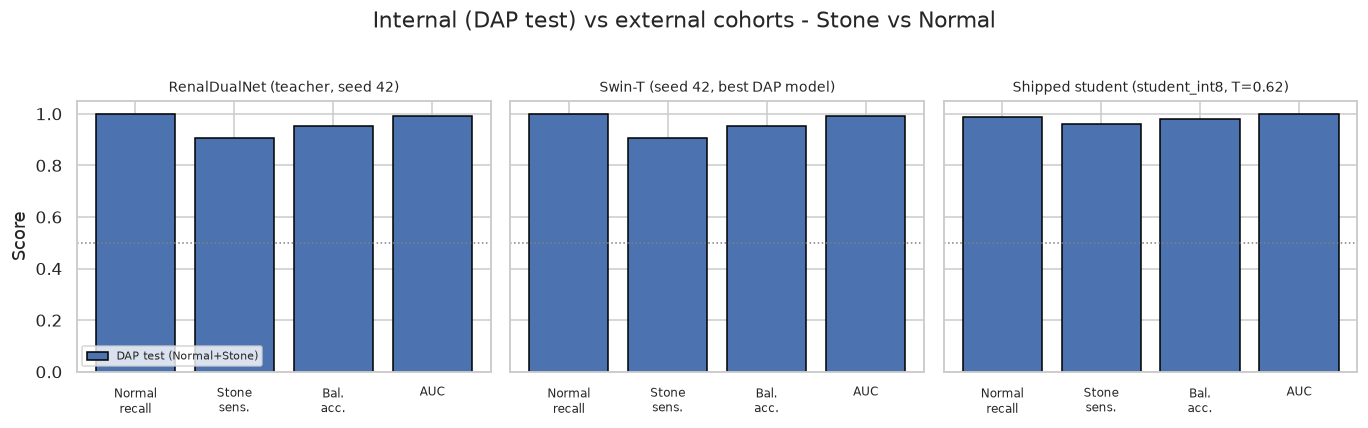


No external cohort was found - external validation NOT run. It stays a limitation.


In [51]:
# Phase 18.5 - v12.6: external validation
#
# First run outside the notebook (Rank 1 scripts), on the shipped student only. Here it runs
# in the notebook, on three models: the teacher (RenalDualNet seed 42), the best DAP model
# (Swin-T seed 42) and the shipped student (INT8 ONNX with its Phase 18.1 temperature and
# abstention threshold, set up in Phase 18.4).
#
# Both public cohorts contain only Stone and "no stone" images, so the four-class models are
# scored on the Stone-vs-Normal sub-task:
#   Stone sensitivity   P(pred = Stone  | Stone)
#   Specificity         P(pred != Stone | Normal)
#   Normal recall       P(pred = Normal | Normal)   <- the protocol-shortcut probe
#   Balanced accuracy   mean of sensitivity and specificity
#   AUC                 of p(Stone), Stone vs Normal
# The SAME sub-task is scored on the DAP test split (Normal + Stone images only), so the
# internal -> external drop is like for like. CIs resample groups (patients where filenames
# carry an ID, DAP hash groups otherwise).
#
# External images that are byte-identical to, or a DAP near-duplicate of, any image of the
# main dataset are EXCLUDED - they would not be external.
#
# Datasets are not downloaded by this cell. Put them under KIDNEY_EXT_ROOT (default
# ~/datasets):
#   Kidney_stone_detection/   git clone https://github.com/yildirimozal/Kidney_stone_detection
#   axial_stone/Kindey Stone Dataset/Original/{Stone,Non-Stone}/   record the source below

from sklearn.metrics import roc_auc_score

EXT_ROOT = Path(os.environ.get("KIDNEY_EXT_ROOT", Path.home()/"datasets"))
EXTERNAL_COHORTS = {
    "yildirim": {
        "desc": "Yildirim et al. 2021, coronal CT (github.com/yildirimozal/Kidney_stone_detection)",
        "root": EXT_ROOT/"Kidney_stone_detection"/"Dataset",
        "folders": {"Train/Kidney_stone": "Stone", "Train/Normal": "Normal",
                    "Test/Kidney_stone": "Stone",  "Test/Normal": "Normal"},
        "patient_regex": None,                 # no patient ID in the filenames -> DAP groups
        "phase": "non-contrast (as described for this cohort) - confirm on the sample sheet"},
    "axial": {
        "desc": "'Kindey Stone Dataset', Original/ only (Augmented/ excluded) - RECORD ITS SOURCE",
        "root": EXT_ROOT/"axial_stone"/"Kindey Stone Dataset"/"Original",
        "folders": {"Stone": "Stone", "Non-Stone": "Normal"},   # Non-Stone scored as Normal
        "patient_regex": r"^(P\d+)_",          # P001_FA_M_NS_I01.jpg -> patient P001
        "phase": "appears non-contrast on the sample sheet - confirm"},
}
SWIN_CKPT = OUT/"checkpoints"/"baseline_swin_tiny_patch4_window7_224.pt"
STONE, NORMAL = CLASS_TO_IDX["Stone"], CLASS_TO_IDX["Normal"]

def _ext_manifest(cfg):
    rows = []
    for sub, cls in cfg["folders"].items():
        d = cfg["root"]/sub
        for p in sorted(d.iterdir()) if d.exists() else []:
            if p.suffix.lower() in VALID_EXT:
                rows.append({"path": str(p), "filename": p.name, "class_name": cls,
                             "label": CLASS_TO_IDX[cls], "ext_split": sub.split("/")[0] if "/" in sub else "all"})
    return pd.DataFrame(rows)

def _hash_all(paths):
    try:
        with ProcessPoolExecutor(max_workers=CFG.HASH_WORKERS) as ex:
            return list(tqdm(ex.map(hash_one, paths, chunksize=64), total=len(paths), desc="Hashing", leave=False))
    except Exception as e:
        print(f"  parallel hashing failed ({type(e).__name__}), serial fallback")
        return [hash_one(p) for p in tqdm(paths, desc="Hashing (serial)", leave=False)]

def _near_dup_in_main(DHe, PHe, chunk=512):
    """Index of one main-dataset image within the DAP thresholds of each external image, or -1."""
    hit = np.full(len(DHe), -1, dtype=np.int64)
    for s in range(0, len(DHe), chunk):
        m = ((hamming_matrix(DHe[s:s+chunk], DH) <= FINAL_DTHR) &
             (hamming_matrix(PHe[s:s+chunk], PH) <= FINAL_PTHR))
        r = m.any(1); hit[s:s+chunk][r] = m[r].argmax(1)
    return hit

def _binary(y, prob, pred):
    st, nm = y==STONE, y==NORMAL
    sens = float((pred[st]==STONE).mean()) if st.any() else float("nan")
    spec = float((pred[nm]!=STONE).mean()) if nm.any() else float("nan")
    auc_ = float(roc_auc_score(st[st|nm], prob[st|nm, STONE])) if st.any() and nm.any() else float("nan")
    return {"n": int((st|nm).sum()), "stone_sensitivity": sens, "specificity": spec,
            "normal_recall": float((pred[nm]==NORMAL).mean()) if nm.any() else float("nan"),
            "balanced_accuracy": (sens+spec)/2, "auc_p_stone": auc_,
            "exact_class_accuracy": float((pred[st|nm]==y[st|nm]).mean())}

def _binary_ci(y, prob, pred, groups, keys=("balanced_accuracy","auc_p_stone","normal_recall"),
               n_boot=None, seed=CFG.PRIMARY_SEED):
    n_boot = n_boot or CFG.BOOTSTRAP_N; rng = np.random.RandomState(seed)
    ug = np.unique(groups); idx_by = {g: np.where(groups==g)[0] for g in ug}; samp = {k: [] for k in keys}
    for _ in range(n_boot):
        ix = np.concatenate([idx_by[g] for g in rng.choice(ug, len(ug), replace=True)])
        if not ((y[ix]==STONE).any() and (y[ix]==NORMAL).any()): continue
        b = _binary(y[ix], prob[ix], pred[ix])
        for k in keys:
            if np.isfinite(b[k]): samp[k].append(b[k])
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) if v else (np.nan, np.nan)
            for k, v in samp.items()}

def _sample_sheet(df, path, n_per=6, seed=CFG.PRIMARY_SEED):
    pick = pd.concat([g.sample(min(n_per, len(g)), random_state=seed) for _, g in df.groupby("class_name")])
    fig, axes = plt.subplots(pick.class_name.nunique(), n_per, figsize=(2.2*n_per, 2.4*pick.class_name.nunique()))
    for a, (_, r) in zip(np.atleast_2d(axes).ravel(), pick.iterrows()):
        a.imshow(Image.open(r.path).convert("L"), cmap="gray"); a.axis("off")
        a.set_title(f"{r.class_name}", fontsize=8)
    plt.tight_layout(); plt.savefig(path); plt.close()

# ------------------------------------------------------------------ the models
def _torch_logits(m, df):
    dl = DataLoader(KidneyCTDataset(df, eval_tf), batch_size=CFG.BATCH_SIZE*2, shuffle=False,
                    num_workers=CFG.NUM_WORKERS)
    _dev = next(m.parameters()).device                # put it back where later phases expect it
    m = m.to(DEVICE); lg, _, _ = predict(m, dl); m.to(_dev)
    if DEVICE.type=="cuda": torch.cuda.empty_cache()
    return lg

EXT_MODELS = {"RenalDualNet (teacher, seed 42)": {"logits": lambda df: _torch_logits(model, df),
                                                   "test_logits": test_logits}}
if SWIN_CKPT.exists():
    swin_ext = build_model("swin_tiny_patch4_window7_224.ms_in1k", pretrained=False)
    swin_ext.load_state_dict(torch.load(SWIN_CKPT, map_location="cpu")["state_dict"]); swin_ext.eval()
    EXT_MODELS["Swin-T (seed 42, best DAP model)"] = {"logits": lambda df: _torch_logits(swin_ext, df),
                                                      "test_logits": _torch_logits(swin_ext, test_df)}
else:
    print(f"  {SWIN_CKPT.name} not found - Swin-T skipped")
if globals().get("STUDENT_TEST_LOGITS") is not None:
    EXT_MODELS[STUDENT_NAME] = {"logits": student_logits, "test_logits": STUDENT_TEST_LOGITS,
                                "T": STUDENT_T, "threshold": STUDENT_THR}
else:
    print("  shipped student not set up (run Phase 18.4 first) - student skipped")

def _probs(name, lg): return softmax_np(lg, EXT_MODELS[name].get("T", 1.0))

# ------------------------------------------------------------------ internal reference
_ns = np.isin(test_y, [STONE, NORMAL])
ext_rows = []
for name, spec in EXT_MODELS.items():
    pr = _probs(name, spec["test_logits"])[_ns]; y_ = test_y[_ns]; pd_ = pr.argmax(1)
    b = _binary(y_, pr, pd_); ci_ = _binary_ci(y_, pr, pd_, test_g[_ns])
    ext_rows.append({"cohort": "DAP test (Normal+Stone)", "model": name, "n_groups": int(len(np.unique(test_g[_ns]))),
                     **b, **{f"{k}_ci": f"[{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in ci_.items()}})

# ------------------------------------------------------------------ external cohorts
EXTERNAL = {"models": list(EXT_MODELS), "cohorts": {},
            "student": {"model_file": STUDENT_ONNX.name, "temperature": STUDENT_T,
                        "abstention_threshold": STUDENT_THR}
                       if globals().get("STUDENT_NAME") in EXT_MODELS else None}
for cname, cfg in EXTERNAL_COHORTS.items():
    print(f"\n{'='*74}\nEXTERNAL COHORT: {cname}  -  {cfg['desc']}\n{'='*74}")
    edf = _ext_manifest(cfg)
    if edf.empty:
        print(f"  not found under {cfg['root']} - skipped (set KIDNEY_EXT_ROOT)")
        EXTERNAL["cohorts"][cname] = {"status": "not_found", "root": str(cfg["root"])}; continue
    hs = _hash_all(edf.path.tolist())
    DHe = np.stack([h[0] for h in hs]).astype(np.uint8); PHe = np.stack([h[1] for h in hs]).astype(np.uint8)
    edf["md5"] = [h[2] for h in hs]

    # --- is it really external? ---
    _md5_main = dict(zip(manifest.md5, manifest.split))
    edf["main_md5_split"] = edf.md5.map(_md5_main)
    _nd = _near_dup_in_main(DHe, PHe)
    edf["main_neardup_split"] = np.where(_nd>=0, manifest.split.values[np.maximum(_nd, 0)], None)
    _overlap = edf.main_md5_split.notna() | edf.main_neardup_split.notna()
    print(f"  images {len(edf):,}  {edf.class_name.value_counts().to_dict()}")
    print(f"  overlap with main dataset: byte-identical {int(edf.main_md5_split.notna().sum())}, "
          f"DAP near-duplicate {int(edf.main_neardup_split.notna().sum())}  -> excluded {int(_overlap.sum())}")
    if _overlap.any():
        edf.assign(main_neardup_file=np.where(_nd>=0, manifest.filename.values[np.maximum(_nd, 0)], None))[
            _overlap].to_csv(OUT/"tables"/f"external_{cname}_excluded.csv", index=False)
        print(f"  -> listed in tables/external_{cname}_excluded.csv. Inspect them: a hash match at the")
        print("     threshold edge can be a false positive. Excluding is the conservative choice either way.")
    edf = edf[~_overlap].reset_index(drop=True); DHe, PHe = DHe[~_overlap.values], PHe[~_overlap.values]

    # --- groups for the CI ---
    if cfg["patient_regex"]:
        _pid = edf.filename.str.extract(cfg["patient_regex"])[0]
        assert _pid.notna().all(), f"patient_regex did not match every filename in {cname}"
        edf["group_id"] = pd.factorize(_pid)[0]; _gkind = "patient ID"
    else:
        edf["group_id"] = group_from_edges(len(edf), build_edges(DHe, PHe, FINAL_DTHR, FINAL_PTHR, quiet=True))
        _gkind = "DAP hash group"
    print(f"  groups: {edf.group_id.nunique()} ({_gkind})  |  phase: {cfg['phase']}")
    _sample_sheet(edf, OUT/"figures"/f"external_{cname}_samples.png")

    # --- predict ---
    preds = []
    for name, spec in EXT_MODELS.items():
        lg = spec["logits"](edf)
        pr = _probs(name, lg); pdx = pr.argmax(1); y_ = edf.label.values
        b = _binary(y_, pr, pdx); ci_ = _binary_ci(y_, pr, pdx, edf.group_id.values)
        row = {"cohort": cname, "model": name, "n_groups": int(edf.group_id.nunique()), **b,
               **{f"{k}_ci": f"[{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in ci_.items()},
               **{f"pred_{c}": float((pdx==i).mean()) for i, c in enumerate(CFG.CLASSES)}}
        _ans = np.full(len(pr), np.nan)                   # no referral rule for teacher / Swin-T
        if "threshold" in spec:
            _ans = pr.max(1) >= spec["threshold"]; _err = pdx!=y_
            row.update({"abstain_coverage": float(_ans.mean()),
                        "abstain_accuracy_answered": float((pdx[_ans]==y_[_ans]).mean()) if _ans.any() else float("nan"),
                        "abstain_errors_referred": float((~_ans[_err]).mean()) if _err.any() else float("nan")})
        ext_rows.append(row)
        preds.append(edf[["path","filename","class_name","ext_split","md5","group_id"]].assign(
            model=name, pred=np.array(CFG.CLASSES)[pdx], conf=pr.max(1), answered=_ans,
            **{f"p_{c}": pr[:, i] for i, c in enumerate(CFG.CLASSES)}))
        print(f"  {name:44s} Normal recall {b['normal_recall']:.3f} | Stone sens {b['stone_sensitivity']:.3f} "
              f"| bal-acc {b['balanced_accuracy']:.3f} | AUC {b['auc_p_stone']:.3f}")
        if "threshold" in spec:
            print(f"  {'':44s} abstention: answers {row['abstain_coverage']:.1%} at accuracy "
                  f"{row['abstain_accuracy_answered']:.3f}; refers {row['abstain_errors_referred']:.1%} of its errors")
    pd.concat(preds).to_csv(OUT/"tables"/f"external_{cname}_predictions.csv", index=False)
    EXTERNAL["cohorts"][cname] = {"status": "evaluated", "desc": cfg["desc"], "phase": cfg["phase"],
        "root": str(cfg["root"]), "n_images": int(len(edf)), "class_counts": {k: int(v) for k, v in edf.class_name.value_counts().items()},
        "n_groups": int(edf.group_id.nunique()), "group_kind": _gkind, "excluded_overlap": int(_overlap.sum())}

ext_sum = pd.DataFrame(ext_rows)
print(f"\n{'='*74}\nINTERNAL (DAP test, Normal+Stone) vs EXTERNAL\n{'='*74}")
display(ext_sum[["cohort","model","n","n_groups","normal_recall","stone_sensitivity","specificity",
                 "balanced_accuracy","balanced_accuracy_ci","auc_p_stone","auc_p_stone_ci"]].round(3))
ext_sum.to_csv(OUT/"tables"/"external_validation_summary.csv", index=False)
EXTERNAL["summary"] = ext_sum.round(6).to_dict(orient="records")

# --- figure ---
_mets = ["normal_recall","stone_sensitivity","balanced_accuracy","auc_p_stone"]
_mods = list(EXT_MODELS); _coh = list(ext_sum.cohort.unique())
fig, axes = plt.subplots(1, len(_mods), figsize=(4.2*len(_mods), 3.8), sharey=True)
for ax, mname in zip(np.atleast_1d(axes), _mods):
    sub = ext_sum[ext_sum.model==mname].set_index("cohort").reindex(_coh)
    x = np.arange(len(_mets)); w = 0.8/len(_coh)
    for i, c in enumerate(_coh):
        ax.bar(x+i*w-0.4+w/2, sub.loc[c, _mets].astype(float), w, label=c, edgecolor="black")
    ax.set_xticks(x); ax.set_xticklabels(["Normal\nrecall","Stone\nsens.","Bal.\nacc.","AUC"], fontsize=8)
    ax.axhline(0.5, ls=":", c="gray", lw=1); ax.set_ylim(0, 1.05); ax.set_title(mname, fontsize=9)
np.atleast_1d(axes)[0].legend(fontsize=7, loc="lower left"); np.atleast_1d(axes)[0].set_ylabel("Score")
plt.suptitle("Internal (DAP test) vs external cohorts - Stone vs Normal", y=1.02)
plt.tight_layout(); plt.savefig(OUT/"figures"/"fig16_external_validation.png"); plt.show()

# --- verdict ---
_ext = ext_sum[ext_sum.cohort!="DAP test (Normal+Stone)"]
_fail = _ext[_ext.normal_recall<0.5]
if len(_fail):
    EXTERNAL_VERDICT = "fails_external"
    print("\n" + "!"*74)
    print("EXTERNAL VALIDATION FAILS on Normal kidneys:")
    for _, r in _fail.iterrows():
        print(f"  {r.cohort:9s} {r.model:44s} Normal recall {r.normal_recall:.3f} "
              f"(called Stone {r.pred_Stone:.1%} of all images)")
    print("Both cohorts are non-contrast. Together with Phase 3.3 (Normal is ~all contrast-")
    print("enhanced in training), this is what a protocol shortcut predicts. It is also")
    print("confounded with site and scanner shift - say 'consistent with', not 'proves'.")
    print("Report this in Results, not only in Limitations.")
    print("!"*74)
elif len(_ext):
    EXTERNAL_VERDICT = "passes_external"
    print("\nNormal recall >= 0.5 on every evaluated cohort and model.")
else:
    EXTERNAL_VERDICT = "not_run"
    print("\nNo external cohort was found - external validation NOT run. It stays a limitation.")
EXTERNAL["verdict"] = EXTERNAL_VERDICT

In [52]:
# Phase 19 — Paper artifacts

# --- guard: rehydrate anything clobbered by earlier loop variables ---
if not isinstance(pc, pd.DataFrame):
    pc = pd.read_csv(OUT/"tables"/"per_class_metrics.csv")
for _n,_o in [("pc",pc),("comp",comp)]:
    assert isinstance(_o,pd.DataFrame), f"{_n} is {type(_o).__name__}, expected DataFrame"
if CFG.RUN_ABLATION:
    assert isinstance(abl_df,pd.DataFrame), f"abl_df is {type(abl_df).__name__}"

def to_latex(df,cap,lab,fmt="%.4f"):
    return df.to_latex(index=True,escape=False,float_format=fmt,caption=cap,label=lab,position="htbp")

parts=[]
if CFG.RUN_LEAKAGE_EXPERIMENT and leak_results:
    parts.append(to_latex(leak_tbl,"Effect of the data splitting protocol. Identical architecture, "
        "hyperparameters and seed; only the partitioning differs.","tab:leakage"))
    if len(leak_results)>1:
        parts.append(to_latex(rep,"Replication of the inflation across architectures.","tab:replication"))
parts.append(to_latex(comp.drop(columns=["ci_f1_low","ci_f1_high"]),
    "Comparison under an identical training protocol on the duplicate-aware split. "
    "Intervals are 95\\% group-level bootstrap CIs.","tab:baselines"))
if CFG.RUN_ABLATION: parts.append(to_latex(abl_df,"Ablation of the fusion strategy.","tab:ablation"))
parts.append(to_latex(pc.set_index("class"),"Per-class test performance.","tab:perclass"))
if weight_sweep is not None:
    parts.append(to_latex(weight_sweep.set_index("power"),
        "Class-weight exponent sweep and its effect on Stone precision.","tab:weights"))
if qtab is not None:
    parts.append(to_latex(qtab.drop(columns=["path"]).set_index("model"),
        "Deployment characteristics on CPU.","tab:deploy"))
tex="\n\n".join(parts); (OUT/"tables"/"all_tables.tex").write_text(tex)
print(tex[:1500]); print(f"\n... full file: {OUT/'tables'/'all_tables.tex'}")

final={
 "dataset":{"source":DATA_SOURCE,"provenance_vs_kaggle":globals().get("PROVENANCE"),"n_images":int(N),"classes":list(CFG.CLASSES),
            "class_counts":{k:int(v) for k,v in manifest.class_name.value_counts().items()},
            "imbalance_ratio":float(imbalance_ratio)},
 "dap":{"dhash_threshold":FINAL_DTHR,"phash_threshold":FINAL_PTHR,
        "near_duplicate_pairs":int(len(edges)),"n_groups":n_groups,
        "singleton_groups":n_singletons,"images_in_multi_groups":int(N-n_singletons),
        "largest_group_frac":float(gsizes.iloc[0]/N),
        "byte_identical_duplicates":int(md5_dupes),
        "cross_class_groups":int(n_impure),
        "cross_class_images_frac":float(len(aff)/N)},
 "leakage_gate":leak,
 "split_sizes":{s:int((manifest.split==s).sum()) for s in ["train","val","test"]},
 "test_groups":int(len(np.unique(test_g))),
 "primary_model":"RenalDualNet (concat fusion)",
 "primary_results":main_metrics,
 "bootstrap_ci":ci,
 "calibration":{"selected":CALIBRATOR_NAME,
                "selection_criterion":"cross-fitted adaptive ECE inside the validation FIT half "
                                      "(fit on half the groups, scored on the other half); "
                                      "threshold and q_hat on the disjoint CAL half, q_hat at scan level",
                "temperature_deployed":T_DEPLOY,"diagnostics":{k:v for k,v in cal_diag.items() if k!="problems"},
                "problems":cal_diag["problems"],
                "comparison":cal_cmp.round(6).to_dict(orient="index")},
 "selective_prediction":{"rule":"confidence threshold at target coverage (validation)",
                "threshold":float(SEL_THRESHOLD),"target_coverage":CFG.TARGET_COVERAGE,
                "operating_points":sel.round(6).to_dict(orient="records"),
                "conformal_sweep":conf_sweep.round(6).to_dict(orient="records")},
 "baselines":{k:{kk:float(vv) for kk,vv in v.items()} for k,v in results.items()},
 "ablation":{k:{kk:float(vv) for kk,vv in v.items()} for k,v in ablation.items()},
 "multiseed":(summary["reported"].to_dict() if len(summary) else {}),
 "HEADLINE_quote_these_not_seed42":HEADLINE,
 "seed42_role":"detail seed for Phases 8-14 and 16-18; NOT the reported result",
 "integrity":{"md5_label_conflicts":int(n_md5_conflict),
              "distinct_image_sizes":int(manifest.groupby(["width","height"]).ngroups)},
 "explainability":{"background_attention_mean":float(BG_MASS_MEAN),
                   "background_attention_p90":float(BG_MASS_P90),
                   "background_area_mean":float(BG_AREA_MEAN),
                   "background_mass_to_area_ratio_mean":float(BG_RATIO_MEAN),
                   "background_mass_to_area_ratio_median":float(BG_RATIO_MEDIAN),
                   "reading":"ratio 1.0 = flat heatmap; <1 = attention on the body"},
 "determinism_note":DETERMINISM_NOTE,
 "environment":{"torch":torch.__version__,"timm":timm.__version__,"device":str(DEVICE),
                "seeds":list(CFG.SEEDS)},
 "config":{k:str(v) for k,v in asdict(CFG).items()},
}
if CFG.RUN_LEAKAGE_EXPERIMENT and leak_results:
    final["leakage_experiment"]={"contamination_rate":float(contam_rate),
        "design":"random vs DAP split with DIFFERENT test sets: the as-practised gap, not the contamination "
                 "effect (see multiseed_inflation, paired design)",
        "per_architecture":{a:{kk:{k:float(x) for k,x in vv.items()} for kk,vv in v.items()}
                            for a,v in leak_results.items()},
        "mean_macro_f1_inflation":float(np.mean([leak_results[a]["inflation"]["f1_macro"] for a in leak_results]))}
if weight_sweep is not None:
    final["class_weight_sweep"]={"candidates_scored_on":"validation",
        "selection_basis":WEIGHT_SELECTION_BASIS,   # "validation" or "default_retained" (gain < 0.01)
        "selected_power":BEST_POWER,
        "candidates":weight_sweep.round(6).to_dict(orient="records"),
        "test_of_selected":{k:float(v) for k,v in ws_test.items()} if ws_test else {}}
if thresh_sweep is not None:
    final["threshold_sensitivity"]={
        "grid":[list(t) for t in CFG.THRESHOLD_GRID],
        "rows":thresh_sweep.round(6).to_dict(orient="records"),
        "inflation_min":float(thresh_sweep.inflation_f1.min()),
        "inflation_max":float(thresh_sweep.inflation_f1.max()),
        "conservative_estimate":float(thresh_sweep.inflation_f1.min()),   # v12.4: min, not most-groups
        "design":"paired: clean vs contaminated model, identical test images",
        "note":"single seed; compare the spread with multiseed_inflation.std"}
if multiseed_leak is not None:
    final["multiseed_inflation"]={"design":"paired: clean vs contaminated model, identical test images",
        "leak_frac":CFG.LEAK_FRAC,"rows":multiseed_leak.round(6).to_dict(orient="index"),
        "mean":INFLATION_MEAN,"std":INFLATION_STD,
        "reported":f"{INFLATION_MEAN:+.4f} +/- {INFLATION_STD:.4f}"}
if qtab is not None:
    final["deployment"]={"student":CFG.STUDENT_BACKBONE,"student_params_M":n_student/1e6,
        "student_macro_f1":student_metrics.get("f1_macro"),
        "table":qtab.drop(columns=["path"]).round(6).to_dict(orient="records"),
        "shipped":DEPLOY_MODEL.name if DEPLOY_MODEL else None,"int8_passed_gate":bool(DEPLOY_IS_INT8)}
json.dump(final,open(OUT/"RESULTS.json","w"),indent=2,default=str)
# v11: pin the environment. Reviewers and CBM's reproducibility policy ask for this.
try:
    import subprocess
    _fz=subprocess.run([sys.executable,"-m","pip","freeze"],capture_output=True,text=True).stdout
    (OUT/"requirements_frozen.txt").write_text(_fz)
    print(f"Environment pinned -> {OUT/'requirements_frozen.txt'} ({len(_fz.splitlines())} pkgs)")
except Exception as _e:
    print(f"Could not pin environment: {_e}")

print(f"\nRESULTS.json -> {OUT/'RESULTS.json'}")

\begin{table}[htbp]
\caption{Effect of the data splitting protocol. Identical architecture, hyperparameters and seed; only the partitioning differs.}
\label{tab:leakage}
\begin{tabular}{lrrr}
\toprule
 & Random split (standard practice) & DAP split (ours) & Inflation \\
\midrule
Accuracy & 0.9995 & 0.9711 & 0.0284 \\
Precision (macro) & 0.9988 & 0.9685 & 0.0303 \\
Recall (macro) & 0.9996 & 0.9565 & 0.0431 \\
Macro-F1 & 0.9992 & 0.9622 & 0.0369 \\
MCC & 0.9992 & 0.9585 & 0.0408 \\
\bottomrule
\end{tabular}
\end{table}


\begin{table}[htbp]
\caption{Replication of the inflation across architectures.}
\label{tab:replication}
\begin{tabular}{lrrr}
\toprule
 & random_f1 & dap_f1 & inflation_f1 \\
\midrule
RenalDualNet & 0.9992 & 0.9622 & 0.0369 \\
swin_tiny_patch4_window7_224 & 0.9986 & 0.9700 & 0.0286 \\
\bottomrule
\end{tabular}
\end{table}


\begin{table}[htbp]
\caption{Comparison under an identical training protocol on the duplicate-aware split. Intervals are 95\% group-level bootstrap 

---
## Phase 20 — Self-validation suite

Nineteen checks. Every one corresponds to something a reviewer can test or something that
went wrong in a previous version. Run this before writing anything.

In [53]:
# Phase 20 — validation suite

tests=[]
def check(name,cond,detail=""):
    tests.append({"test":name,"pass":bool(cond),"detail":detail}); return bool(cond)

# --- data integrity ---
check("T01 canonical image count (12,446)", N==12446, f"found {N:,}")
check("T02 all four classes present", set(manifest.class_name)==set(CFG.CLASSES))
check("T03 no missing files", manifest.path.map(lambda p: Path(p).exists()).all())
check("T04 no duplicate img_id", manifest.img_id.is_unique)

# --- DAP integrity ---
check("T05 grouping did not collapse", gsizes.iloc[0]/N<=0.5, f"largest {gsizes.iloc[0]/N:.2%}")
check("T06 CFG thresholds match those used", (CFG.DHASH_THRESH,CFG.PHASH_THRESH)==(FINAL_DTHR,FINAL_PTHR),
      f"CFG=({CFG.DHASH_THRESH},{CFG.PHASH_THRESH}) used=({FINAL_DTHR},{FINAL_PTHR})")
check("T07 every image has a group", manifest.group_id.notna().all())
check("T08 near-duplicate pairs found", len(edges)>0, f"{len(edges):,} pairs")

# --- split integrity ---
check("T09 all leakage gates zero", all(v==0 for v in leak.values()), str(leak))
_pr=pd.crosstab(manifest.split,manifest.class_name,normalize="index")
check("T10 stratification within 5 points", float((_pr-_pr.mean(0)).abs().max().max())<0.05,
      f"max deviation {float((_pr-_pr.mean(0)).abs().max().max()):.4f}")
check("T11 train share is 60-80%", 0.60<=(manifest.split=="train").mean()<=0.80)
check("T12 val and test non-empty", (manifest.split=="val").sum()>0 and (manifest.split=="test").sum()>0)
# v12.7: the v12.0-v12.6 splitter sent the large scans to train (test groups were 0.40x train's)
_gm35=manifest.groupby(["split","group_id"]).size().groupby("split").mean()
check("T35 test groups are not systematically smaller than train groups",
      0.6<=_gm35["test"]/_gm35["train"]<=1/0.6,
      f"mean images/group train {_gm35['train']:.1f} val {_gm35['val']:.1f} test {_gm35['test']:.1f} "
      f"({CFG.SPLIT_METHOD})")

# --- results plausibility ---
check("T13 macro-F1 below 0.995", main_metrics["f1_macro"]<0.995,
      f"{main_metrics['f1_macro']:.4f} (saturation implies leakage, not skill)")
check("T14 beats majority-class baseline", main_metrics["accuracy"]>counts.max()/counts.sum(),
      f"{main_metrics['accuracy']:.4f} vs {counts.max()/counts.sum():.4f}")
check("T15 point estimate inside its own CI",
      ci["f1_macro"]["ci_low"]<=main_metrics["f1_macro"]<=ci["f1_macro"]["ci_high"])

# --- methodology ---
# v12.7: the selection criterion is cross-fitted (held out inside the fit half). The independent
# CAL-half ECE is reported next to it, so a selected calibrator that does worse there is visible.
check("T16 calibrator chosen by held-out ECE", "val_fit_crossfit_ECE_mass" in cal_cmp.columns and
      CALIBRATOR_NAME==cal_cmp["val_fit_crossfit_ECE_mass"].idxmin() and
      cal_cmp.loc[CALIBRATOR_NAME,"val_cal_ECE_mass"]<=cal_cmp["val_cal_ECE_mass"].min()+0.02,
      f"{CALIBRATOR_NAME}; CAL-half ECE {cal_cmp.loc[CALIBRATOR_NAME,'val_cal_ECE_mass']:.4f} "
      f"vs best {cal_cmp['val_cal_ECE_mass'].min():.4f}")
# v12.7: scan-level q_hat over-covers by design with ~17 calibration scans; only UNDER-coverage fails.
check("T17 conformal coverage not below target",
      conf_sweep.loc[conf_sweep.alpha==CFG.CONFORMAL_ALPHA,"empirical_cov"].iloc[0]
      >=(1-CFG.CONFORMAL_ALPHA)-0.05,
      f"coverage {conf_sweep.loc[conf_sweep.alpha==CFG.CONFORMAL_ALPHA,'empirical_cov'].iloc[0]:.4f} "
      f"vs target {1-CFG.CONFORMAL_ALPHA:.2f}")
check("T18 more than one seed", len(CFG.SEEDS)>1, f"seeds {CFG.SEEDS}")
check("T19 QUICK_RUN was off", not CFG.QUICK_RUN)

# --- v11 additions: the checks that would have caught v10's real problems ---
check("T20 weight sweep selected on VALIDATION",
      (weight_sweep is None) or ("val_macro_f1" in weight_sweep.columns),
      "test-set selection is a false methods statement")
check("T21 headline is mean +/- std, not one seed", bool(HEADLINE),
      HEADLINE.get("f1_macro",{}).get("reported","MISSING"))
check("T22 threshold sensitivity was run", thresh_sweep is not None,
      "" if thresh_sweep is None else f"{len(thresh_sweep)} thresholds")
# v12.4: a single-seed spread is only meaningful against the seed noise of the inflation.
# PASS means "the sweep found no threshold effect larger than seed noise", NOT "flat".
_t23_ok=(thresh_sweep is not None) and (multiseed_leak is not None) and \
        float(thresh_sweep.inflation_f1.max()-thresh_sweep.inflation_f1.min())<INFLATION_STD
check("T23 threshold spread below seed noise", _t23_ok,
      "needs 13.4 and 13.5" if (thresh_sweep is None or multiseed_leak is None) else
      f"spread {float(thresh_sweep.inflation_f1.max()-thresh_sweep.inflation_f1.min()):.4f} "
      f"vs seed std {INFLATION_STD:.4f} (inconclusive, not 'flat')")
# v12.7: the inflation must be measured on identical test images (paired), not on two different test sets
check("T36 inflation measured on identical test images",
      multiseed_leak is not None and "n_eval_images" in multiseed_leak.columns
      and (thresh_sweep is None or "n_eval_images" in thresh_sweep.columns),
      "" if multiseed_leak is None else
      f"{int(multiseed_leak.n_eval_images.min())}-{int(multiseed_leak.n_eval_images.max())} eval images/seed; "
      f"CI excludes 0 in {int((multiseed_leak.inflation_f1_ci_low>0).sum())}/{len(multiseed_leak)} seeds")
check("T24 inflation has error bars", multiseed_leak is not None,
      "" if multiseed_leak is None else f"{INFLATION_MEAN:+.4f} +/- {INFLATION_STD:.4f}")
check("T25 specificity computed", "specificity_macro" in main_metrics,
      f"{main_metrics.get('specificity_macro',float('nan')):.4f}")
check("T26 train accuracy logged", "train_accuracy" in hist.columns)
# v12.4: the never-empty fix makes avg_set_size >= 1 by construction; test the raw sets
_t27=conf_sweep.loc[conf_sweep.regime=="valid","empty_before_fix"]
check("T27 no empty sets at reported alphas (before fix)", int(_t27.sum())==0,
      f"empty sets in valid rows: {int(_t27.sum())}")
check("T28 grouping did not over-merge", n_groups>=500 or n_singletons>=20,
      f"{n_groups:,} groups, {n_singletons:,} singletons - if FAIL, Phase 13.4 carries the defence")
check("T29 CGAF is in the leaderboard",
      (not CFG.RUN_ABLATION) or ("RenalCGAFNet" in comp.index))
# v12.4: the old version ended in `or DEPLOY_MODEL is not None` and could never fail.
# Shipped INT8 must be the most accurate config that passed the accuracy gate.
if qtab is not None and DEPLOY_IS_INT8:
    _q8=qtab[qtab.model.str.startswith("INT8")]
    _pass=_q8[(qtab.iloc[0]["accuracy"]-_q8["accuracy"])<=CFG.MAX_INT8_ACC_DROP]
    _ship=_q8[_q8["path"].map(lambda p: Path(p).read_bytes()==Path(DEPLOY_MODEL).read_bytes())]
    _t30=len(_ship)>0 and float(_ship["accuracy"].max())>=float(_pass["accuracy"].max())-1e-9
    _t30d=(f"shipped {_ship.iloc[0]['model']} acc {_ship['accuracy'].max():.4f}, "
           f"best passing {_pass['accuracy'].max():.4f}") if len(_ship) else "shipped file not found in qtab"
else:
    _t30,_t30d=True,"no INT8 shipped"
check("T30 shipped INT8 is the most accurate passing config", _t30, _t30d)

# --- v12.6: protocol confound and external validation ---
_CON, _EXT = globals().get("CONTRAST", {}), globals().get("EXTERNAL", {})
_KAP = globals().get("PHASE_KAPPA")
check("T31 contrast phase labelled for every scan", globals().get("CONTRAST_STATUS")=="labelled",
      f"{globals().get('CONTRAST_STATUS','not run')}; verdict {_CON.get('verdict','-')}")
check("T32 second contrast rater, kappa >= 0.6", _KAP is not None and _KAP>=0.6,
      "single rater - add a second before submission" if _KAP is None else f"kappa {_KAP:.3f}")
check("T33 external validation ran", _EXT.get("verdict","not_run")!="not_run",
      ", ".join(f"{k}: {v.get('status')}" for k,v in _EXT.get("cohorts",{}).items()) or "not run")
check("T34 external/main overlap checked, flagged images excluded",
      bool(_EXT.get("cohorts")) and all("excluded_overlap" in v for v in _EXT["cohorts"].values()
                                        if v.get("status")=="evaluated"),
      "; ".join(f"{k}: {v.get('excluded_overlap','-')} excluded" for k,v in _EXT.get("cohorts",{}).items()))

tdf=pd.DataFrame(tests)
print("="*76); print("SELF-VALIDATION"); print("="*76)
for _,r in tdf.iterrows():
    print(f"  [{'PASS' if r['pass'] else 'FAIL'}] {r['test']:44s} {r['detail']}")
print("="*76)
npass=int(tdf["pass"].sum())
print(f"{npass}/{len(tdf)} passed")
tdf.to_csv(OUT/"tables"/"self_validation.csv",index=False)

print(f"\n{'='*76}\nRUN SUMMARY\n{'='*76}")
print(f"Images / groups            : {N:,} / {n_groups:,}")
print(f"Images with near-duplicate : {(N-n_singletons)/N:.1%}")
print(f"Byte-identical duplicates  : {md5_dupes:,}")
print(f"Test groups                : {len(np.unique(test_g)):,}")
print("-"*76)
print(f"Test accuracy              : {main_metrics['accuracy']:.4f}")
print(f"Test macro-F1              : {main_metrics['f1_macro']:.4f} "
      f"[{ci['f1_macro']['ci_low']:.4f}, {ci['f1_macro']['ci_high']:.4f}]")
if len(summary): print(f"Multi-seed macro-F1        : {summary.loc['f1_macro','reported']}")
print("-"*76)
if CFG.RUN_LEAKAGE_EXPERIMENT and leak_results:
    print(f"Contamination (random)     : {contam_rate:.2%}")
    for a in leak_results:
        print(f"  {a:34s} inflation {leak_results[a]['inflation']['f1_macro']:+.4f}")
print("="*76)

if len(summary): print(f"Multi-seed macro-F1 (HEADLINE) : {summary.loc['f1_macro','reported']}")
if thresh_sweep is not None:
    print(f"Inflation across thresholds    : {thresh_sweep.inflation_f1.min():+.4f} to "
          f"{thresh_sweep.inflation_f1.max():+.4f}")
if multiseed_leak is not None:
    print(f"Inflation across seeds         : {INFLATION_MEAN:+.4f} +/- {INFLATION_STD:.4f}")
if _CON.get("verdict"):
    print(f"Contrast-phase confound (3.3)  : {_CON['verdict']} - phase-only accuracy "
          f"{_CON['phase_only_accuracy_group_cv']:.3f} vs majority {_CON['phase_only_majority_baseline']:.3f}, "
          f"Cramer's V {_CON['cramers_v']:.2f}")
if _EXT.get("verdict"):
    print(f"External validation (18.5)     : {_EXT['verdict']}")
print("="*76)

_hard=[t for t in tests if not t["pass"] and t["test"].split()[0] in
       ("T20","T21","T22","T24","T25","T26")]
if _hard:
    print("\n" + "!"*76)
    print("DO NOT START WRITING. These failures affect what you can truthfully claim:")
    for t in _hard: print(f"  - {t['test']}  {t['detail']}")
    print("!"*76)
elif npass<len(tdf):
    print("\nSome checks failed but none block writing. Read each one and decide whether")
    print("it belongs in Limitations. T23, T28 and T32 in particular are findings, not bugs -")
    print("if the inflation is threshold-dependent, report the range instead of a point.")
else:
    print("\nAll checks passed. RESULTS.json holds the numbers to write up.")
    print("Quote HEADLINE (mean +/- std). Never quote seed 42 as the result.")

SELF-VALIDATION
  [PASS] T01 canonical image count (12,446)           found 12,446
  [PASS] T02 all four classes present                 
  [PASS] T03 no missing files                         
  [PASS] T04 no duplicate img_id                      
  [PASS] T05 grouping did not collapse                largest 2.98%
  [PASS] T06 CFG thresholds match those used          CFG=(4,7) used=(4,7)
  [PASS] T07 every image has a group                  
  [PASS] T08 near-duplicate pairs found               131,120 pairs
  [PASS] T09 all leakage gates zero                   {'train_val_overlap': 0, 'train_test_overlap': 0, 'val_test_overlap': 0, 'cross_split_duplicate_pairs': 0, 'md5_across_splits': 0}
  [PASS] T10 stratification within 5 points           max deviation 0.0058
  [PASS] T11 train share is 60-80%                    
  [PASS] T12 val and test non-empty                   
  [PASS] T35 test groups are not systematically smaller than train groups mean images/group train 69.1 val 51.9 test

---
## Phase 21 — Multi-seed baselines (FIX 3)

v11 trained every baseline and RenalCGAFNet at seed 42 only, while RenalDualNet had three
seeds — and seed 42 is RenalDualNet's best seed. That is an unfair comparison. This phase
retrains each competitor for the remaining seeds so the leaderboard is mean ± std over the
same three seeds for everyone.


In [54]:
# Phase 21 — every competitor at CFG.SEEDS, matched to RenalDualNet
# *** v12.2: per-(model, seed) crash insurance ***
# The v12.1 run completed all twelve baseline x seed trainings, printed every one, then
# lost the lot when RenalCGAFNet seed 1337 killed the CUDA context - because ms_rows
# lived only in memory. Every individual run is now flushed to disk the moment it ends.
MS_MODELS = list(CFG.BASELINES) + ['RenalCGAFNet']
P21_CACHE = ResultCache(CACHE_DIR/"multiseed_leaderboard_runs.json", run_context())
P21_CACHE.report("21")

ms_rows = []
for name in MS_MODELS:
    short = name if name.startswith('Renal') else name.split('.')[0]
    per_seed = {}
    # reuse the seed-42 run already in `results`
    if short in results:
        per_seed[42] = {'f1_macro': results[short]['f1_macro'],
                        'accuracy': results[short]['accuracy']}
    for sd in CFG.SEEDS:
        if sd in per_seed:
            continue
        _key = f"{short}|seed{sd}"
        if _key in P21_CACHE:
            per_seed[sd] = P21_CACHE.get(_key)
            print(f'  {short:32s} seed {sd}: macro-F1 '
                  f'{per_seed[sd]["f1_macro"]:.4f}  (cached)')
            continue
        md_ = manifest.copy()
        md_['split'] = group_stratified_split(md_, CFG.SPLIT_RATIO, sd)
        lk = assert_no_leakage(md_, edges)
        assert all(v == 0 for v in lk.values()), f'leak @ {short} seed {sd}: {lk}'
        tr = md_[md_.split == 'train'].reset_index(drop=True)
        ld = make_loaders(tr, md_[md_.split == 'val'].reset_index(drop=True),
                          md_[md_.split == 'test'].reset_index(drop=True))
        w, _ = compute_class_weights(tr, CFG.CLASS_WEIGHT_POWER)
        set_seed(sd); m = build_model(name)
        m, _, _ = train_model(m, ld[0], ld[1], f'ms_{short}_s{sd}',
                              class_weights=w, seed=sd, verbose=False, save=False)
        lg, y, g = predict(m, ld[2])
        met = compute_metrics(y, lg.argmax(1), softmax_np(lg))
        per_seed[sd] = P21_CACHE.put(_key, {'f1_macro': met['f1_macro'],
                                             'accuracy': met['accuracy']})
        print(f'  {short:32s} seed {sd}: macro-F1 {met["f1_macro"]:.4f}')
        del m; gc.collect(); torch.cuda.empty_cache()
    # *** v12 FIX 6 ***
    # numpy .std() is ddof=0; Phase 15 builds RenalDualNet's std with pandas .agg(["std"]),
    # which is ddof=1. At n=3 that is a factor of 1.22, so mixing them would make the
    # dual-branch model look more variable than every baseline for no reason.
    f1 = np.array([per_seed[s]['f1_macro'] for s in sorted(per_seed)])
    ac = np.array([per_seed[s]['accuracy'] for s in sorted(per_seed)])
    _f1s = float(f1.std(ddof=1)) if len(f1) > 1 else 0.0
    _acs = float(ac.std(ddof=1)) if len(ac) > 1 else 0.0
    ms_rows.append({'model': short, 'n_seeds': len(per_seed),
                    'f1_mean': float(f1.mean()), 'f1_std': _f1s,
                    'acc_mean': float(ac.mean()), 'acc_std': _acs,
                    'f1_reported': f'{f1.mean():.4f} +/- {_f1s:.4f}'})

# add RenalDualNet's existing 3-seed headline for a complete table
if 'HEADLINE' in dir() and HEADLINE:
    ms_rows.append({'model': 'RenalDualNet', 'n_seeds': len(CFG.SEEDS),
                    'f1_mean': HEADLINE['f1_macro']['mean'],
                    'f1_std': HEADLINE['f1_macro']['std'],
                    'acc_mean': HEADLINE['accuracy']['mean'],
                    'acc_std': HEADLINE['accuracy']['std'],
                    'f1_reported': HEADLINE['f1_macro']['reported']})

ms_baselines = (pd.DataFrame(ms_rows)
                  .sort_values('f1_mean', ascending=False).reset_index(drop=True))
print(f"\n{len(P21_CACHE)} individual runs on disk at "
      f"{(CACHE_DIR/'multiseed_leaderboard_runs.json').name} - a crash from here on")
print("costs one run, not the phase.")
display(ms_baselines.round(4))
ms_baselines.to_csv(OUT/'tables'/'table2b_multiseed_leaderboard.csv', index=False)

_top = ms_baselines.iloc[0]
_dn  = ms_baselines[ms_baselines.model == 'RenalDualNet']
print(f"\nBest by 3-seed mean macro-F1: {_top['model']} ({_top['f1_reported']})")
if len(_dn):
    print(f"RenalDualNet: {_dn.iloc[0]['f1_reported']}  "
          f"(rank {int(_dn.index[0])+1}/{len(ms_baselines)})")
print('State the ranking honestly. If the dual-branch model is not first, say so.')
print('All standard deviations in this table are ddof=1, matching Phase 15 (v12 fix).')

# Do the top two even separate once both have error bars?
if len(ms_baselines) > 1:
    _a, _b = ms_baselines.iloc[0], ms_baselines.iloc[1]
    _sep = (_a['f1_mean'] - _a['f1_std']) > (_b['f1_mean'] + _b['f1_std'])
    print(f"\nTop two: {_a['model']} {_a['f1_reported']} vs {_b['model']} {_b['f1_reported']}")
    print("  +/- 1 SD intervals separate." if _sep else
          "  +/- 1 SD intervals OVERLAP - do not claim one is better. Phase 22 tests it.")


  [21] no cache yet - starting from scratch
  resnet50                         seed 1337: macro-F1 0.8161
  resnet50                         seed 2024: macro-F1 0.8024
  efficientnet_b0                  seed 1337: macro-F1 0.7599
  efficientnet_b0                  seed 2024: macro-F1 0.8019
  densenet201                      seed 1337: macro-F1 0.8611
  densenet201                      seed 2024: macro-F1 0.9024
  vit_small_patch16_224            seed 1337: macro-F1 0.8938
  vit_small_patch16_224            seed 2024: macro-F1 0.8177
  swin_tiny_patch4_window7_224     seed 1337: macro-F1 0.9161
  swin_tiny_patch4_window7_224     seed 2024: macro-F1 0.8795
  convnext_tiny                    seed 1337: macro-F1 0.8754
  convnext_tiny                    seed 2024: macro-F1 0.8424
  RenalCGAFNet                     seed 1337: macro-F1 0.8653
  RenalCGAFNet                     seed 2024: macro-F1 0.8213

14 individual runs on disk at multiseed_leaderboard_runs.json - a crash from here on
co

,model,n_seeds,f1_mean,f1_std,acc_mean,acc_std,f1_reported
0,RenalDualNet,3,0.9331,0.0277,0.9440,0.0249,0.9331 +/- 0.0277
1,swin_tiny_patch4_window7_224,3,0.9219,0.0455,0.9388,0.0341,0.9219 +/- 0.0455
2,densenet201,3,0.8891,0.0243,0.9083,0.0230,0.8891 +/- 0.0243
3,convnext_tiny,3,0.8712,0.0269,0.8910,0.0251,0.8712 +/- 0.0269
4,RenalCGAFNet,3,0.8706,0.0522,0.8914,0.0450,0.8706 +/- 0.0522
5,vit_small_patch16_224,3,0.8610,0.0391,0.8928,0.0395,0.8610 +/- 0.0391
6,efficientnet_b0,3,0.8251,0.0793,0.8568,0.0659,0.8251 +/- 0.0793
7,resnet50,3,0.8082,0.0071,0.8409,0.0138,0.8082 +/- 0.0071



Best by 3-seed mean macro-F1: RenalDualNet (0.9331 +/- 0.0277)
RenalDualNet: 0.9331 +/- 0.0277  (rank 1/8)
State the ranking honestly. If the dual-branch model is not first, say so.
All standard deviations in this table are ddof=1, matching Phase 15 (v12 fix).

Top two: RenalDualNet 0.9331 +/- 0.0277 vs swin_tiny_patch4_window7_224 0.9219 +/- 0.0455
  +/- 1 SD intervals OVERLAP - do not claim one is better. Phase 22 tests it.


---
## Phase 22 — Statistical significance of every leaderboard gap (FIX 4)

v11 only had bootstrap CIs and an informal overlap check. This adds a **paired approximate
permutation test** on group-level accuracy: for each model vs the leaderboard top, the
statistic is the mean per-group accuracy difference, and the null is 10,000 random sign
flips of the per-group differences. Same test groups for both models, so the pairing is exact.


In [55]:
# Phase 22 — paired permutation test on group-level accuracy
# v12.7: the statistic is the mean per-group ACCURACY gap (each scan counts once); the f1_gap
# column is the image-level macro-F1 gap the leaderboard ranks by, for context. They can disagree.
seed42_valf1 = {}     # v12.7: validation macro-F1 per model, used to pick the reference model

def _reinfer(arch_name, ckpt_path, name=None):
    set_seed(CFG.PRIMARY_SEED); m = build_model(arch_name)
    state = torch.load(ckpt_path, map_location=DEVICE)
    m.load_state_dict(state['state_dict'] if 'state_dict' in state else state)
    m.to(DEVICE).eval()
    lg, y, g = predict(m, test_loader)
    vl, vy, _ = predict(m, val_loader)
    if name is not None: seed42_valf1[name] = compute_metrics(vy, vl.argmax(1))['f1_macro']
    del m; torch.cuda.empty_cache()
    return lg.argmax(1), y, g

_ck = {'RenalDualNet': OUT/'checkpoints'/'RenalDualNet_s42.pt',
       'RenalCGAFNet': OUT/'checkpoints'/'ablation_CGAF.pt'}
_arch = {'RenalDualNet': 'RenalDualNet', 'RenalCGAFNet': 'RenalCGAFNet'}
for b in CFG.BASELINES:
    s = b.split('.')[0]
    _ck[s] = OUT/'checkpoints'/f'baseline_{s}.pt'; _arch[s] = b

seed42_pred = {}
for name, ck in _ck.items():
    if Path(ck).exists():
        seed42_pred[name] = _reinfer(_arch[name], ck, name)
        print(f'  re-inferred {name}')
    else:
        print(f'  MISSING checkpoint: {ck}')

def paired_perm_test(pred_a, pred_b, y, groups, n=10000, seed=CFG.PRIMARY_SEED):
    rng = np.random.RandomState(seed)
    ca = pd.Series((pred_a == y).astype(float)).groupby(groups).mean().sort_index()
    cb = pd.Series((pred_b == y).astype(float)).groupby(groups).mean().sort_index()
    d = (ca - cb).values
    obs = float(d.mean())
    flips = rng.rand(n, len(d)) < 0.5
    null = np.where(flips, -d, d).mean(axis=1)
    # v12.7: (1 + #as-extreme) / (n + 1). A Monte-Carlo p-value is never exactly 0; the old
    # (#as-extreme / n) printed 0.0000, which Holm then carried through as "significant at 0".
    p = float(((np.abs(null) >= abs(obs) - 1e-12).sum() + 1) / (n + 1))
    return obs, p

# *** v12.7 FIX: the reference model is chosen on VALIDATION ***
# v12.0-v12.6 took the model with the best TEST macro-F1 as the reference and then tested it
# against the others on that same test set: a winner's-curse selection that makes every gap
# look larger than an a-priori comparison would. The reference is now the best validation
# macro-F1; the test-leader is printed so a disagreement is visible, not hidden.
_f1 = {n: compute_metrics(v[1], v[0])['f1_macro'] for n, v in seed42_pred.items()}    # test, for the gap column
TOP = max(seed42_valf1, key=seed42_valf1.get)
_TOP_TEST = max(_f1, key=_f1.get)
print(f"Reference model (best validation macro-F1): {TOP}  (val {seed42_valf1[TOP]:.4f}, test {_f1[TOP]:.4f})")
if _TOP_TEST != TOP:
    print(f"  Note: the test-set leader is {_TOP_TEST} (test {_f1[_TOP_TEST]:.4f}). Not used as the reference.")
pa, ya, ga = seed42_pred[TOP]
sig_rows = []
for name, (pb, yb, gb) in seed42_pred.items():
    if name == TOP:
        continue
    obs, pv = paired_perm_test(pa, pb, ya, ga)
    sig_rows.append({'top_model': TOP, 'vs': name,
                     'acc_gap (top - vs)': obs, 'f1_gap (top - vs)': _f1[TOP] - _f1[name], 'p_value': pv,
                     'significant@0.05': pv < 0.05})
sig_df = pd.DataFrame(sig_rows).sort_values('p_value').reset_index(drop=True)

# *** v12 FIX 7: Holm-Bonferroni ***
# One top model is compared against every other, so this is a family of tests. Reporting
# only raw p-values inflates the false-positive rate, and a statistics-literate reviewer
# will say so. Holm is uniformly more powerful than Bonferroni and needs no assumptions.
_m = len(sig_df)
_adj, _running = [], 0.0
for _k, _p in enumerate(sig_df['p_value'].values):
    _running = max(_running, min(1.0, (_m - _k) * _p))   # enforce monotonicity
    _adj.append(_running)
sig_df['p_holm'] = _adj
sig_df['significant@0.05'] = sig_df['p_holm'] < 0.05
sig_df['n_comparisons'] = _m
display(sig_df.round(4))
sig_df.to_csv(OUT/'tables'/'table9_significance.csv', index=False)

_nsig = int((~sig_df['significant@0.05']).sum())
_nraw = int((sig_df['p_value'] >= 0.05).sum())
print(f"\nNot significant at raw p<0.05  : {_nraw}/{_m}")
print(f"Not significant after Holm      : {_nsig}/{_m}")
if _nsig > _nraw:
    print("Holm removed some apparent wins. Report the CORRECTED column; quoting raw")
    print("p-values across seven comparisons would overstate your evidence.")
print(f"\nPower note: the test unit is the group, and there are only "
      f"{len(np.unique(ga))} test groups.")
print("Non-significance here means 'this design cannot tell these models apart', not")
print("'the models are equal'. Say it that way - it is the honest reading and it")
print("supports the benchmark-integrity framing rather than undermining it.")
# v12.4 caveat: this uses seed-42 checkpoints only. Seed 42 is RenalDualNet's BEST seed,
# so the RenalDualNet row here is the most favourable comparison it can get. The 3-seed
# leaderboard (Phase 21, table2b) is the fairer ranking; cite both.
print("\nCAVEAT: seed-42 checkpoints only. Seed 42 is RenalDualNet's best seed, so its row")
print("is the most favourable case. Cite the 3-seed means (table2b) next to these p-values.")
print(f'\n{_nsig}/{len(sig_df)} gaps vs {TOP} are NOT significant after Holm (p_holm >= 0.05).')
_sig_names=sig_df.loc[sig_df['significant@0.05'],'vs'].tolist()
print('Write in Results: after Holm correction, ' + TOP + ' is significantly better than '
      + (', '.join(_sig_names) if _sig_names else 'none of the other models')
      + '; the remaining gaps are not distinguishable at this test-set group count.')


  re-inferred RenalDualNet
  re-inferred RenalCGAFNet
  re-inferred resnet50
  re-inferred efficientnet_b0
  re-inferred densenet201
  re-inferred vit_small_patch16_224
  re-inferred swin_tiny_patch4_window7_224
  re-inferred convnext_tiny
Reference model (best validation macro-F1): densenet201  (val 0.9222, test 0.9038)
  Note: the test-set leader is swin_tiny_patch4_window7_224 (test 0.9700). Not used as the reference.


,top_model,vs,acc_gap (top - vs),f1_gap (top - vs),p_value,significant@0.05,p_holm,n_comparisons
0,densenet201,RenalDualNet,-0.0597,-0.0584,0.0138,False,0.0966,7
1,densenet201,swin_tiny_patch4_window7_224,-0.0539,-0.0662,0.0200,False,0.1200,7
2,densenet201,vit_small_patch16_224,0.0597,0.0323,0.0821,False,0.4105,7
3,densenet201,convnext_tiny,-0.0369,0.0080,0.3607,False,1.0000,7
4,densenet201,resnet50,0.0277,0.0976,0.3671,False,1.0000,7
5,densenet201,efficientnet_b0,-0.0249,-0.0096,0.4536,False,1.0000,7
6,densenet201,RenalCGAFNet,-0.0171,-0.0214,0.5578,False,1.0000,7



Not significant at raw p<0.05  : 5/7
Not significant after Holm      : 7/7
Holm removed some apparent wins. Report the CORRECTED column; quoting raw
p-values across seven comparisons would overstate your evidence.

Power note: the test unit is the group, and there are only 31 test groups.
Non-significance here means 'this design cannot tell these models apart', not
'the models are equal'. Say it that way - it is the honest reading and it
supports the benchmark-integrity framing rather than undermining it.

CAVEAT: seed-42 checkpoints only. Seed 42 is RenalDualNet's best seed, so its row
is the most favourable case. Cite the 3-seed means (table2b) next to these p-values.

7/7 gaps vs densenet201 are NOT significant after Holm (p_holm >= 0.05).
Write in Results: after Holm correction, densenet201 is significantly better than none of the other models; the remaining gaps are not distinguishable at this test-set group count.


---
## Phase 23 — Cross-class group verdict (FIX 5)

Phase 2.5 rendered `fig5_cross_class_groups.png` and asked for a human verdict on the 9
label-mixed groups (17.9 % of images). Look at that figure, fill `VERDICTS` below with one
of `same_patient` / `over_merged` / `unsure` per group, then re-run this cell. It writes the
recorded verdict and the fraction of images affected by over-merging.


In [56]:
# Phase 23 — record your visual verdict on each cross-class group
# allowed values: 'same_patient' (one patient, several findings — grouping correct)
#                 'over_merged'  (unrelated scans fused — grouping too loose)
#                 'unsure'
cc = pd.read_csv(OUT/'tables'/'cross_class_groups.csv')
print('Groups to judge (see figures/fig5_cross_class_groups.png):')
for _, r in cc.iterrows():
    print(f"  group {int(r.group_id):3d}  size {int(r['size']):3d}  {r['composition']}")

# v12.5 verdicts, recorded from per-group contact sheets (figures/cross_class/group_<id>.png:
# six evenly spaced slices per class, in filename order). Every group fuses visibly
# different scans - different contrast phase, body habitus and field of view. In the six
# coronal groups each class part also has its own export size, and Phase 2.3b showed a
# coronal scan is exported at one size, so size alone already separates the scans.
VERDICTS = {
    66:  'over_merged',  # Normal:74, Stone:61, Cyst:12 - three scans; Cyst non-contrast 868x702,
                         #   Normal contrast 785x634, Stone itself spans 4 export sizes
    177: 'over_merged',  # Normal:150, Tumor:131 - 804x651 vs 882x714; different habitus/phase
    82:  'over_merged',  # Normal:81, Cyst:70 - Cyst non-contrast 1152x932 vs Normal contrast 791x640
    109: 'over_merged',  # Cyst:74, Normal:54 - 680x550 non-contrast vs 796x644 contrast
    189: 'over_merged',  # Tumor:202, Normal:128 - both 512x512 axial, but Tumor shows a large
                         #   left renal mass absent from the Normal series; different body outline
    30:  'over_merged',  # Cyst:248, Tumor:123 - both 512x512 axial; Cyst non-contrast, Tumor
                         #   contrast with a renal mass; different patients
    33:  'over_merged',  # Stone:173, Cyst:67 - both 512x512 axial; different habitus and phase
    190: 'over_merged',  # Tumor:177, Normal:54 - 768x622 (huge mass) vs 869x702 normal kidneys
    85:  'over_merged',  # Normal:336, Stone:18 - Normal alone spans 3 export sizes (3 scans),
                         #   Stone a fourth at 855x691
}
cc['verdict'] = cc.group_id.map(VERDICTS).fillna('unsure')

# v12.7: where do these groups sit under the CURRENT split? Phase 24 used to say "all in train", which
# was a property of the old largest-first splitter, and no cell ever computed it.
_where = (manifest[manifest.group_id.isin(cc.group_id)].groupby(["group_id","split"]).size()
          .unstack(fill_value=0).reindex(columns=["train","val","test"], fill_value=0))
cc = cc.merge(_where.add_prefix("n_"), left_on="group_id", right_index=True, how="left")
display(cc)
print(f"\nImages of the {len(cc)} cross-class groups by split ({CFG.SPLIT_METHOD}): "
      f"train {int(cc.n_train.sum())} | val {int(cc.n_val.sum())} | test {int(cc.n_test.sum())}")
if int(cc.n_test.sum()) or int(cc.n_val.sum()):
    print("Some of these groups are in val/test: a fused (over-merged) group there is not leakage, but it")
    print("makes that split heterogeneous. Say so in Methods and report the numbers above.")
cc.to_csv(OUT/'tables'/'cross_class_groups_verdict.csv', index=False)

# *** v12 FIX 8 ***
# Every verdict ships as 'unsure'. In v11 the cell then fell through to the else branch
# and printed "the grouping is clean at the patient level" - a conclusion nobody had
# reached. That sentence could have gone into the manuscript unearned. Now the cell
# refuses to conclude anything until real verdicts are recorded.

_n_unsure = int((cc.verdict == 'unsure').sum())
_over = cc[cc.verdict == 'over_merged']
_same = cc[cc.verdict == 'same_patient']
_frac = _over['size'].sum() / N

print(f"\nVerdicts recorded : same_patient {len(_same)}, over_merged {len(_over)}, "
      f"unsure {_n_unsure}  (of {len(cc)})")

if _n_unsure == len(cc):
    print("\n" + "!"*74)
    print("NO VERDICT RECORDED. Every group is still 'unsure', which is the shipped")
    print("default - not a finding.")
    print("")
    print("Open  figures/fig5_cross_class_groups.png  and judge each group by eye:")
    print("  same anatomy, same slice geometry, consecutive-looking slices -> same_patient")
    print("  visibly different scans fused together                        -> over_merged")
    print("")
    print("Do NOT write anything about cross-class groups until this is filled in.")
    print("These 9 groups cover 17.9% of the dataset; a reviewer will ask what they are.")
    print("!"*74)
    CROSS_CLASS_VERDICT = "not_recorded"
elif _n_unsure:
    print(f"\nPARTIAL: {_n_unsure} group(s) still unjudged. Finish them before writing.")
    print("A partial verdict cannot support a claim either way.")
    CROSS_CLASS_VERDICT = "partial"
elif len(_over):
    print(f"\nOver-merged: {len(_over)}/{len(cc)} groups, {_frac:.1%} of all images.")
    print("Report this. Over-merging depresses the DAP score, so DAP macro-F1 is a")
    print("LOWER bound and the leakage inflation is an UPPER bound. Cite Phase 13.4 as")
    print("the evidence that the inflation survives stricter linkage anyway.")
    CROSS_CLASS_VERDICT = "over_merged"
else:
    print("\nAll cross-class groups judged same-patient. You may now write that the")
    print("grouping is correct at the patient level and that a patient may legitimately")
    print("contribute slices with different findings.")
    CROSS_CLASS_VERDICT = "same_patient"

print(f"\nCROSS_CLASS_VERDICT = {CROSS_CLASS_VERDICT!r}")


Groups to judge (see figures/fig5_cross_class_groups.png):
  group  66  size 147  Normal:74, Stone:61, Cyst:12
  group 177  size 281  Normal:150, Tumor:131
  group  82  size 151  Normal:81, Cyst:70
  group 109  size 128  Cyst:74, Normal:54
  group 189  size 330  Tumor:202, Normal:128
  group  30  size 371  Cyst:248, Tumor:123
  group  33  size 240  Stone:173, Cyst:67
  group 190  size 231  Tumor:177, Normal:54
  group  85  size 354  Normal:336, Stone:18


,group_id,size,purity,composition,verdict,n_train,n_val,n_test
0,66,147,0.503401,"Normal:74, Stone:61, Cyst:12",over_merged,0,0,147
1,177,281,0.533808,"Normal:150, Tumor:131",over_merged,281,0,0
2,82,151,0.536424,"Normal:81, Cyst:70",over_merged,0,0,151
3,109,128,0.578125,"Cyst:74, Normal:54",over_merged,128,0,0
4,189,330,0.612121,"Tumor:202, Normal:128",over_merged,330,0,0
5,30,371,0.668464,"Cyst:248, Tumor:123",over_merged,371,0,0
6,33,240,0.720833,"Stone:173, Cyst:67",over_merged,240,0,0
7,190,231,0.766234,"Tumor:177, Normal:54",over_merged,231,0,0
8,85,354,0.949153,"Normal:336, Stone:18",over_merged,354,0,0



Images of the 9 cross-class groups by split (balanced_random): train 1935 | val 0 | test 298
Some of these groups are in val/test: a fused (over-merged) group there is not leakage, but it
makes that split heterogeneous. Say so in Methods and report the numbers above.

Verdicts recorded : same_patient 0, over_merged 9, unsure 0  (of 9)

Over-merged: 9/9 groups, 17.9% of all images.
Report this. Over-merging depresses the DAP score, so DAP macro-F1 is a
LOWER bound and the leakage inflation is an UPPER bound. Cite Phase 13.4 as
the evidence that the inflation survives stricter linkage anyway.

CROSS_CLASS_VERDICT = 'over_merged'


---
## Phase 24 — The framing decision

This is not code. It is the choice that determines whether this work is accepted or desk-rejected,
so it lives in the notebook next to the numbers.

**v12.7 status.** The splitter (Phase 3.1) and the inflation design (Phases 13.3b–13.5) changed, so
every number that depends on a trained model or on the DAP split is **superseded**. The table below
therefore has two kinds of rows:

- **Established** - does not depend on a trained model or on which split was drawn (hashing, grouping,
  the contrast-phase labels). Safe to quote now.
- **Pending re-run** - the value in *italics* is what the v12.6 run produced under the old, size-biased
  splitter and the old unpaired inflation. It is kept only so you can see how far a number moves. Do not
  quote it. The last column names the `RESULTS.json` key the re-run fills.

Edit the **Supported?** column once the re-run has produced the numbers; rewrite the bullets and the
abstract sentence below from `RESULTS.json`, not from this cell.

### What the evidence supports

| Claim | Supported? | Evidence / where to read it |
|---|---|---|
| A random split on this benchmark is contaminated | **Yes (Established)** | 99.79% of random-split test images (1,863 / 1,867) have a hash-linked near-duplicate in train. The detector is the same dHash/pHash linkage that defines the groups, so this is not an independent check; an embedding or SSIM nearest-neighbour audit would be |
| Contamination inflates performance, measured on **identical test images** | **Pending re-run** | Phase 13.5: a clean and a contaminated model scored on the same evaluation images, `LEAK_FRAC` of each test scan moved into train, group-bootstrap CI per seed → `multiseed_inflation` (`mean`, `std`, `rows[*].inflation_f1_ci_*`). *v12.6 had +0.145 ± 0.046, but that was random-split minus DAP-split on two different test sets* |
| The as-practised gap (random-split score minus DAP score) | **Pending re-run** | Phase 13.2 → `leakage_experiment`. Report it as what a reader sees when comparing papers, **not** as the contamination effect. *v12.6: +0.093 (RenalDualNet) and +0.092 (Swin-T), seed 42* |
| Inflation is positive regardless of linkage threshold | **Pending re-run** | Phase 13.4, paired, one seed → `threshold_sensitivity.rows`; positive means the paired CI excludes 0. *v12.6: +0.093 to +0.112 against a fixed random-split model* |
| Its magnitude is independent of the threshold | **Not shown** | One seed cannot show it. Compare the 13.4 spread with the 13.5 seed std (the Phase 13.5 printout); at best "varied less across thresholds than across seeds". *v12.6: spread 0.019 vs seed std 0.046* |
| The DAP grouping is correct at the patient level | **No: it over-merges (Established)** | Phase 23: all 9 cross-class groups fuse different scans (17.9% of images, 2,233); 6 are separable by export size alone, 3 axial groups by eye (`figures/cross_class/`). Groups are scans, not patients |
| Where the over-merged groups sit | **Pending re-run** | Phase 23 now prints their train/val/test image counts under the current split → `cross_class_verdict.rows[*].n_train / n_val / n_test`. *"All in train" was a property of the old largest-first splitter* |
| The paired inflation is biased low by grouping errors, not high | **Established (argument)** | Over-merging makes a leaked image less likely to come from the same scan as its evaluation image; under-merging leaves sibling slices in the clean arm. Both shrink the measured gap. Quote the smallest value across thresholds (`threshold_sensitivity.conservative_estimate`) |
| RenalDualNet is a better architecture | **Pending re-run** | Phase 21 → `multiseed_leaderboard`. *v12.6: Swin-T 0.905 ± 0.003 vs RenalDualNet 0.854 ± 0.046, 3 seeds* |
| Attention fusion helps | **Pending re-run** | Phase 12 and Phase 21. *v12.6: −0.0475 vs concatenation at seed 42; 0.850 ± 0.054 over 3 seeds* |
| Architectures are indistinguishable | **Pending re-run** | Phase 22 → `architecture_significance`. Reference model is now chosen on validation macro-F1 and p-values are floored at 1/(n+1); about 31–33 test groups instead of 50, so power is lower. *v12.6: after Holm, Swin-T beat EfficientNet-B0, ResNet50 and ViT-S only* |
| The model attends to background (shortcut) | **Pending re-run** | Phase 16 → `explainability.background_mass_to_area_ratio_*`; a ratio near 1 or below is not a shortcut. *v12.6: raw mass 0.55, which had no baseline* |
| Class labels are independent of acquisition protocol | **No: class ≈ contrast phase (Established)** | Phases 3.2–3.3, labels and scans only, unaffected by the splitter: blinded visual labelling of all 209 scans (`tables/scan_contrast_labels.csv`, unsure excluded): Normal 49/50 scans contrast-enhanced, Tumor 20/21; Cyst 0/55, Stone 3/61; Cramér's V 0.94. A phase-only classifier reaches 0.707 on held-out scans (grouped CV; majority baseline 0.442) → `contrast_phase_audit`. **One rater**; κ pending (T32) |
| The model uses the contrast shortcut | **Pending re-run** | Phase 18.4 → `contrast_phase_audit.dap_test_by_phase`. The DAP test split still cannot separate a protocol detector from a disease detector if it has empty class × phase cells (`contrast_phase_audit.empty_test_cells`); the new splitter may change which cells are empty. *v12.6: on non-contrast test images the teacher predicted Normal 0.0% and Tumor 0.0%* |
| The models generalise to another site | **Pending re-run** | Phase 18.5 → `external_validation`: teacher, Swin-T and shipped student, two non-contrast Stone/Normal cohorts, Normal recall and balanced accuracy beside the like-for-like internal reference. All three models are retrained, so nothing carries over. *v12.6: Normal recall 0.000 (Yildirim) and 0.010–0.019 (axial); teacher balanced accuracy 0.924 internal vs 0.673 / 0.605 external* |
| The failure is caused by the contrast shortcut | **Consistent with it at best** | Site, scanner and view also change between cohorts, and no contrast-matched external cohort exists. Whatever 18.5 shows, write "consistent with", not "caused by" |
| The model is clinically deployable | **No (Established)** | Single source, protocol-confounded labels, no reader study. External validation result: pending re-run |

**Bias direction of the inflation (v12.7, replaces the v12.5 paragraph).** The v12.5 text said
over-merging makes the DAP score a lower bound and the inflation an *upper* bound. That held for
"random minus DAP", where the DAP score moves with the grouping. In the paired design the clean arm only
needs *its own* grouping to hold, and both grouping errors shrink the measured gap (see the table), so the
inflation is a **lower bound** and the smallest value across thresholds is the one to quote. State the
design in Methods: same architecture, seed, hyper-parameters, validation set, evaluation images and
training-set size and class mix; only the presence of other slices of the test scans differs. Also state
`LEAK_FRAC`: a random 70/15/15 split puts about 82% of a scan's other images in train, so the default
0.5 is the milder case.

**Protocol confound (v12.5, unchanged).** This is a second integrity flaw, independent of duplicate
leakage. DAP removes leakage between splits but cannot remove a confound shared by every split: the only
non-contrast Normal in the dataset is one scan, so no model trained here can learn what a normal
non-contrast kidney looks like. The internal DAP score therefore still overstates real performance, and
the external result shows by how much. Phase labels come from ONE rater on one mid slice per scan - have a
second rater (ideally a radiologist) label the sheets in `figures/contrast_audit/` and report Cohen's
kappa before submission.

### Therefore

Write a **benchmark-integrity paper** with TWO findings: near-duplicate leakage and a
diagnosis/acquisition-protocol confound. Title and abstract lead with the audit. The architecture appears
only as the vehicle for the controlled experiment.

**Say plainly, in Results and not only in Limitations** (fill the numbers from `RESULTS.json`; the
statements that depend on a result are conditional on it):

- Leakage: the paired inflation, mean ± std over seeds **and** the per-seed intervals, with `LEAK_FRAC`
  and the number of evaluation images and scans. Give the as-practised gap separately and label it as a
  comparison across different test sets.
- If the paired CI excludes 0 at every seed and threshold, say "positive at every seed and every linkage
  threshold tested"; if not, report the range and which seeds or thresholds did not separate from 0.
- RenalCGAFNet: report the Phase 12 / Phase 21 comparison with concatenation as it comes out. *v12.6 read
  it as a negative result, with the gate collapsing to a near-binary router (Cyst 0.95, Normal 0.03,
  Stone 0.16, Tumor 0.82); confirm both from the re-run before keeping the sentence.*
- Dual-branch concatenation versus a single Swin-Tiny: report the Phase 21 means ± std and the Phase 22
  result for whatever the re-run shows.
- The duplicate grouping over-merges: 9 label-mixed groups (17.9% of images) are distinct scans fused by
  the hash linkage (Established). Report where they sit in the split, from Phase 23.
- The labels are confounded with contrast phase (Phase 3.3, Established). Whether the models' predictions
  follow it (Phase 18.4) and what happens on the two external non-contrast cohorts (Phase 18.5) come from
  the re-run; report the external result in Results, not only in Limitations.
- Seed-to-seed variation: with the v12.7 splitter the seeds draw genuinely different test scans, so the
  spread across seeds now includes split-to-split variation as well as training noise. Report it, and
  compare it with the architecture gaps. *(v12.6's 0.906 / 0.836 / 0.820 came from nearly identical
  splits and understated it.)*

### Sentences to avoid

- "We propose a novel architecture" — you measured one, you did not validate a design.
- "State-of-the-art performance" — your point is that the state of the art is inflated.
- "Suitable for clinical deployment" — one dataset, no reader study, protocol-confounded labels.
- "The inflation is independent of the linkage threshold" — one seed cannot show that.
- "Leakage inflated F1 by X" quoting the random-minus-DAP gap — those splits have different test sets;
  quote the paired inflation.
- "Selected on validation" for anything not actually chosen on validation (the exponent in Phase 14 is
  "retained" when the gain is under 0.01).
- "Groups correspond to patients" — Phase 23 shows the linkage fuses distinct scans, and groups are scans.
- "The model generalises" / "robust" — unless Phase 18.5 shows it, and then only for the cohorts tested.
- "Leakage-free performance reflects real-world accuracy" — the protocol confound survives DAP.
- "Externally validated" without qualification — two non-contrast cohorts, two of four classes.
- "The model uses the contrast shortcut" as a proven fact — the external shift is also a site and scanner
  shift; say "consistent with".
- "Conformal prediction sets guarantee 90% coverage" — the guarantee is for a random image of a new scan,
  under scan exchangeability, with the few calibration scans in the validation half.

### The sentence to build the abstract around

> On a widely used kidney CT benchmark, 99.8% of test images under standard random splitting have a
> near-duplicate in the training set. Holding the test images fixed, training on other slices of the test
> scans raised macro-F1 by *X* ± *Y* (mean ± SD over three seeds; per-seed 95% group-bootstrap intervals
> *[a, b]*), [and the effect was positive at every linkage threshold tested]. The labels are further
> confounded with contrast phase (phase alone predicts class at 0.71 on held-out scans), and [result of
> Phase 18.5 on the two external non-contrast cohorts].

Fill *X*, *Y* and the interval range from `RESULTS.json` → `multiseed_inflation` (`reported`, `leak_frac`,
`rows`); cite `threshold_sensitivity.inflation_min` / `inflation_max` only if the bracketed clause is true;
write the last bracket from `external_validation`. Do not write the sentence before 13.4, 13.5 and 18.5
have run.


---
## Phase 25 — Fold the new results into RESULTS.json


In [57]:
# Phase 25 — append the supplement outputs to RESULTS.json
import json
_p = OUT/'RESULTS.json'
_R = json.load(open(_p))

try:
    _R['multiseed_leaderboard'] = ms_baselines.round(6).to_dict(orient='records')
except NameError:
    print('run Phase 21 first for multiseed_leaderboard')
try:
    _R['architecture_significance'] = {
        'test': 'paired approximate permutation on group-level accuracy, 10k perms',
        'top_model': TOP, 'top_model_selected_on': 'validation macro-F1 (seed 42)',
        'rows': sig_df.round(6).to_dict(orient='records'),
        'n_not_significant': int((~sig_df['significant@0.05']).sum())}
except NameError:
    print('run Phase 22 first for architecture_significance')
try:
    _R['cross_class_verdict'] = {
        'rows': cc.to_dict(orient='records'),
        'n_over_merged': int((cc.verdict == 'over_merged').sum()),
        'over_merged_image_frac': float(cc.loc[cc.verdict=='over_merged','size'].sum()/N)}
except NameError:
    print('run Phase 23 first for cross_class_verdict')

# v12 additions
try:
    # v12.3: tested with whole scans held out (Phase 2.3b). The v12 random-CV figure
    # (0.62) was scan memorisation and is stored only so the correction is traceable.
    _R['size_shortcut_audit'] = {
        'verdict': SIZE_VERDICT,
        'n_distinct_sizes': int(len(size_ct)),
        'size_only_accuracy_grouped_cv': float(SIZE_ACC_GROUPED),
        'size_only_accuracy_random_cv_INVALID': float(SIZE_ACC_RANDOM),
        'majority_baseline': float(manifest.class_name.value_counts().max()/N),
        'mutual_information_nats': float(SIZE_MI),
        'mi_scan_permutation_null_mean': float(SIZE_MI_NULL),
        'mi_scan_permutation_p': float(SIZE_MI_P),
        'mi_excess_share_of_label_entropy': float(SIZE_MI_FRAC),
        'view_only_accuracy_grouped_cv': float(VIEW_ACC_GROUPED),
        'scans_axial': int((manifest.drop_duplicates('group_id').view=='axial').sum()),
        'scans_coronal': int((manifest.drop_duplicates('group_id').view=='coronal').sum())}
except NameError:
    print('run Phase 2.3b first for size_shortcut_audit')
try:
    _R['conformal_valid_alphas'] = sorted(CONFORMAL_VALID.alpha.tolist())
    _R['conformal_degenerate_alphas'] = sorted(
        conf_sweep.loc[conf_sweep.regime != 'valid', 'alpha'].tolist())
except NameError:
    print('run Phase 10.1 first for conformal regime split')
try:
    _R['cross_class_verdict_status'] = CROSS_CLASS_VERDICT
except NameError:
    pass
try:
    _R['nondeterministic_models'] = list(NONDETERMINISTIC_MODELS)
except NameError:
    pass

# v12.6 additions
try:
    _R['contrast_phase_audit'] = dict(CONTRAST)
    if globals().get('PHASE_TEST') is not None:
        _R['contrast_phase_audit']['dap_test_by_phase'] = PHASE_TEST.round(6).to_dict(orient='records')
except NameError:
    print('run Phases 3.2-3.3 first for contrast_phase_audit')
try:
    _R['external_validation'] = EXTERNAL
except NameError:
    print('run Phase 18.5 first for external_validation')

_R['manuscript_framing'] = ('benchmark-integrity study with two findings: near-duplicate leakage '
                            'and a contrast-phase protocol confound (external validation fails); '
                            'RenalCGAFNet is a negative result; no architecture-superiority or '
                            'clinical claim')
json.dump(_R, open(_p, 'w'), indent=2, default=str)
print(f'updated {_p}')
_new = ("multiseed_leaderboard","architecture_significance","cross_class_verdict",
        "manuscript_framing","size_shortcut_audit","conformal_valid_alphas",
        "conformal_degenerate_alphas","cross_class_verdict_status","nondeterministic_models",
        "contrast_phase_audit","external_validation")
print('new keys:', [k for k in _R if k in _new])

# --- final gate: may you start writing? ---
_block = []
if _R.get('cross_class_verdict_status') in (None,'not_recorded','partial'):
    _block.append("Phase 23: cross-class group verdict not recorded")
if 'threshold_sensitivity' not in _R:
    _block.append("Phase 13.4: threshold sensitivity not run - the headline is undefended")
if 'multiseed_inflation' not in _R:
    _block.append("Phase 13.5: inflation has no error bars")
if 'HEADLINE_quote_these_not_seed42' not in _R:
    _block.append("Phase 15: no mean +/- std headline")
if _R.get('contrast_phase_audit', {}).get('status') != 'labelled':
    _block.append("Phase 3.2: contrast-phase labels missing or incomplete - the confound is unmeasured")

print("\n" + "="*74)
if _block:
    print("NOT READY TO WRITE. Outstanding:")
    for b in _block: print("  - " + b)
else:
    print("READY TO WRITE.")
    print("  Headline macro-F1 : RESULTS.json -> HEADLINE_quote_these_not_seed42.f1_macro")
    print("  Headline inflation: RESULTS.json -> multiseed_inflation.reported")
    print("  Conservative bound: RESULTS.json -> threshold_sensitivity.conservative_estimate")
    print("  Never quote seed 42 as the result.")
print("="*74)

# v12.6: not blocking for a draft, but required before submission
_before = []
if _R.get('contrast_phase_audit', {}).get('cohen_kappa') is None:
    _before.append("Phase 3.2: second contrast-phase rater + Cohen's kappa (single rater now)")
if _R.get('external_validation', {}).get('verdict') in (None, 'not_run'):
    _before.append("Phase 18.5: no external cohort evaluated")
if any('RECORD ITS SOURCE' in str(v.get('desc', '')) for v in
       _R.get('external_validation', {}).get('cohorts', {}).values()):
    _before.append("Phase 18.5: record the source/citation of the axial cohort")
if _before:
    print("BEFORE SUBMISSION:")
    for b in _before: print("  - " + b)

updated Obj1/RESULTS.json
new keys: ['multiseed_leaderboard', 'architecture_significance', 'cross_class_verdict', 'size_shortcut_audit', 'conformal_valid_alphas', 'conformal_degenerate_alphas', 'cross_class_verdict_status', 'nondeterministic_models', 'contrast_phase_audit', 'external_validation', 'manuscript_framing']

NOT READY TO WRITE. Outstanding:
  - Phase 3.2: contrast-phase labels missing or incomplete - the confound is unmeasured
BEFORE SUBMISSION:
  - Phase 3.2: second contrast-phase rater + Cohen's kappa (single rater now)
  - Phase 18.5: no external cohort evaluated
